# Modelos TVAR y VLSTAR ANUALES con impp_usa, Ferreres **sin cappeo** (1935–2023)

- Datos anuales 1935–2023 de Ferreres, en diferencias logarítmicas: la muestra efectiva es **1936–2023 (88 años)**.
- Variables endógenas (orden de la identificación): `impp_usa`, `E`, `ipc`, `PBIcf` (en la base trimestral la actividad es `pbird`; en la anual de Ferreres, `PBIcf`).
- Datos originales (`df_anual_ferr`), sin acotar extremos.
- Gráficos: carpeta `GRAFICOS_TVAR_VLSTAR_Anuales/`, con sufijo `_anual_ferr`. Modelos: carpeta `models/` (no se pisan con los trimestrales: el nombre del archivo depende de los datos y de la periodicidad).
- Horizonte: 4 años (h = 0 a 4), igual que las LP anuales.
- Rezagos: con 88 observaciones, **p = 1 (lo eligen todos los criterios) y p = 2 (el Portmanteau del VAR lineal rechaza con p = 1 a 8 rezagos); la principal se elige según el Portmanteau del TVAR**”**..
- **Primera corrida: todos los modelos tienen `load_presaved = FALSE` (hay que estimarlos). Una vez estimados y guardados, cambiar a `TRUE`.**


In [1]:
source("preparar_dataframes.r")       # carga utils.r (makeLogColumns, makeDiffColumns). También crea df_ERPT_Arg trimestral, que acá NO se usa
source("src/sstvars_wrapper_v5.r")
source("src/erpt_historia_v37.R")      # v37: acepta datos anuales
usar_frecuencia("anual")               # textos, etiquetas y horizontes por defecto para datos anuales

carpeta <- "GRAFICOS_TVAR_VLSTAR_Anuales/"
dir.create(carpeta, showWarnings = FALSE)


[1] "Se creó df_trimestral_crudo"
[1] "Se creó df_Arg"
[1] "Se creó df_ERPT_Arg1"
[1] "Se creó df_ERPT_Arg"
>>> sstvars_wrapper v5 cargado (ind_Student con identificación por no normalidad)


Registered S3 method overwritten by 'quantmod':
  method            from
  as.zoo.data.frame zoo 


Attaching package: ‘sstvars’


The following object is masked from ‘package:tsDyn’:

    GIRF




>>> erpt_historia v37 cargada (datos trimestrales o anuales; usar_frecuencia("anual") en notebooks anuales)



Attaching package: ‘plotly’


The following object is masked from ‘package:httr’:

    config


The following object is masked from ‘package:ggplot2’:

    last_plot


The following object is masked from ‘package:stats’:

    filter


The following object is masked from ‘package:graphics’:

    layout




>>> erpt_historia: frecuencia anual 


In [2]:
# Datos anuales de Ferreres (mismo archivo y misma transformación que la notebook de LP anuales)
url <- "https://github.com/mbarrena/tesis/raw/refs/heads/main/data/Data%20anual%201935%202025%20Ferreres.xlsx"
temp_file <- tempfile(fileext = ".xlsx")
GET(url, write_disk(temp_file, overwrite = TRUE))
df_anual_crudo <- read_excel(temp_file)

vars_anual <- c("impp_usa", "E", "ipc", "PBIpm")
df_anual_ferr <- df_anual_crudo |>
  dplyr::select(año, dplyr::all_of(vars_anual)) |>
  as.data.frame()
df_anual_ferr <- makeLogColumns(vars_anual, df_anual_ferr)
df_anual_ferr <- makeDiffColumns(vars_anual, df_anual_ferr)     # diferencias logarítmicas (se pierde 1935)
df_anual_ferr <- df_anual_ferr[df_anual_ferr$año <= 2023, ]     # fuera 2024 y 2025
rownames(df_anual_ferr) <- NULL

cat("Muestra:", min(df_anual_ferr$año), "-", max(df_anual_ferr$año), "|", nrow(df_anual_ferr), "años\n")
cat("Valores faltantes por variable (tienen que ser 0):\n")
print(colSums(is.na(df_anual_ferr[, vars_anual])))


Response [https://raw.githubusercontent.com/mbarrena/tesis/refs/heads/main/data/Data%20anual%201935%202025%20Ferreres.xlsx]
  Date: 2026-11-11 23:36
  Status: 200
  Content-Type: application/octet-stream
  Size: 19 kB
<ON DISK>  /var/folders/59/6k0yx0n916gg1mdb04zs42rm0000gn/T//RtmpK68Czk/file3b5d3b32fc47.xlsxNULL

Muestra: 1936 - 2023 | 88 años
Valores faltantes por variable (tienen que ser 0):
impp_usa        E      ipc    PBIpm 
       0        0        0        0 


In [3]:
str(df_anual_ferr)
head(df_anual_ferr)
tail(df_anual_ferr)


'data.frame':	88 obs. of  5 variables:
 $ año     : num  1936 1937 1938 1939 1940 ...
 $ impp_usa: num  0.069 0.1113 -0.1018 0.0128 0.0679 ...
 $ E       : num  -0.05612 -0.07682 0.16235 0.10011 0.00927 ...
 $ ipc     : num  0.08128 0.02608 -0.00665 0.01558 0.02217 ...
 $ PBIpm   : num  0.00829 0.06996 0.00308 0.03756 0.01609 ...


,año,impp_usa,E,ipc,PBIpm
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1936,0.06899287,-0.056119308,0.081277791,0.008285800
2,1937,0.11131677,-0.076818619,0.026078127,0.069960376
3,1938,-0.10183802,0.162352194,-0.006652343,0.003077797
4,1939,0.01278245,0.100111429,0.015582707,0.037563668
5,1940,0.06791976,0.009268376,0.022172162,0.016089412
6,1941,0.06434072,-0.030801705,0.026120888,0.050942564


,año,impp_usa,E,ipc,PBIpm
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
83,2018,0.03081877,0.5034727,0.2937482,-0.02652260
84,2019,-0.01279785,0.5982160,0.4240074,-0.02021149
85,2020,-0.02528036,0.8660078,0.3398773,-0.10425586
86,2021,0.08475612,0.3273630,0.3859747,0.09931916
87,2022,0.08130752,0.3947080,0.5488306,0.05846501
88,2023,-0.03146037,0.9105442,0.8503448,-0.01868187


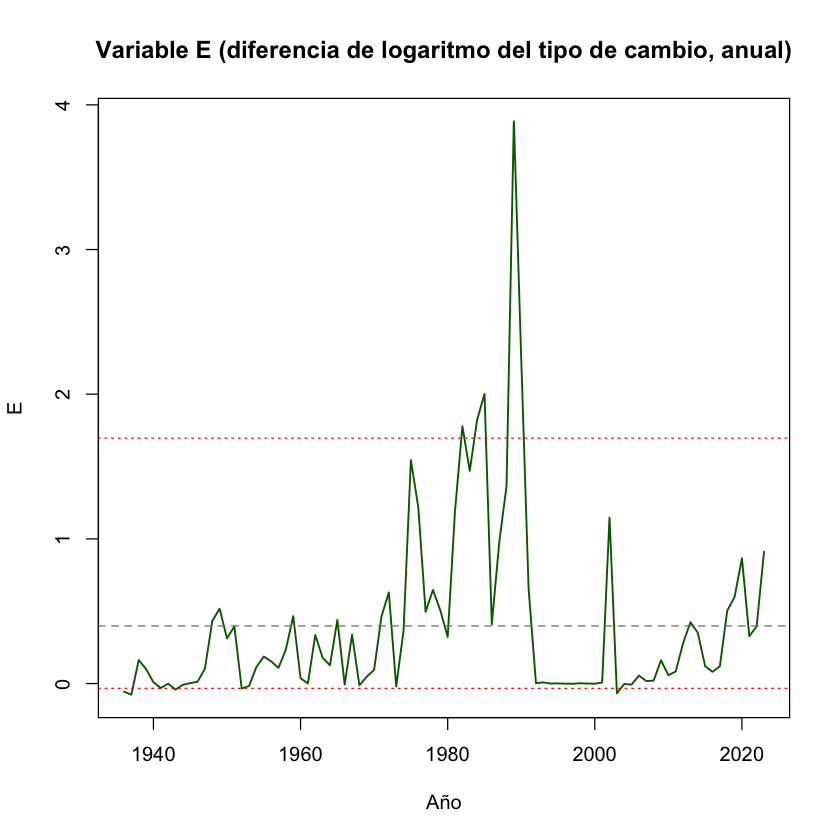

In [4]:
plot(df_anual_ferr$año, df_anual_ferr$E, type = "l", col = "darkgreen", lwd = 1.5,
     main = "Variable E (diferencia de logaritmo del tipo de cambio, anual)",
     xlab = "Año", ylab = "E")
abline(h = mean(df_anual_ferr$E, na.rm = TRUE), col = "grey50", lty = 2)
abline(h = quantile(df_anual_ferr$E, c(0.05, 0.95), na.rm = TRUE), col = "red", lty = 3)


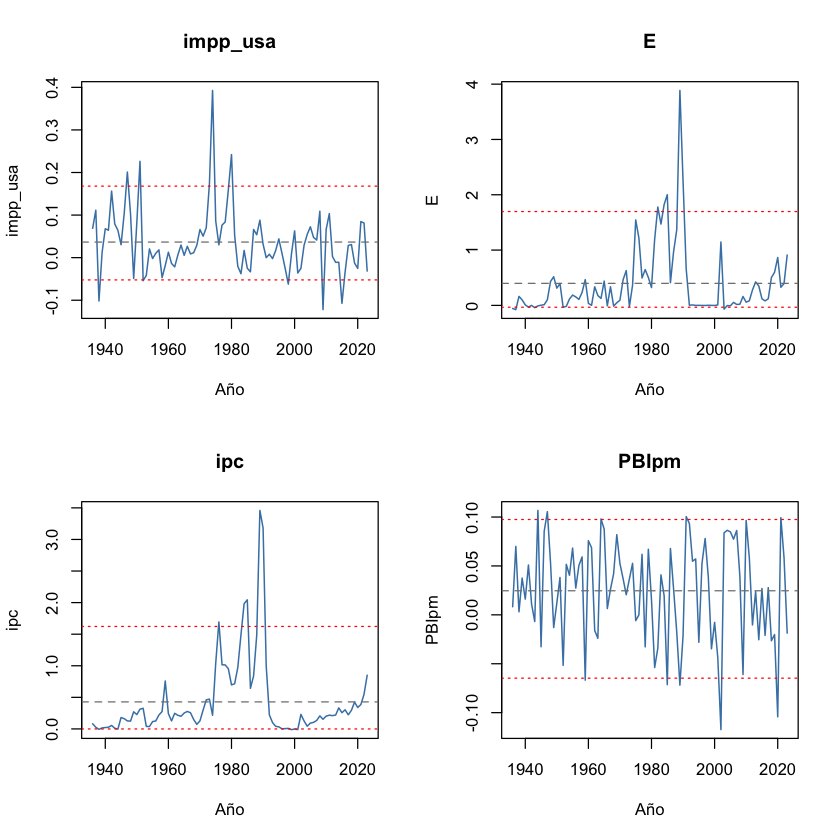

In [5]:
par(mfrow = c(2, 2))
for (v in c("impp_usa", "E", "ipc", "PBIpm")) {
  serie <- df_anual_ferr[[v]]
  plot(df_anual_ferr$año, serie, type = "l", col = "steelblue", lwd = 1.2,
       main = v, xlab = "Año", ylab = v)
  abline(h = mean(serie, na.rm = TRUE), col = "grey50", lty = 2)
  abline(h = quantile(serie, c(0.05, 0.95), na.rm = TRUE), col = "red", lty = 3)
}
par(mfrow = c(1, 1))


In [6]:
# SIN CAPPEO: se usan los datos originales (df_anual_ferr), incluidos los valores extremos
vars_modelo <- c("impp_usa", "E", "ipc", "PBIpm")

cat("Desvíos estándar (datos sin cappear):\n")
print(sapply(df_anual_ferr[, vars_modelo], sd, na.rm = TRUE))

# Los 5 años más extremos de E e ipc
for (v in c("E", "ipc")) {
  o <- order(abs(df_anual_ferr[[v]]), decreasing = TRUE)[1:5]
  cat("\nAños más extremos de", v, ":\n")
  print(data.frame(año = df_anual_ferr$año[o], valor = round(df_anual_ferr[[v]][o], 3)), row.names = FALSE)
}


Desvíos estándar (datos sin cappear):
  impp_usa          E        ipc      PBIpm 
0.07653640 0.63532513 0.62520664 0.05122031 

Años más extremos de E :
  año valor
 1989 3.886
 1990 2.239
 1985 2.001
 1984 1.823
 1982 1.778

Años más extremos de ipc :
  año valor
 1989 3.459
 1990 3.184
 1985 2.044
 1984 1.983
 1976 1.694


## Selección de rezagos con criterios de información (VAR lineal)

Antes de estimar los modelos no lineales: criterios AIC, HQ, SC (= BIC) y FPE para un VAR lineal con las mismas cuatro variables, de 1 a 4 rezagos (con 88 años, más rezagos dejan muy pocos grados de libertad), todos sobre la misma muestra. Además, el test de Portmanteau ajustado de los residuos del VAR lineal para cada número de rezagos (orientativo, con 6 y 8 rezagos del test).


In [7]:
if (!requireNamespace("vars", quietly = TRUE)) install.packages("vars")
library(vars)

vars_modelo <- c("impp_usa", "E", "ipc", "PBIpm")
Y <- na.omit(df_anual_ferr[, vars_modelo])
cat("Observaciones:", nrow(Y), "\n\n")

sel <- VARselect(Y, lag.max = 4, type = "const")
cat("Rezagos elegidos por cada criterio (SC = BIC):\n")
print(sel$selection)
cat("\nValores de los criterios (menor = mejor):\n")
print(round(sel$criteria, 4))

# Portmanteau ajustado de los residuos del VAR lineal, para cada p (orientativo).
# El test necesita más rezagos que el VAR: si no, queda NA.
p_port <- function(v, L) if (L > v$p) round(unname(serial.test(v, lags.pt = L, type = "PT.adjusted")$serial$p.value), 3) else NA
port_lineal <- do.call(rbind, lapply(1:4, function(p) {
  v <- VAR(Y, p = p, type = "const")
  data.frame(rezagos = p,
             p_autocorr_6 = p_port(v, 6), p_autocorr_8 = p_port(v, 8))
}))
cat("\nPortmanteau ajustado, VAR lineal (p-valor; < 0.05 = autocorrelación):\n")
print(port_lineal, row.names = FALSE)


Loading required package: MASS




Attaching package: ‘MASS’


The following object is masked from ‘package:plotly’:

    select


Loading required package: strucchange

Loading required package: zoo


Attaching package: ‘zoo’


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric


Loading required package: sandwich

Loading required package: urca

Loading required package: lmtest



Observaciones: 88 

Rezagos elegidos por cada criterio (SC = BIC):
AIC(n)  HQ(n)  SC(n) FPE(n) 
     1      1      1      1 

Valores de los criterios (menor = mejor):
              1        2        3        4
AIC(n) -16.3150 -16.2127 -16.1132 -15.9764
HQ(n)  -16.0824 -15.7939 -15.5082 -15.1854
SC(n)  -15.7363 -15.1709 -14.6084 -14.0086
FPE(n)   0.0000   0.0000   0.0000   0.0000

Portmanteau ajustado, VAR lineal (p-valor; < 0.05 = autocorrelación):
 rezagos p_autocorr_6 p_autocorr_8
       1        0.106        0.048
       2        0.190        0.132
       3        0.140        0.112
       4        0.067        0.006


## TVAR p = 1 (especificación principal)

Desvíos usados para escalar:
  impp_usa          E        ipc      PBIpm 
0.07653640 0.63532513 0.62520664 0.05122031 


Using 6 cores for 500 estimations rounds...

PHASE 1: Estimating all the parameters with a genetic algorithm...

Results from the genetic algorithm:

The lowest loglik:  -331.059

The largest loglik: -251.586

PHASE 2: Estimating all the parameters with a variable metric algorithm...

Results from the variable metric algorithm:

The lowest loglik:  -320.095

The largest loglik: -238.782

Filtering inappropriate estimates...

Filtered through 1 inappropriate  estimates with a larger log-likelihood

Calculating approximate standard errors...

Finished!




========= Unstructured fitted model ==========


Calculating approximate standard errors...



========= Structured fitted model (heteroskedasticity) ==========
Saving trained models to models/ folder

 >>> TESTS
PARA CORRER LOS TESTS CORRER LA SIGUIENTE FUNCION:
run_tests_sstvar(res, c(' ipc '), TRUE , 4 , 1 , 500 )

 >>> DIAGNOSTIC PLOTS


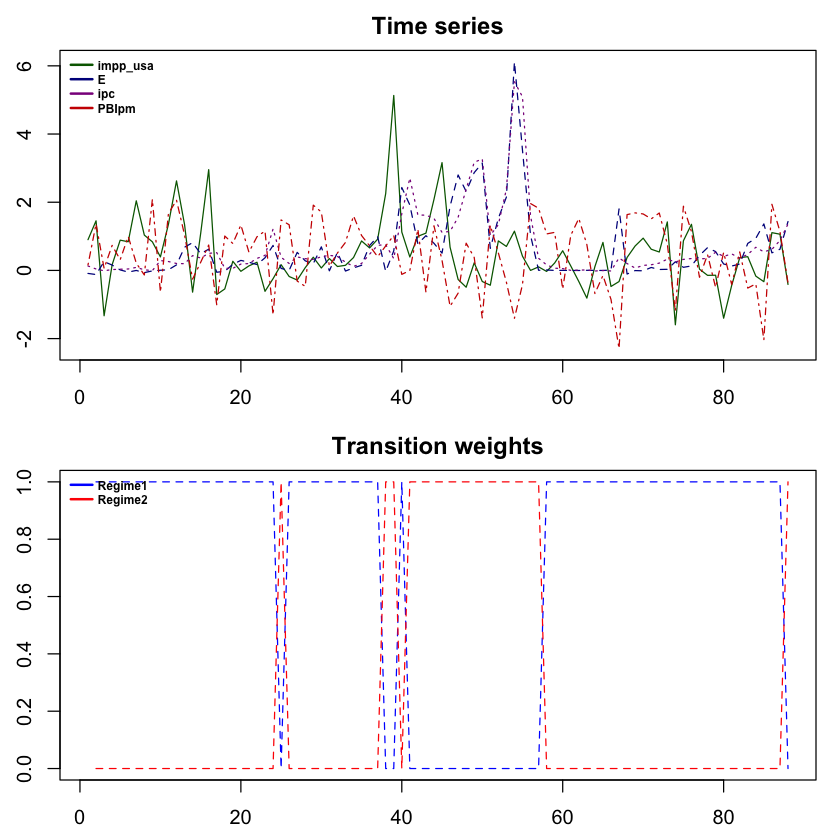

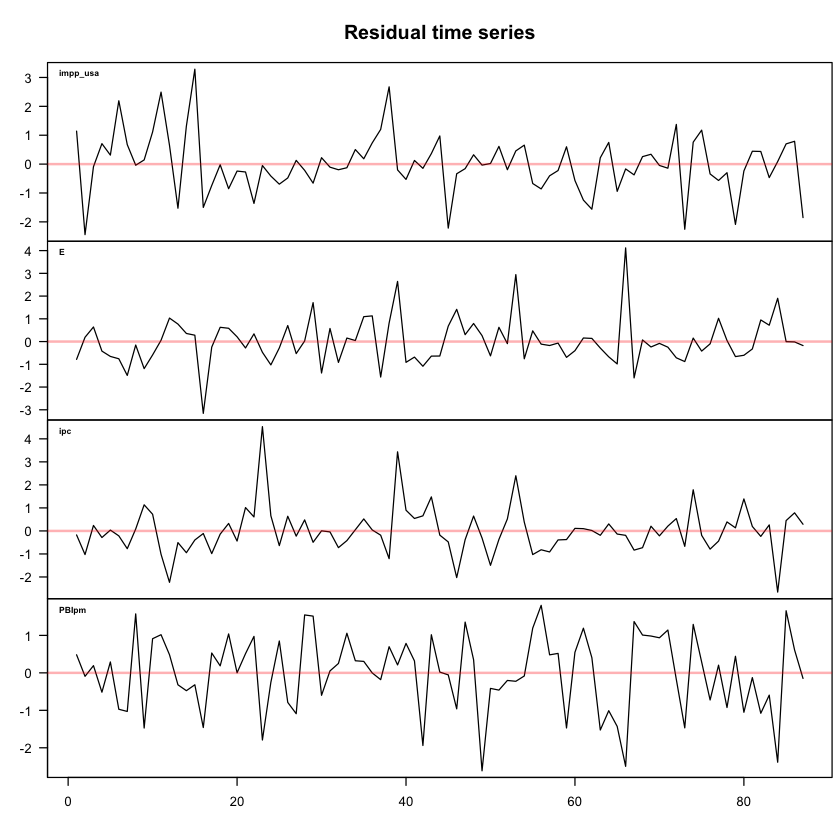

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



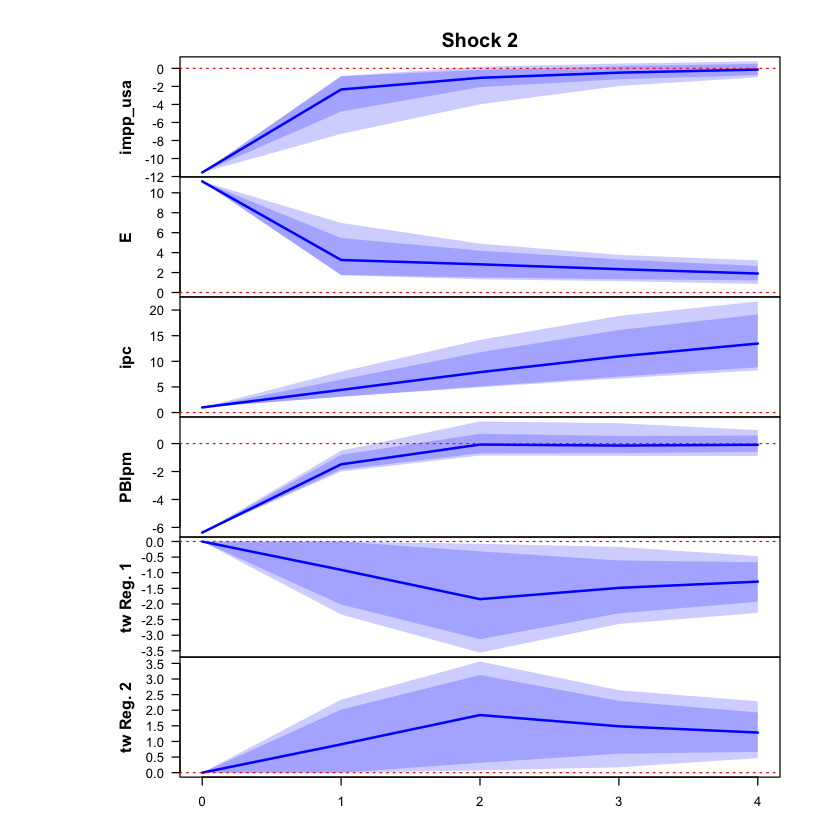

 >>> Linear IRF ( 1  shock units)


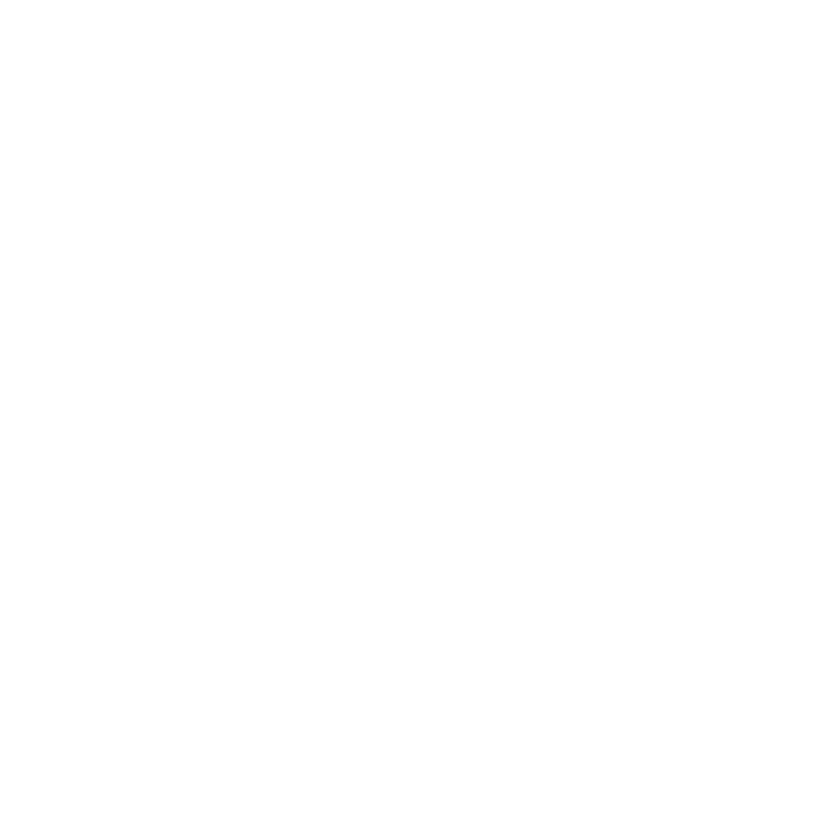

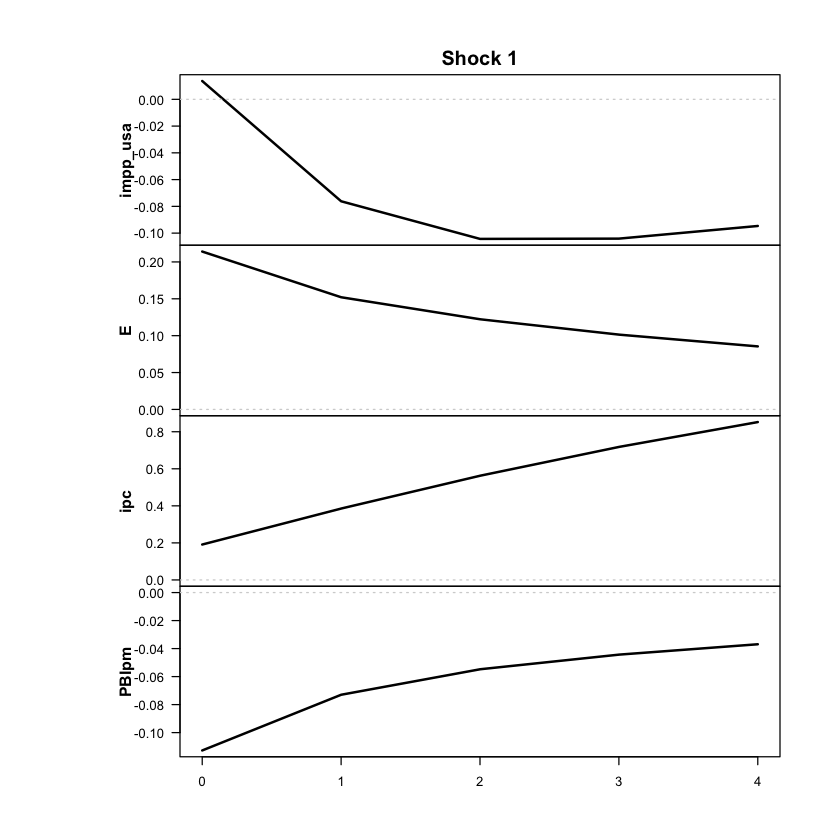

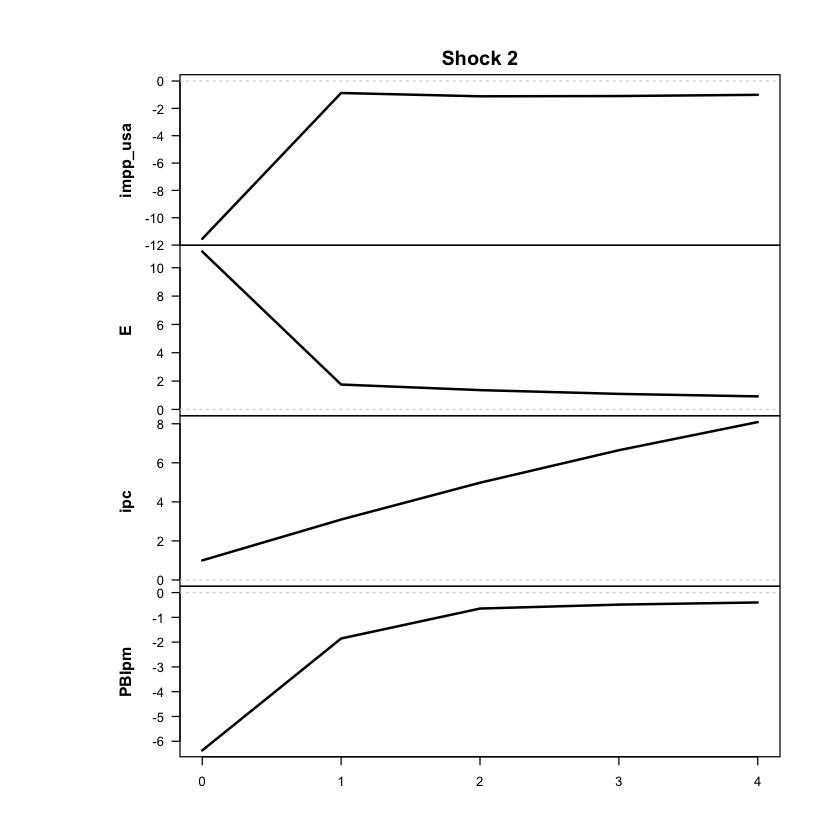

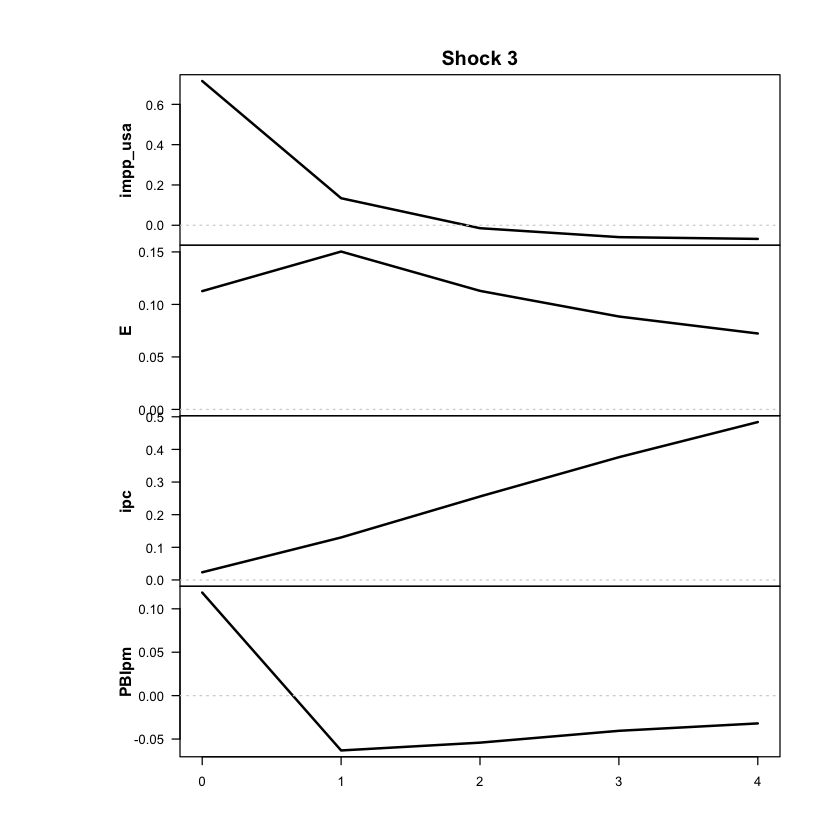

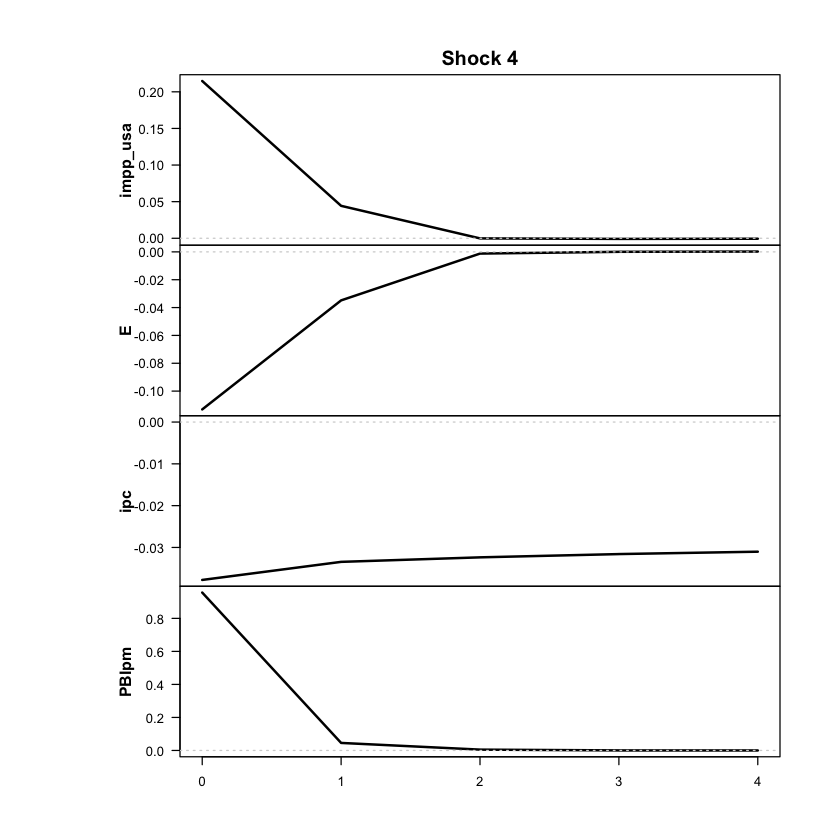

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



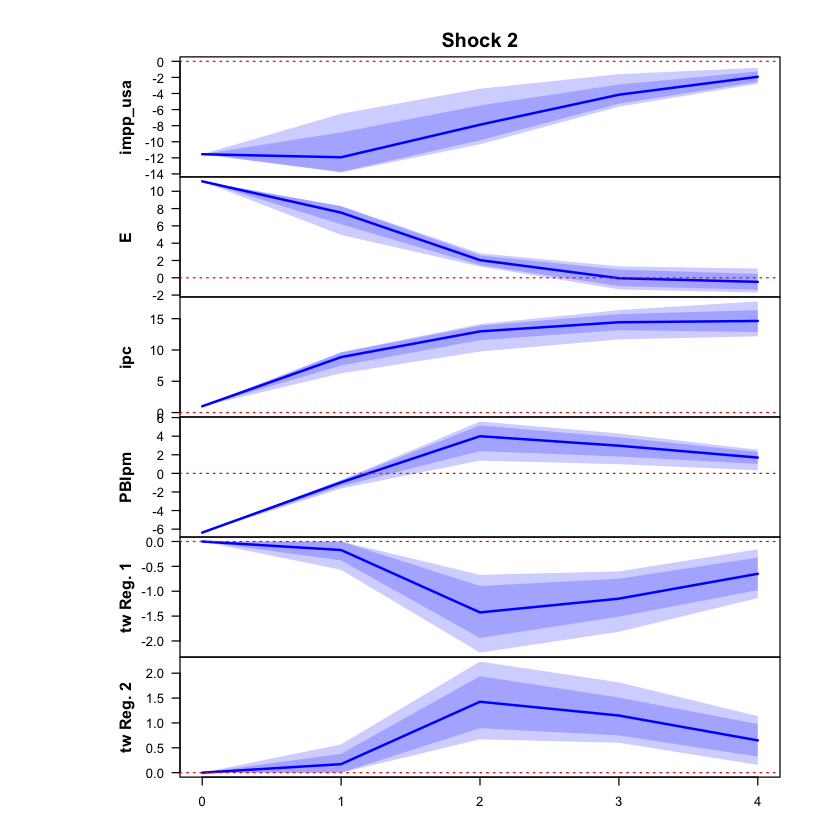

 >>> Linear IRF ( 1  shock units)


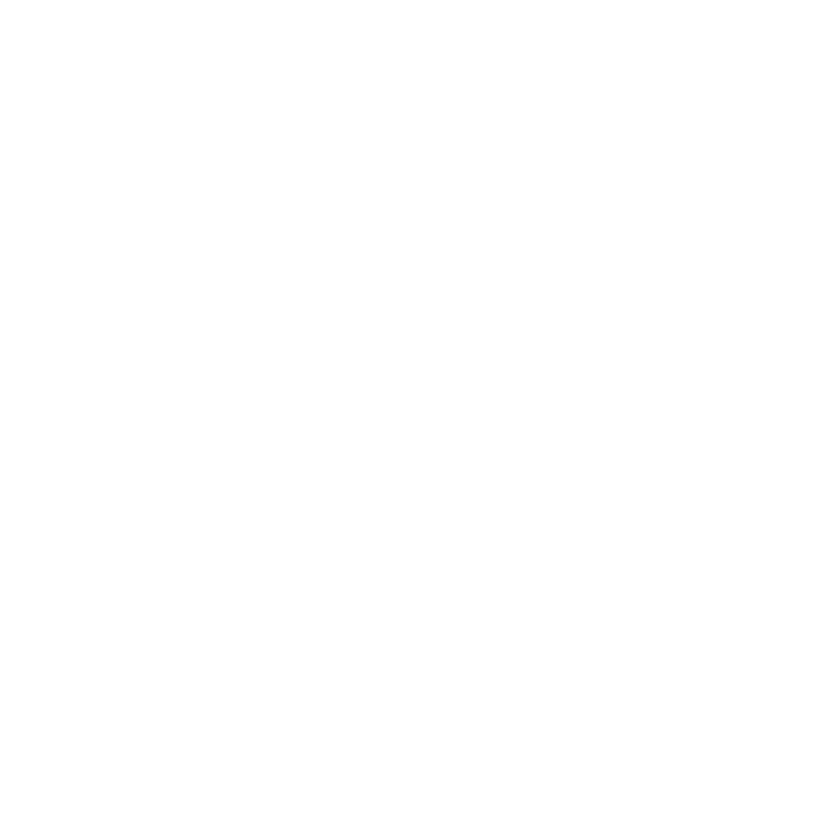

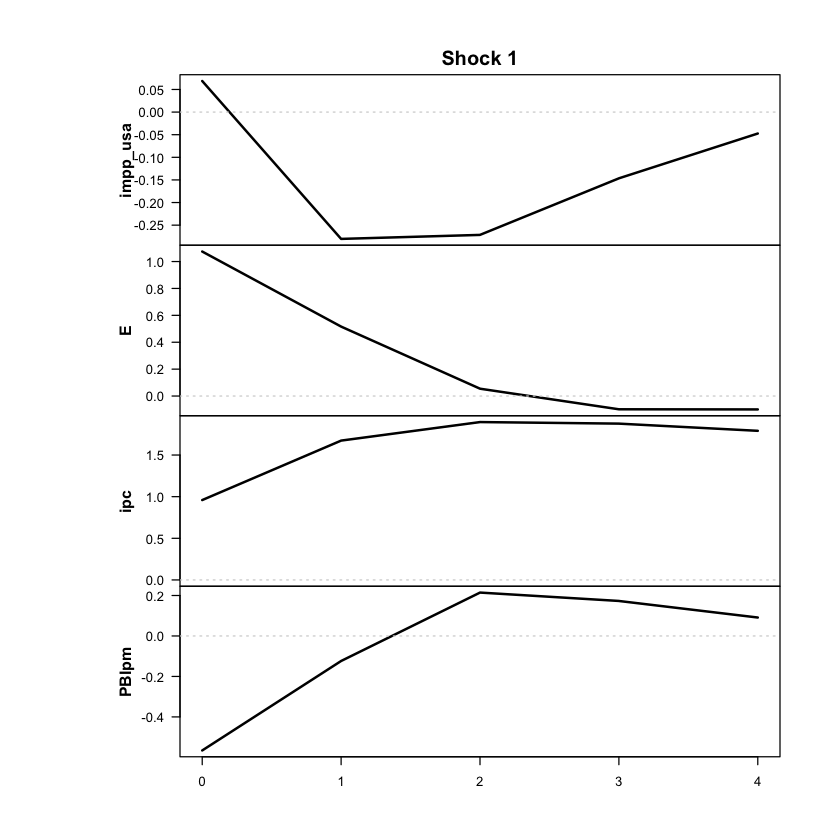

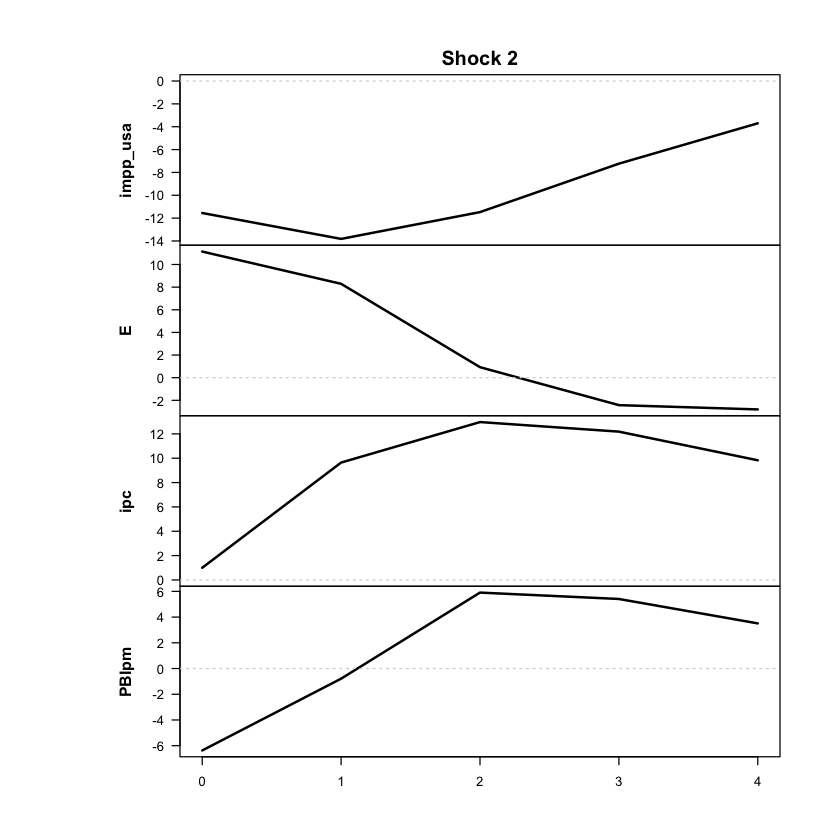

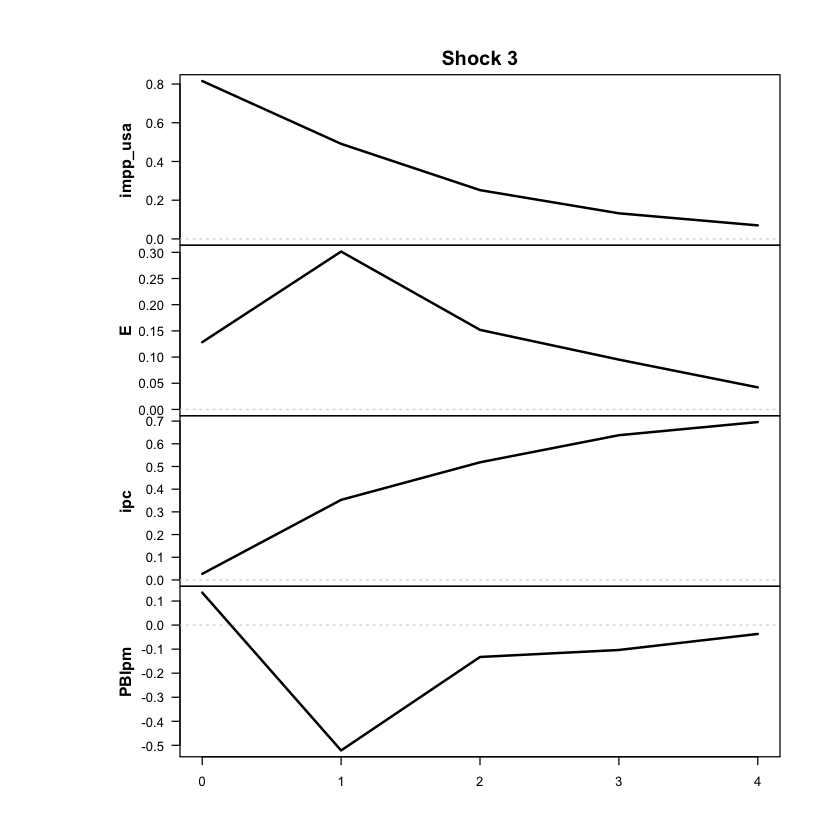

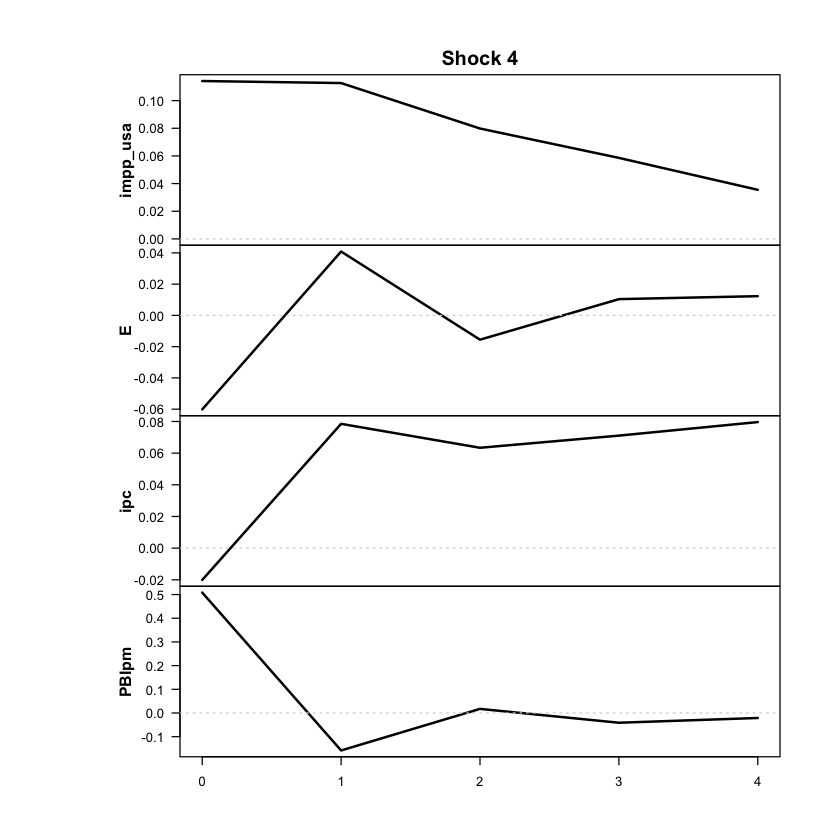

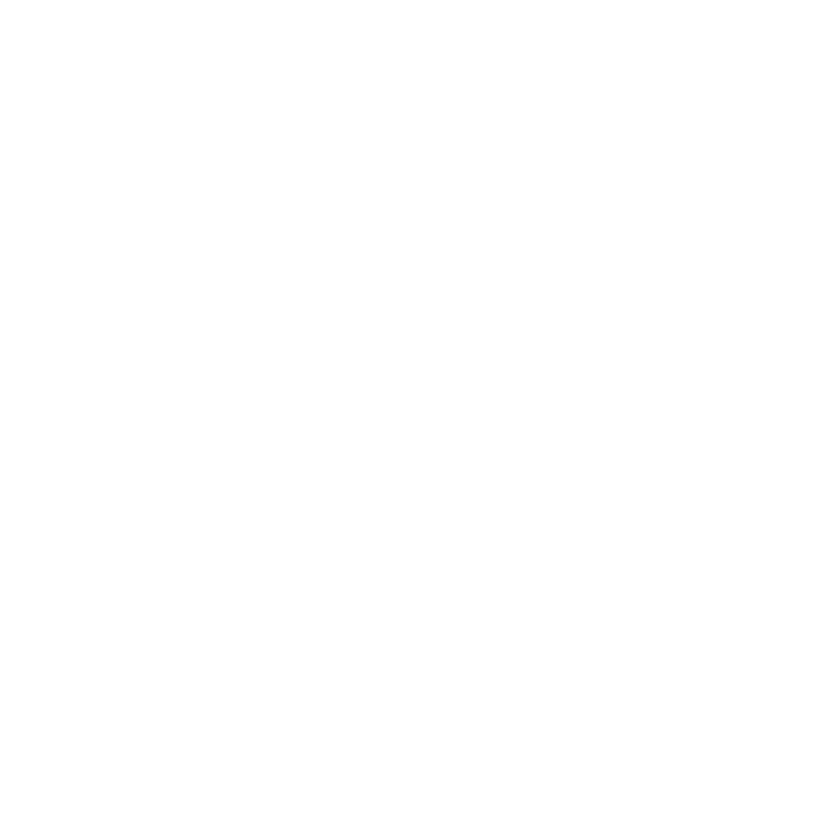

In [8]:
res <- run_threshold_tvar(
  data = df_anual_ferr,
  endog = c("impp_usa","E","ipc","PBIpm"),
  periodicity = 'anual', # 'trimestral' o 'anual' o mensual
  feature_lag = 1,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","PBIpm")
  run_tests = TRUE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = 4, # 4 años, igual que las LP anuales (en anual, NULL serían solo 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE   # primera corrida: estimar. Después de guardado, cambiar a TRUE
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [9]:
ic_tvar_p1 <- criterios_info(res, "TVAR p=1")
print(ic_tvar_p1)
saveRDS(ic_tvar_p1, "ic_tvar_p1_anual_ferr.rds")

    modelo regimenes parametros  loglik   AIC    HQ   BIC
1 TVAR p=1         2         61 -239.53 601.1 661.6 751.5


In [10]:
resumen_modelo(res, data = df_anual_ferr, endog = c("impp_usa", "E", "ipc", "PBIpm"))

Modelo: threshold | regímenes: 2 | rezagos: 1 | errores: Gaussian 
Umbrales: 55.8% anual 
Años por régimen (régimen de mayor peso): régimen 1 = 66 | régimen 2 = 21 

Promedio observado de cada variable en los años de cada régimen
(variación anual en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      2.79      6.59
E            21.44    188.88
ipc          20.65    231.92
PBIpm         2.80      1.61


In [11]:
explorar_optimos(res, n = 20)

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -238.78           117.2    NA         NA            73/14
             2 -239.53            55.8    NA         NA            66/21
             3 -239.53            58.2    NA         NA            66/21
             4 -239.53            53.9    NA         NA            66/21
             5 -239.53            57.3    NA         NA            66/21
             6 -239.53            55.1    NA         NA            66/21
             7 -239.53            58.3    NA         NA            66/21
             8 -239.53            54.5    NA         NA            66/21
             9 -239

In [12]:
identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "PBIpm"))
# Debe sugerir el shock 2 (= posición de E). Si sugiere otro, avisar antes de seguir.

Efecto de impacto de cada shock  (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0010 -0.0232  0.0548  0.0164
  E         0.1360  0.1861  0.0716 -0.0719
  ipc       0.1195  0.0164  0.0147 -0.0236
  PBIpm    -0.0058 -0.0086  0.0061  0.0490

Participación de E en el efecto de cada shock  :
shock_1 shock_2 shock_3 shock_4 
   0.69    0.64    0.15    0.11 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  0.879   0.088   0.205   0.329 

>>> Shock sugerido como cambiario: 1 (confirmalo: debe mover mucho a E y poco a ipc )


In [13]:
print_passthrough(res, endog = c("impp_usa","E","ipc","PBIpm"))

+++++++++ RÉGIMEN  1 +++++++++

>>> GIRF normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
0         0       0.0883
1         1       0.3906
2         2       0.6957
3         3       0.9674
4         4       1.1894

>>> IRF lineal normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
1         0       0.0883
2         1       0.2732
3         2       0.4397
4         3       0.5868
5         4       0.7141

+++++++++ RÉGIMEN  2 +++++++++

>>> GIRF normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
0         0       0.0883
1         1       0.7824
2         2       1.1455
3         3       1.2741
4         4       1.2928

>>> IRF lineal normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
1         0       0.0883
2         1       0.8515
3         2       1.1454
4         3       1.0759
5         4       0.8681



### ERPT y gráficos — TVAR p = 1

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 20.5%.

GIRF del régimen 1...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!

GIRF del régimen 2...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




+++ Régimen 1 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte    ipc   PBIpm
         0 0.0883 -0.0461
         1 0.3782 -0.0571
         2 0.6662 -0.0573
         3 0.9272 -0.0584
         4 1.1446 -0.0593

+++ Régimen 2 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte    ipc   PBIpm
         0 0.0883 -0.0461
         1 0.7830 -0.0531
         2 1.1400 -0.0239
         3 1.2643 -0.0022
         4 1.2767  0.0104


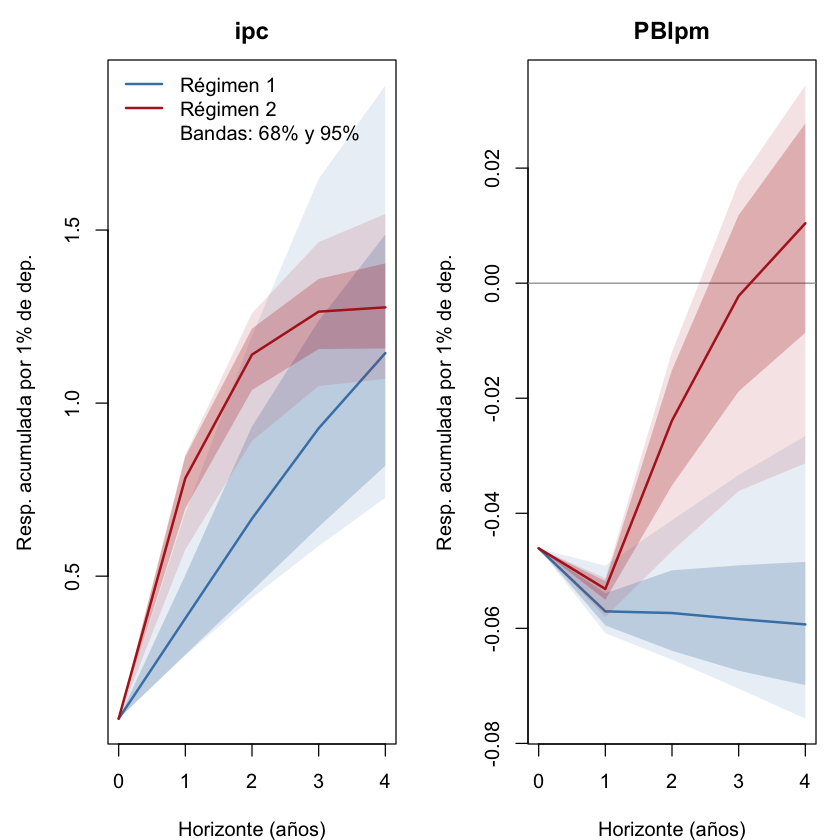


+++ Régimen 1 - IRF lineal acumulada por 1% de depreciación inicial (unidades originales) +++
 horizonte    ipc   PBIpm
         0 0.0883 -0.0461
         1 0.2732 -0.0595
         2 0.4397 -0.0642
         3 0.5868 -0.0677
         4 0.7141 -0.0706

+++ Régimen 2 - IRF lineal acumulada por 1% de depreciación inicial (unidades originales) +++
 horizonte    ipc   PBIpm
         0 0.0883 -0.0461
         1 0.8515 -0.0518
         2 1.1454 -0.0091
         3 1.0759  0.0301
         4 0.8681  0.0555


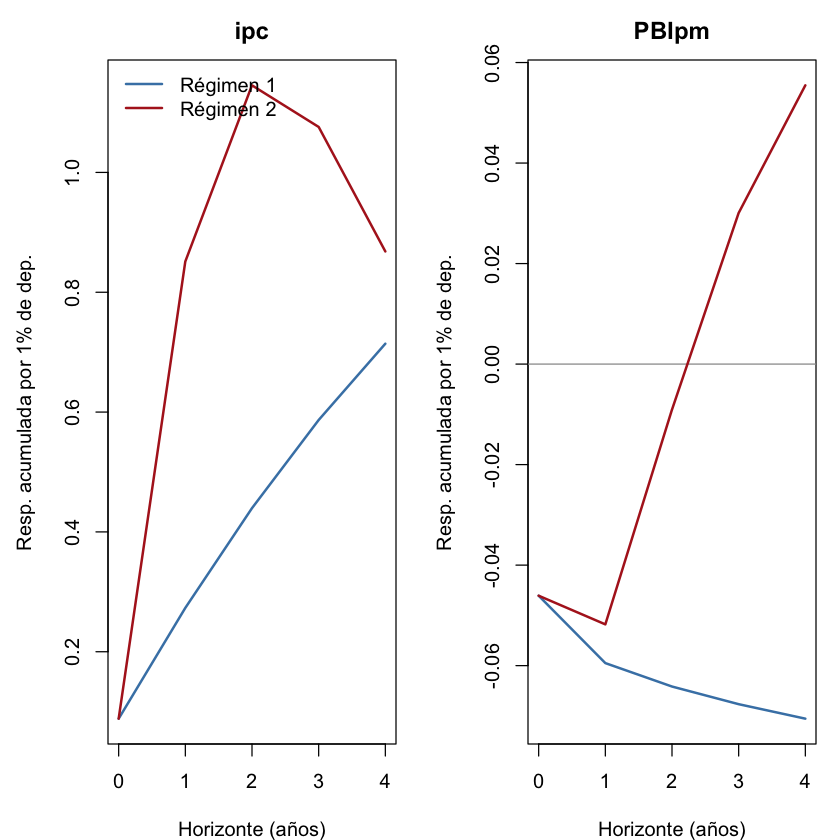

In [14]:
girf_impp_usa_tvar_p1 <- graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "PBIpm"),
                                        archivo = paste0(carpeta, "girf_original_impp_usa_tvar_p1_anual_ferr"))
irf_impp_usa_tvar_p1  <- graficar_irf_original(res, endog = c("impp_usa", "E", "ipc", "PBIpm"),
                                       archivo = paste0(carpeta, "irf_original_impp_usa_tvar_p1_anual_ferr"))

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 20.5%.



GIRF del régimen 1...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!

GIRF del régimen 2...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




+++ Régimen 1 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte      E    ipc   PBIpm
         0 1.0000 0.0883 -0.0461
         1 1.2778 0.3782 -0.0571
         2 1.5159 0.6662 -0.0573
         3 1.7189 0.9272 -0.0584
         4 1.8859 1.1446 -0.0593

+++ Régimen 2 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte      E    ipc   PBIpm
         0 1.0000 0.0883 -0.0461
         1 1.6763 0.7830 -0.0531
         2 1.8533 1.1400 -0.0239
         3 1.8454 1.2643 -0.0022
         4 1.7978 1.2767  0.0104


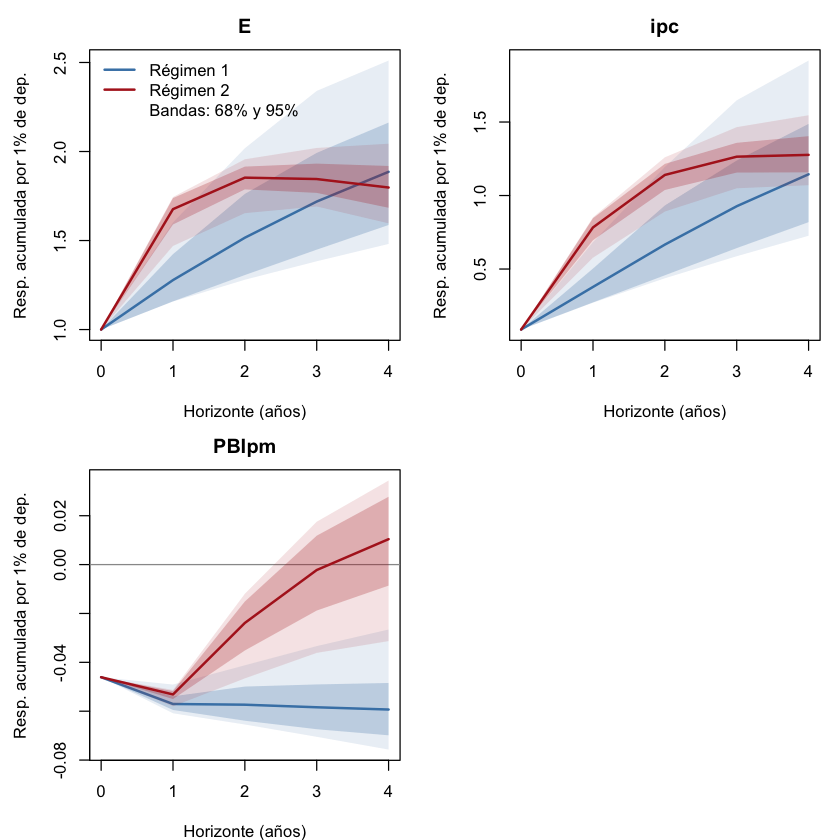

In [15]:
graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "PBIpm"),
                       variables = c("E", "ipc", "PBIpm"),
                       archivo = paste0(carpeta, "girf_original_impp_usa_tvar_p1_con_E_anual_ferr"))

In [16]:
out_impp_usa_tvar_p1 <- erpt_historia(res, data = df_anual_ferr,
                             endog = c("impp_usa", "E", "ipc", "PBIpm"))

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 20.5%.

Estimando 87 GIRFs (una por año), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Años dominados por cada régimen (peso > 0.9): régimen 1 = 66 | régimen 2 = 21 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.9841

Promedio entre años:
  horizonte reg_bajo_original reg_alto_original
1         0            0.0883            0.0883
2         1            0.3448            0.7663
3         2            0.5885            1.1065
4         3            0.8222            1.2210
5         4            1.0325            1.2283

Mediana entre años (robusta a años con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0           0.0883           0.0883
2         1           0.2944           0.7710
3         2           0.5057           1.1370
4         3           0.7379           1.2261
5         4           0.9618           1.2294


In [17]:
out_impp_usa_tvar_p1_acum <- erpt_historia(res, data = df_anual_ferr,
                                  endog = c("impp_usa", "E", "ipc", "PBIpm"),
                                  definicion = "acumulado")

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 20.5%.



Estimando 87 GIRFs (una por año), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Años dominados por cada régimen (peso > 0.9): régimen 1 = 66 | régimen 2 = 21 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.9841

Promedio entre años:
  horizonte reg_bajo_original reg_alto_original
1         0            0.0883            0.0883
2         1            0.2729            0.4603
3         2            0.4006            0.6050
4         3            0.4996            0.6749
5         4            0.5708            0.6985

Mediana entre años (robusta a años con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0           0.0883           0.0883
2         1           0.2494           0.4631
3         2           0.3701           0.6151
4         3           0.4777           0.6839
5         4           0.5557           0.7006


In [18]:
saveRDS(out_impp_usa_tvar_p1,      "out_impp_usa_tvar_p1_anual_ferr.rds")
saveRDS(out_impp_usa_tvar_p1_acum, "out_impp_usa_tvar_p1_acum_anual_ferr.rds")

In [20]:
for (f in c("out_impp_usa_tvar_p1_anual_ferr.rds", "out_impp_usa_tvar_p1_acum_anual_ferr.rds",
            "out_impp_usa_tvar_p2_anual_ferr.rds", "out_impp_usa_tvar_p2_acum_anual_ferr.rds")) {
  if (!file.exists(f)) { cat(f, "| todavía no existe\n"); next }
  o <- readRDS(f)
  cat(f, "| años:", ncol(o$erpt), "| primer año:", colnames(o$erpt)[1], "\n")
}

out_impp_usa_tvar_p1_anual_ferr.rds | años: 87 | primer año: 1937 
out_impp_usa_tvar_p1_acum_anual_ferr.rds | años: 87 | primer año: 1937 
out_impp_usa_tvar_p2_anual_ferr.rds | todavía no existe
out_impp_usa_tvar_p2_acum_anual_ferr.rds | todavía no existe


In [21]:
g_p1      <- graficos_con_mediana(out_impp_usa_tvar_p1)        # relativo al shock
g_p1_acum <- graficos_con_mediana(out_impp_usa_tvar_p1_acum)   # transmisión

Gráficos con la MEDIANA por régimen como referencia.
Gráficos con la MEDIANA por régimen como referencia.


HTML widgets cannot be represented in plain text (need html)

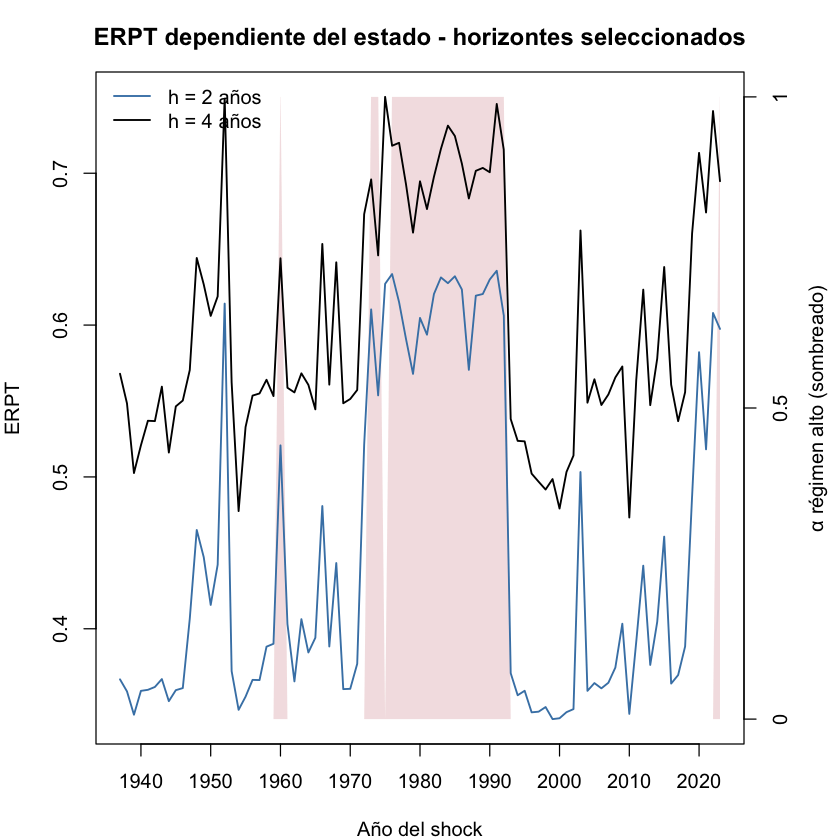

In [22]:
graficar_erpt(g_p1_acum, archivo = paste0(carpeta, "erpt_impp_usa_tvar_p1_acum_anual_ferr"))

In [ ]:
#Lo comento porque es feo, es de puntos (para bajar el tamaño de la notebook)
#graficar_erpt_regimen_3d(out_impp_usa_tvar_p1_acum,
                         #archivo = paste0(carpeta, "erpt_regimen_3d_impp_usa_tvar_p1_acum_anual_ferr"))

In [ ]:
#Lo comento porque es feo, es de rayas verticales (para bajar el tamaño de la notebook)
#graficar_erpt_regimen_red(out_impp_usa_tvar_p1_acum, h = 4,
                          #archivo = paste0(carpeta, "erpt_red_impp_usa_tvar_p1_acum_h4_anual_ferr"))

Mediana de ERPT por régimen (trimestres con peso > 0.9):
 horizonte reg_bajo_mediana reg_alto_mediana
         4            0.556            0.701


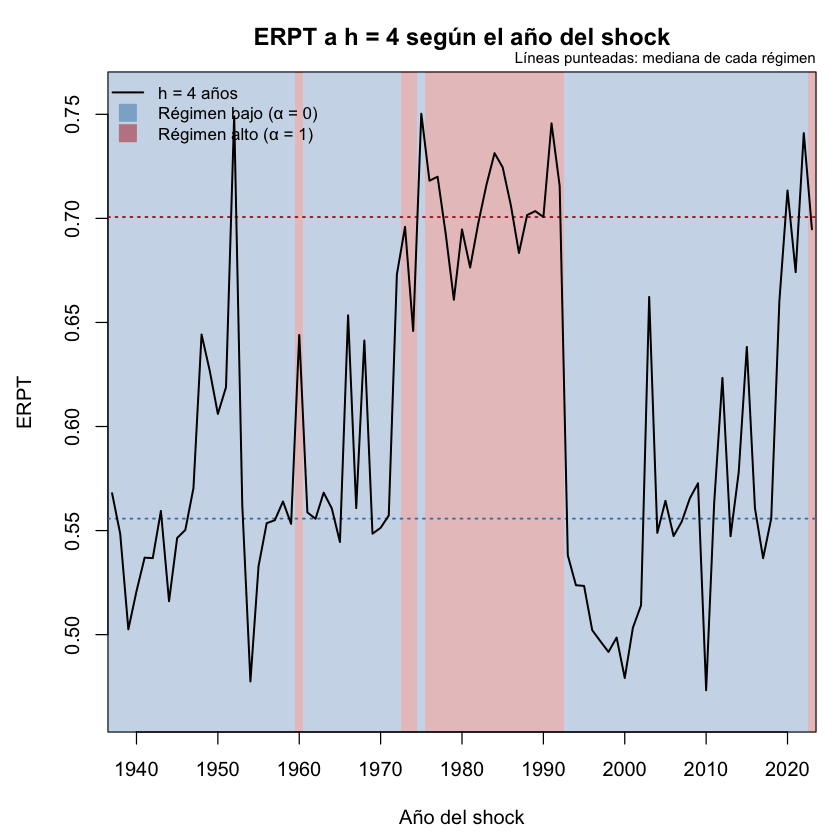

In [23]:
graficar_erpt_2d_bandas(g_p1_acum, horizontes = 4,
                        archivo = paste0(carpeta, "erpt_2d_bandas_impp_usa_tvar_p1_acum_anual_ferr"))

HTML widgets cannot be represented in plain text (need html)

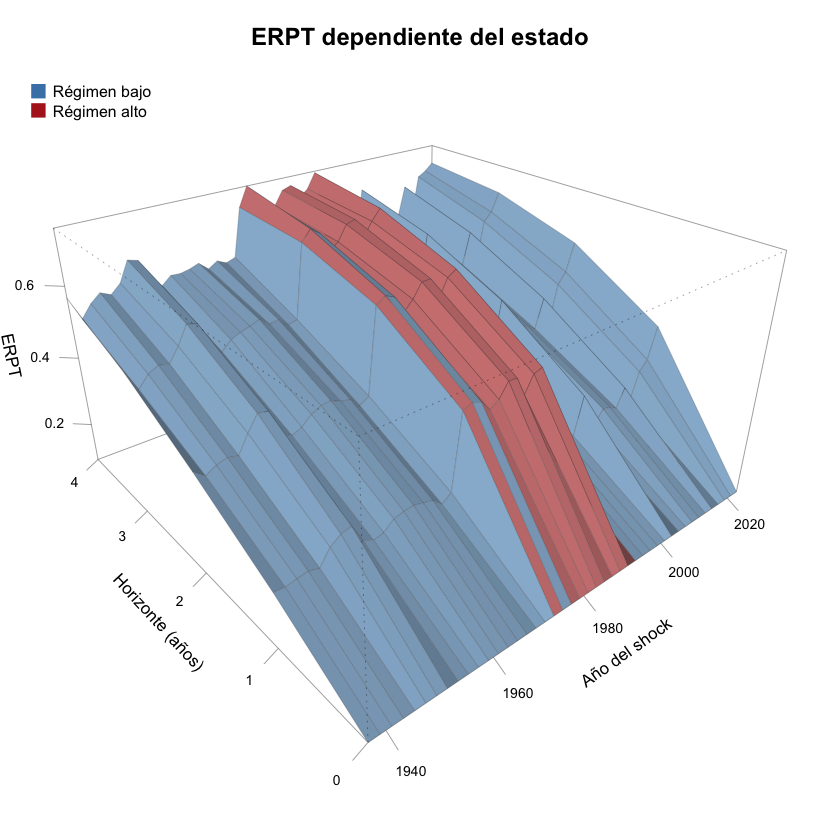

In [24]:
graficar_erpt_manta(g_p1_acum, cada = 2,
                    archivo = paste0(carpeta, "erpt_manta_impp_usa_tvar_p1_acum_c2_anual_ferr"))

In [ ]:
#Lo comenté porque es muy parecido al anterior, así achico la notebook
#graficar_erpt_manta(out_impp_usa_tvar_p1_acum, archivo = paste0(carpeta, "erpt_manta_impp_usa_tvar_p1_acum_c1_anual_ferr"))

In [25]:
#Lo comenté para achicar la notebook, total es muy parecido a los anteriores.
#graficar_erpt_manta(out_impp_usa_tvar_p1_acum, cada = 2, theta = -25, phi = 30,
                    #archivo = paste0(carpeta, "erpt_manta_impp_usa_tvar_p1_acum_c2_theta25_anual_ferr"))

El gif a continuación es muy, muy claro. USAR esta versión

In [26]:
guardar_gif_erpt_h(g_p1_acum, h = 4,
                   archivo = paste0(carpeta, "gif_erpt_h4_impp_usa_tvar_p1_acum_anual_ferr"))

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/GRAFICOS_TVAR_VLSTAR_Anuales/gif_erpt_h4_impp_usa_tvar_p1_acum_anual_ferr.gif



In [27]:
guardar_gif_erpt_h(g_p1_acum, h = 4,
                   marcas = c(1975, 1989, 2002, 2018),
                   archivo = paste0(carpeta, "gif_erpt_h4_marcas_impp_usa_tvar_p1_acum_anual_ferr"))

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/GRAFICOS_TVAR_VLSTAR_Anuales/gif_erpt_h4_marcas_impp_usa_tvar_p1_acum_anual_ferr.gif



GIF 3d modo "construir"

In [28]:
guardar_gif_manta(g_p1_acum, modo = "construir",
                  archivo = paste0(carpeta, "gif_manta_construir_impp_usa_tvar_p1_acum_anual_ferr"))

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/GRAFICOS_TVAR_VLSTAR_Anuales/gif_manta_construir_impp_usa_tvar_p1_acum_anual_ferr.gif



In [29]:
guardar_gif_manta(g_p1_acum, modo = "construir",
                  marcas = c(1975, 1989, 2002, 2018),
                  archivo = paste0(carpeta, "gif_manta_construir_marcas_impp_usa_tvar_p1_acum_anual_ferr"))

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/GRAFICOS_TVAR_VLSTAR_Anuales/gif_manta_construir_marcas_impp_usa_tvar_p1_acum_anual_ferr.gif



GIF 3d modo "rotar"

In [30]:
guardar_gif_manta(g_p1_acum, modo = "rotar",
                  archivo = paste0(carpeta, "gif_manta_rotar_impp_usa_tvar_p1_acum_anual_ferr"))

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/GRAFICOS_TVAR_VLSTAR_Anuales/gif_manta_rotar_impp_usa_tvar_p1_acum_anual_ferr.gif



In [31]:
guardar_gif_manta(g_p1_acum, modo = "rotar",
                  marcas = c(1975, 1989, 2002, 2018),
                  archivo = paste0(carpeta, "gif_manta_rotar_marcas_impp_usa_tvar_p1_acum_anual_ferr"))

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/GRAFICOS_TVAR_VLSTAR_Anuales/gif_manta_rotar_marcas_impp_usa_tvar_p1_acum_anual_ferr.gif



In [32]:
graficar_slider(g_p1_acum, archivo = paste0(carpeta, "slider_impp_usa_tvar_p1_acum_anual_ferr"))

HTML widgets cannot be represented in plain text (need html)

 horizonte   1987   1988   1989   1990
         0 0.0883 0.0883 0.0883 0.0883
         1 0.4305 0.4743 0.4759 0.4882
         2 0.5705 0.6194 0.6205 0.6300
         3 0.6476 0.6839 0.6858 0.6895
         4 0.6834 0.7016 0.7035 0.7006


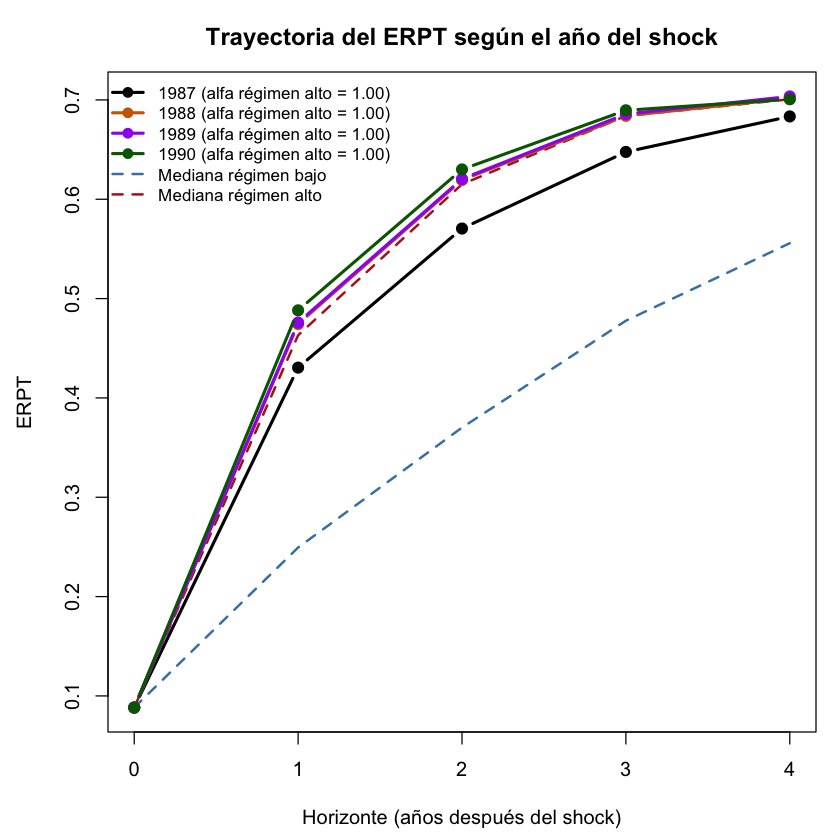

In [33]:
graficar_trayectorias(g_p1_acum,
                      trimestres = c(1987, 1988, 1989, 1990),
                      archivo = paste0(carpeta, "trayectorias_impp_usa_tvar_p1_acum_1987_1988_1989_1990_anual_ferr"))

 horizonte   1973   1974   1975   1976
         0 0.0883 0.0883 0.0883 0.0883
         1 0.4625 0.4128 0.4727 0.4865
         2 0.6103 0.5537 0.6272 0.6336
         3 0.6792 0.6216 0.7093 0.6996
         4 0.6959 0.6459 0.7503 0.7181


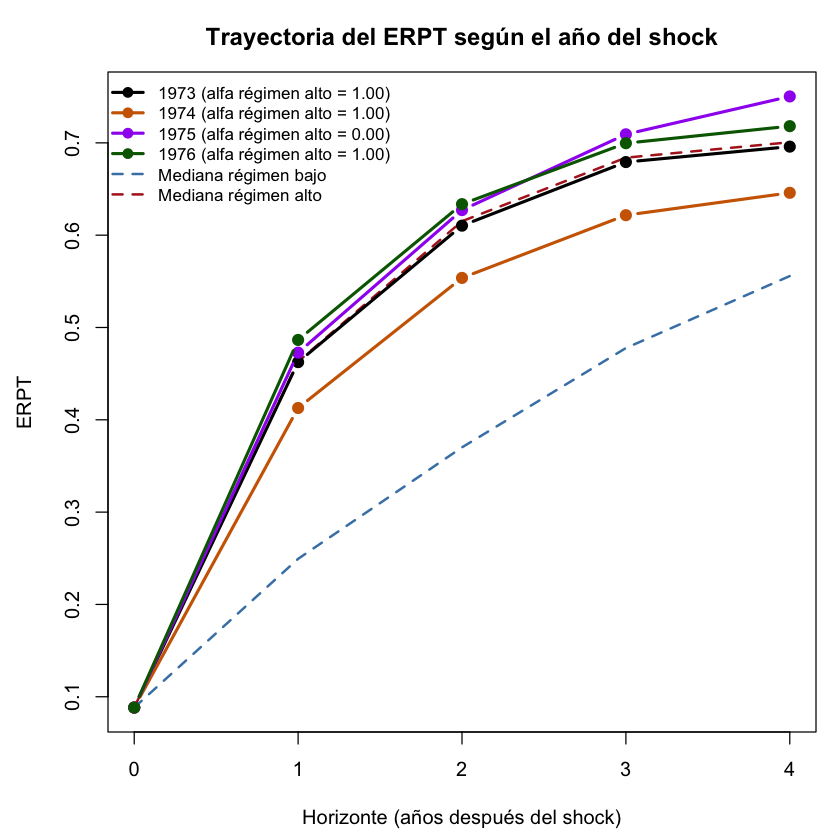

In [34]:
graficar_trayectorias(g_p1_acum,
                      trimestres = c(1973, 1974, 1975, 1976),
                      archivo = paste0(carpeta, "trayectorias_impp_usa_tvar_p1_acum_1973_1974_1975_1976_anual_ferr"))

 horizonte   1989   1990   1991   1992
         0 0.0883 0.0883 0.0883 0.0883
         1 0.4759 0.4882 0.4835 0.4561
         2 0.6205 0.6300 0.6358 0.6065
         3 0.6858 0.6895 0.7157 0.6844
         4 0.7035 0.7006 0.7456 0.7156


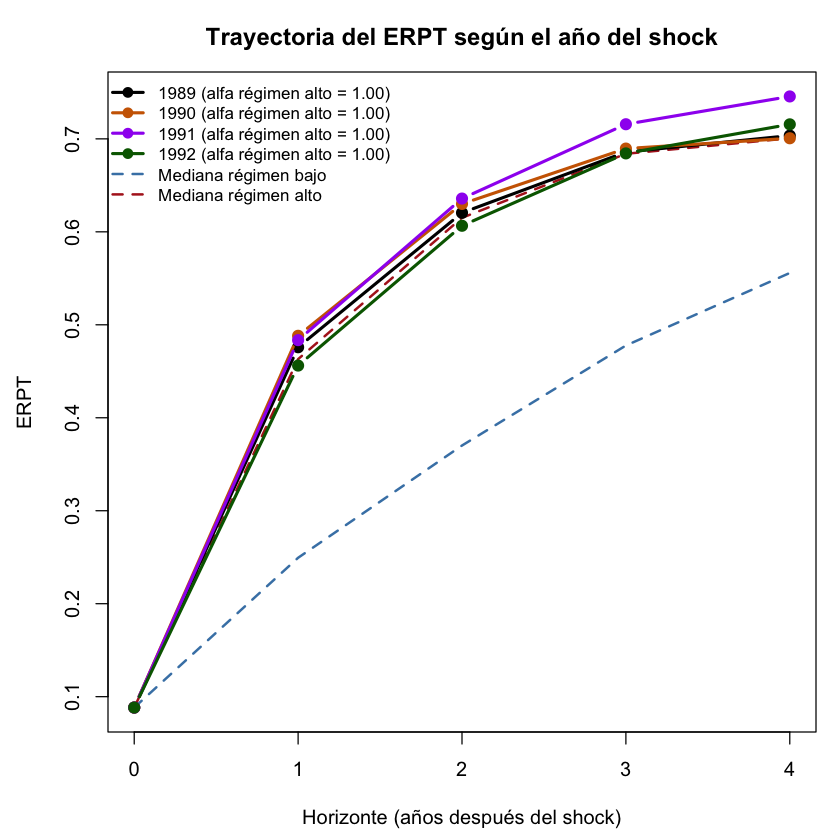

In [35]:
graficar_trayectorias(g_p1_acum,
                      trimestres = c(1989, 1990, 1991, 1992),
                      archivo = paste0(carpeta, "trayectorias_impp_usa_tvar_p1_acum_1989_1990_1991_1992_anual_ferr"))

 horizonte   2001   2002   2003   2004
         0 0.0883 0.0883 0.0883 0.0883
         1 0.2371 0.2360 0.3442 0.2388
         2 0.3451 0.3471 0.5032 0.3591
         3 0.4300 0.4344 0.6051 0.4675
         4 0.5033 0.5141 0.6623 0.5489


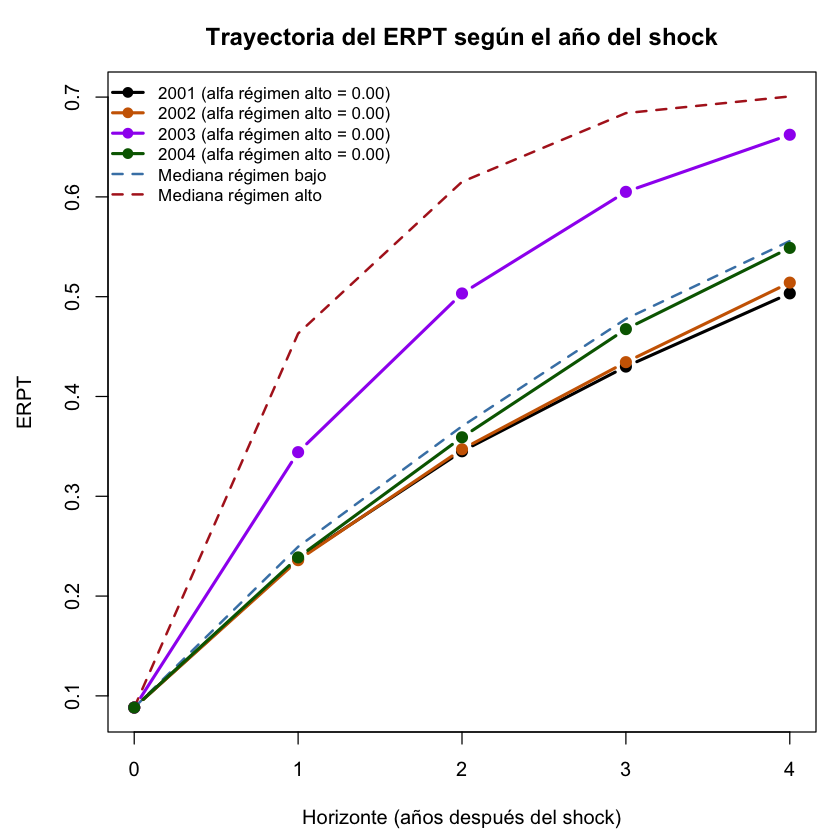

In [36]:
graficar_trayectorias(g_p1_acum,
                      trimestres = c(2001, 2002, 2003, 2004),
                      archivo = paste0(carpeta, "trayectorias_impp_usa_tvar_p1_acum_2001_2002_2003_2004_anual_ferr"))

 horizonte   2016   2017   2018   2019
         0 0.0883 0.0883 0.0883 0.0883
         1 0.2400 0.2540 0.2629 0.3351
         2 0.3639 0.3695 0.3884 0.4872
         3 0.4762 0.4637 0.4939 0.5915
         4 0.5607 0.5367 0.5558 0.6603


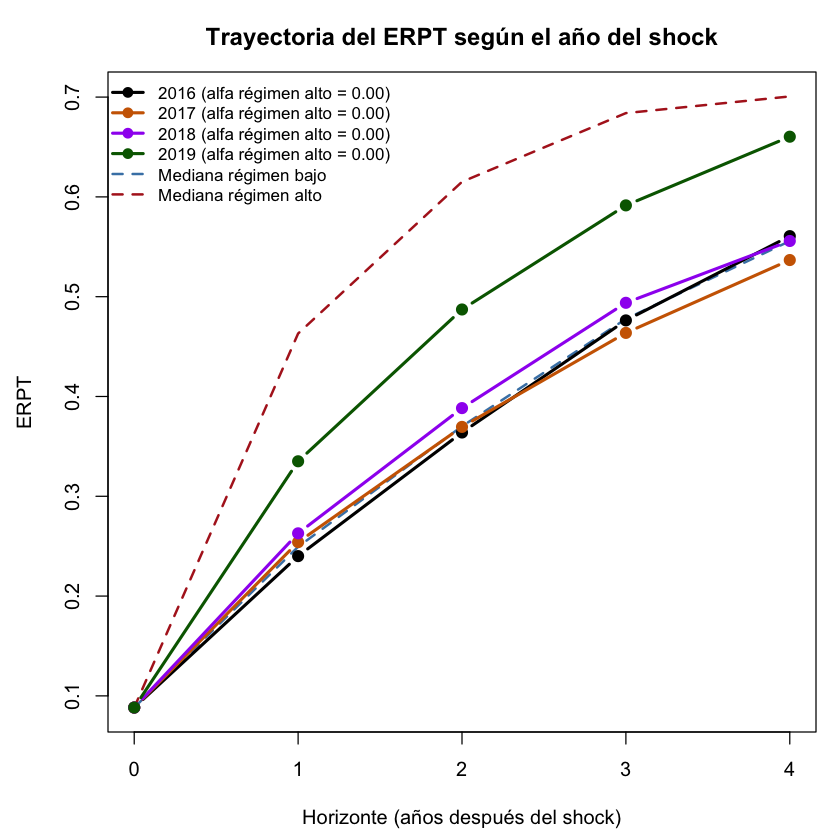

In [37]:
graficar_trayectorias(g_p1_acum,
                      trimestres = c(2016, 2017, 2018, 2019),
                      archivo = paste0(carpeta, "trayectorias_impp_usa_tvar_p1_acum_2016_2017_2018_2019_anual_ferr"))

 horizonte   1950   1983   1988   2002
         0 0.0883 0.0883 0.0883 0.0883
         1 0.2853 0.4869 0.4743 0.2360
         2 0.4157 0.6314 0.6194 0.3471
         3 0.5248 0.6959 0.6839 0.4344
         4 0.6060 0.7160 0.7016 0.5141


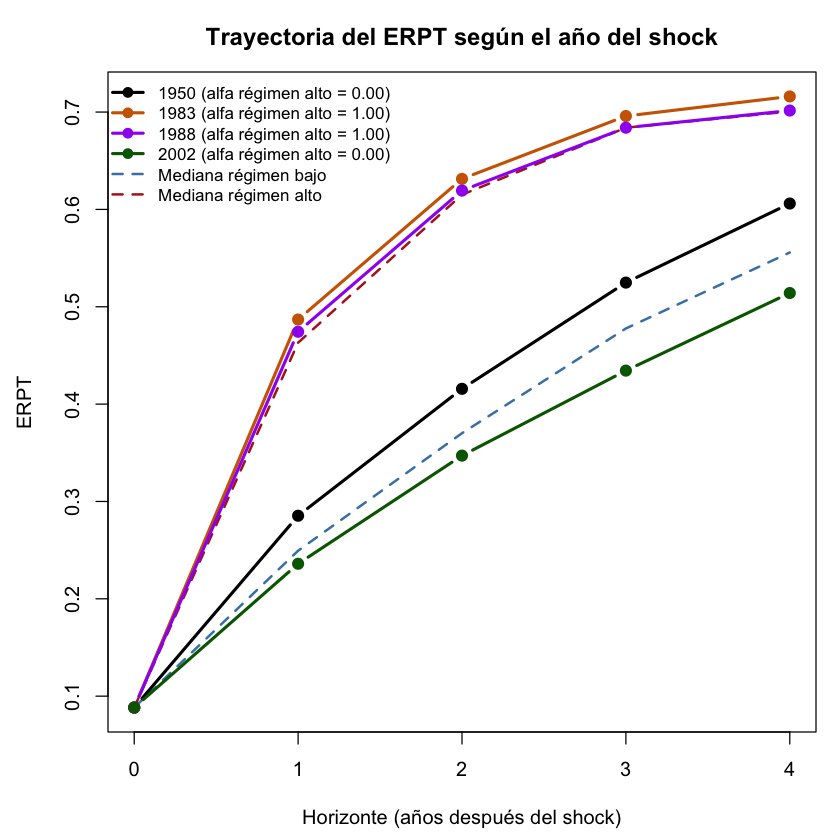

In [39]:
graficar_trayectorias(g_p1_acum,
                      trimestres = c(1950, 1983, 1988, 2002),
                      archivo = paste0(carpeta, "trayectorias_impp_usa_tvar_p1_acum_1950_1983_1988_2002_anual_ferr"))

In [40]:
guardar_gif(g_p1_acum, archivo = paste0(carpeta, "gif_impp_usa_tvar_p1_acum_anual_ferr"))

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/GRAFICOS_TVAR_VLSTAR_Anuales/gif_impp_usa_tvar_p1_acum_anual_ferr.gif



In [41]:
guardar_gif(g_p1_acum, archivo = paste0(carpeta, "gif_impp_usa_tvar_p1_acum_lento_anual_ferr"),
            segundos_por_cuadro = 0.5, cada = 2)

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/GRAFICOS_TVAR_VLSTAR_Anuales/gif_impp_usa_tvar_p1_acum_lento_anual_ferr.gif



  horizonte reg_bajo_original reg_alto_original
1         0            0.0883            0.0883
2         1            0.2565            0.6780
3         2            0.2437            0.3402
4         3            0.2336            0.1145
5         4            0.2103            0.0073
Gráficos con la MEDIANA por régimen como referencia.


HTML widgets cannot be represented in plain text (need html)

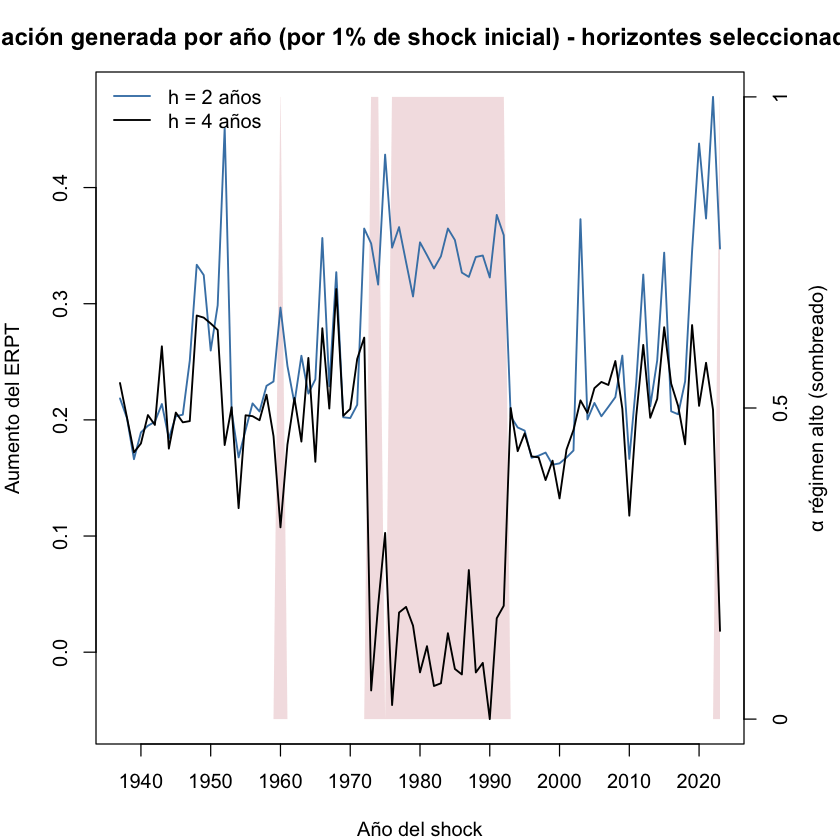

In [42]:
inc_impp_usa_tvar_p1 <- erpt_incremental(out_impp_usa_tvar_p1)
graficar_erpt(graficos_con_mediana(inc_impp_usa_tvar_p1),
              archivo = paste0(carpeta, "erpt_impp_usa_tvar_p1_incremental_anual_ferr"),
              titulo = "Inflación generada por año (por 1% de shock inicial)",
              eje_z = "Aumento del ERPT")

  horizonte reg_bajo_original reg_alto_original
1         0            0.0883            0.0883
2         1            0.1846            0.3720
3         2            0.1277            0.1447
4         3            0.0990            0.0698
5         4            0.0712            0.0237
Gráficos con la MEDIANA por régimen como referencia.


HTML widgets cannot be represented in plain text (need html)

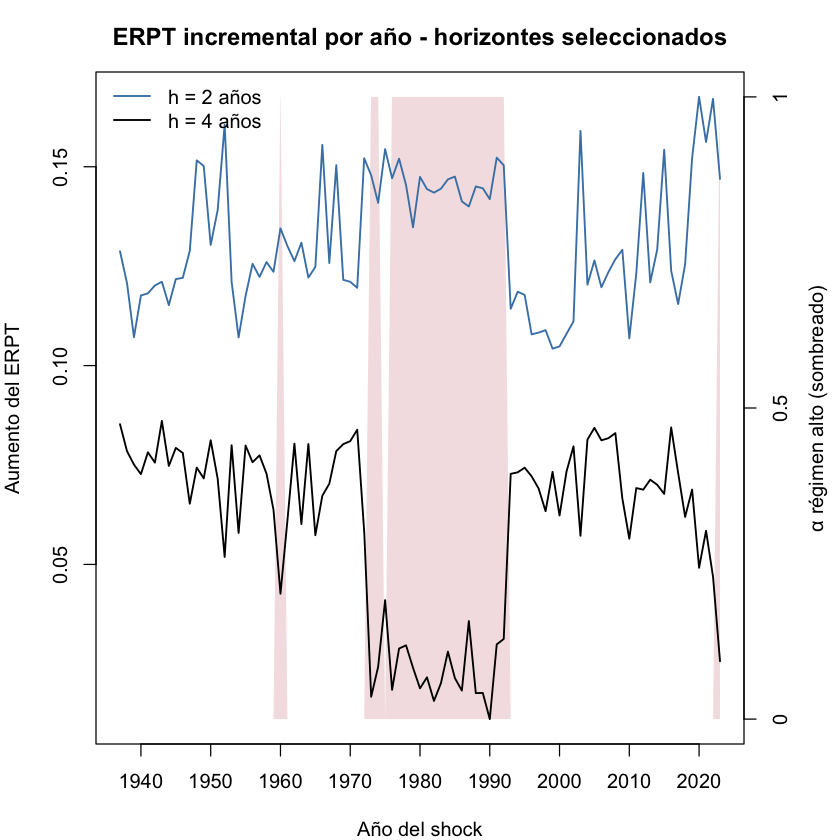

In [43]:
inc_impp_usa_tvar_p1_acum <- erpt_incremental(out_impp_usa_tvar_p1_acum)
graficar_erpt(graficos_con_mediana(inc_impp_usa_tvar_p1_acum),
              archivo = paste0(carpeta, "erpt_impp_usa_tvar_p1_acum_incremental_anual_ferr"),
              titulo = "ERPT incremental por año", eje_z = "Aumento del ERPT")

HTML widgets cannot be represented in plain text (need html)

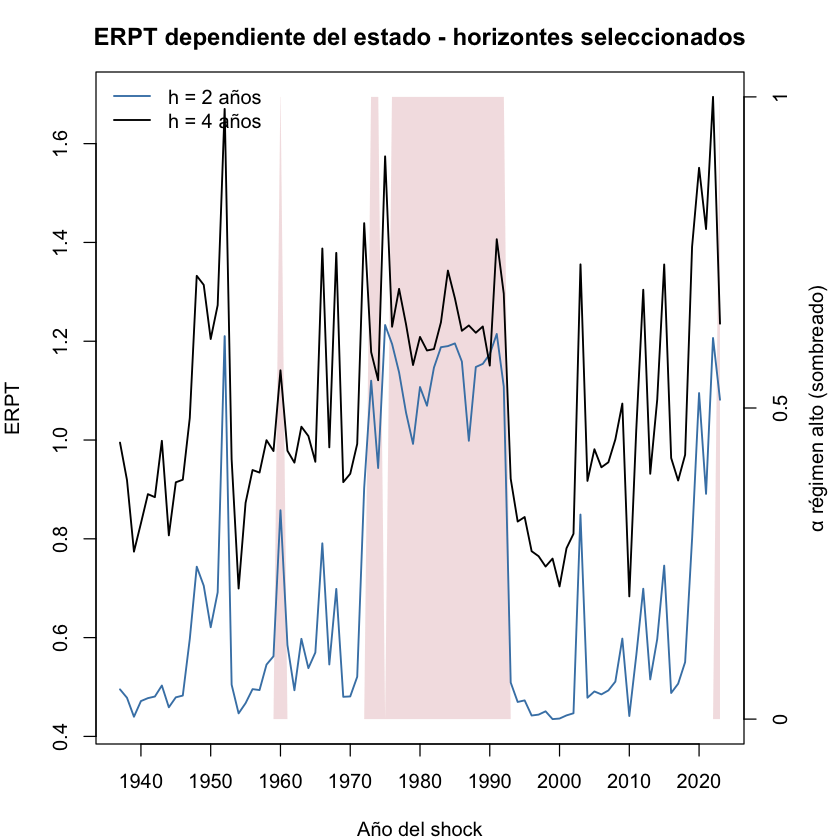

In [44]:
graficar_erpt(g_p1, archivo = paste0(carpeta, "erpt_impp_usa_tvar_p1_anual_ferr"))

In [45]:
graficar_slider(g_p1, archivo = paste0(carpeta, "slider_impp_usa_tvar_p1_anual_ferr"))

HTML widgets cannot be represented in plain text (need html)

 horizonte   1975   2014
         0 0.0883 0.0883
         1 0.8045 0.3456
         2 1.2328 0.5968
         3 1.4716 0.8633
         4 1.5742 1.0813


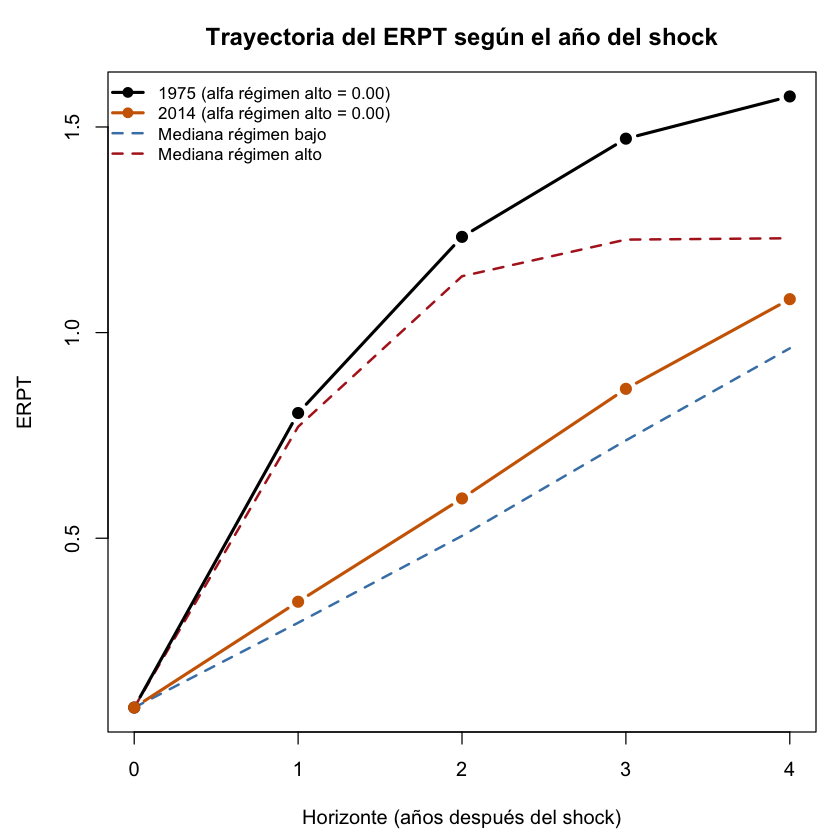

In [46]:
graficar_trayectorias(g_p1,
                      trimestres = c(1975, 2014),
                      archivo = paste0(carpeta, "trayectorias_impp_usa_tvar_p1_1975_2014_anual_ferr"))

 horizonte   1995   1985   2021
         0 0.0883 0.0883 0.0883
         1 0.2822 0.8408 0.5177
         2 0.4729 1.1956 0.8911
         3 0.6557 1.3015 1.1780
         4 0.8441 1.2871 1.4271


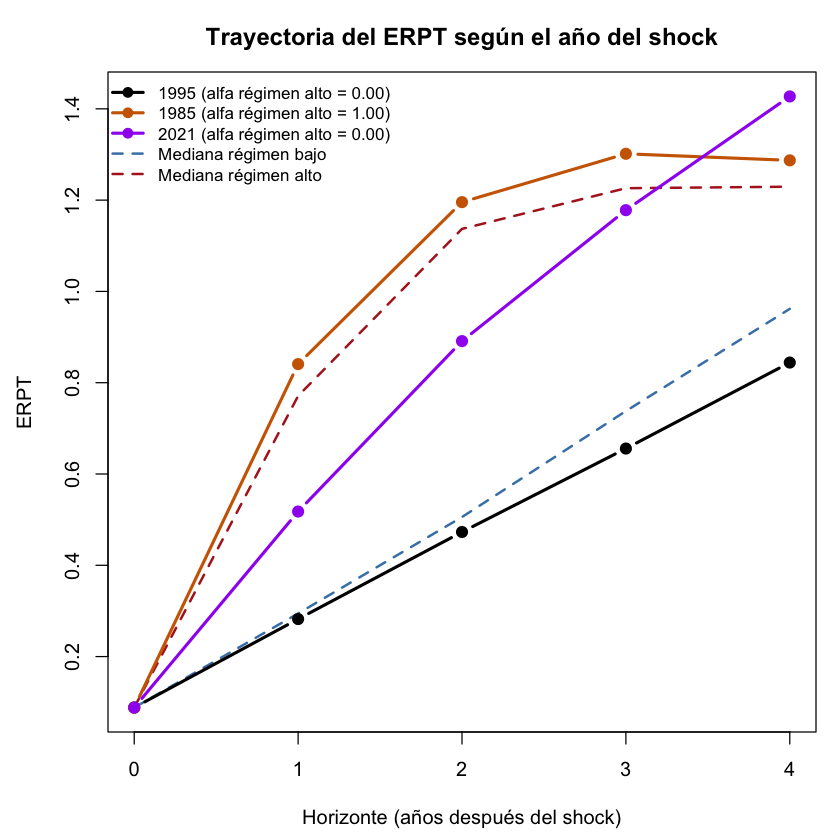

In [47]:
graficar_trayectorias(g_p1,
                      trimestres = c(1995, 1985, 2021),
                      archivo = paste0(carpeta, "trayectorias_impp_usa_tvar_p1_1995_1985_2021_anual_ferr"))

In [48]:
guardar_gif(g_p1, archivo = paste0(carpeta, "gif_impp_usa_tvar_p1_anual_ferr"))

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/GRAFICOS_TVAR_VLSTAR_Anuales/gif_impp_usa_tvar_p1_anual_ferr.gif



Umbrales (inflación anual de t-1): 55.8% anual 
Años por régimen: régimen 1 = 66 | régimen 2 = 21 


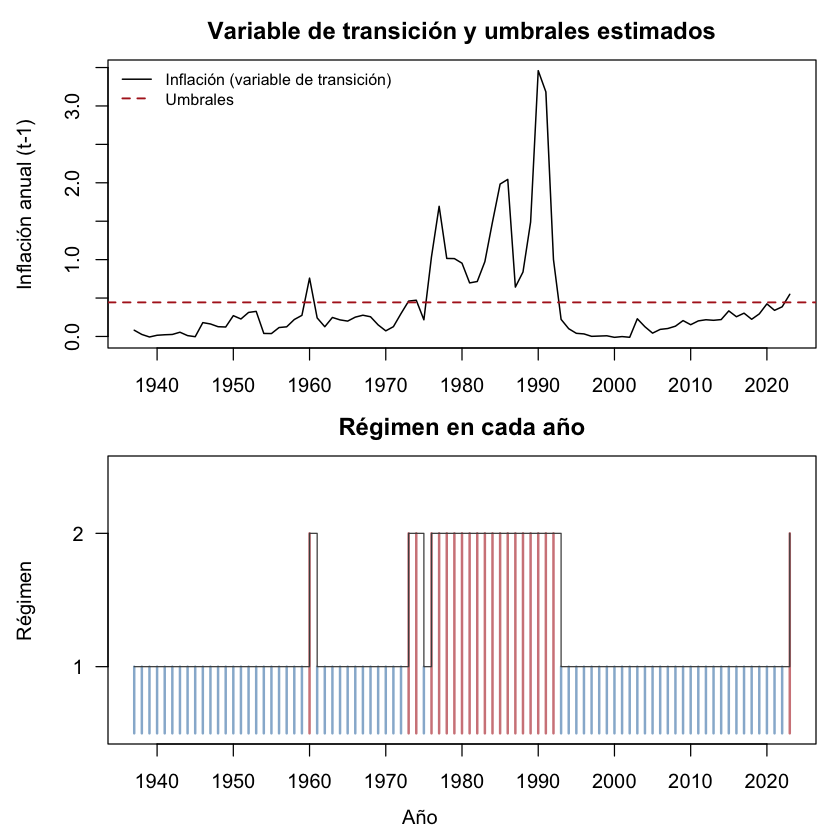

In [49]:
graficar_transicion(res, data = df_anual_ferr,
                    endog = c("impp_usa", "E", "ipc", "PBIpm"),
                    archivo = paste0(carpeta, "transicion_impp_usa_tvar_p1_anual_ferr"))

In [50]:
pers_p1 <- out_impp_usa_tvar_p1$erpt / out_impp_usa_tvar_p1_acum$erpt
bajo_p1 <- .normalizar_out(out_impp_usa_tvar_p1)$regimen == 1
round(apply(pers_p1[, bajo_p1], 1, median), 2)   # mediana del régimen bajo, h = 0 a 4

0    1    2    3    4 
1.00 1.18 1.37 1.55 1.73

## TVAR p = 2 (robustez)

Desvíos usados para escalar:
  impp_usa          E        ipc      PBIpm 
0.07653640 0.63532513 0.62520664 0.05122031 


Using 6 cores for 500 estimations rounds...

PHASE 1: Estimating all the parameters with a genetic algorithm...

Results from the genetic algorithm:

The lowest loglik:  -361.926

The largest loglik: -250.568

PHASE 2: Estimating all the parameters with a variable metric algorithm...

Results from the variable metric algorithm:

The lowest loglik:  -317.921

The largest loglik: -192.529

Filtering inappropriate estimates...

Filtered through 0 inappropriate  estimates with a larger log-likelihood

Calculating approximate standard errors...

Finished!




========= Unstructured fitted model ==========


Calculating approximate standard errors...



========= Structured fitted model (heteroskedasticity) ==========
Saving trained models to models/ folder

 >>> TESTS
PARA CORRER LOS TESTS CORRER LA SIGUIENTE FUNCION:
run_tests_sstvar(res, c(' ipc '), TRUE , 4 , 1 , 500 )

 >>> DIAGNOSTIC PLOTS


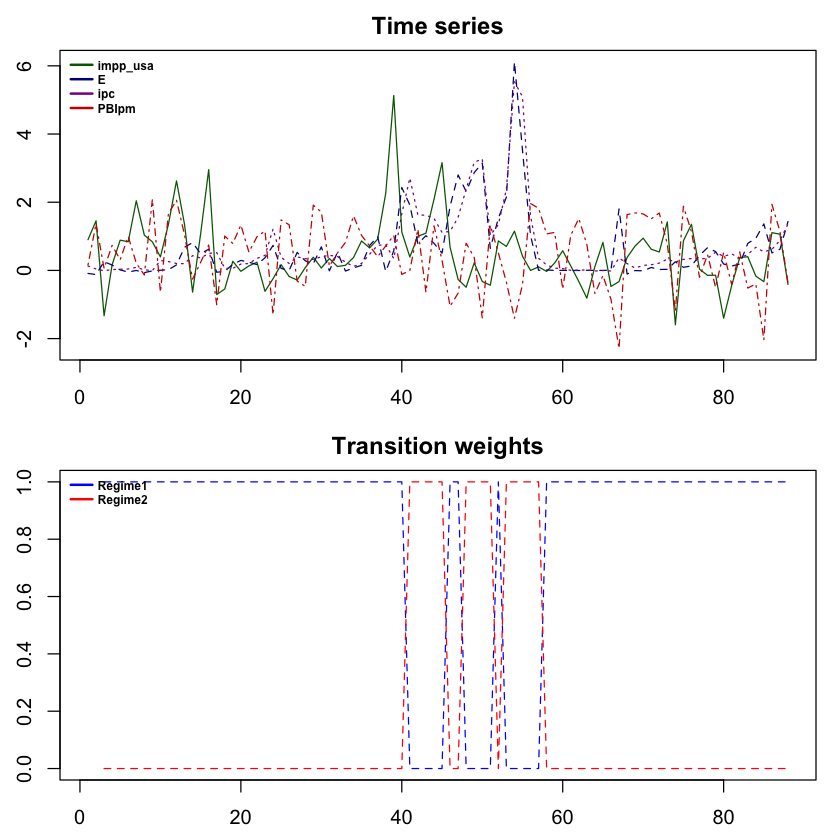

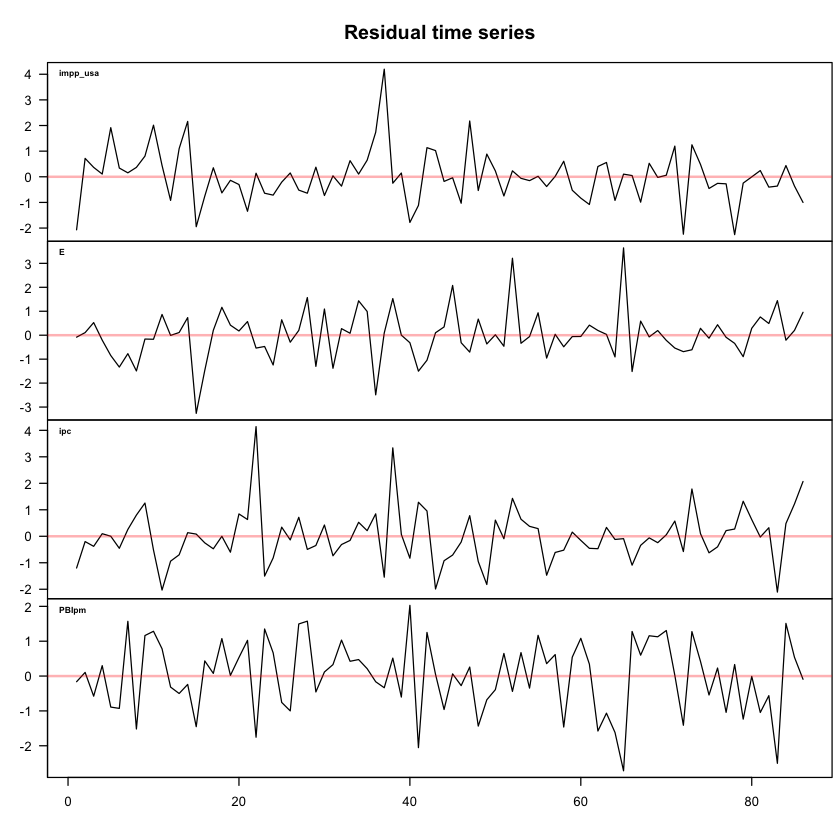

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



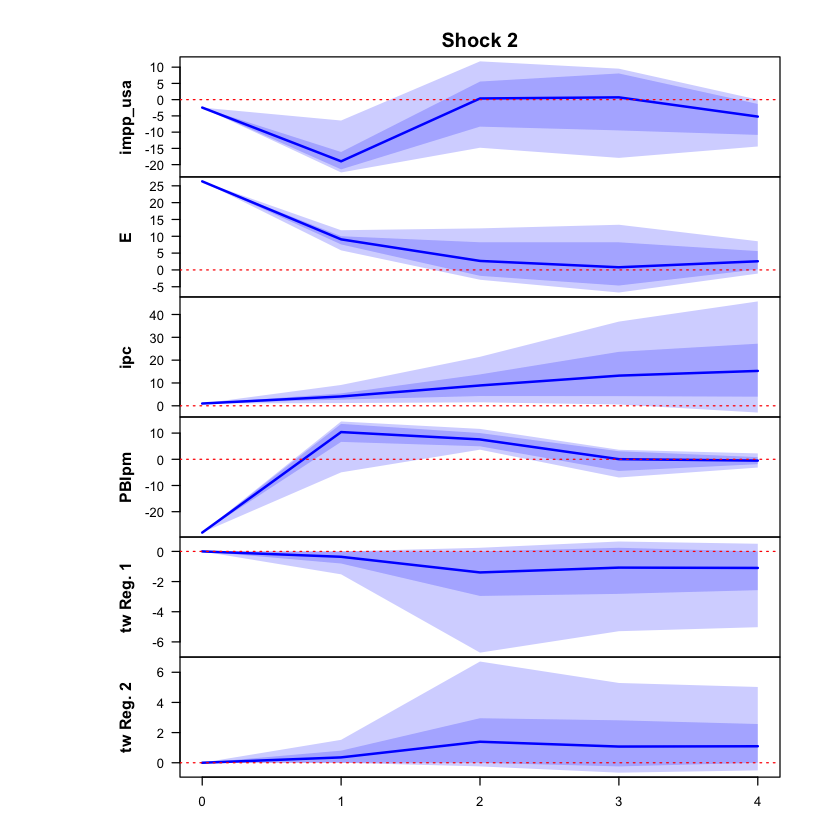

 >>> Linear IRF ( 1  shock units)


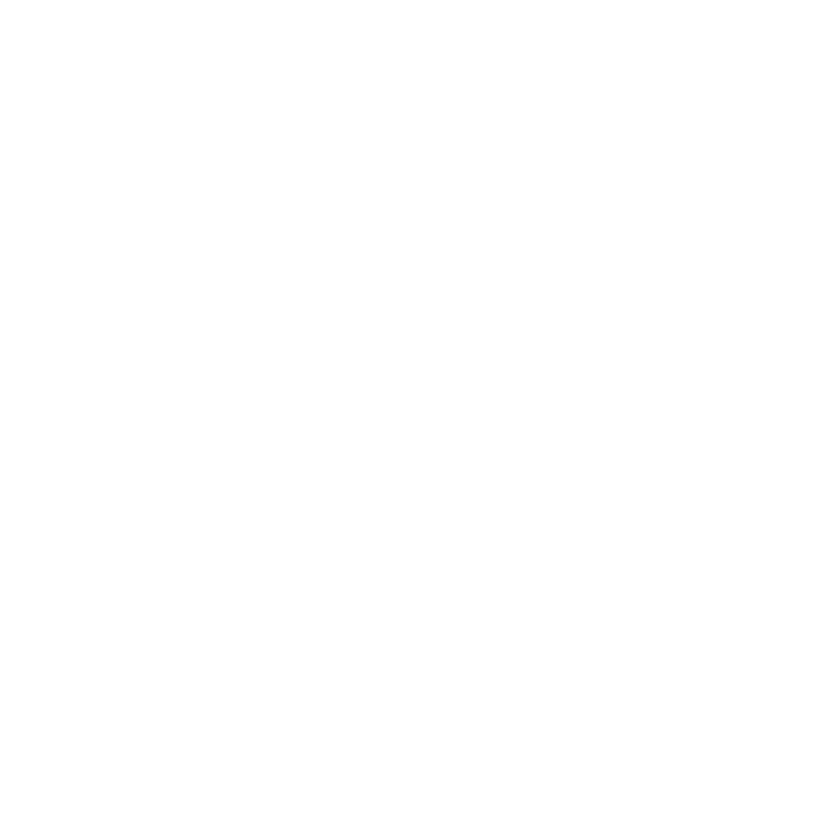

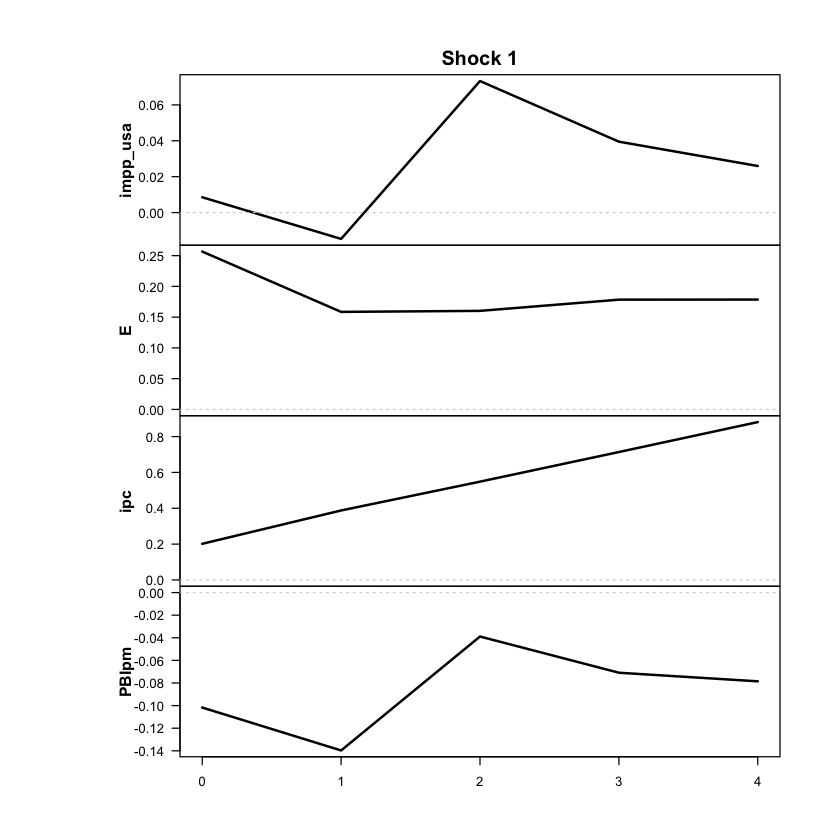

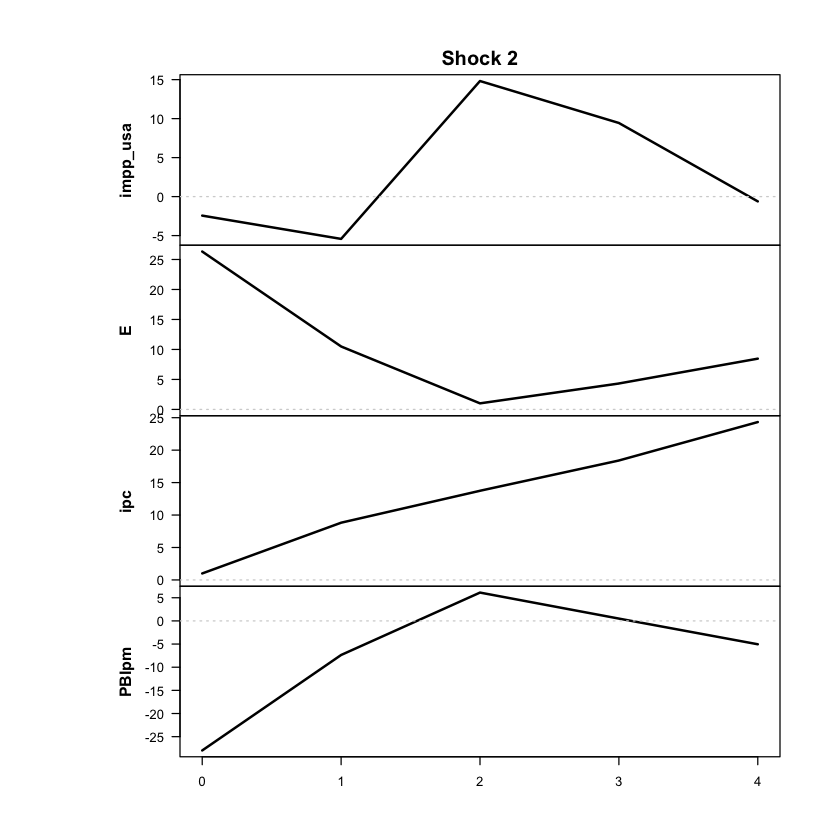

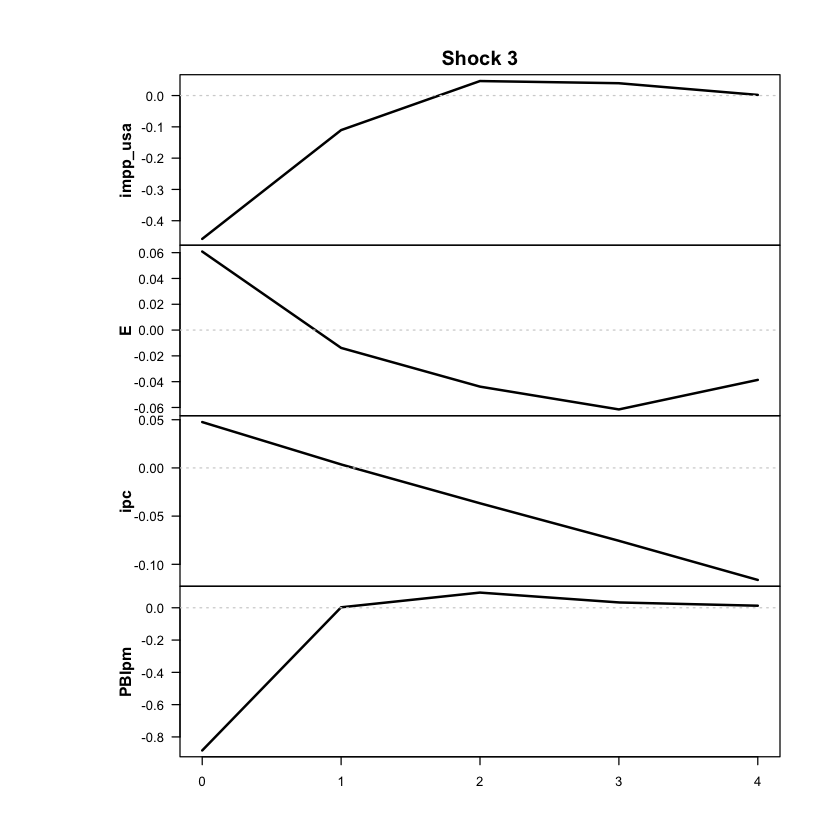

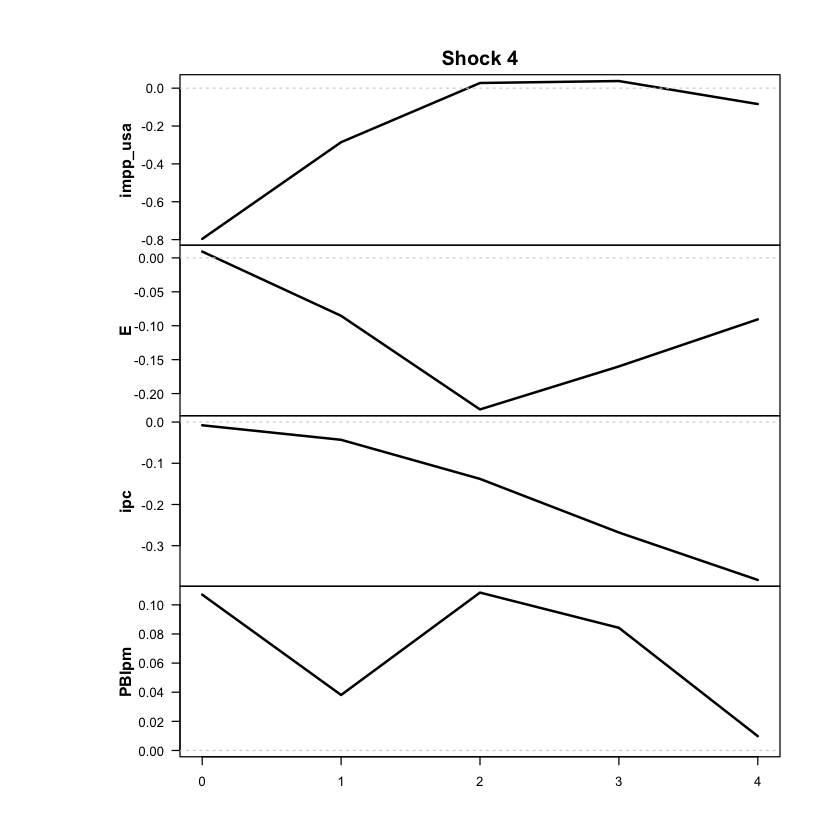

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



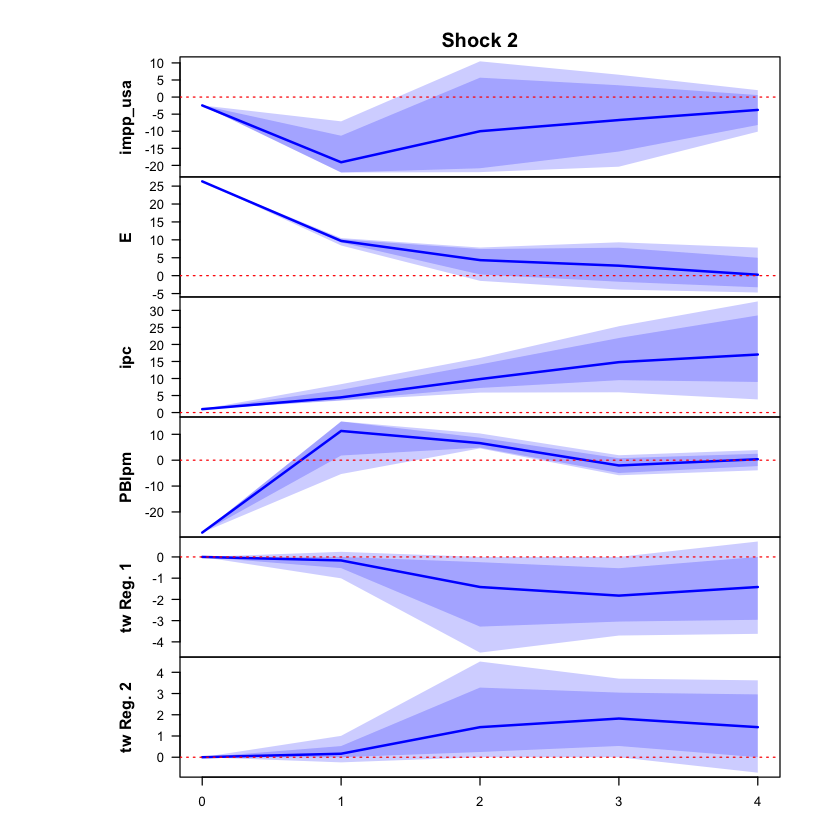

 >>> Linear IRF ( 1  shock units)


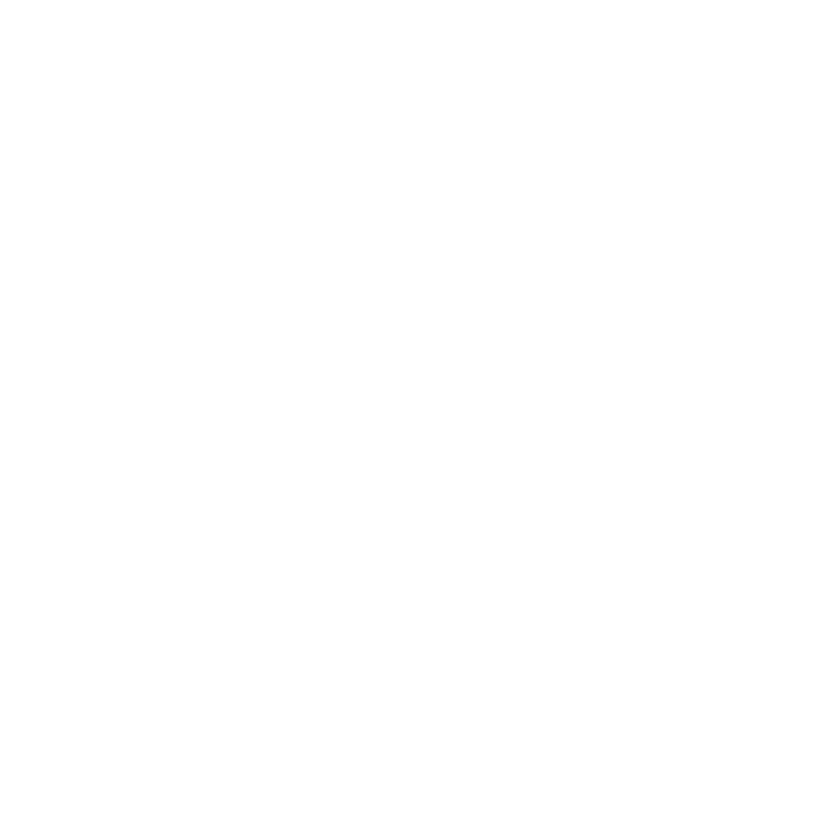

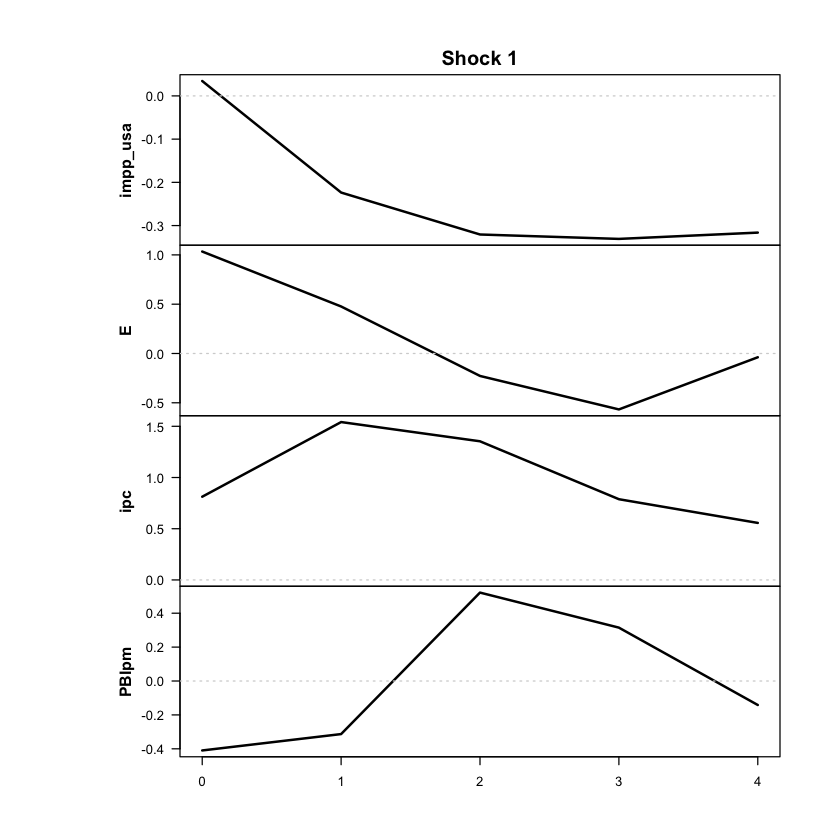

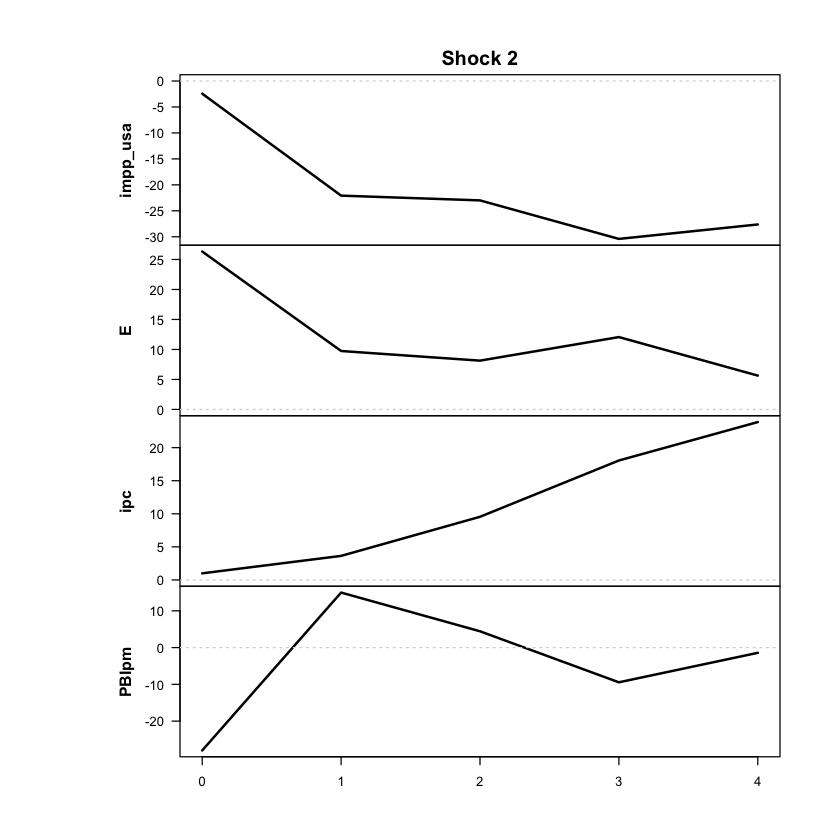

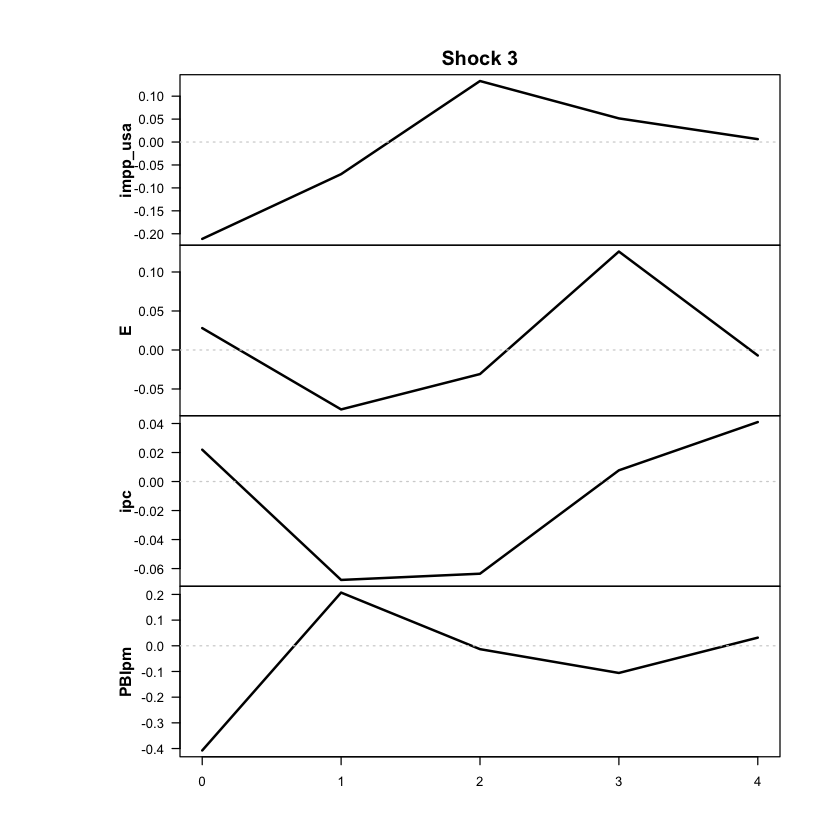

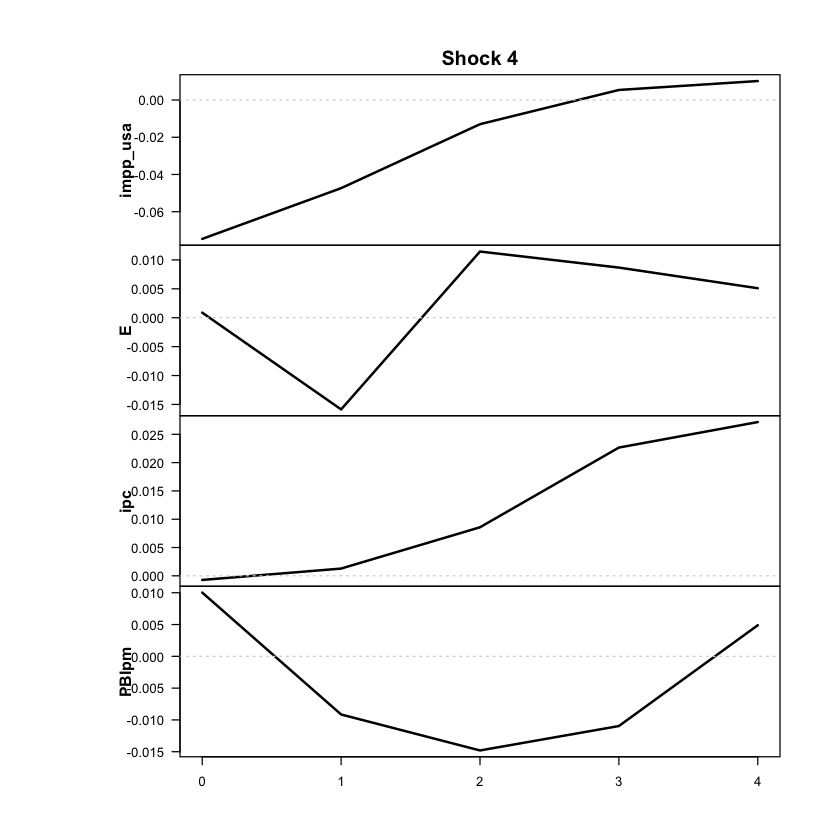

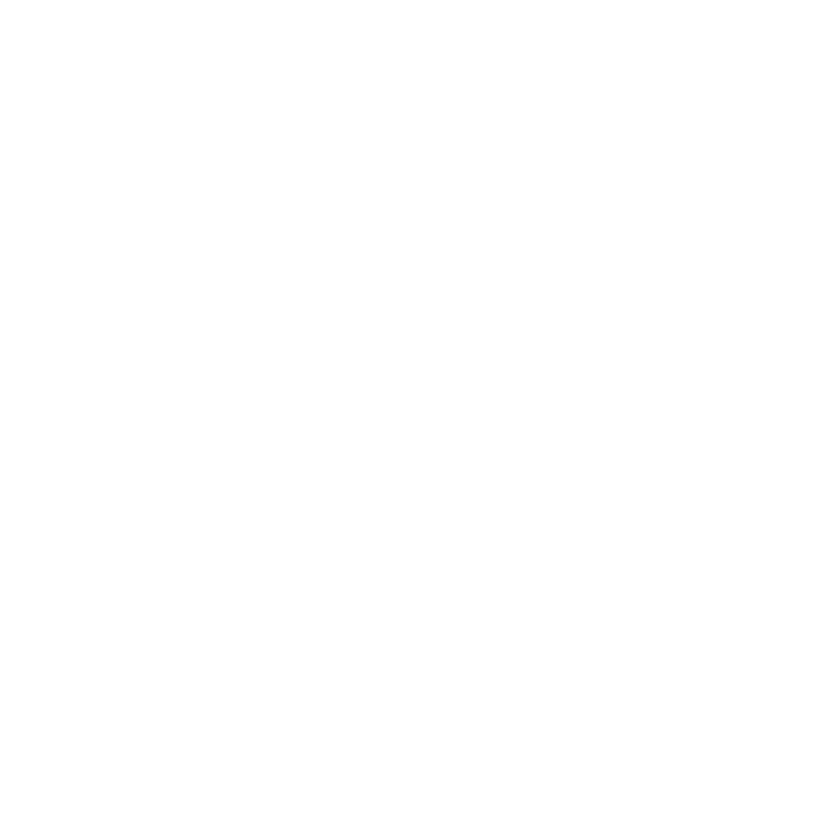

In [51]:
res <- run_threshold_tvar(
  data = df_anual_ferr,
  endog = c("impp_usa","E","ipc","PBIpm"),
  periodicity = 'anual', # 'trimestral' o 'anual' o mensual
  feature_lag = 2,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","PBIpm")
  run_tests = TRUE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = 4, # 4 años, igual que las LP anuales (en anual, NULL serían solo 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE   # primera corrida: estimar. Después de guardado, cambiar a TRUE
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [52]:
c(tipo = res$tvar_model$model$weight_function, p = res$tvar_model$model$p,
  errores = res$tvar_model$model$cond_dist)

tipo           p     errores 
"threshold"         "2"  "Gaussian"

In [53]:
ic_tvar_p2 <- criterios_info(res, "TVAR p=2")
print(ic_tvar_p2)
  saveRDS(ic_tvar_p2, "ic_tvar_p2_anual_ferr.rds")

    modelo regimenes parametros  loglik   AIC    HQ   BIC
1 TVAR p=2         2         93 -192.53 571.1 662.9 799.3


In [54]:
resumen_modelo(res, data = df_anual_ferr, endog = c("impp_usa", "E", "ipc", "PBIpm"))

Modelo: threshold | regímenes: 2 | rezagos: 2 | errores: Gaussian 
Umbrales: 122.1% anual 
Años por régimen (régimen de mayor peso): régimen 1 = 72 | régimen 2 = 14 

Promedio observado de cada variable en los años de cada régimen
(variación anual en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      3.31      5.09
E            28.64    237.81
ipc          26.05    344.55
PBIpm         2.58      1.81


In [55]:
explorar_optimos(res, n = 20)

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -192.53           122.1    NA         NA            72/14
             2 -194.78           124.4    NA         NA            72/14
             3 -205.35           128.3    NA         NA            72/14
             4 -208.04           126.3    NA         NA            72/14
             5 -209.82           101.6    NA         NA            70/16
             6 -209.85           107.9    NA         NA            71/15
             7 -210.06           118.8    NA         NA            72/14
             8 -211.81            95.2    NA         NA            69/17
             9 -212

In [56]:
identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "PBIpm"))
# Debe sugerir el shock 2 (= posición de E). Si sugiere otro, avisar antes de seguir.

Efecto de impacto de cada shock  (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0007 -0.0022 -0.0351 -0.0609
  E         0.1631  0.1977  0.0387  0.0060
  ipc       0.1261  0.0074  0.0298 -0.0049
  PBIpm    -0.0052 -0.0169 -0.0453  0.0055

Participación de E en el efecto de cada shock  :
shock_1 shock_2 shock_3 shock_4 
   0.75    0.68    0.06    0.01 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  0.773   0.037   0.769  -0.816 

>>> Shock sugerido como cambiario: 1 (confirmalo: debe mover mucho a E y poco a ipc )


In [57]:
print_passthrough(res, endog = c("impp_usa","E","ipc","PBIpm"))

+++++++++ RÉGIMEN  1 +++++++++

>>> GIRF normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
0         0       0.0374
1         1       0.1534
2         2       0.3331
3         3       0.4940
4         4       0.5713

>>> IRF lineal normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
1         0       0.0374
2         1       0.3297
3         2       0.5136
4         3       0.6880
5         4       0.9094

+++++++++ RÉGIMEN  2 +++++++++

>>> GIRF normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
0         0       0.0374
1         1       0.1669
2         2       0.3674
3         3       0.5533
4         4       0.6374

>>> IRF lineal normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
1         0       0.0374
2         1       0.1359
3         2       0.3570
4         3       0.6751
5         4       0.8923



### ERPT y gráficos — TVAR p = 2

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 21.9%.

GIRF del régimen 1...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!

GIRF del régimen 2...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




+++ Régimen 1 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte    ipc   PBIpm
         0 0.0374 -0.0857
         1 0.1424 -0.0529
         2 0.3041 -0.0286
         3 0.4338 -0.0268
         4 0.4794 -0.0279

+++ Régimen 2 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte    ipc   PBIpm
         0 0.0374 -0.0857
         1 0.1645 -0.0504
         2 0.3644 -0.0301
         3 0.5567 -0.0370
         4 0.6459 -0.0364


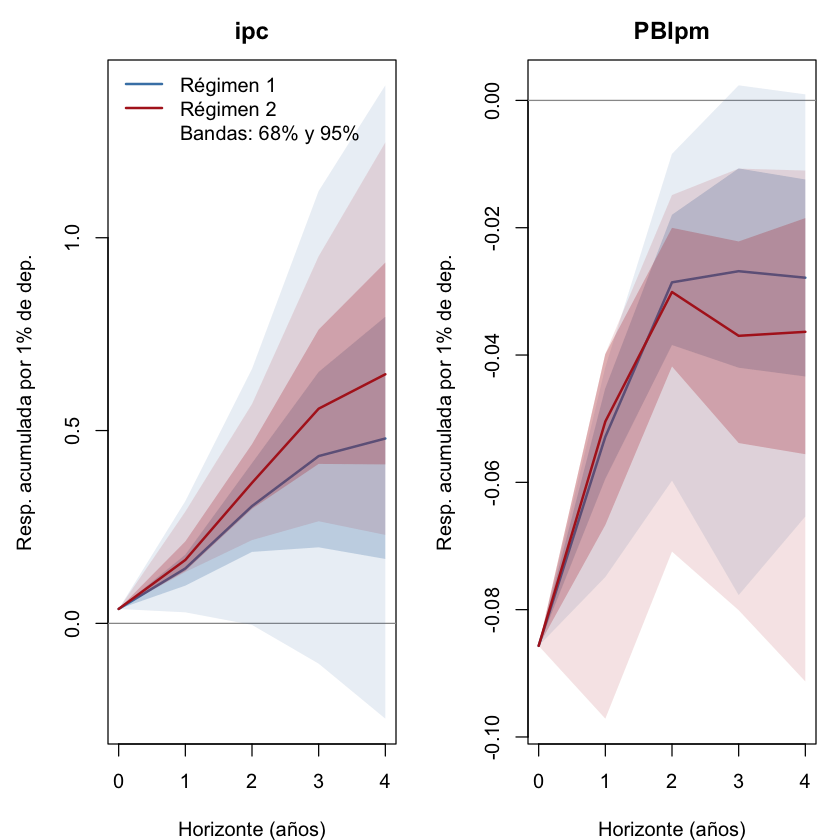


+++ Régimen 1 - IRF lineal acumulada por 1% de depreciación inicial (unidades originales) +++
 horizonte    ipc   PBIpm
         0 0.0374 -0.0857
         1 0.3297 -0.1082
         2 0.5136 -0.0895
         3 0.6880 -0.0880
         4 0.9094 -0.1034

+++ Régimen 2 - IRF lineal acumulada por 1% de depreciación inicial (unidades originales) +++
 horizonte    ipc   PBIpm
         0 0.0374 -0.0857
         1 0.1359 -0.0398
         2 0.3570 -0.0262
         3 0.6751 -0.0551
         4 0.8923 -0.0595


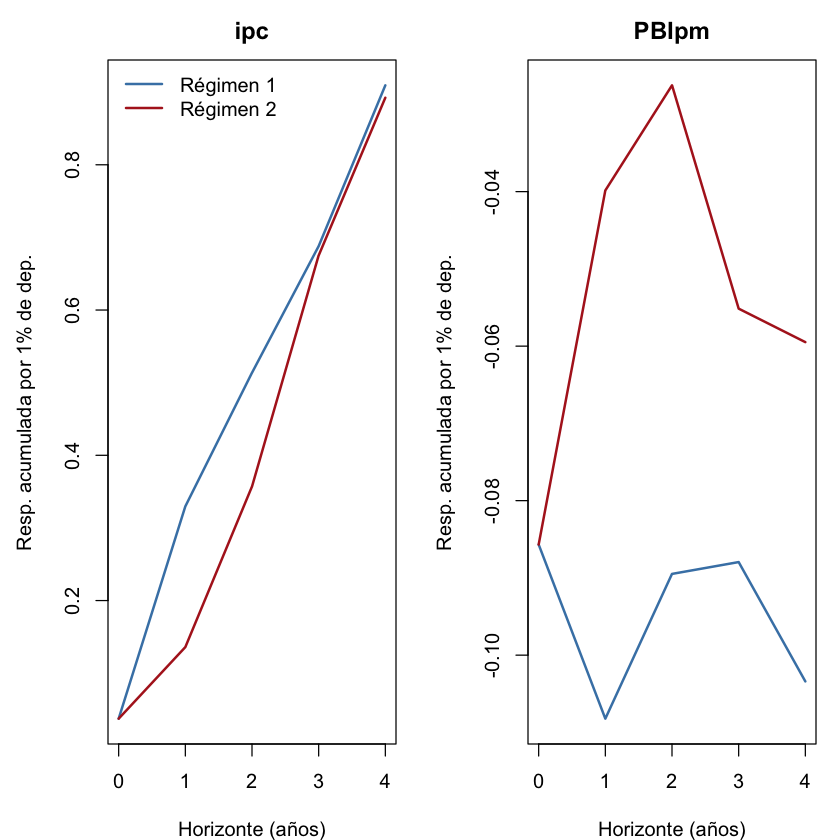

In [58]:
girf_impp_usa_tvar_p2 <- graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "PBIpm"),
                                        archivo = paste0(carpeta, "girf_original_impp_usa_tvar_p2_anual_ferr"))
irf_impp_usa_tvar_p2  <- graficar_irf_original(res, endog = c("impp_usa", "E", "ipc", "PBIpm"),
                                       archivo = paste0(carpeta, "irf_original_impp_usa_tvar_p2_anual_ferr"))

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 21.9%.

GIRF del régimen 1...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!

GIRF del régimen 2...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




+++ Régimen 1 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte      E    ipc   PBIpm
         0 1.0000 0.0374 -0.0857
         1 1.3336 0.1424 -0.0529
         2 1.4097 0.3041 -0.0286
         3 1.3976 0.4338 -0.0268
         4 1.4747 0.4794 -0.0279

+++ Régimen 2 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte      E    ipc   PBIpm
         0 1.0000 0.0374 -0.0857
         1 1.3676 0.1645 -0.0504
         2 1.5336 0.3644 -0.0301
         3 1.6518 0.5567 -0.0370
         4 1.6644 0.6459 -0.0364


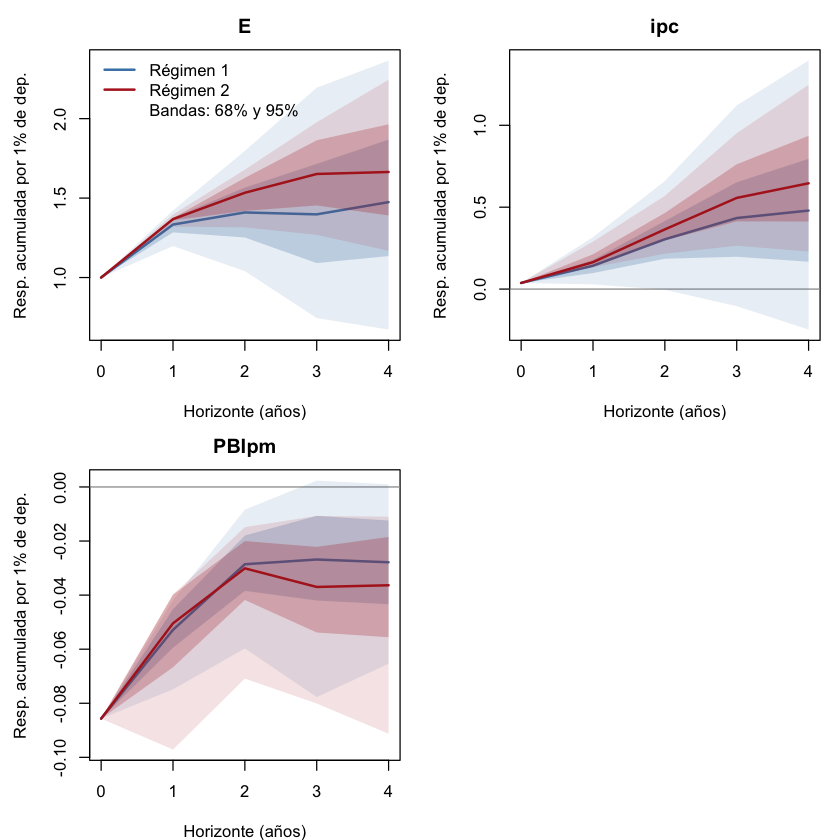

In [59]:
graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "PBIpm"),
                       variables = c("E", "ipc", "PBIpm"),
                       archivo = paste0(carpeta, "girf_original_impp_usa_tvar_p2_con_E_anual_ferr"))

In [60]:
out_impp_usa_tvar_p2 <- erpt_historia(res, data = df_anual_ferr,
                             endog = c("impp_usa", "E", "ipc", "PBIpm"))


Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 21.9%.

Estimando 86 GIRFs (una por año), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Años dominados por cada régimen (peso > 0.9): régimen 1 = 72 | régimen 2 = 14 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.9841

Promedio entre años:
  horizonte reg_bajo_original reg_alto_original
1         0            0.0374            0.0374
2         1            0.3273            0.1688
3         2            0.5420            0.3858
4         3            0.7835            0.6254
5         4            1.0616            0.7660

Mediana entre años (robusta a años con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0           0.0374           0.0374
2         1           0.3297           0.1481
3         2           0.5223           0.3646
4         3           0.7205           0.6401
5         4           0.9681           0.7639


In [61]:
c(tipo = res$tvar_model$model$weight_function, p = res$tvar_model$model$p,
  errores = res$tvar_model$model$cond_dist)

tipo           p     errores 
"threshold"         "2"  "Gaussian"

In [62]:
out_impp_usa_tvar_p2_acum <- erpt_historia(res, data = df_anual_ferr,
                                  endog = c("impp_usa", "E", "ipc", "PBIpm"),
                                  definicion = "acumulado")


Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 21.9%.

Estimando 86 GIRFs (una por año), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Años dominados por cada régimen (peso > 0.9): régimen 1 = 72 | régimen 2 = 14 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.9841

Promedio entre años:
  horizonte reg_bajo_original reg_alto_original
1         0            0.0374            0.0374
2         1            0.2339            0.1230
3         2            0.3657            0.2438
4         3            0.4571            0.3463
5         4            0.5131            0.4044

Mediana entre años (robusta a años con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0           0.0374           0.0374
2         1           0.2357           0.1074
3         2           0.3607           0.2267
4         3           0.4412           0.3288
5         4           0.4910           0.3919


In [63]:
saveRDS(out_impp_usa_tvar_p2,      "out_impp_usa_tvar_p2_anual_ferr.rds")
saveRDS(out_impp_usa_tvar_p2_acum, "out_impp_usa_tvar_p2_acum_anual_ferr.rds")

Gráficos con la MEDIANA por régimen como referencia.


HTML widgets cannot be represented in plain text (need html)

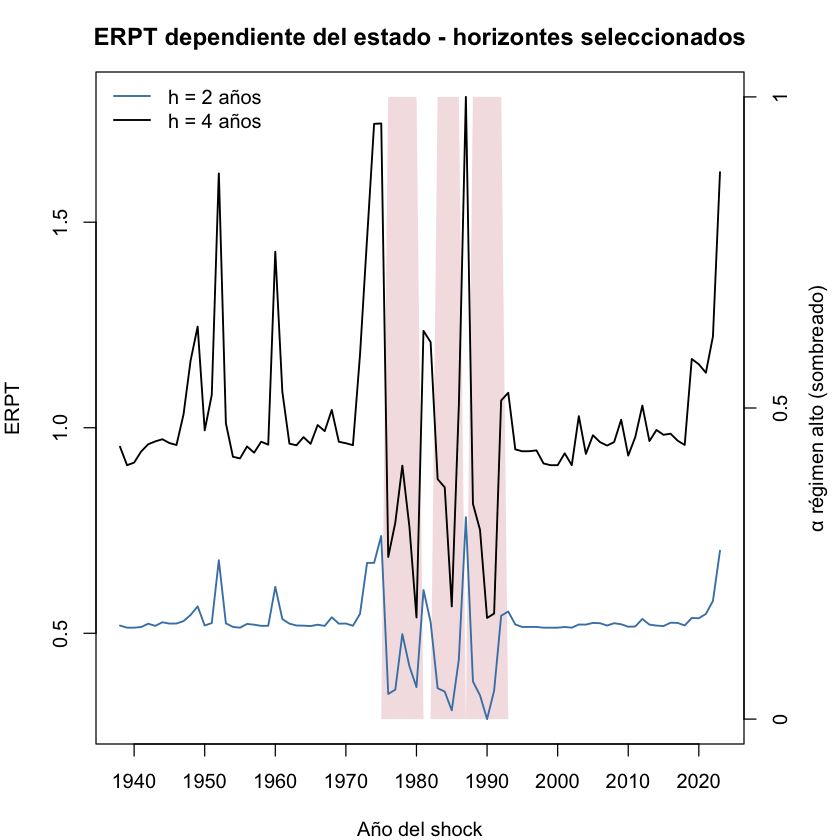

In [64]:
g_p2 <- graficos_con_mediana(out_impp_usa_tvar_p2)
graficar_erpt(g_p2, archivo = paste0(carpeta, "erpt_impp_usa_tvar_p2_anual_ferr"))

In [65]:
round(apply(out_impp_usa_tvar_p2$erpt[, .normalizar_out(out_impp_usa_tvar_p2)$regimen == 1], 1, median), 2)

0    1    2    3    4 
0.04 0.33 0.52 0.72 0.97

HTML widgets cannot be represented in plain text (need html)

 horizonte   1975   1989   2005
         0 0.0374 0.0374 0.0374
         1 0.3173 0.1397 0.3297
         2 0.7368 0.3491 0.5252
         3 1.3920 0.5926 0.7310
         4 1.7403 0.7516 0.9817


GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/GRAFICOS_TVAR_VLSTAR_Anuales/gif_impp_usa_tvar_p2_anual_ferr.gif



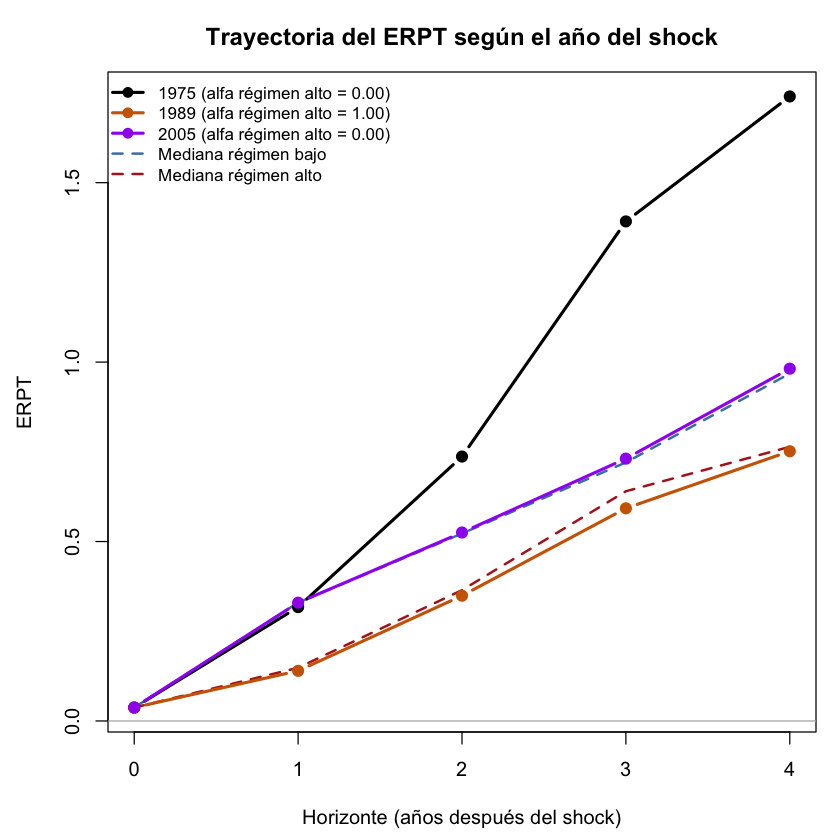

In [66]:
graficar_slider(g_p2, archivo = paste0(carpeta, "slider_impp_usa_tvar_p2_anual_ferr"))
graficar_trayectorias(g_p2, trimestres = c(1975, 1989, 2005),
                      archivo = paste0(carpeta, "trayectorias_impp_usa_tvar_p2_1975_1989_2005_anual_ferr"))
guardar_gif(g_p2, archivo = paste0(carpeta, "gif_impp_usa_tvar_p2_anual_ferr"))

HTML widgets cannot be represented in plain text (need html)

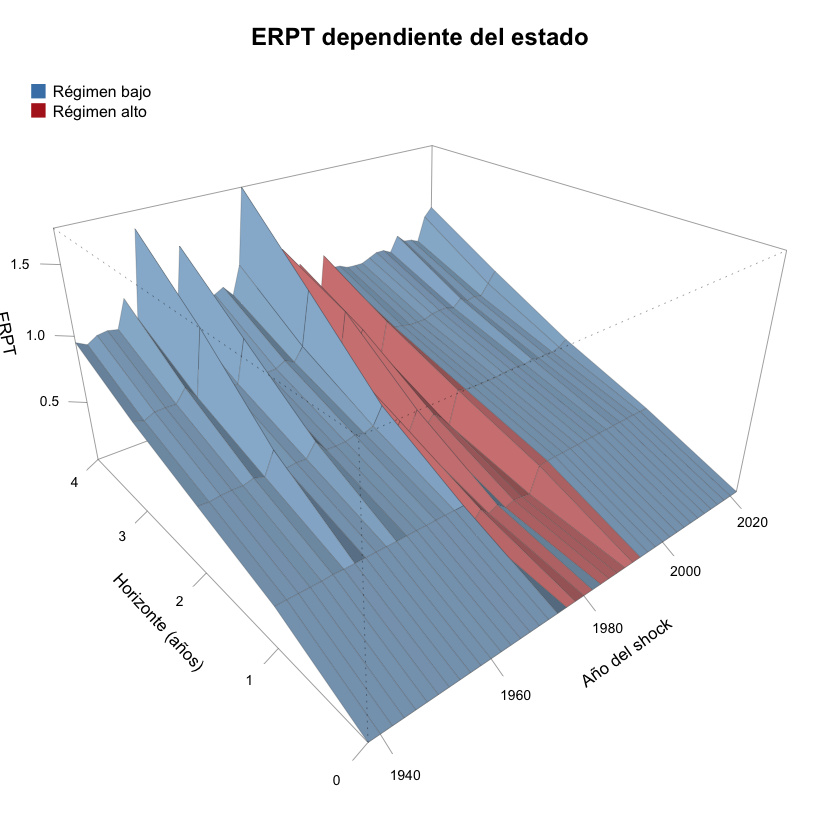

In [67]:
graficar_erpt_manta(g_p2, cada = 2, archivo = paste0(carpeta, "erpt_manta_impp_usa_tvar_p2_c2_anual_ferr"))

Mediana de ERPT (relativo al shock) por régimen (trimestres con peso > 0.9):
 horizonte reg_bajo_mediana reg_alto_mediana
         2            0.522            0.365
Mediana de ERPT (relativo al shock) por régimen (trimestres con peso > 0.9):
 horizonte reg_bajo_mediana reg_alto_mediana
         4            0.968            0.764


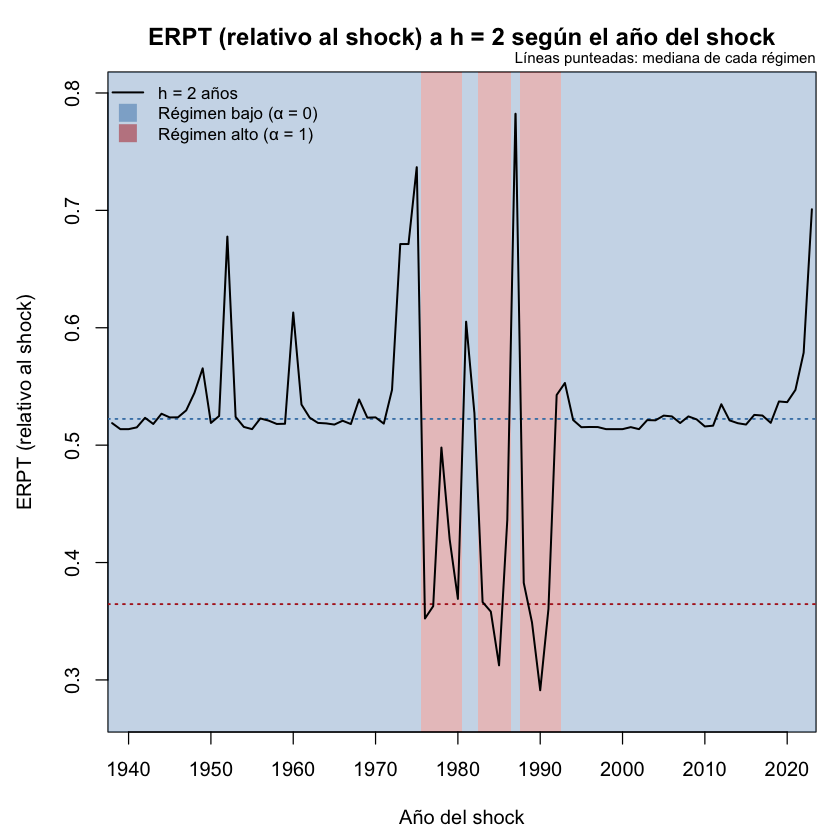

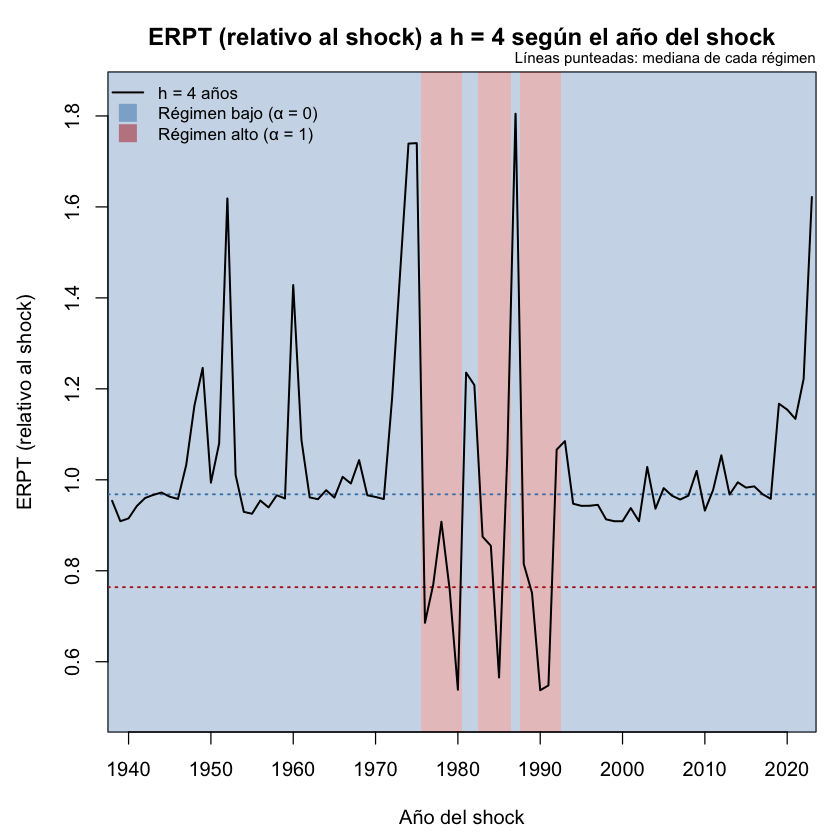

In [68]:
for (h in c(2, 4)) {
  graficar_erpt_2d_bandas(g_p2, horizontes = h, eje_y = "ERPT (relativo al shock)",
      archivo = paste0(carpeta, "erpt_2d_bandas_impp_usa_tvar_p2_h", h, "_anual_ferr"))
}

HTML widgets cannot be represented in plain text (need html)

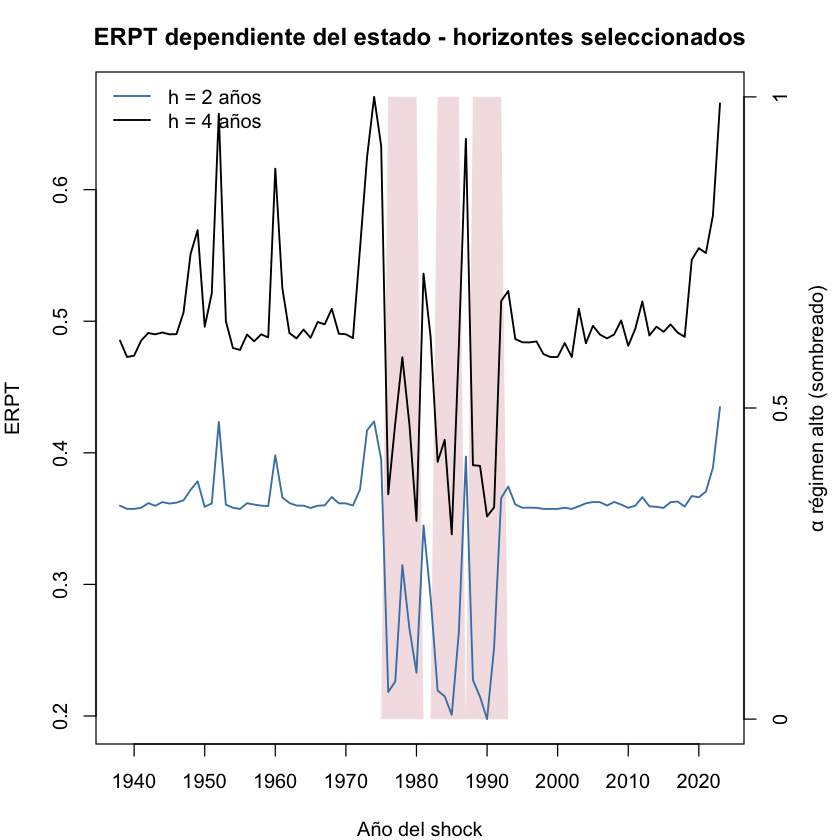

In [69]:
graficar_erpt(out_impp_usa_tvar_p2_acum, archivo = paste0(carpeta, "erpt_impp_usa_tvar_p2_acum_anual_ferr"))

  horizonte reg_bajo_original reg_alto_original
1         0            0.0374            0.0374
2         1            0.2899            0.1314
3         2            0.2148            0.2170
4         3            0.2415            0.2396
5         4            0.2781            0.1406


HTML widgets cannot be represented in plain text (need html)

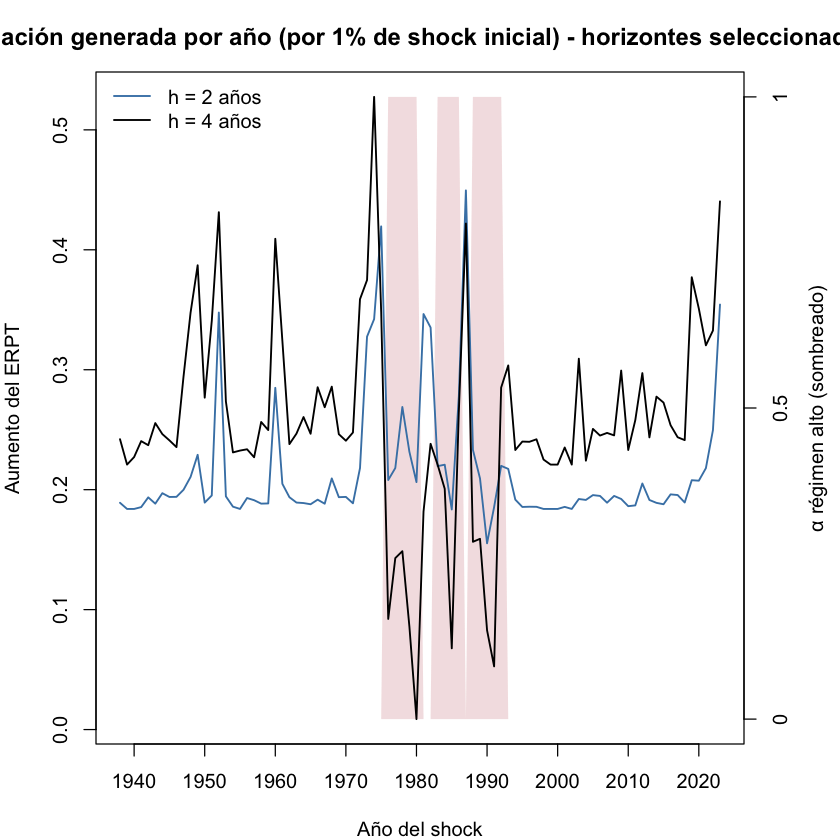

In [70]:
inc_impp_usa_tvar_p2 <- erpt_incremental(out_impp_usa_tvar_p2)
graficar_erpt(inc_impp_usa_tvar_p2, archivo = paste0(carpeta, "erpt_impp_usa_tvar_p2_incremental_anual_ferr"),
              titulo = "Inflación generada por año (por 1% de shock inicial)",
              eje_z = "Aumento del ERPT")


Umbrales (inflación anual de t-1): 122.1% anual 
Años por régimen: régimen 1 = 72 | régimen 2 = 14 


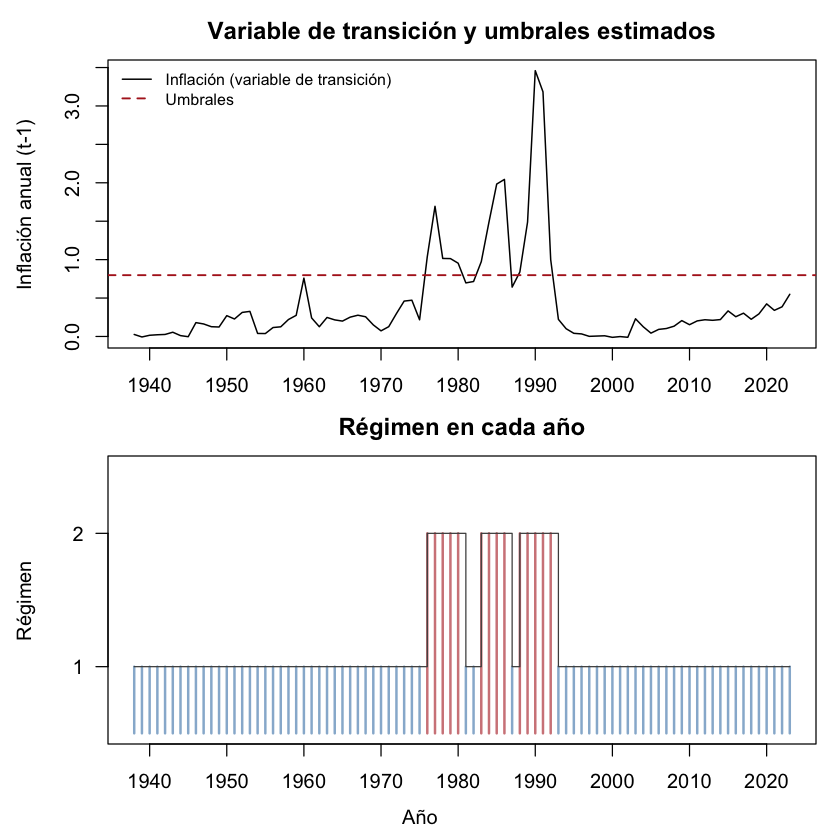

In [71]:
graficar_transicion(res, data = df_anual_ferr,
                    endog = c("impp_usa", "E", "ipc", "PBIpm"),
                    archivo = paste0(carpeta, "transicion_impp_usa_tvar_p2_anual_ferr"))


In [72]:
e <- out_impp_usa_tvar_p2_acum$erpt
o <- order(abs(e), decreasing = TRUE)[1:5]
data.frame(año = colnames(e)[col(e)[o]], horizonte = row(e)[o] - 1, erpt = round(e[o], 1))

año,horizonte,erpt
<chr>,<dbl>,<dbl>
1974,4,0.7
2023,4,0.7
1952,4,0.7
1987,4,0.6
1975,4,0.6


In [73]:
g_t_p2_acum <- acotar_para_graficar(out_impp_usa_tvar_p2_acum)
graficar_slider(g_t_p2_acum, archivo = paste0(carpeta, "slider_impp_usa_tvar_p2_acum_acotado_anual_ferr"))

No hay valores extremos para acotar (k = 5, umbral_abs = 1).


HTML widgets cannot be represented in plain text (need html)

In [74]:
round(out_impp_usa_tvar_p2_acum$erpt[1:2, c("1975", "1976", "1989")], 3)   # h = 0 y h = 1

,1975,1976,1989
0,0.037,0.037,0.037
1,0.232,0.105,0.102


In [75]:
o <- graficos_con_mediana(out_impp_usa_tvar_p2_acum)
bajo <- .normalizar_out(o)$regimen == 1
round(quantile(o$erpt["3", bajo], c(0.05, 0.25, 0.5, 0.75, 0.95)), 2)

Gráficos con la MEDIANA por régimen como referencia.


5%  25%  50%  75%  95% 
0.43 0.44 0.44 0.45 0.57

In [76]:
pers <- out_impp_usa_tvar_p2$erpt / out_impp_usa_tvar_p2_acum$erpt
bajo <- .normalizar_out(out_impp_usa_tvar_p2)$regimen == 1
round(apply(pers[, bajo], 1, median), 2)   # mediana del régimen bajo, h = 0 a 4

0    1    2    3    4 
1.00 1.40 1.45 1.63 1.98

## Comparación de criterios

In [77]:
rbind(ic_tvar_p1, ic_tvar_p2)

modelo,regimenes,parametros,loglik,AIC,HQ,BIC
<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
TVAR p=1,2,61,-239.53,601.1,661.6,751.5
TVAR p=2,2,93,-192.53,571.1,662.9,799.3


## Errores t de Student (2 regímenes)

Misma especificación, pero con errores t de Student (`cond_dist = "Student"`): colas más pesadas, que admiten trimestres extremos sin necesitar un régimen aparte. Objetivo: (1) ver si el VLSTAR encuentra una solución válida (sin covarianza casi singular) y (2) verificar que el ERPT del TVAR principal no cambia. Los modelos gaussianos ya guardados no se pisan: los archivos t llevan `student_` en el nombre.

`resumen_modelo` muestra los grados de libertad: valores bajos (≈ 3–6) indican colas muy pesadas; valores muy altos (> 30) indican que los errores son casi normales.

### TVAR con errores t, p = 1

Desvíos usados para escalar:
  impp_usa          E        ipc      PBIpm 
0.07653640 0.63532513 0.62520664 0.05122031 


Using 6 cores for 500 estimations rounds...

PHASE 1: Estimating all the parameters with a genetic algorithm...

Results from the genetic algorithm:

The lowest loglik:  -345.375

The largest loglik: -226.694

PHASE 2: Estimating all the parameters with a variable metric algorithm...

Results from the variable metric algorithm:

The lowest loglik:  -287.655

The largest loglik: -209.121

Filtering inappropriate estimates...

Filtered through 1 inappropriate  estimates with a larger log-likelihood

Calculating approximate standard errors...

Finished!




========= Unstructured fitted model ==========


Calculating approximate standard errors...



========= Structured fitted model (heteroskedasticity) ==========
Saving trained models to models/ folder

 >>> TESTS
PARA CORRER LOS TESTS CORRER LA SIGUIENTE FUNCION:
run_tests_sstvar(res, c(' ipc '), TRUE , 4 , 1 , 500 )

 >>> DIAGNOSTIC PLOTS


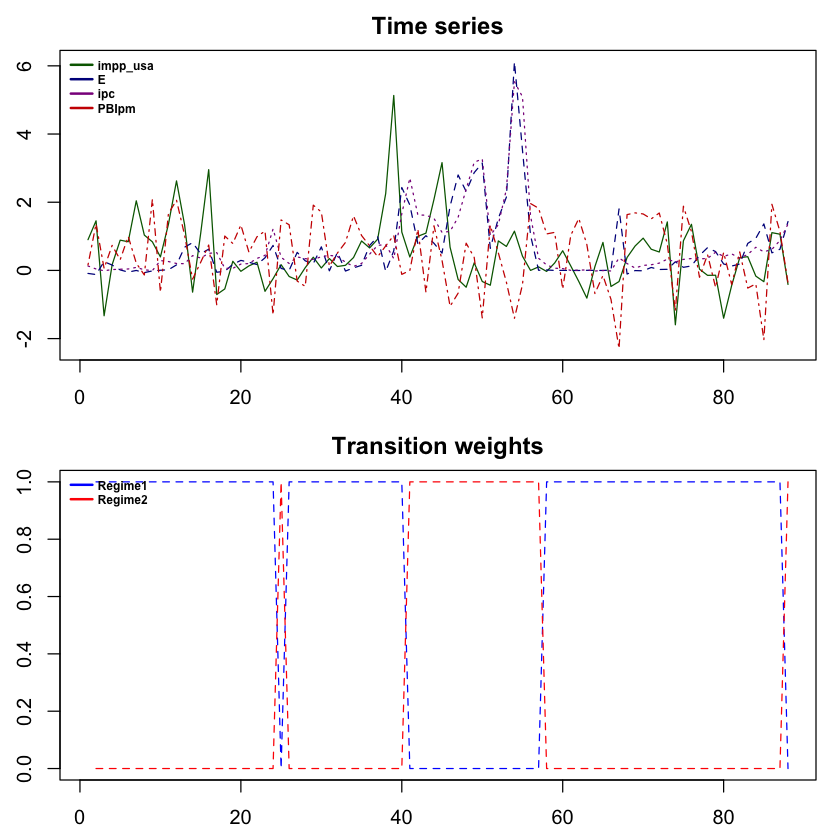

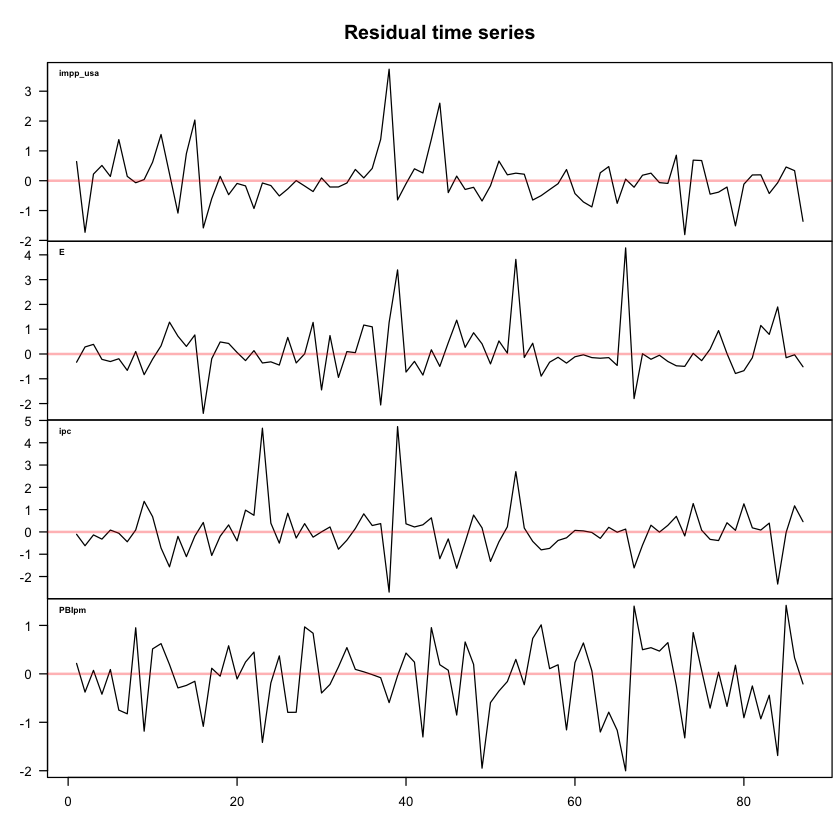

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



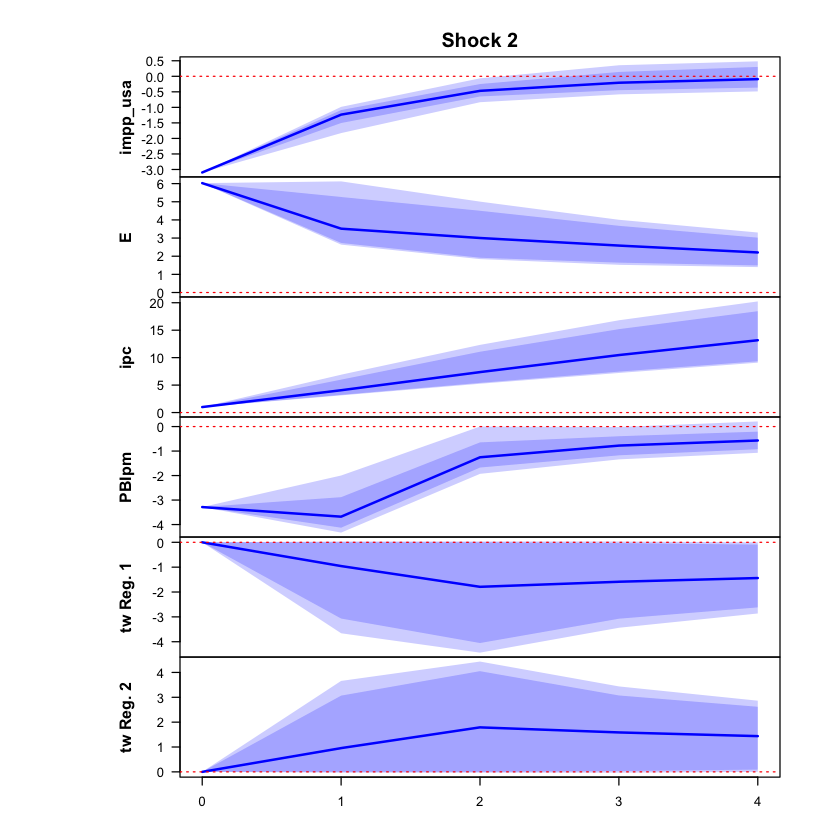

 >>> Linear IRF ( 1  shock units)


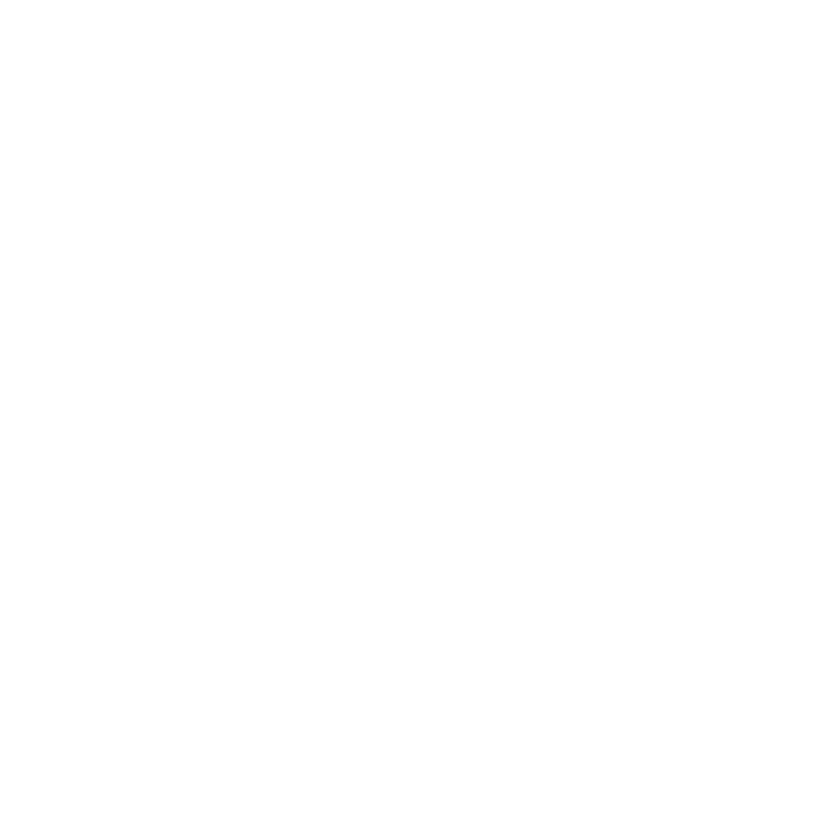

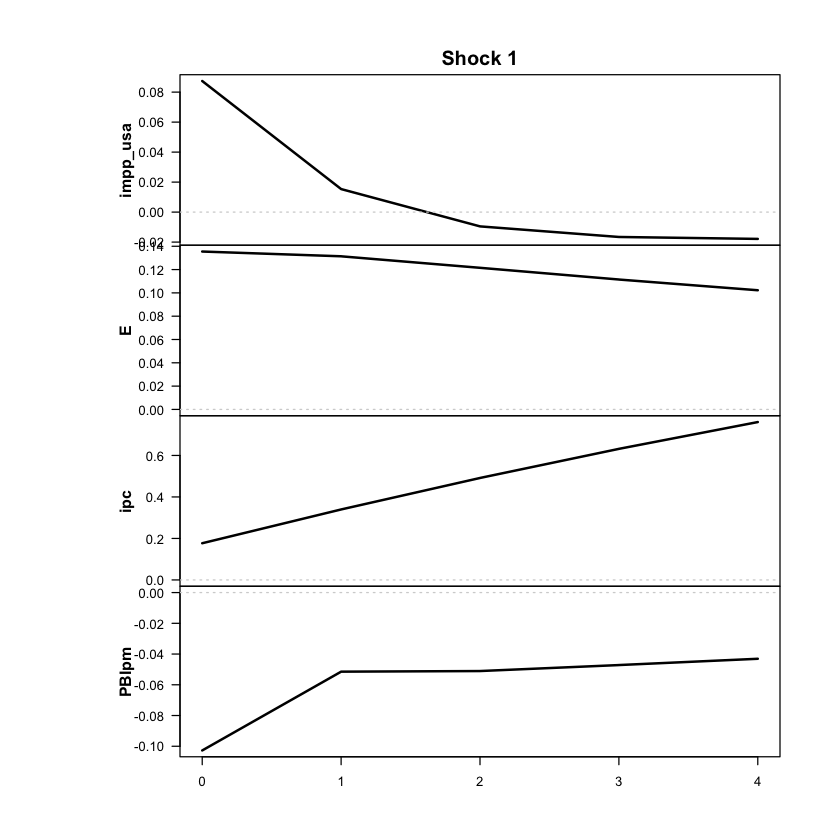

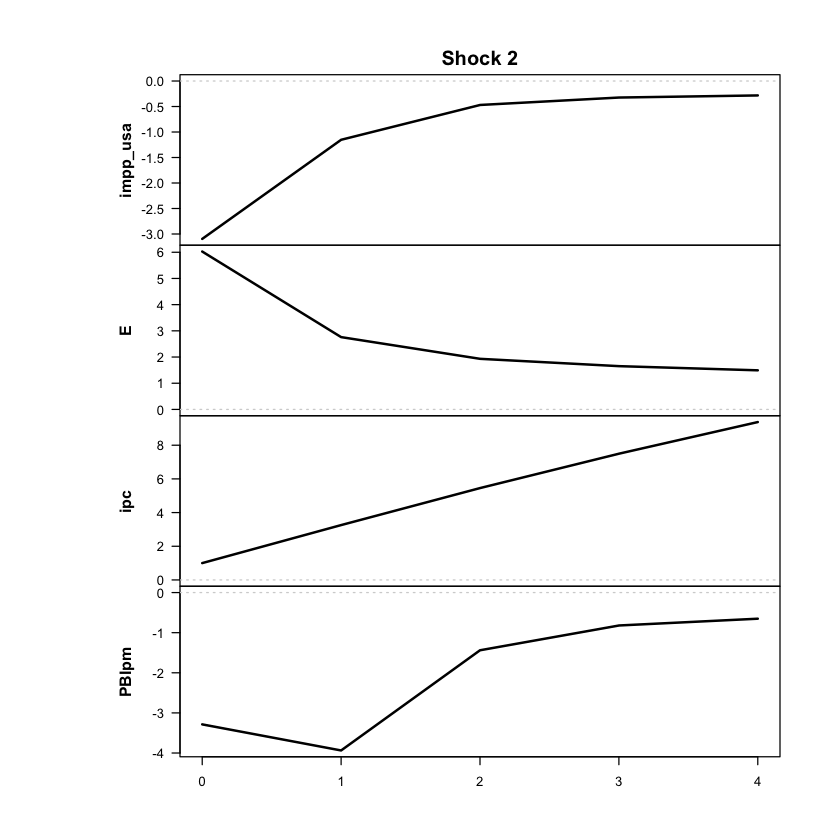

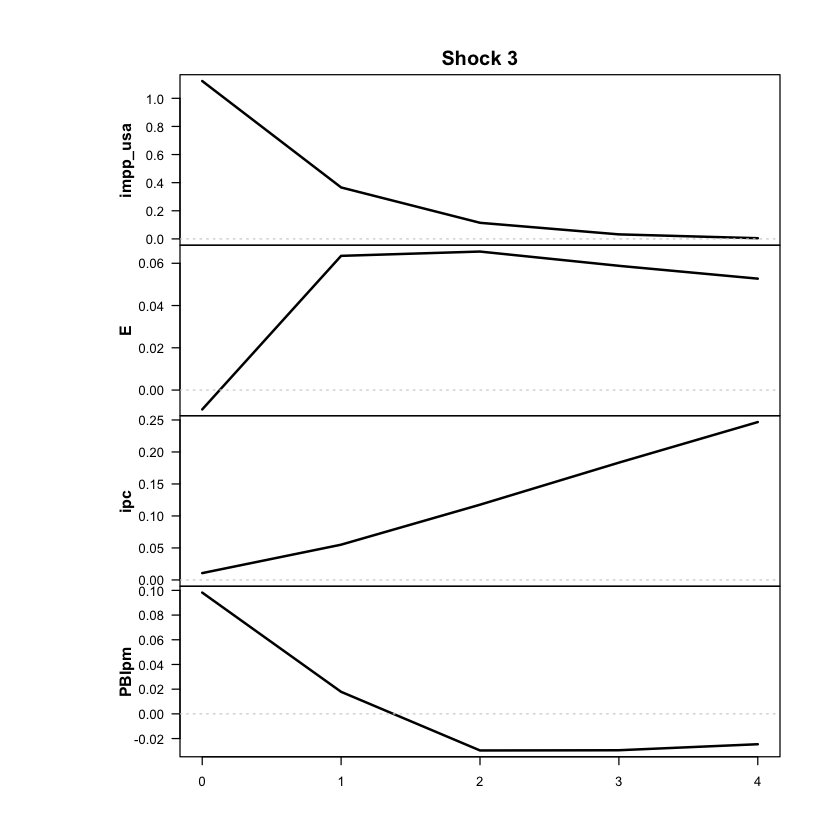

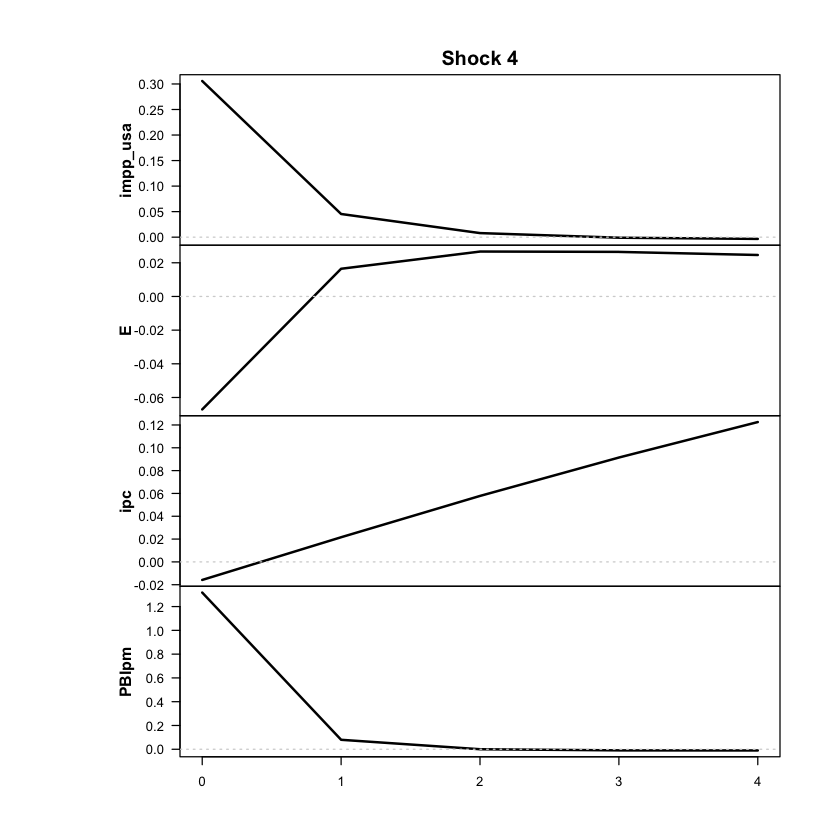

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



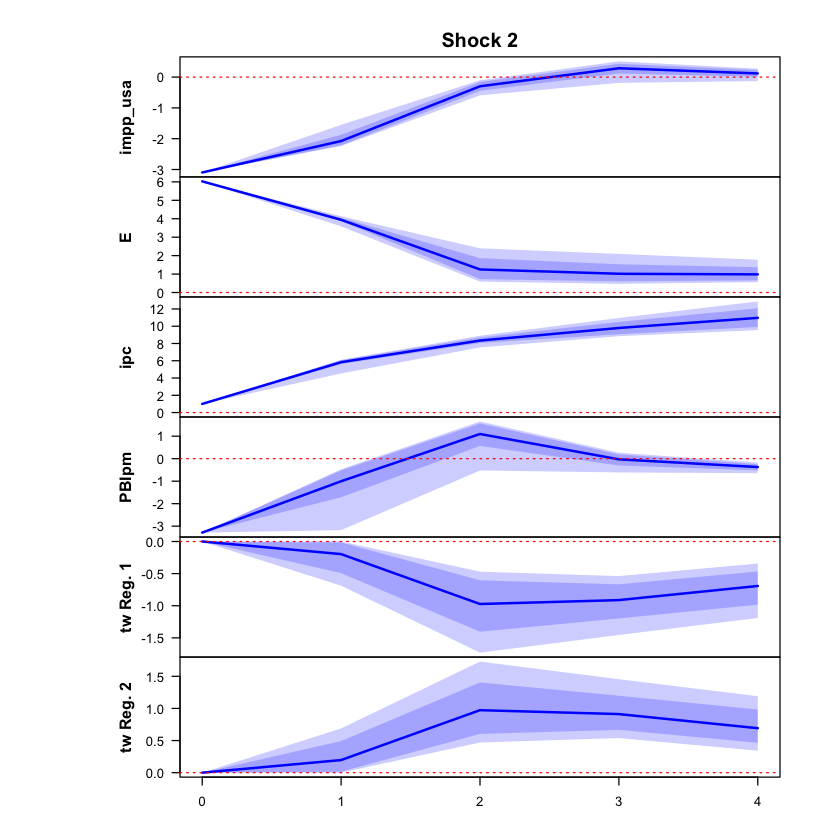

 >>> Linear IRF ( 1  shock units)


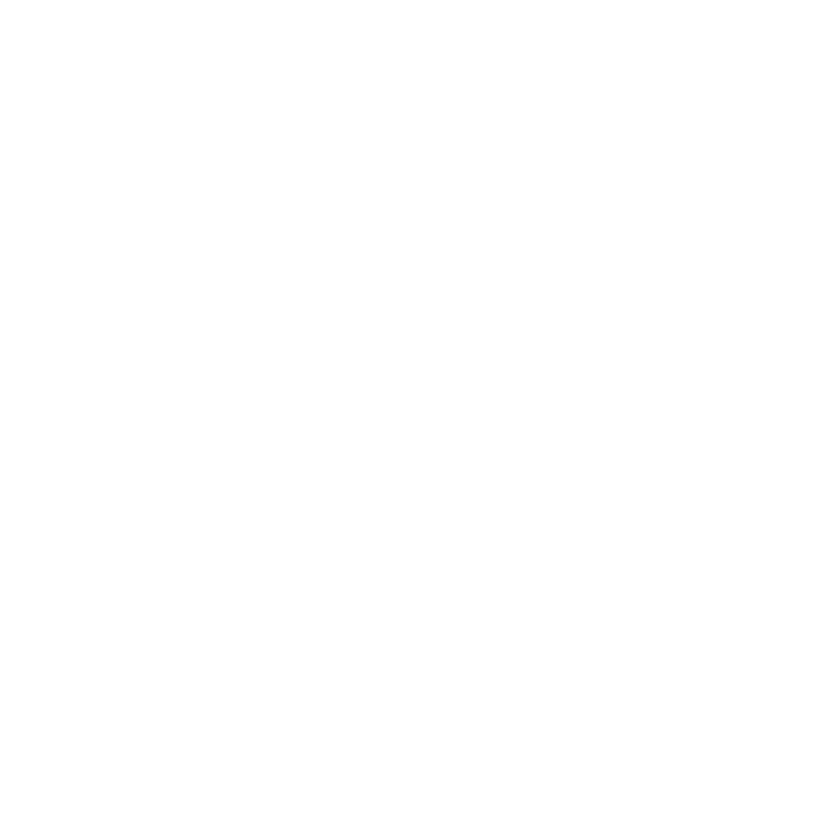

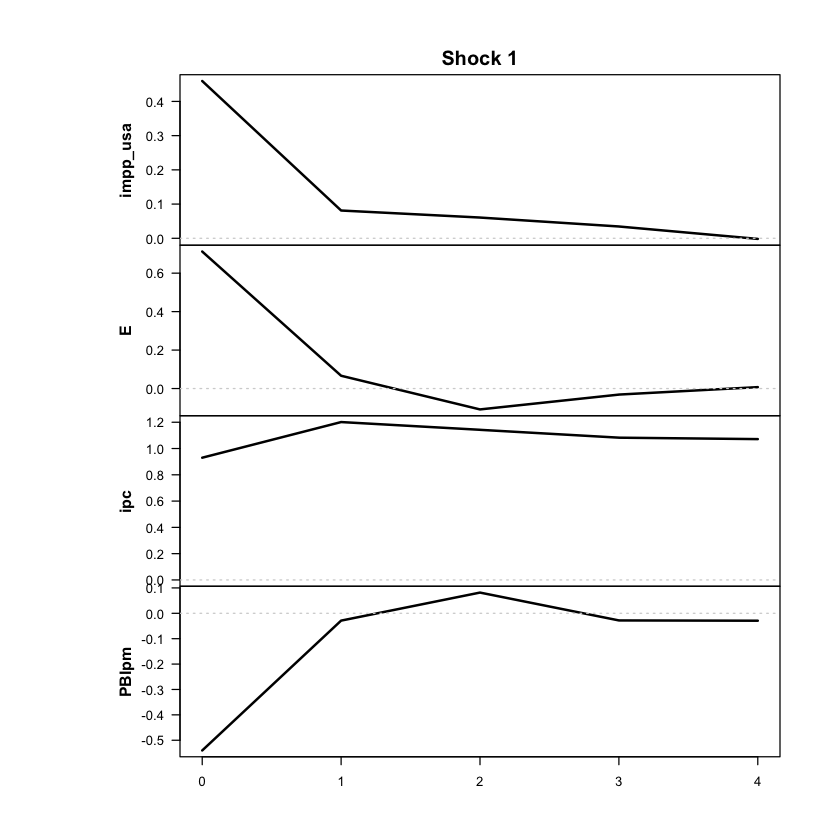

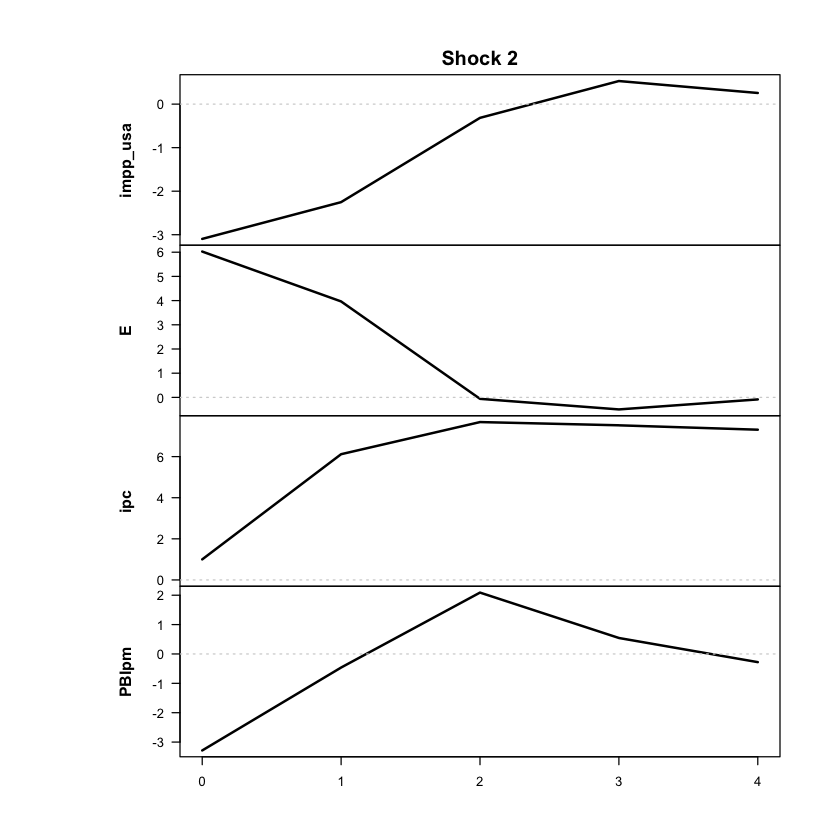

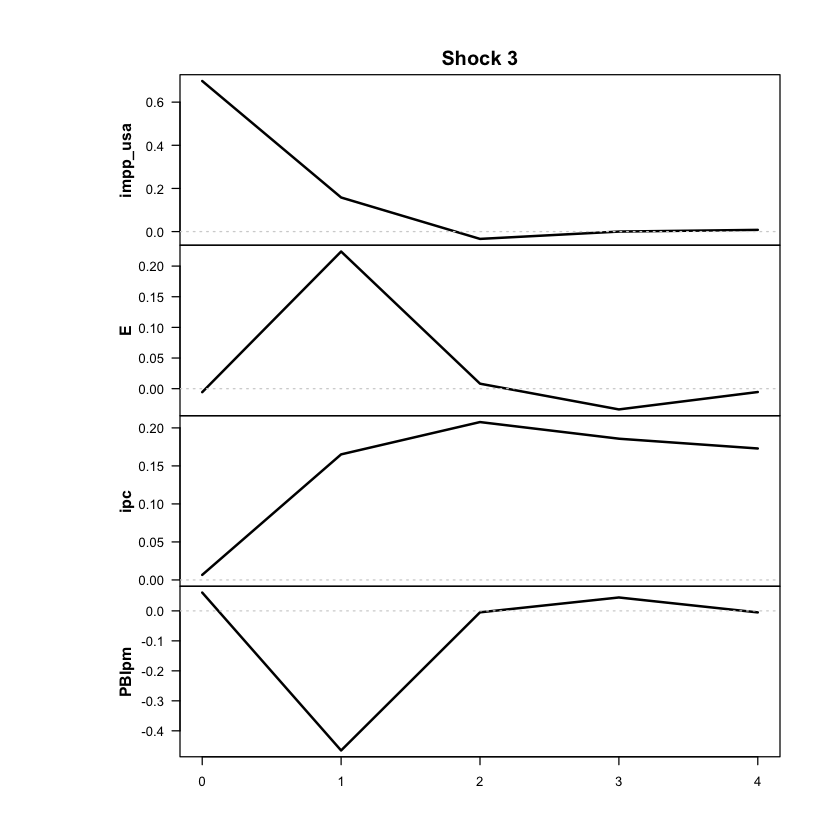

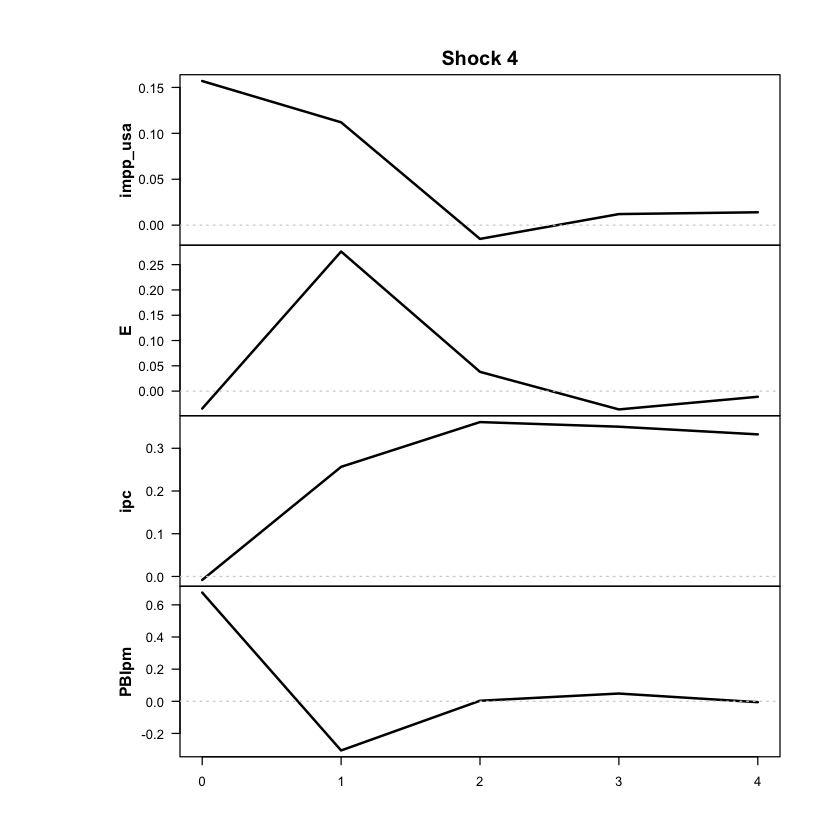

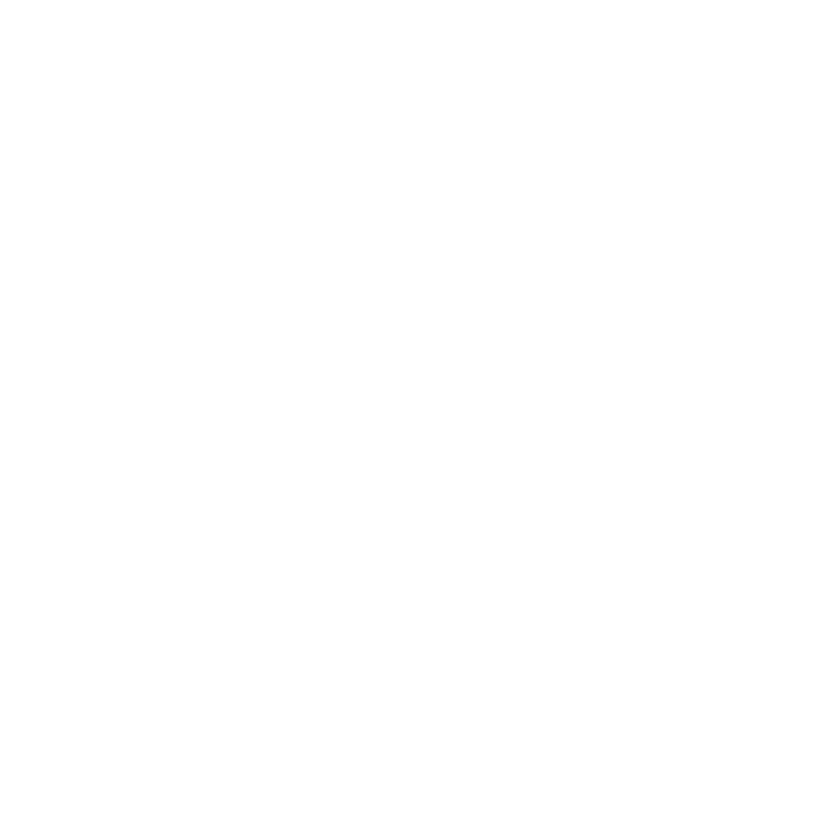

In [78]:
res <- run_threshold_tvar(
  data = df_anual_ferr,
  endog = c("impp_usa","E","ipc","PBIpm"),
  periodicity = 'anual', # 'trimestral' o 'anual' o mensual
  feature_lag = 1,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","PBIpm")
  run_tests = TRUE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = 4, # 4 años, igual que las LP anuales (en anual, NULL serían solo 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE,
  cond_dist = "Student"   # errores t de Student
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [79]:
c(tipo = res$tvar_model$model$weight_function, p = res$tvar_model$model$p,
  errores = res$tvar_model$model$cond_dist)

tipo           p     errores 
"threshold"         "1"   "Student"

In [80]:
ic_tvar_t_p1 <- criterios_info(res, "TVAR-t p=1")
print(ic_tvar_t_p1)
saveRDS(ic_tvar_t_p1, "ic_tvar_t_p1_anual_ferr.rds")

      modelo regimenes parametros  loglik   AIC    HQ   BIC
1 TVAR-t p=1         2         62 -210.78 545.6 607.1 698.5


In [81]:
# Control: qué modelo está en res
print(c(tipo = res$tvar_model$model$weight_function, p = res$tvar_model$model$p,
        errores = res$tvar_model$model$cond_dist))

resumen_modelo(res, data = df_anual_ferr, endog = c("impp_usa", "E", "ipc", "PBIpm"))
explorar_optimos(res, n = 20)

       tipo           p     errores 
"threshold"         "1"   "Student" 
Modelo: threshold | regímenes: 2 | rezagos: 1 | errores: Student 
Grados de libertad de la t de Student: 2.95 
Umbrales: 64.9% anual 
Años por régimen (régimen de mayor peso): régimen 1 = 68 | régimen 2 = 19 

Promedio observado de cada variable en los años de cada régimen
(variación anual en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      3.56      4.16
E            21.36    217.22
ipc          21.20    263.20
PBIpm         2.85      1.31
umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -209.12           123.3    NA

In [82]:
resumen_modelo(res, data = df_anual_ferr, endog = c("impp_usa", "E", "ipc", "PBIpm"))

Modelo: threshold | regímenes: 2 | rezagos: 1 | errores: Student 
Grados de libertad de la t de Student: 2.95 
Umbrales: 64.9% anual 
Años por régimen (régimen de mayor peso): régimen 1 = 68 | régimen 2 = 19 

Promedio observado de cada variable en los años de cada régimen
(variación anual en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      3.56      4.16
E            21.36    217.22
ipc          21.20    263.20
PBIpm         2.85      1.31


In [83]:
explorar_optimos(res, n = 10)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -209.12           123.3    NA        2.1            73/14
             2 -210.78            64.9    NA        2.9            68/19
             3 -210.78            62.4    NA        2.9            68/19
             4 -210.78            64.8    NA        2.9            68/19
             5 -210.78            64.7    NA        2.9            68/19
             6 -210.78            63.6    NA        2.9            68/19
             7 -210.78            65.5    NA        2.9            68/19
             8 -210.78            66.9    NA        2.9            68/19
             9 -210

In [84]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

threshold Student STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 1, M = 2, d = 4, #parameters = 62, #observations = 87 x 4
  Switching variable: ipc with lag 1.

Regime 1 
Degrees of freedom: 2.95 (for all regimes) 
Upper threshold: 0.80 
Regime means: 0.42, 0.45, 0.54, 0.65

   Y      phi0          A1                              Omega                  
1 y1 = [  0.36 ] + [  0.33 -0.03 -0.08 -0.04 ] y1.1 + [  1.40 -0.09  0.01  0.54
2 y2   [  0.00 ]   [  0.05  0.43  0.40  0.03 ] y2.1   [ -0.09  0.17  0.05 -0.18
3 y3   [ -0.02 ]   [  0.03  0.30  0.70  0.04 ] y3.1   [  0.01  0.05  0.04 -0.05
4 y4   [  0.81 ]   [  0.01 -0.67  0.24  0.03 ] y4.1   [  0.54 -0.18 -0.05  1.80
    1/2     
1 ]     eps1
2 ]     eps2
3 ]     eps3
4 ]     eps4

Regime 2 
Regime means: 0.48, 1.51, 1.73, 0.40

   Y     phi0          A1                              Omega                  
1 y1 = [ 0.30 ] + [  0.21 -0.24  0.23  0.11 ] y1.1 + [  0.90 -0.03  0.37  0.09
2 y2   [ 0.75 ]   

In [ ]:
shock_tvar_t_p1 <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "PBIpm"))
# La función sugiere el shock 1, pero ese shock mueve más al ipc que a E (ERPT de impacto 1,285):
# no es el cambiario. El shock 2 sí cumple el chequeo (E 0,24; ipc 0,04; ERPT de impacto 0,163).
shock_tvar_t_p1 <- 2
shock_tvar_t_p1

Efecto de impacto de cada shock  (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0067 -0.0149  0.0860  0.0234
  E         0.0861  0.2413 -0.0058 -0.0426
  ipc       0.1106  0.0394  0.0067 -0.0099
  PBIpm    -0.0053 -0.0106  0.0050  0.0675

Participación de E en el efecto de cada shock  :
shock_1 shock_2 shock_3 shock_4 
   0.52    0.79    0.01    0.05 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  1.285   0.163  -1.147   0.232 

>>> Shock sugerido como cambiario: 2 (confirmalo: debe mover mucho a E y poco a ipc )


[1] 2

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 27.3%.

GIRF del régimen 1...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!

GIRF del régimen 2...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




+++ Régimen 1 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte    ipc   PBIpm
         0 0.1633 -0.0439
         1 0.6549 -0.0932
         2 1.1941 -0.1106
         3 1.7048 -0.1214
         4 2.1497 -0.1283

+++ Régimen 2 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte    ipc   PBIpm
         0 0.1633 -0.0439
         1 0.9638 -0.0561
         2 1.3739 -0.0404
         3 1.6075 -0.0406
         4 1.7944 -0.0454


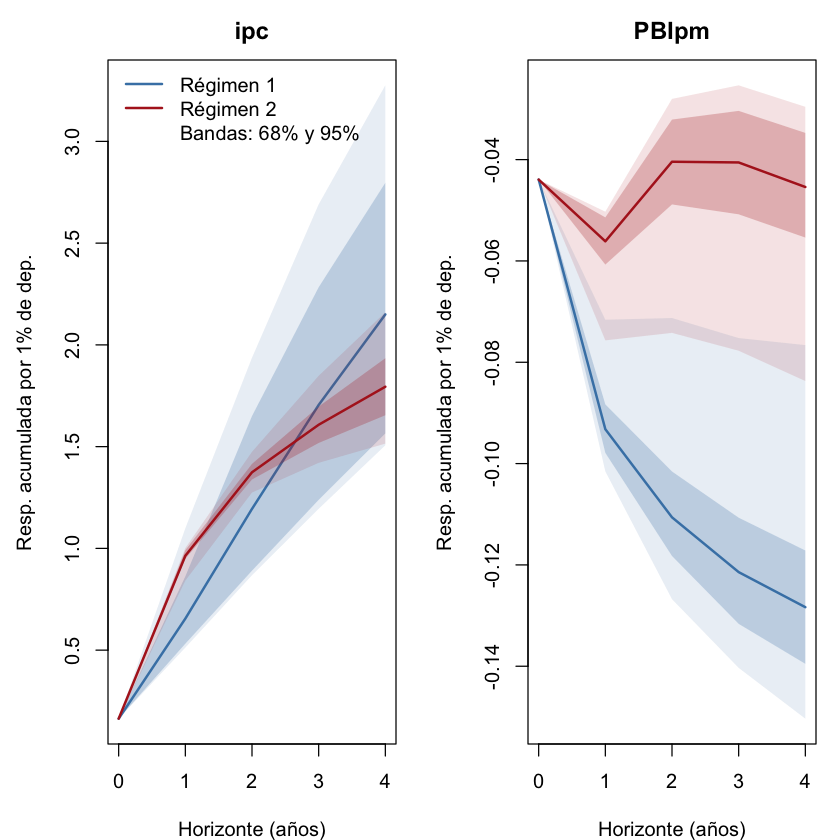


+++ Régimen 1 - IRF lineal acumulada por 1% de depreciación inicial (unidades originales) +++
 horizonte    ipc   PBIpm
         0 0.1633 -0.0439
         1 0.5318 -0.0966
         2 0.8905 -0.1158
         3 1.2237 -0.1268
         4 1.5306 -0.1355

+++ Régimen 2 - IRF lineal acumulada por 1% de depreciación inicial (unidades originales) +++
 horizonte    ipc   PBIpm
         0 0.1633 -0.0439
         1 0.9988 -0.0501
         2 1.2541 -0.0222
         3 1.2284 -0.0149
         4 1.1934 -0.0186


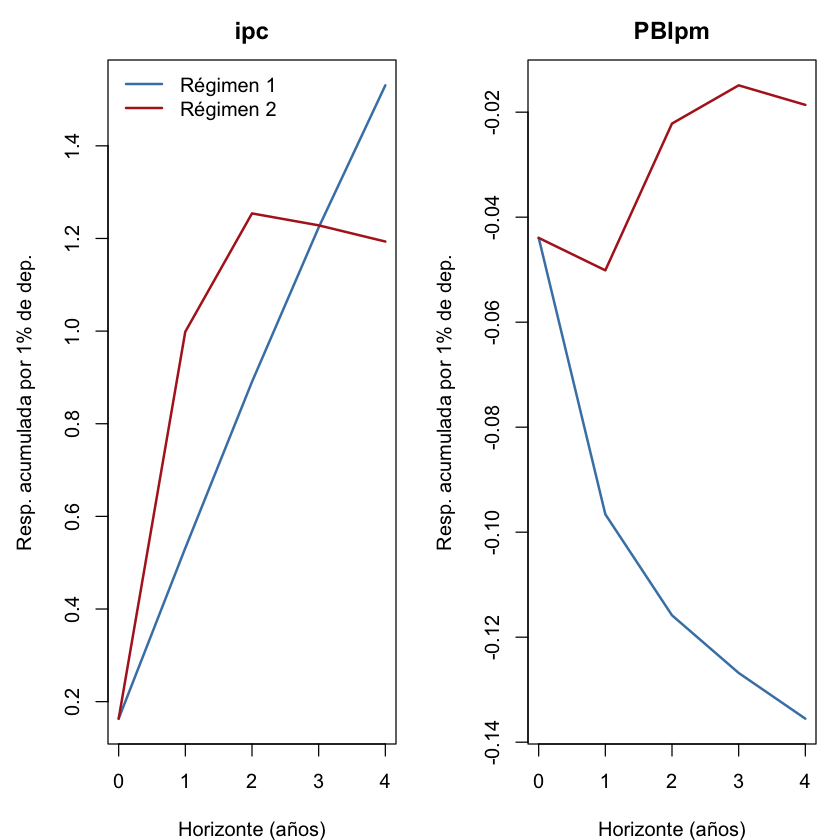

In [86]:
# res todavía es el TVAR-t (celda del modelo). Si no, volver a correr esa celda (load_presaved = TRUE).
girf_impp_usa_tvar_t_p1 <- graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "PBIpm"),
                                                  archivo = paste0(carpeta, "girf_original_impp_usa_tvar_t_p1_anual_ferr"))
irf_impp_usa_tvar_t_p1  <- graficar_irf_original(res, endog = c("impp_usa", "E", "ipc", "PBIpm"),
                                                 archivo = paste0(carpeta, "irf_original_impp_usa_tvar_t_p1_anual_ferr"))

### ERPT — TVAR t, p = 1

Correr solo si el modelo pasó el diagnóstico.

In [87]:
out_impp_usa_tvar_t_p1 <- erpt_historia(res, data = df_anual_ferr, endog = c("impp_usa", "E", "ipc", "PBIpm"), shock_num = shock_tvar_t_p1)

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 27.3%.

Estimando 87 GIRFs (una por año), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Años dominados por cada régimen (peso > 0.9): régimen 1 = 68 | régimen 2 = 19 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.9841

Promedio entre años:
  horizonte reg_bajo_original reg_alto_original
1         0            0.1633            0.1633
2         1            0.5575            0.9452
3         2            0.9804            1.3418
4         3            1.4052            1.5811
5         4            1.8271            1.8082

Mediana entre años (robusta a años con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0           0.1633           0.1633
2         1           0.5282           0.9714
3         2           0.9050           1.3496
4         3           1.2970           1.5816
5         4           1.6814           1.7993


In [88]:
out_impp_usa_tvar_t_p1_acum <- erpt_historia(res, data = df_anual_ferr, endog = c("impp_usa", "E", "ipc", "PBIpm"), shock_num = shock_tvar_t_p1,
                      definicion = "acumulado")

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 27.3%.

Estimando 87 GIRFs (una por año), 1000 simulaciones cada una...



Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Años dominados por cada régimen (peso > 0.9): régimen 1 = 68 | régimen 2 = 19 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.9841

Promedio entre años:
  horizonte reg_bajo_original reg_alto_original
1         0            0.1633            0.1633
2         1            0.3739            0.5722
3         2            0.5172            0.7254
4         3            0.6183            0.7792
5         4            0.6948            0.8131

Mediana entre años (robusta a años con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0           0.1633           0.1633
2         1           0.3624           0.5891
3         2           0.5033           0.7416
4         3           0.6044           0.7879
5         4           0.6818           0.8152


In [89]:
   out_impp_usa_tvar_t_p1_acum_s456 <- erpt_historia(res, data = df_anual_ferr,
                                                     endog = c("impp_usa", "E", "ipc", "PBIpm"),
                                                     shock_num = shock_tvar_t_p1,
                                                     definicion = "acumulado", semilla = 456)

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 27.3%.

Estimando 87 GIRFs (una por año), 1000 simulaciones cada una...



Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Años dominados por cada régimen (peso > 0.9): régimen 1 = 68 | régimen 2 = 19 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.9841

Promedio entre años:
  horizonte reg_bajo_original reg_alto_original
1         0            0.1633            0.1633
2         1            0.3747            0.5771
3         2            0.5206            0.7329
4         3            0.6253            0.7908
5         4            0.7004            0.8193

Mediana entre años (robusta a años con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0           0.1633           0.1633
2         1           0.3637           0.5919
3         2           0.5082           0.7478
4         3           0.6113           0.7980
5         4           0.6860           0.8220


Umbrales (inflación anual de t-1): 64.9% anual 
Años por régimen: régimen 1 = 68 | régimen 2 = 19 


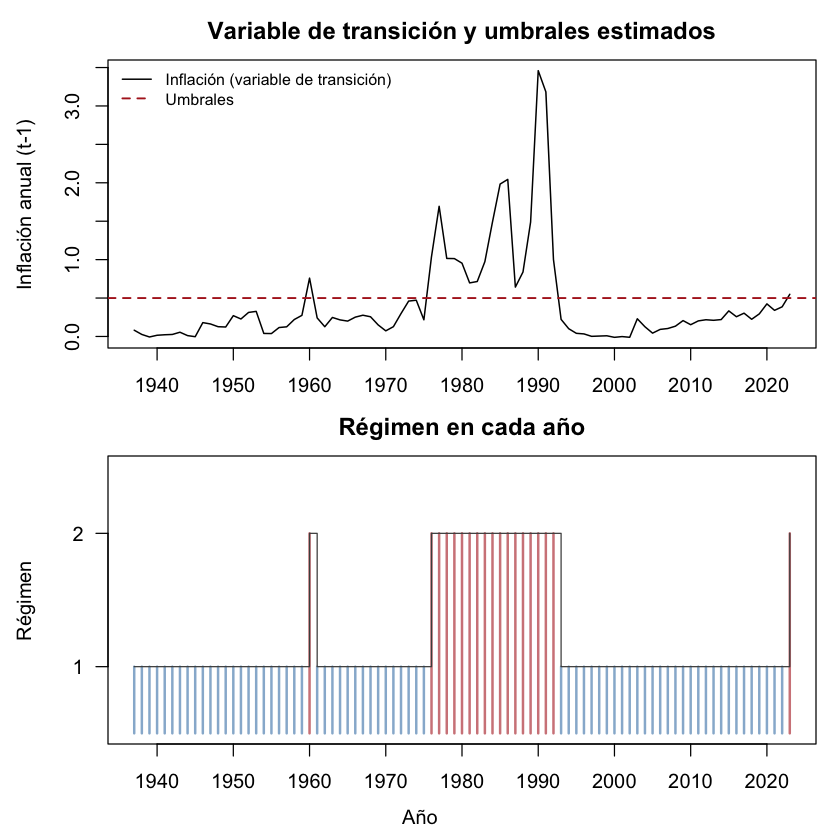

In [90]:
graficar_transicion(res, data = df_anual_ferr, endog = c("impp_usa", "E", "ipc", "PBIpm"),
                    archivo = paste0(carpeta, "transicion_impp_usa_tvar_t_p1_anual_ferr"))

### Gráficos — TVAR t, p = 1 (robustez)

Modelo que pasa el diagnóstico de convergencia y tiene los mejores criterios de información, pero el Portmanteau rechaza (0,004 y 0,034) y los grados de libertad son 2,04: queda como robustez.

HTML widgets cannot be represented in plain text (need html)

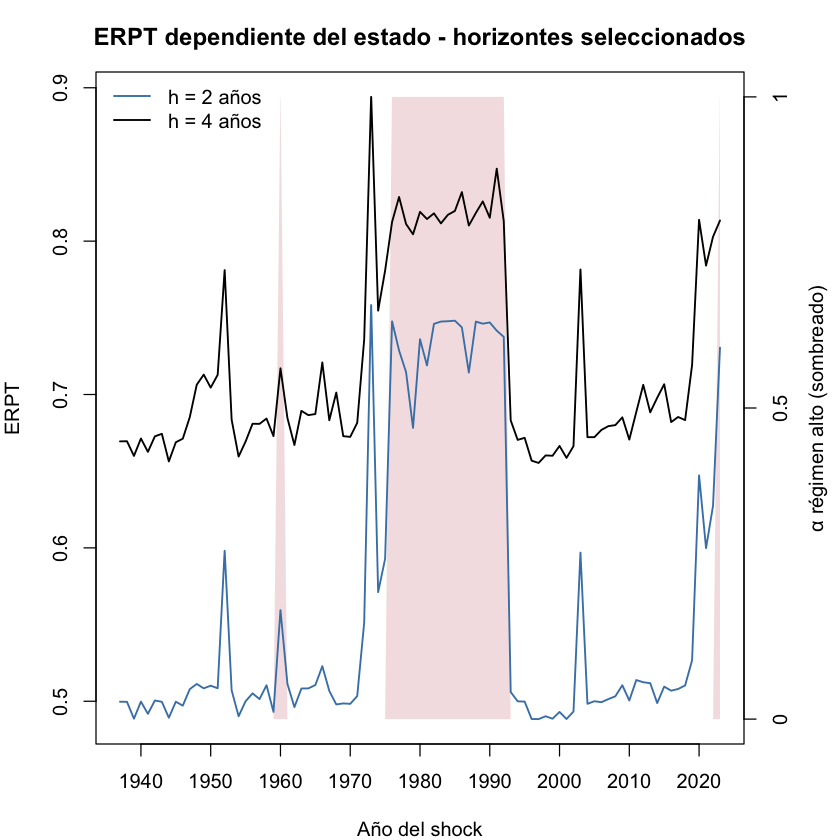

In [91]:
graficar_erpt(out_impp_usa_tvar_t_p1_acum, archivo = paste0(carpeta, "erpt_impp_usa_tvar_t_p1_acum_anual_ferr"))

HTML widgets cannot be represented in plain text (need html)

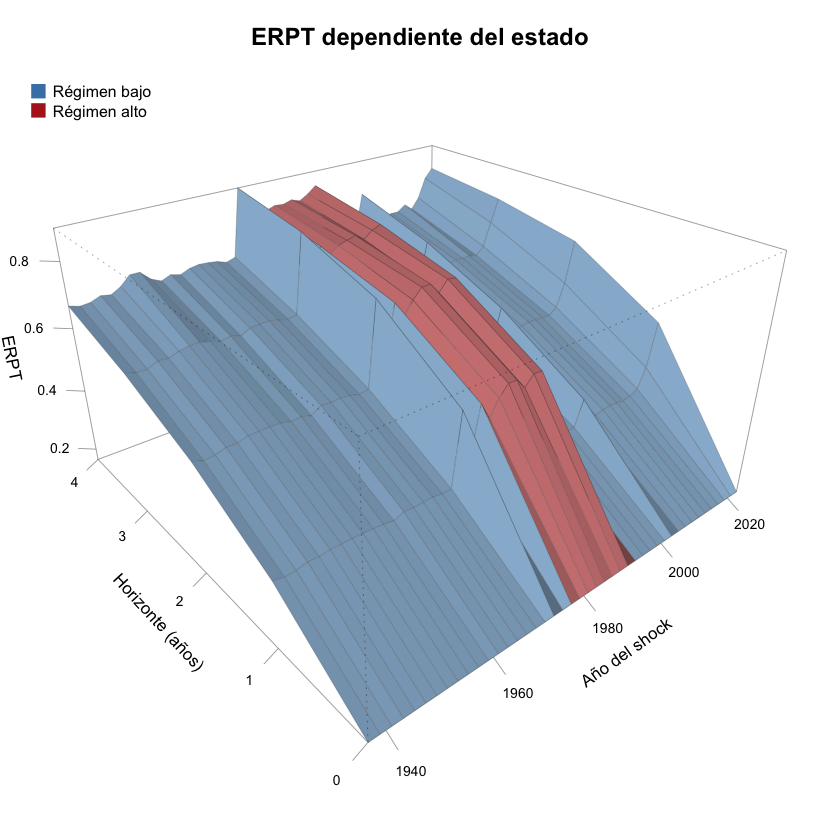

In [92]:
graficar_erpt_manta(out_impp_usa_tvar_t_p1_acum, cada = 2,
                    archivo = paste0(carpeta, "erpt_manta_impp_usa_tvar_t_p1_acum_c2_anual_ferr"))

Promedio de ERPT por régimen (trimestres con peso > 0.9):
 horizonte reg_bajo_original reg_alto_original
         4             0.695             0.813


GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/GRAFICOS_TVAR_VLSTAR_Anuales/gif_erpt_h4_impp_usa_tvar_t_p1_acum_anual_ferr.gif

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/GRAFICOS_TVAR_VLSTAR_Anuales/gif_erpt_h4_marcas_impp_usa_tvar_t_p1_acum_anual_ferr.gif



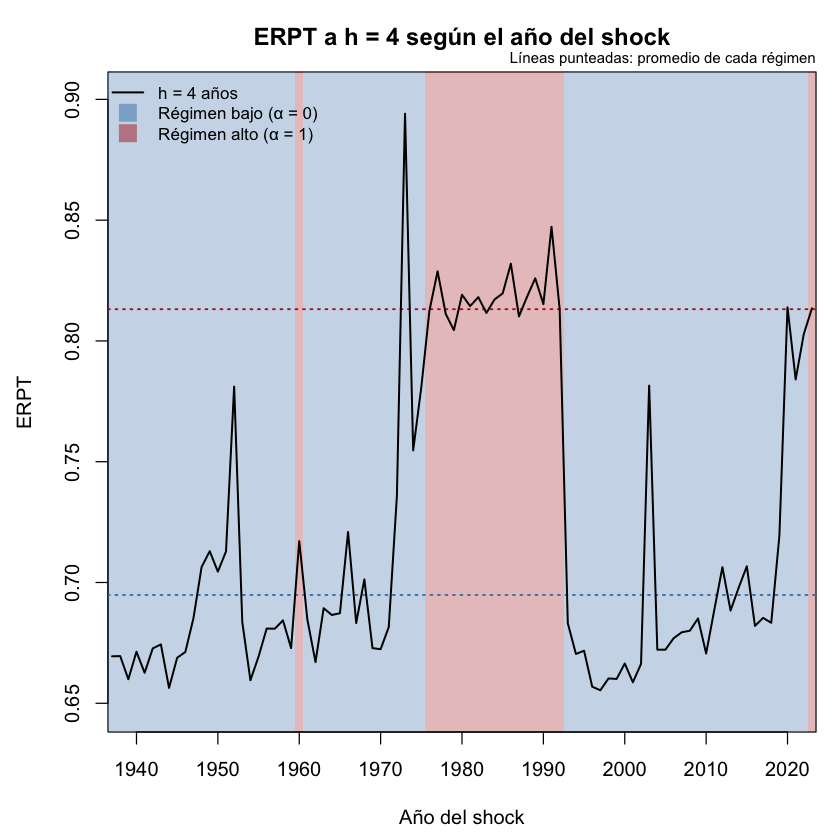

 horizonte   1973   1974   1975   1976
         0 0.1633 0.1633 0.1633 0.1633
         1 0.5778 0.4146 0.4277 0.5965
         2 0.7583 0.5712 0.5929 0.7477
         3 0.8470 0.6753 0.7084 0.7862
         4 0.8941 0.7547 0.7808 0.8126


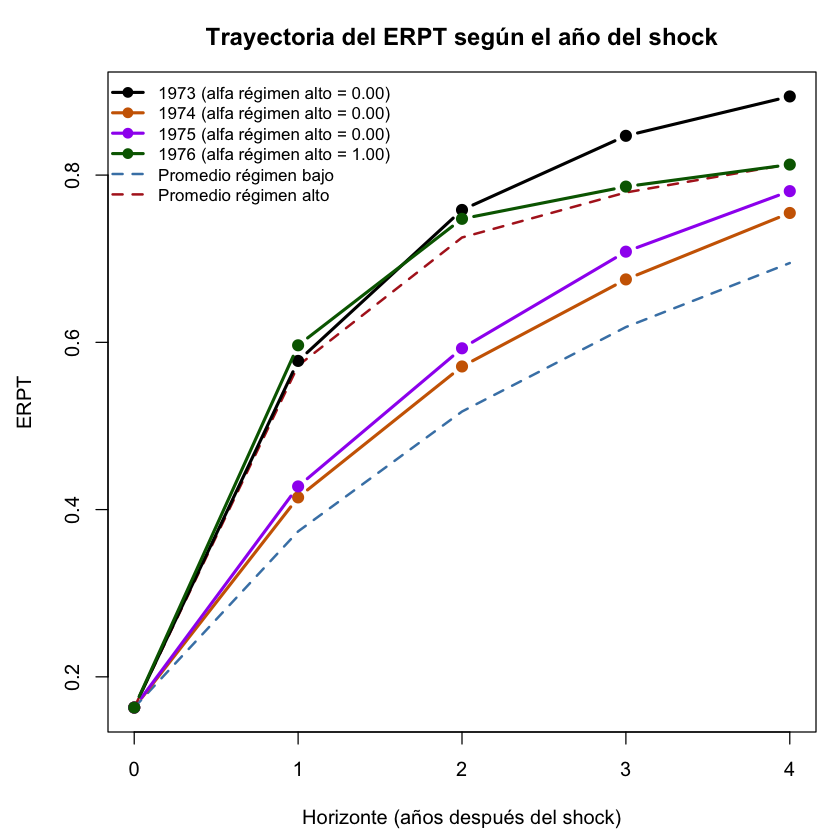

 horizonte   1987   1988   1989   1990
         0 0.1633 0.1633 0.1633 0.1633
         1 0.5617 0.5920 0.5911 0.6011
         2 0.7143 0.7475 0.7462 0.7470
         3 0.7744 0.7910 0.7952 0.7879
         4 0.8102 0.8183 0.8259 0.8152


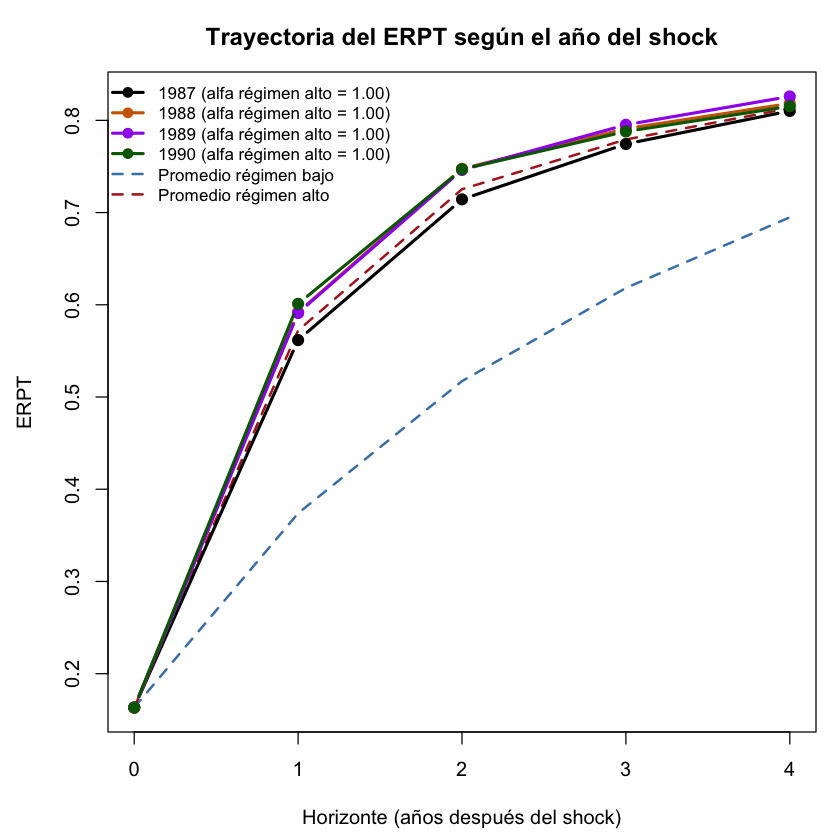

 horizonte   1989   1990   1991   1992
         0 0.1633 0.1633 0.1633 0.1633
         1 0.5911 0.6011 0.5891 0.5814
         2 0.7462 0.7470 0.7416 0.7376
         3 0.7952 0.7879 0.8067 0.7862
         4 0.8259 0.8152 0.8472 0.8132


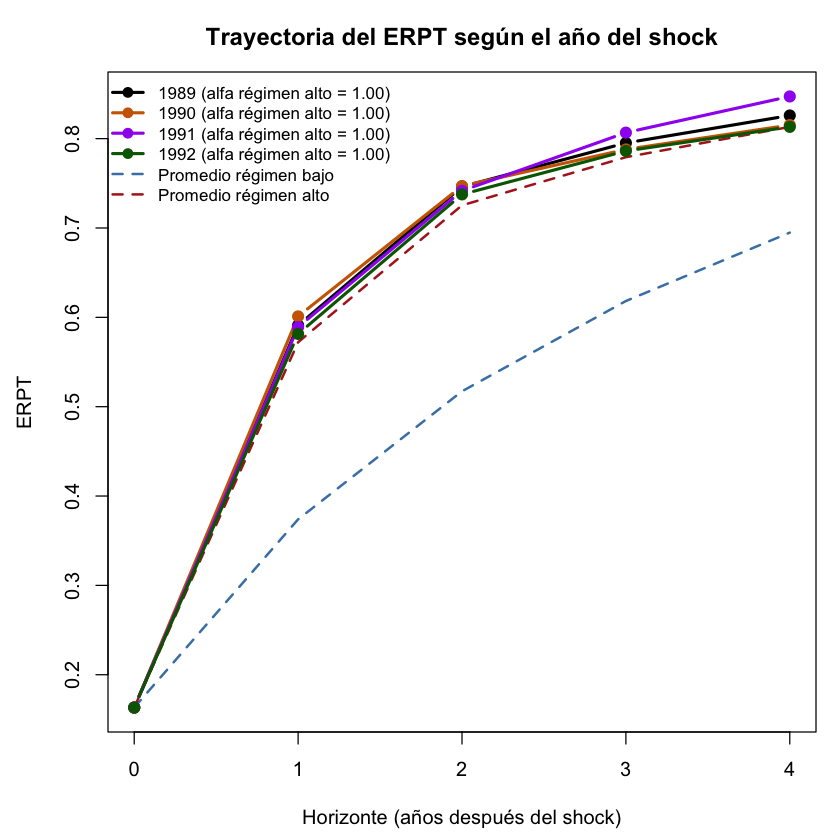

 horizonte   2001   2002   2003   2004
         0 0.1633 0.1633 0.1633 0.1633
         1 0.3553 0.3573 0.4344 0.3609
         2 0.4884 0.4933 0.5969 0.4983
         3 0.5839 0.5920 0.7067 0.5978
         4 0.6587 0.6663 0.7815 0.6722


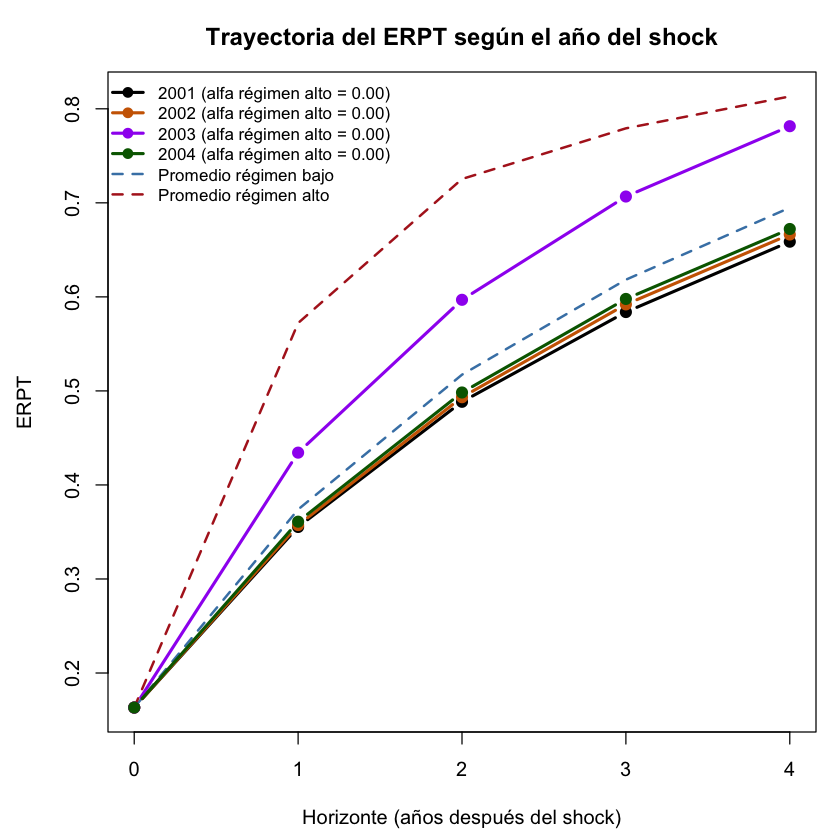

 horizonte   2016   2017   2018   2019
         0 0.1633 0.1633 0.1633 0.1633
         1 0.3645 0.3646 0.3648 0.3785
         2 0.5069 0.5080 0.5103 0.5267
         3 0.6055 0.6094 0.6091 0.6335
         4 0.6820 0.6853 0.6833 0.7193


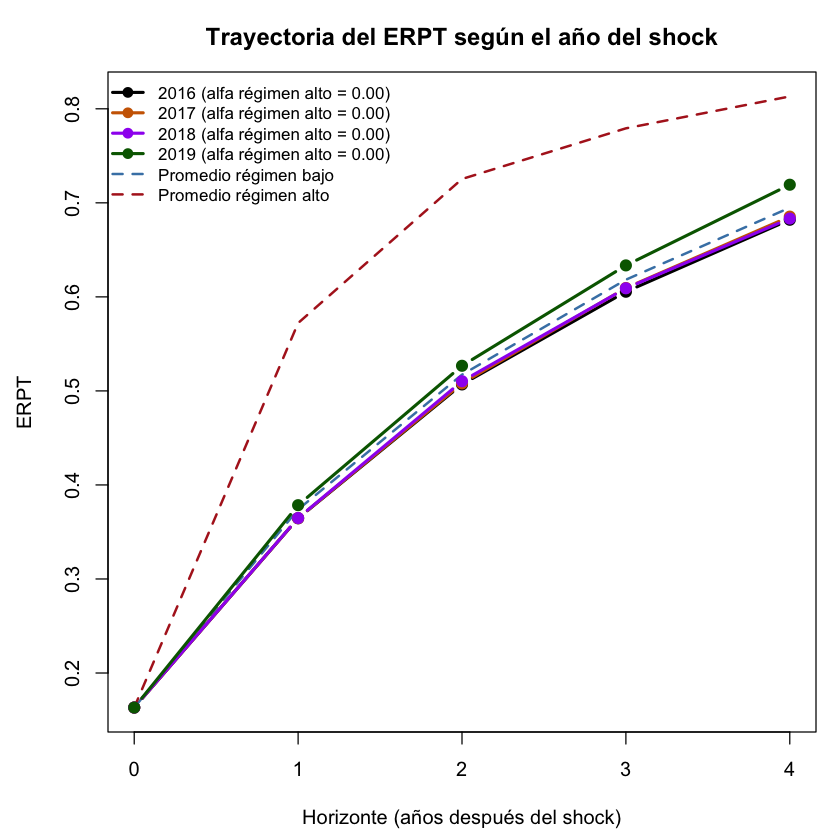

 horizonte   1950   1983   1988   2002
         0 0.1633 0.1633 0.1633 0.1633
         1 0.3597 0.5966 0.5920 0.3573
         2 0.5101 0.7476 0.7475 0.4933
         3 0.6135 0.7860 0.7910 0.5920
         4 0.7045 0.8116 0.8183 0.6663


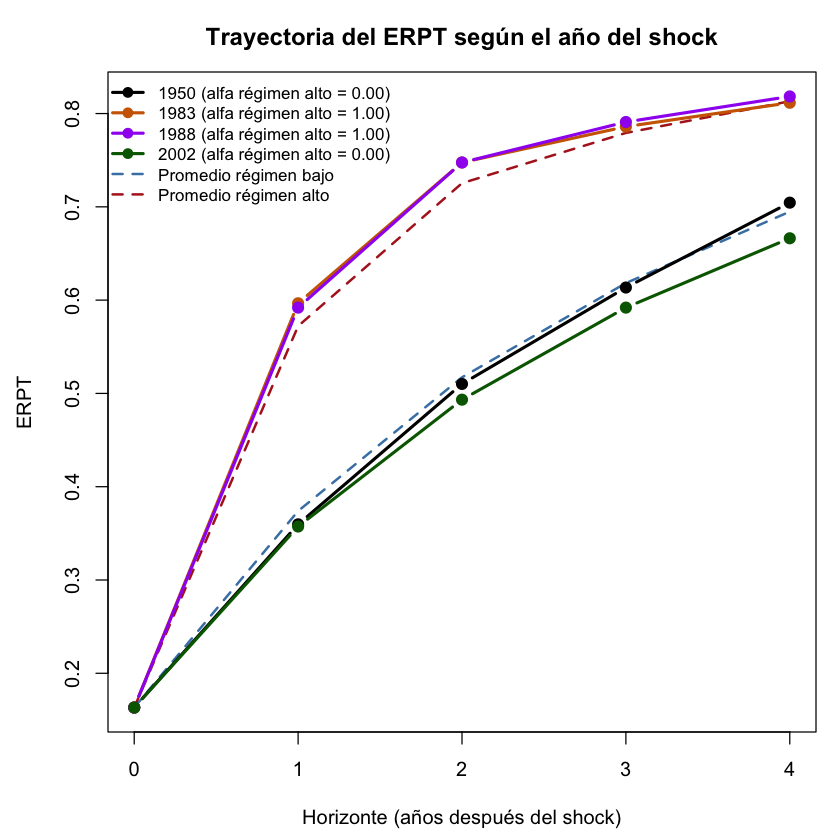

In [93]:
# Mismo juego de gráficos que la especificación principal (TVAR p = 1), para comparar
graficar_erpt_2d_bandas(out_impp_usa_tvar_t_p1_acum, horizontes = 4,
                        archivo = paste0(carpeta, "erpt_2d_bandas_impp_usa_tvar_t_p1_acum_anual_ferr"))
guardar_gif_erpt_h(out_impp_usa_tvar_t_p1_acum, h = 4,
                   archivo = paste0(carpeta, "gif_erpt_h4_impp_usa_tvar_t_p1_acum_anual_ferr"))
guardar_gif_erpt_h(out_impp_usa_tvar_t_p1_acum, h = 4, marcas = c(1975, 1989, 2002, 2018),
                   archivo = paste0(carpeta, "gif_erpt_h4_marcas_impp_usa_tvar_t_p1_acum_anual_ferr"))
for (a in list(1973:1976, 1987:1990, 1989:1992, 2001:2004, 2016:2019, c(1950, 1983, 1988, 2002))) {
  graficar_trayectorias(out_impp_usa_tvar_t_p1_acum, trimestres = a,
                        archivo = paste0(carpeta, "trayectorias_impp_usa_tvar_t_p1_acum_",
                                         paste(a, collapse = "_"), "_anual_ferr"))
}

### VLSTAR con errores t, p = 1

Nota de la versión trimestral: el VLSTAR-t con p = 3 dio muy mal resultado. En la anual, el equivalente es p = 2 (abajo); correrlo solo si el de p = 1 converge bien.


Desvíos usados para escalar:
  impp_usa          E        ipc      PBIpm 
0.07653640 0.63532513 0.62520664 0.05122031 


Using 6 cores for 500 estimations rounds...

PHASE 1: Estimating all the parameters with a genetic algorithm...

Results from the genetic algorithm:

The lowest loglik:  -363.983

The largest loglik: -226.27

PHASE 2: Estimating all the parameters with a variable metric algorithm...

Results from the variable metric algorithm:

The lowest loglik:  -333.686

The largest loglik: -195.014

Filtering inappropriate estimates...

Filtered through 334 inappropriate  estimates with a larger log-likelihood

Calculating approximate standard errors...

Finished!




========= Unstructured fitted model ==========


Calculating approximate standard errors...



========= Structured fitted model (heteroskedasticity) ==========
Saving trained models to models/ folder

 >>> DIAGNOSTIC PLOTS


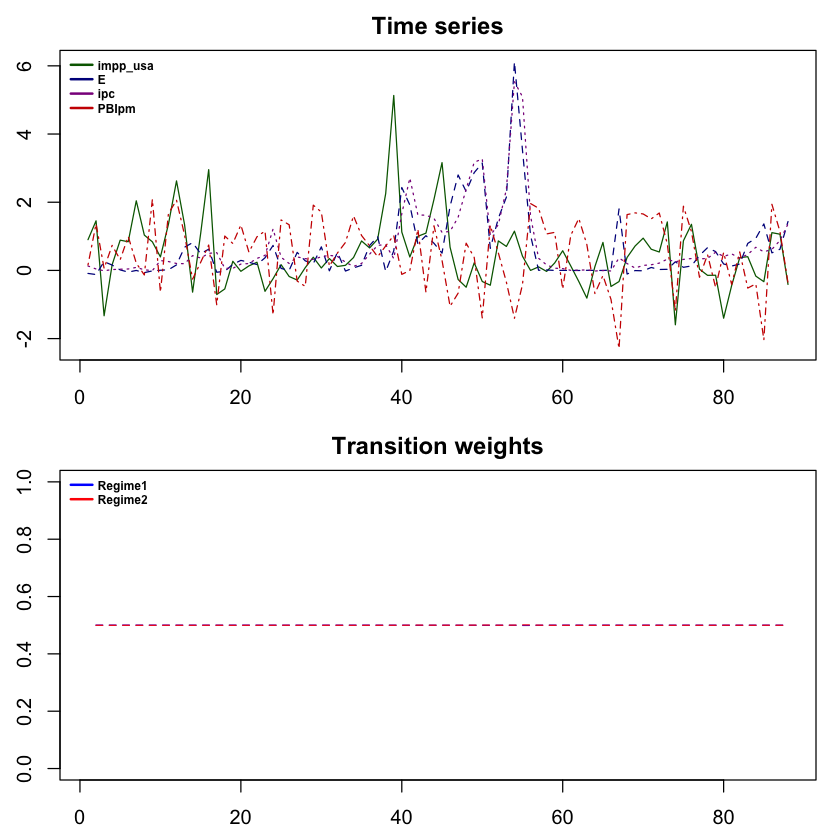

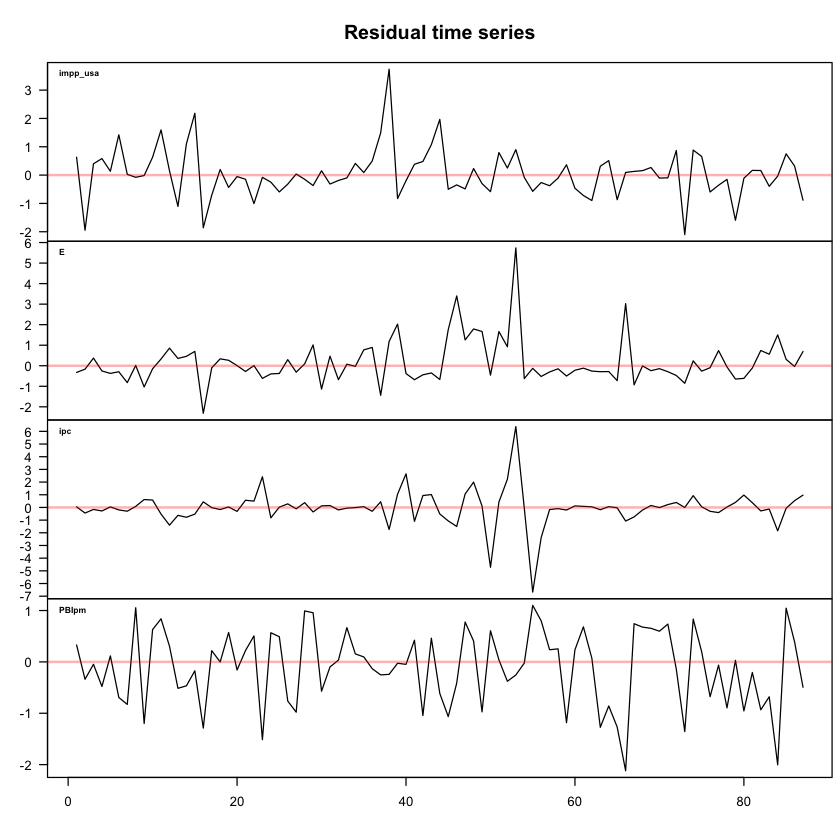

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



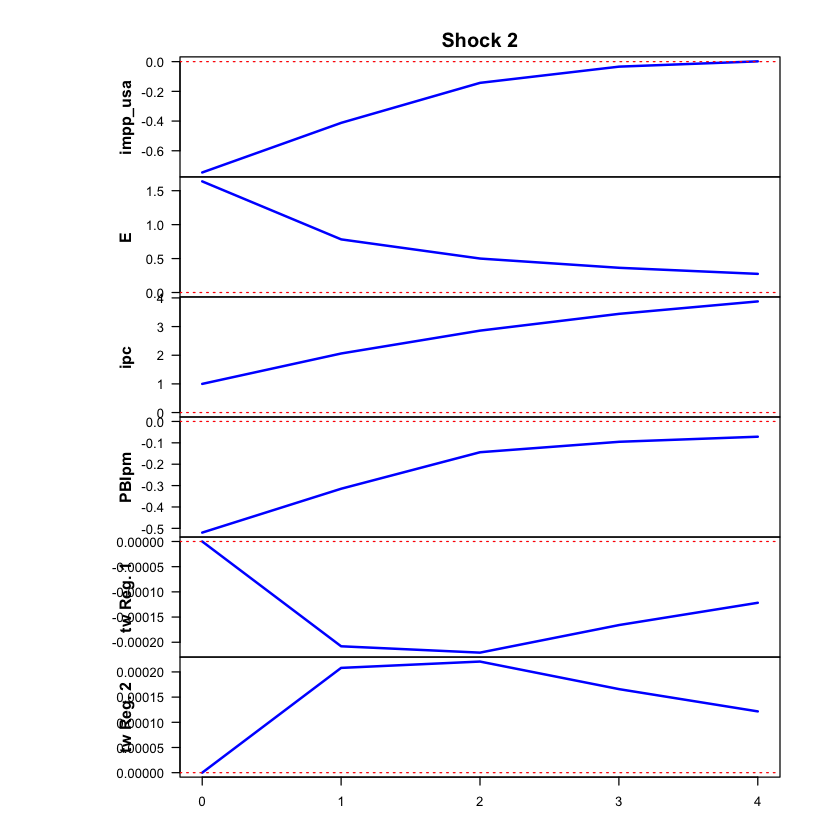

 >>> Linear IRF ( 1  shock units)


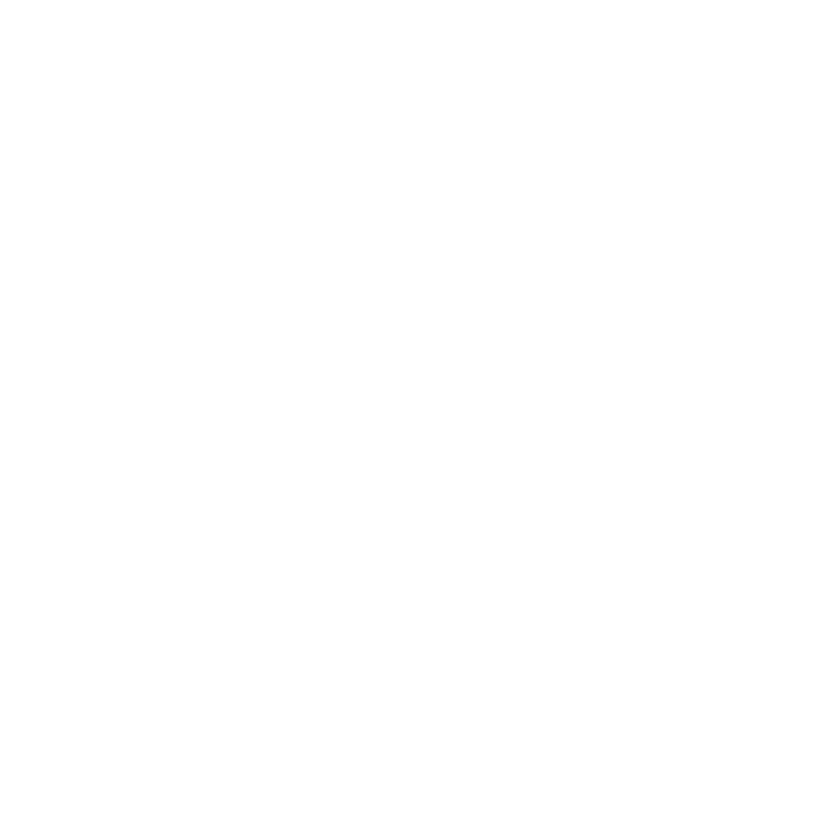

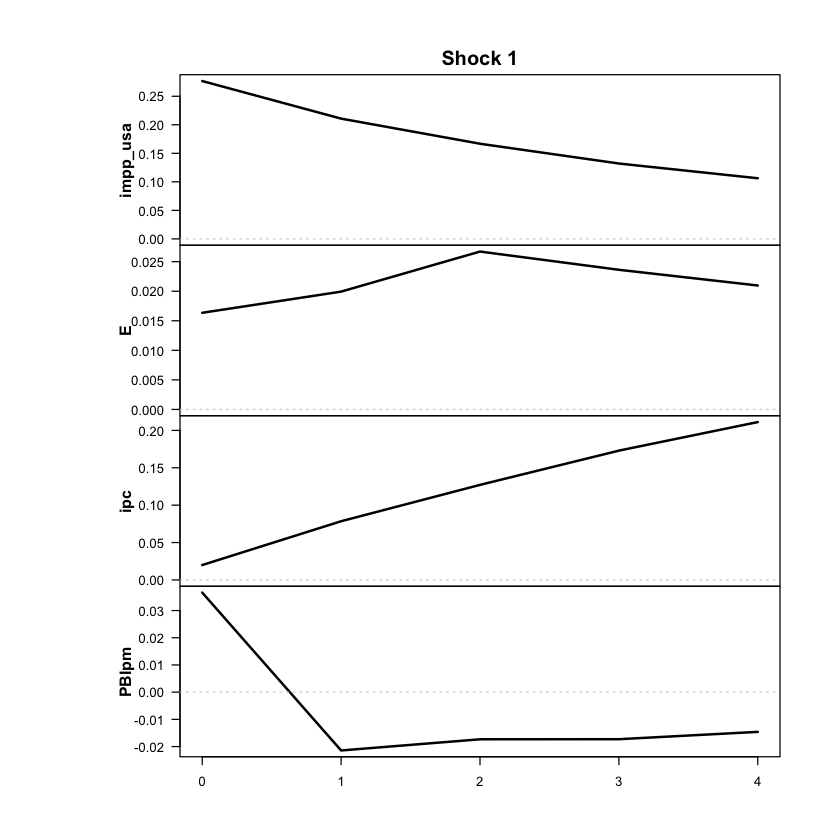

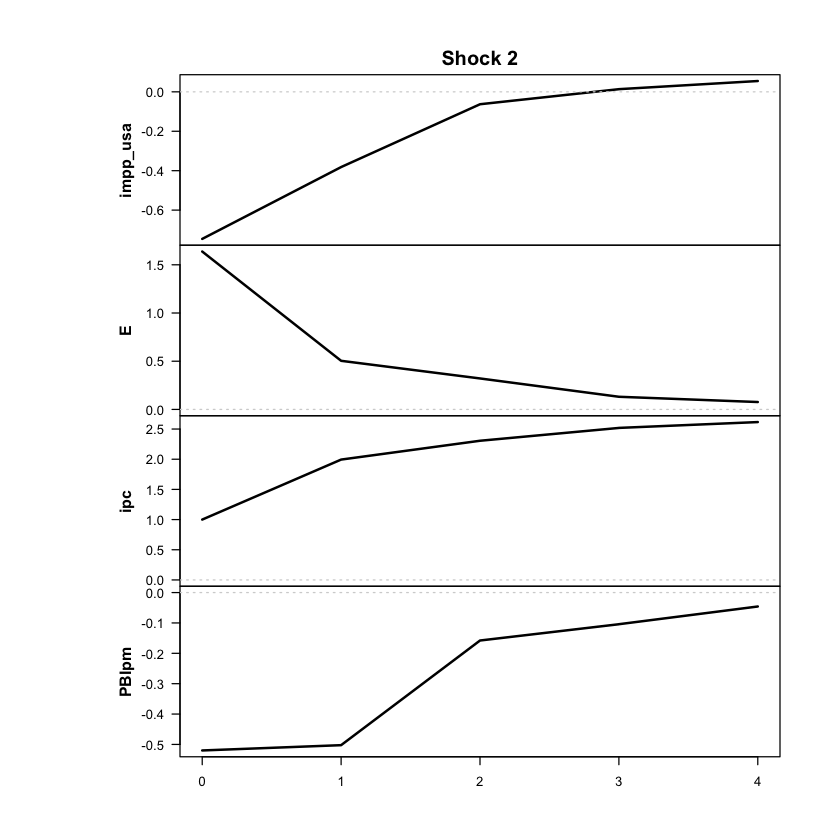

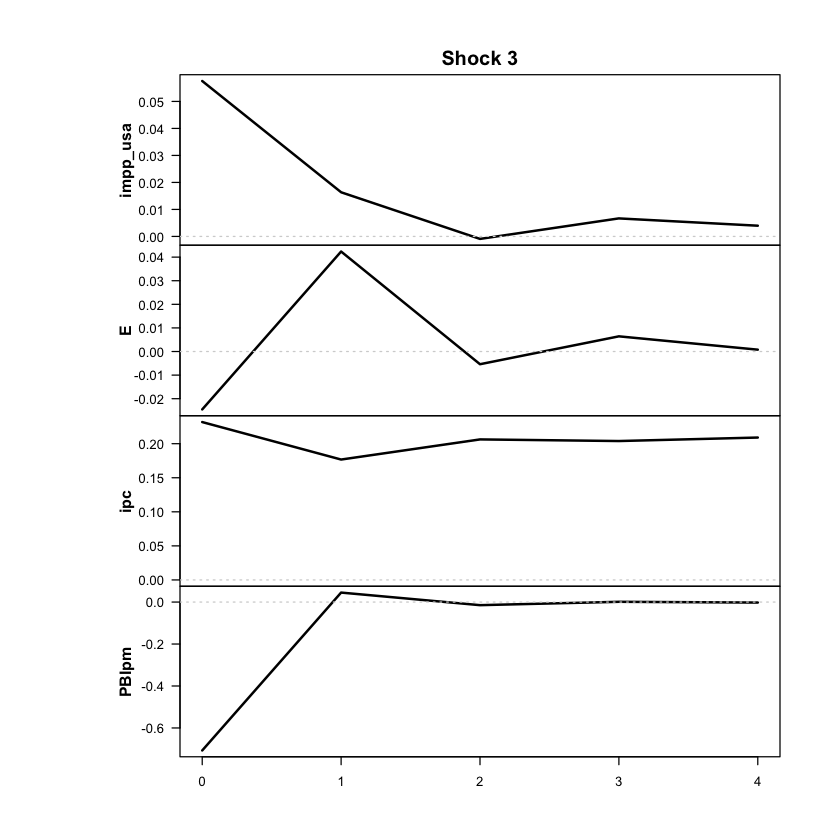

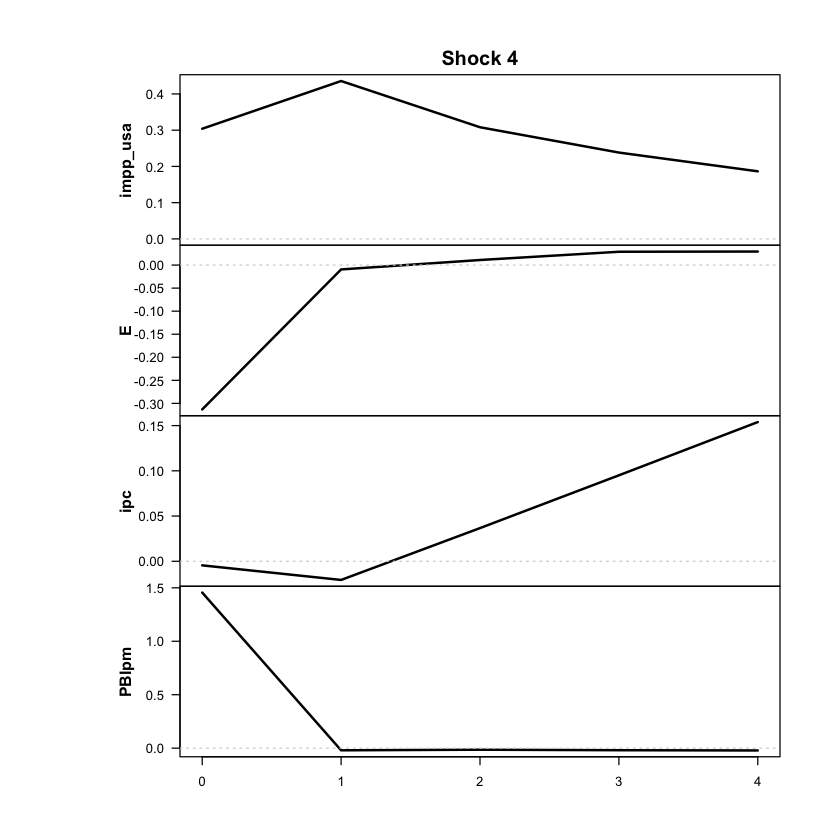

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



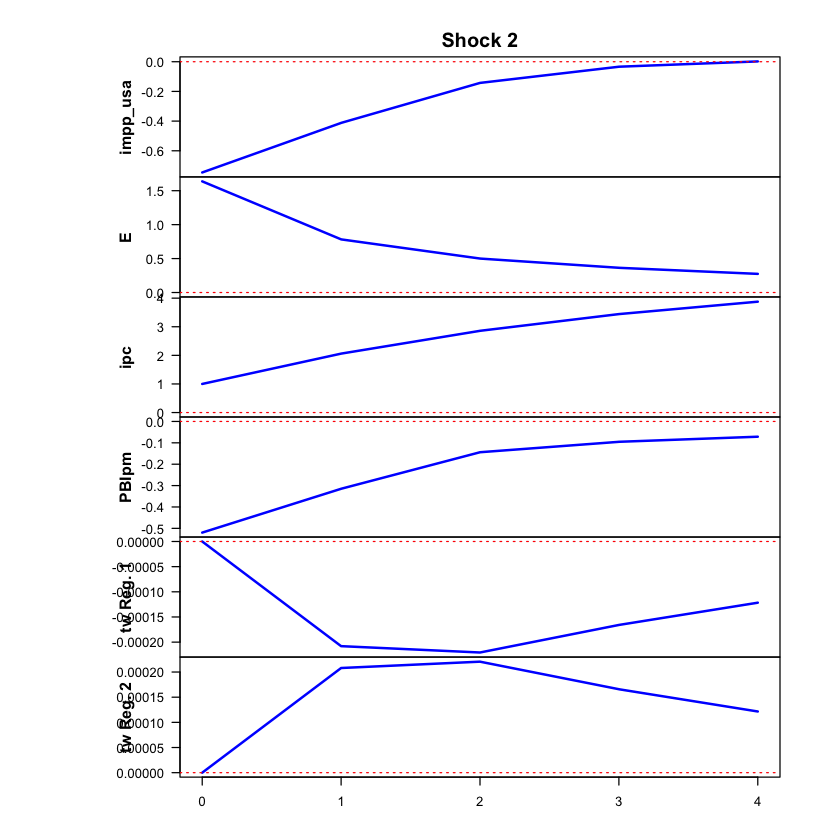

 >>> Linear IRF ( 1  shock units)


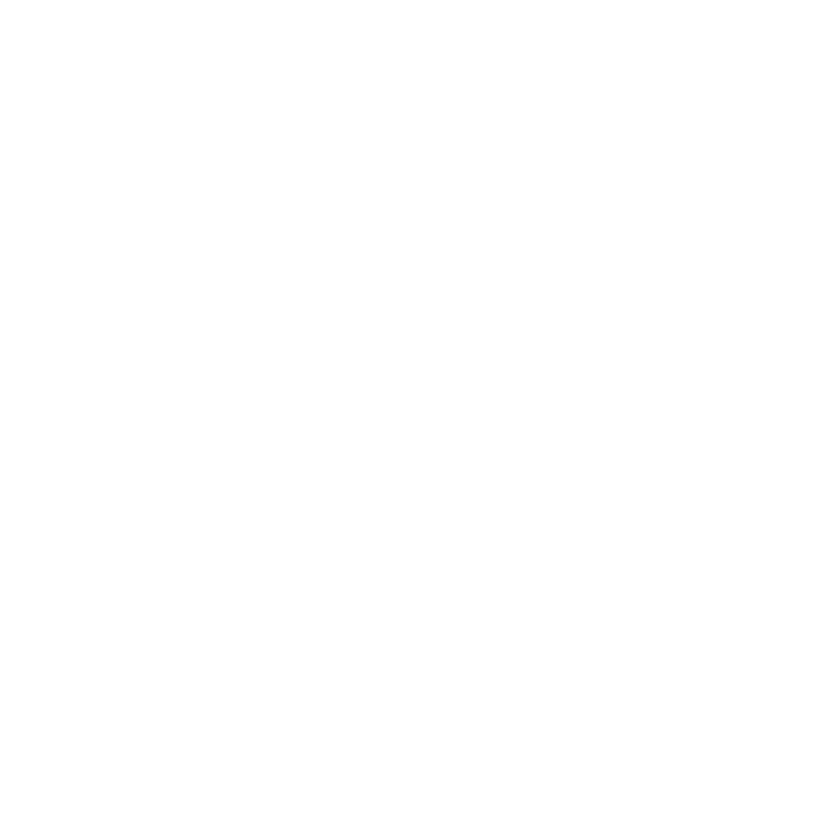

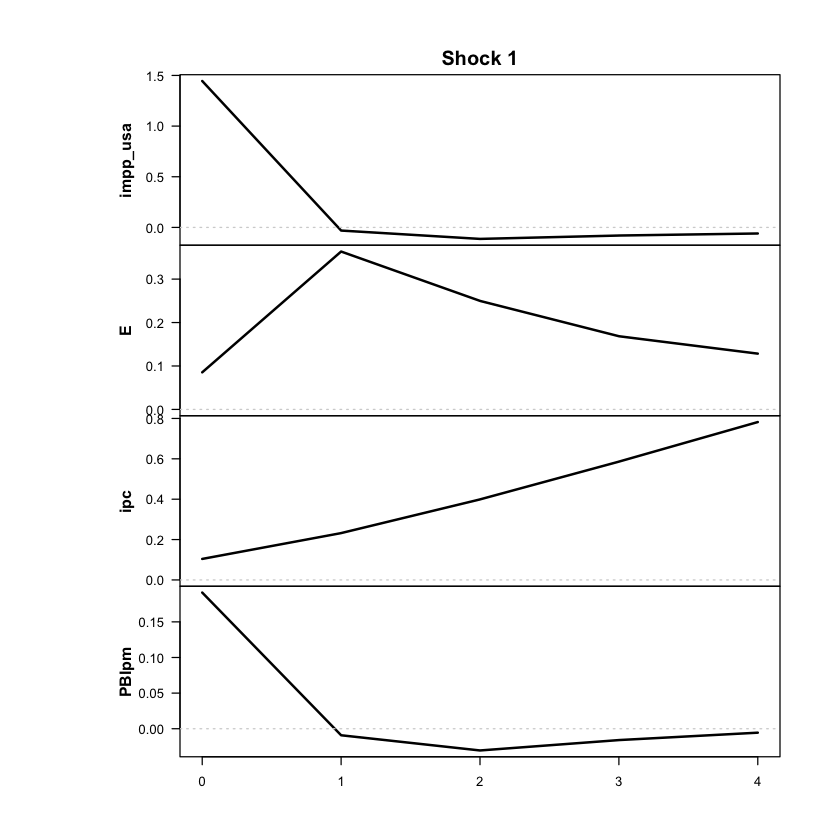

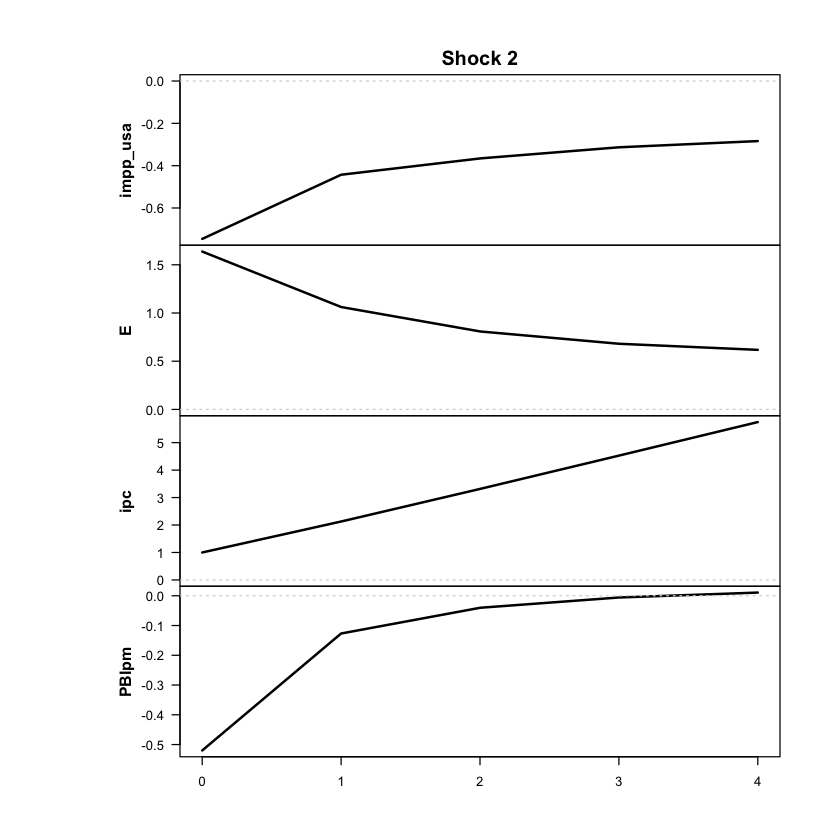

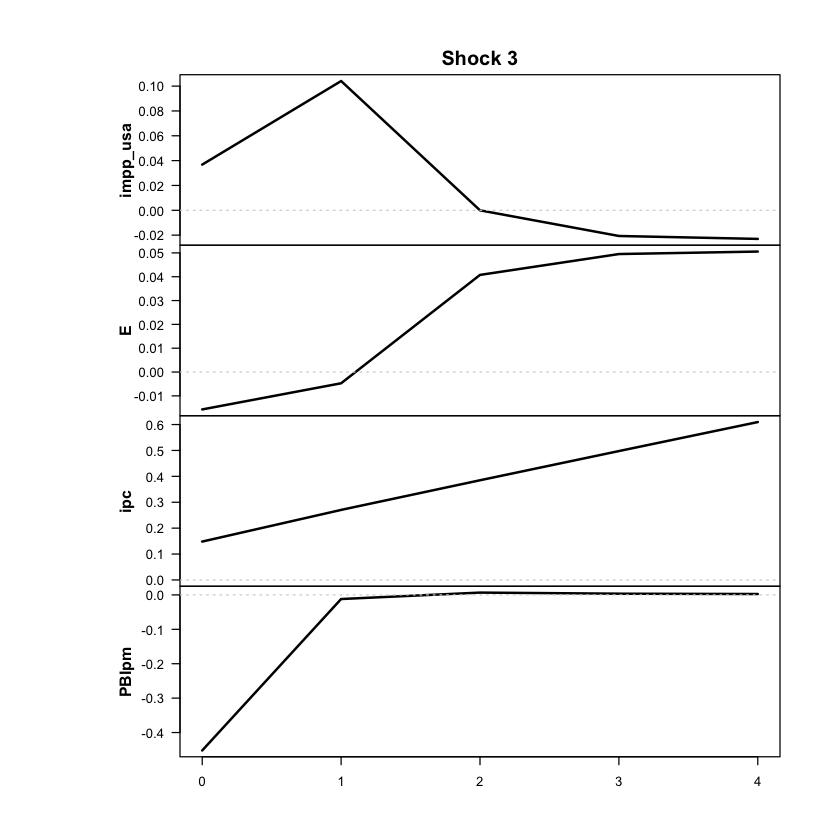

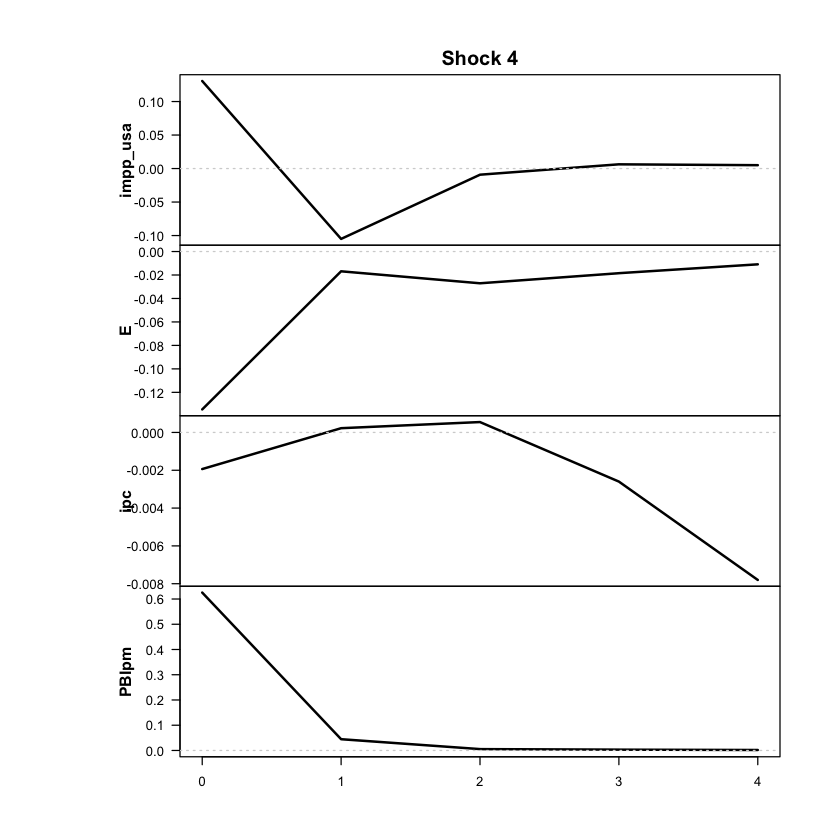

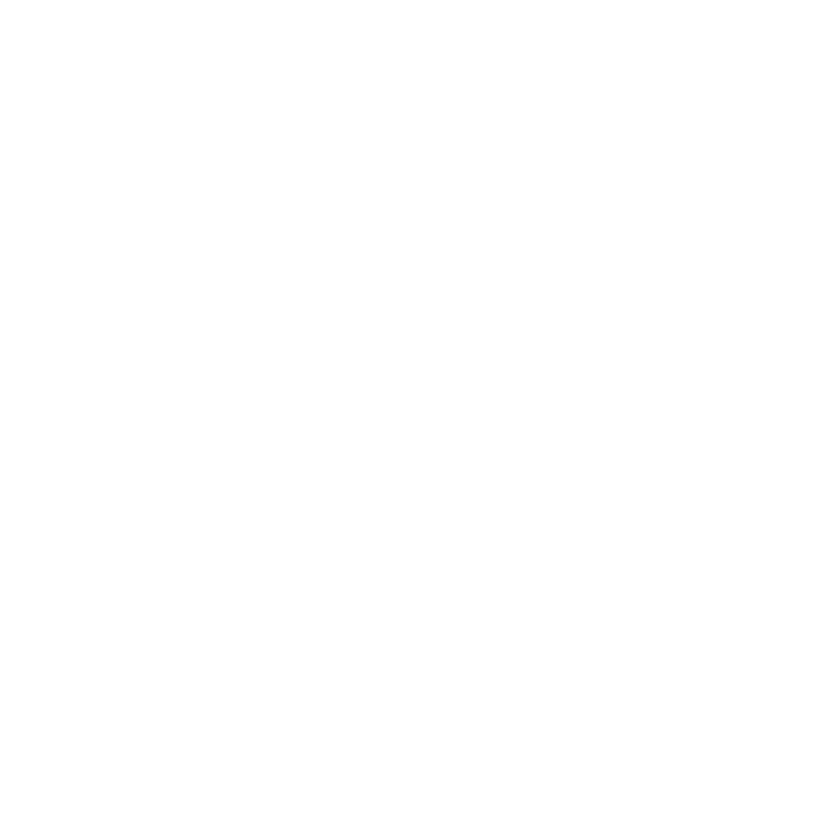

In [94]:
res <- run_vlstar (
  data = df_anual_ferr,
  endog = c("impp_usa","E","ipc","PBIpm"),
  periodicity = 'anual', # 'trimestral' o 'anual'
  feature_lag = 1,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","PBIpm")
  run_tests = FALSE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = 4, # 4 años, igual que las LP anuales (en anual, NULL serían solo 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE,
  cond_dist = "Student"   # errores t de Student
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [95]:
ic_vlstar_t_p1 <- criterios_info(res, "VLSTAR-t p=1")
print(ic_vlstar_t_p1)
saveRDS(ic_vlstar_t_p1, "ic_vlstar_t_p1_anual_ferr.rds")

        modelo regimenes parametros loglik   AIC    HQ   BIC
1 VLSTAR-t p=1         2         63 -283.9 693.8 756.4 849.1


In [97]:
# Control: qué modelo está en res
print(c(tipo = res$tvar_model$model$weight_function, p = res$tvar_model$model$p,
        errores = res$tvar_model$model$cond_dist))

resumen_modelo(res, data = df_anual_ferr, endog = c("impp_usa", "E", "ipc", "PBIpm"))
explorar_optimos(res, n = 20)

      tipo          p    errores 
"logistic"        "1"  "Student" 
Modelo: logistic | regímenes: 2 | rezagos: 1 | errores: Student 
Grados de libertad de la t de Student: 3.02 
Umbral (c): 102.4% anual | gamma: 0 
Años por régimen (régimen de mayor peso): régimen 1 = 71 | régimen 2 = 16 

Promedio observado de cada variable en los años de cada régimen
(variación anual en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      3.53      4.39
E            25.70    224.98
ipc          24.36    298.02
PBIpm         2.66      1.85
umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -195.01              9

In [98]:
resumen_modelo(res, data = df_anual_ferr, endog = c("impp_usa", "E", "ipc", "PBIpm"))

Modelo: logistic | regímenes: 2 | rezagos: 1 | errores: Student 
Grados de libertad de la t de Student: 3.02 
Umbral (c): 102.4% anual | gamma: 0 
Años por régimen (régimen de mayor peso): régimen 1 = 71 | régimen 2 = 16 

Promedio observado de cada variable en los años de cada régimen
(variación anual en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      3.53      4.39
E            25.70    224.98
ipc          24.36    298.02
PBIpm         2.66      1.85


In [99]:
explorar_optimos(res, n = 20)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -195.01              92  3.99        2.3            70/17
             2 -195.35            93.9  4.76        3.1            70/17
             3 -196.19            81.3  4.81        2.9            69/18
             4 -201.70              59  7.05        2.8            67/20
             5 -204.26            79.3  5.40        2.9            69/18
             6 -206.82            95.3  2.74        2.5            70/17
             7 -208.44           127.7  2.88        2.4            73/14
             8 -211.01            98.4  3.33        2.7            70/17
             9 -211

In [100]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

logistic Student STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 1, M = 2, d = 4, #parameters = 63, #observations = 87 x 4
  Switching variable: ipc with lag 1.

Regime 1 
Degrees of freedom: 3.02 (for all regimes) 
Weight params: 1.13 (location), 0.00 (scale) 
Regime means: 0.40, 0.49, 0.57, 0.94

   Y      phi0          A1                              Omega                  
1 y1 = [ -0.17 ] + [  0.72 -0.05  0.31  0.14 ] y1.1 + [  0.20 -0.15 -0.02  0.43
2 y2   [  0.22 ]   [  0.04  0.17  0.26  0.02 ] y2.1   [ -0.15  0.24  0.08 -0.48
3 y3   [  0.04 ]   [  0.15  0.65  0.09  0.10 ] y3.1   [ -0.02  0.08  0.11 -0.20
4 y4   [  1.22 ]   [ -0.05 -0.32 -0.05 -0.07 ] y4.1   [  0.43 -0.48 -0.20  2.63
    1/2     
1 ]     eps1
2 ]     eps2
3 ]     eps3
4 ]     eps4

Regime 2 
Regime means:  1.16, -0.84, -2.17,  0.32

   Y      phi0          A1                              Omega                  
1 y1 = [  0.82 ] + [  0.03 -0.29 -0.06 -0.24 ] y1.1 + [  2.22 -0.14  0

In [101]:
shock_vlstar_t_p1 <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "PBIpm"))
# Confirmar que mueve mucho a E y poco a ipc; si no, poner el número a mano:
# shock_vlstar_t_p1 <- 2
shock_vlstar_t_p1

Efecto de impacto de cada shock  (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0212 -0.0129  0.0044  0.0233
  E         0.0104  0.2356 -0.0156 -0.1989
  ipc       0.0125  0.1416  0.1449 -0.0028
  PBIpm     0.0019 -0.0060 -0.0362  0.0746

Participación de E en el efecto de cada shock  :
shock_1 shock_2 shock_3 shock_4 
   0.06    0.77    0.03    0.21 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  1.200   0.601  -9.294   0.014 

>>> Shock sugerido como cambiario: 2 (confirmalo: debe mover mucho a E y poco a ipc )


[1] 2

### ERPT — VLSTAR t, p = 1

Correr solo si el modelo pasó el diagnóstico. **No pasó: todos los óptimos tienen `descartar = TRUE`. No usar este ERPT ni graficarlo.**

In [102]:
out_impp_usa_vlstar_t_p1 <- erpt_historia(res, data = df_anual_ferr, endog = c("impp_usa", "E", "ipc", "PBIpm"), shock_num = shock_vlstar_t_p1)

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 26.6%.

Estimando 87 GIRFs (una por año), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Años dominados por cada régimen (peso > 0.9): régimen 1 = 0 | régimen 2 = 0 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.9841

Promedio entre años:
  horizonte reg_bajo_original reg_alto_original
1         0               NaN               NaN
2         1               NaN               NaN
3         2               NaN               NaN
4         3               NaN               NaN
5         4               NaN               NaN

Mediana entre años (robusta a años con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0               NA               NA
2         1               NA               NA
3         2               NA               NA
4         3               NA               NA
5         4               NA               NA


In [103]:
out_impp_usa_vlstar_t_p1_acum <- erpt_historia(res, data = df_anual_ferr, endog = c("impp_usa", "E", "ipc", "PBIpm"), shock_num = shock_vlstar_t_p1,
                      definicion = "acumulado")

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 26.6%.



Estimando 87 GIRFs (una por año), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Años dominados por cada régimen (peso > 0.9): régimen 1 = 0 | régimen 2 = 0 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.9841

Promedio entre años:
  horizonte reg_bajo_original reg_alto_original
1         0               NaN               NaN
2         1               NaN               NaN
3         2               NaN               NaN
4         3               NaN               NaN
5         4               NaN               NaN

Mediana entre años (robusta a años con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0               NA               NA
2         1               NA               NA
3         2               NA               NA
4         3               NA               NA
5         4               NA               NA


Parámetros usados -> c (escalado): 1.13 | gamma: 0 
(deben coincidir con 'Weight params' de print(modelo); si no, pasalos a mano)
Umbral en unidades originales: 0.7049 | franja 10%-90%: -1650.53 a 1651.94 


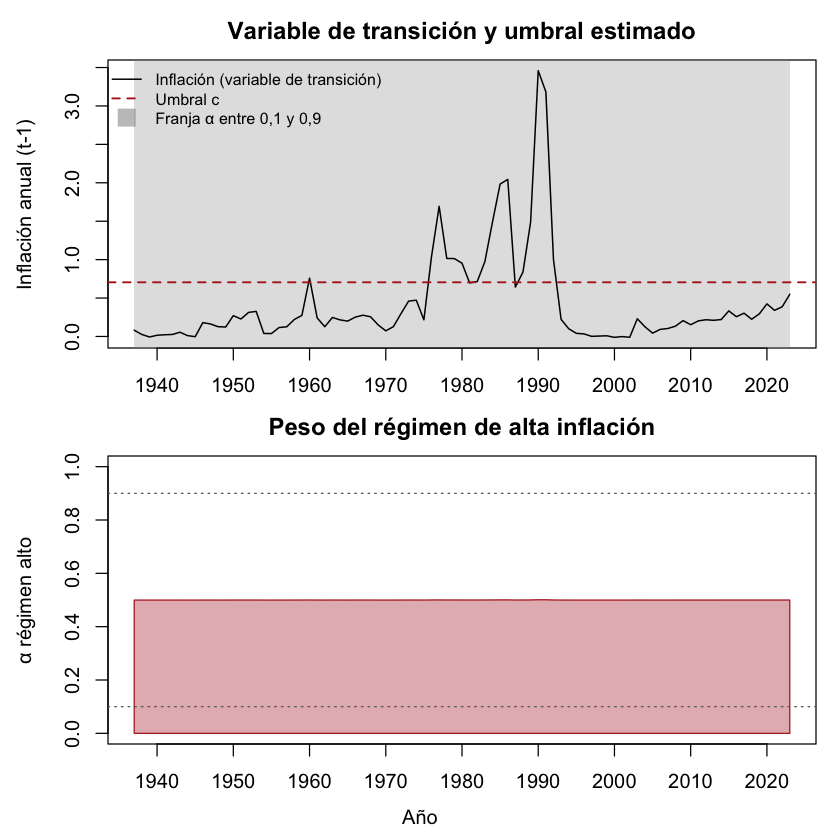

In [104]:
graficar_transicion(res, data = df_anual_ferr, endog = c("impp_usa", "E", "ipc", "PBIpm"),
                    archivo = paste0(carpeta, "transicion_impp_usa_vlstar_t_p1_anual_ferr"))

### VLSTAR con errores t, p = 2

Desvíos usados para escalar:
  impp_usa          E        ipc      PBIpm 
0.07653640 0.63532513 0.62520664 0.05122031 


Using 6 cores for 500 estimations rounds...

PHASE 1: Estimating all the parameters with a genetic algorithm...

Results from the genetic algorithm:

The lowest loglik:  -363.251

The largest loglik: -227.426

PHASE 2: Estimating all the parameters with a variable metric algorithm...

Results from the variable metric algorithm:

The lowest loglik:  -313.52

The largest loglik: -188.247

Filtering inappropriate estimates...

Filtered through 255 inappropriate  estimates with a larger log-likelihood

Calculating approximate standard errors...

Finished!




========= Unstructured fitted model ==========


Calculating approximate standard errors...



========= Structured fitted model (heteroskedasticity) ==========
Saving trained models to models/ folder

 >>> DIAGNOSTIC PLOTS


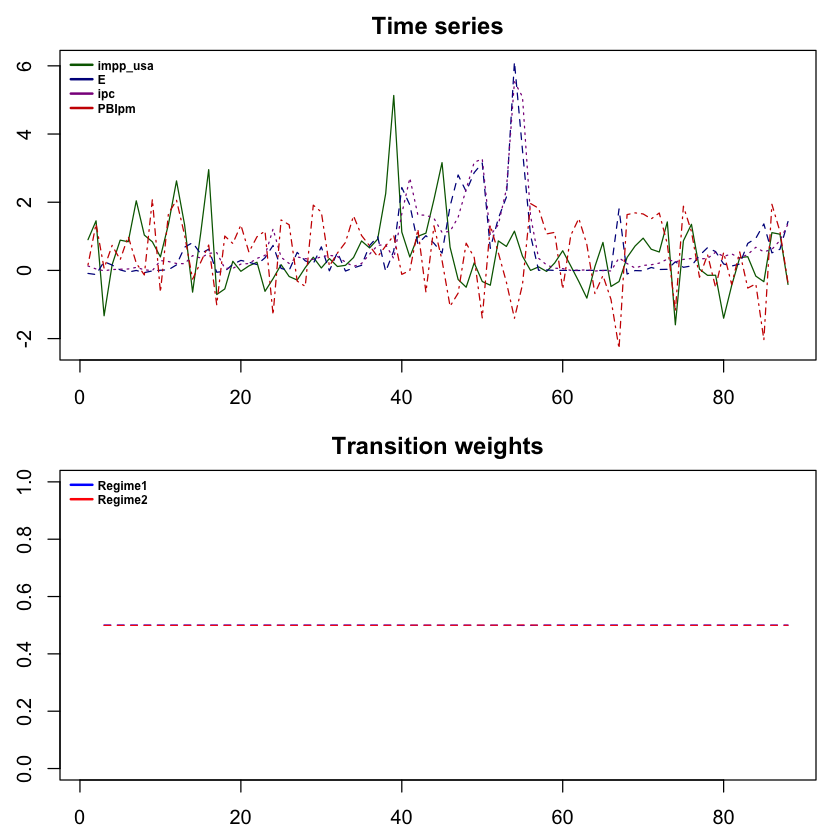

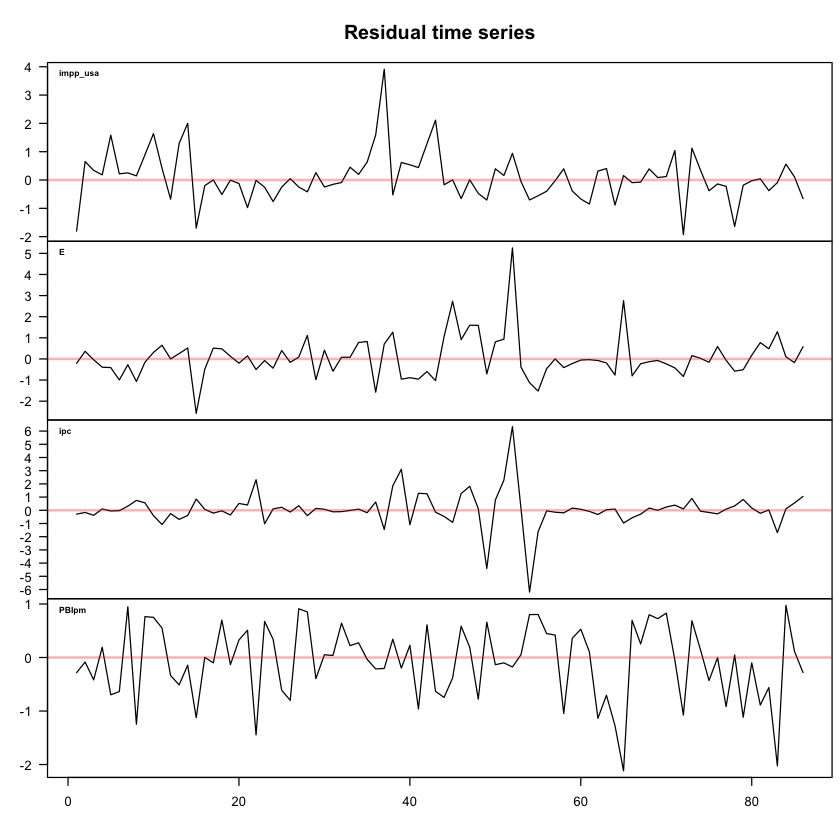

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



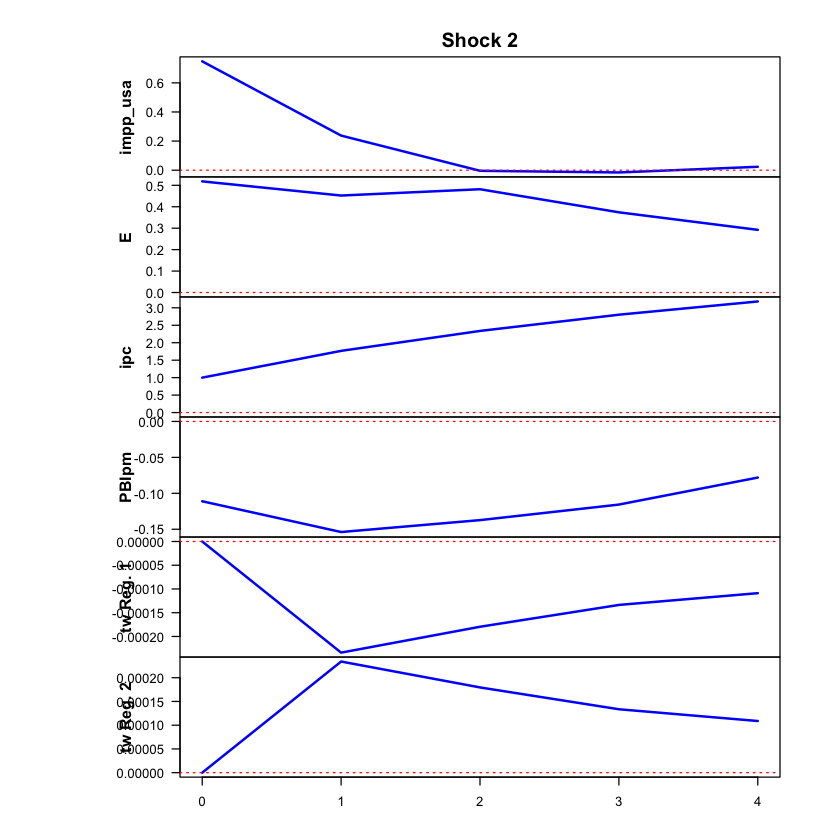

 >>> Linear IRF ( 1  shock units)


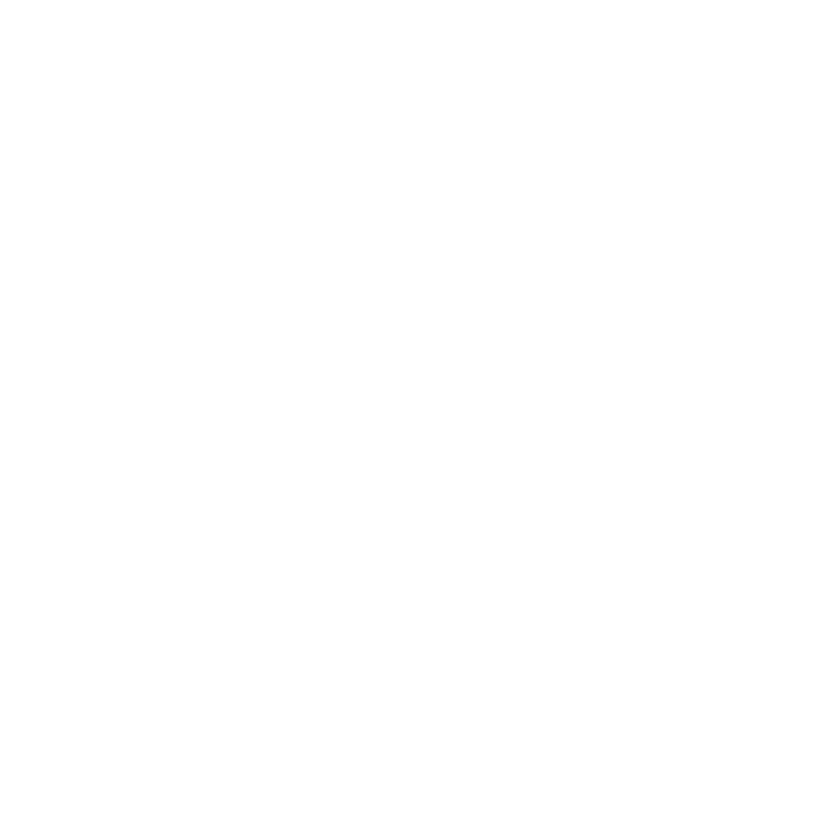

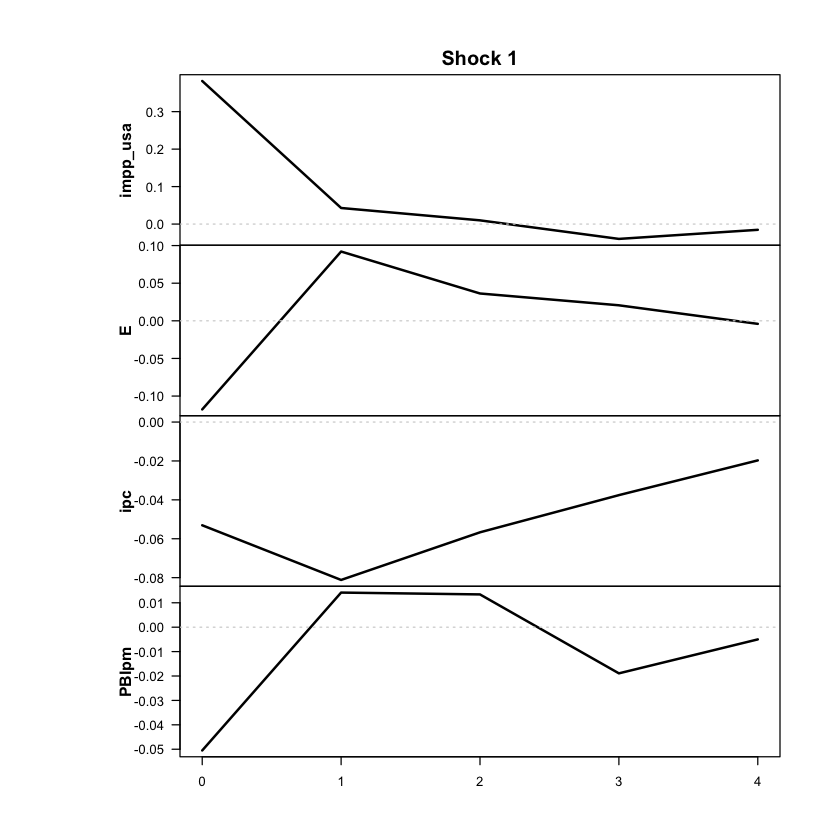

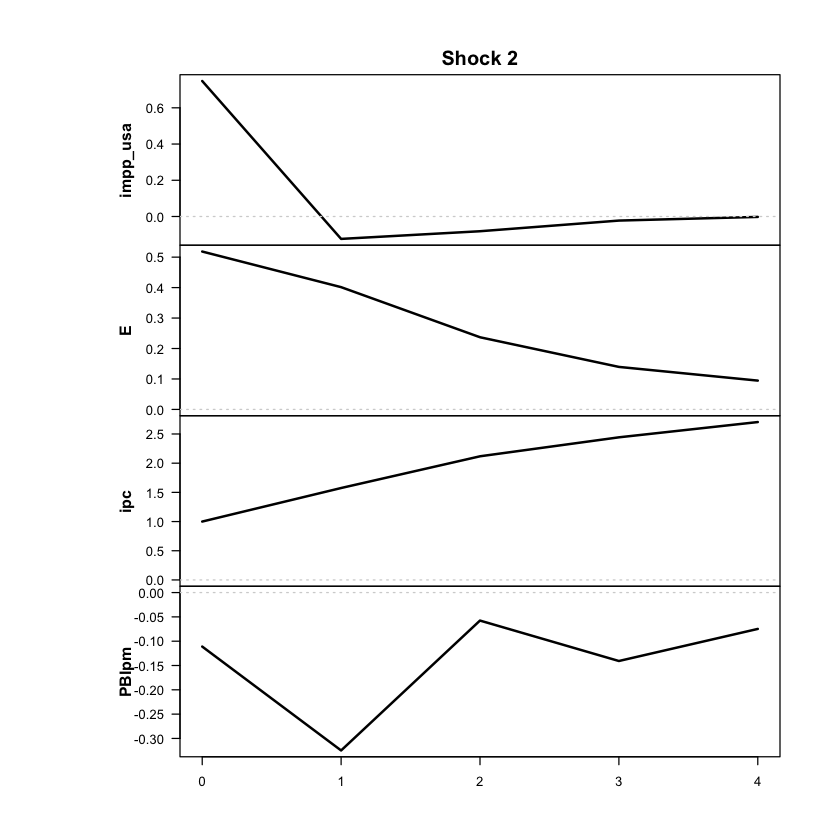

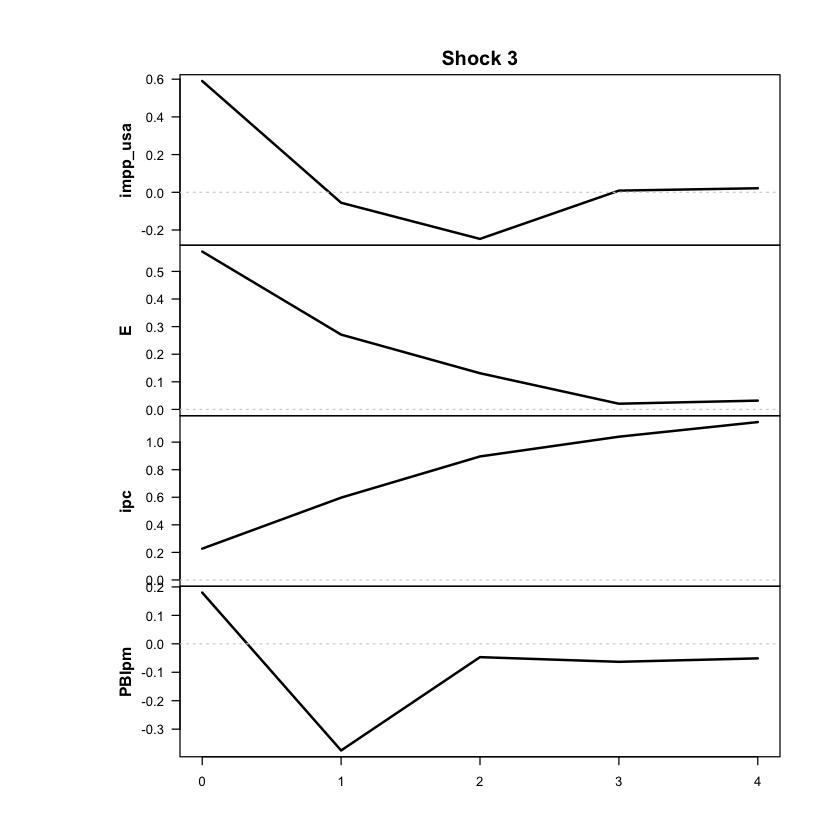

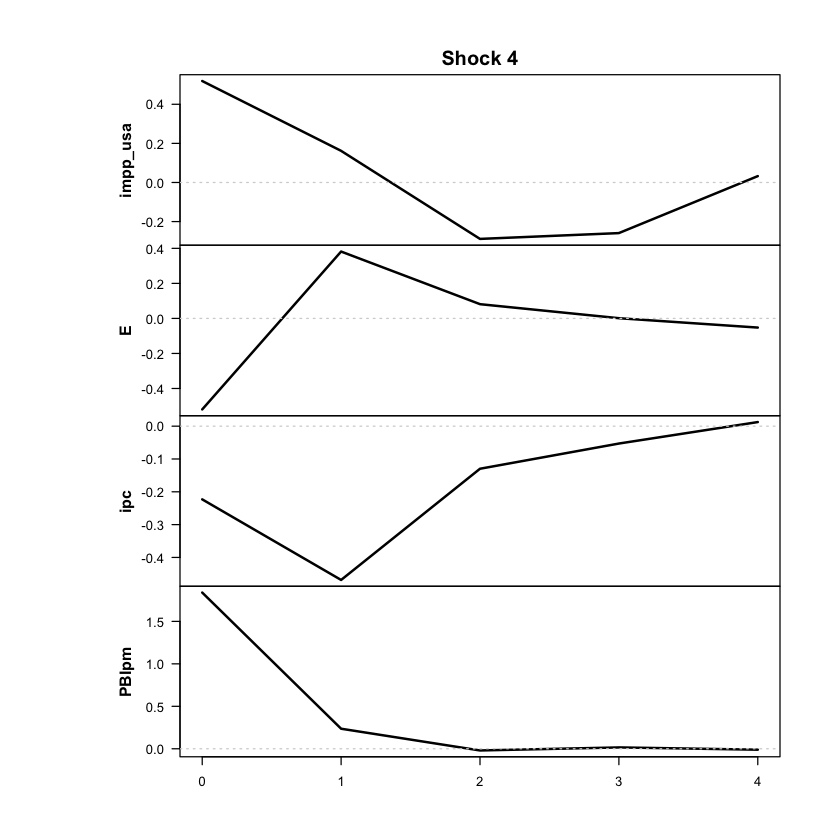

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



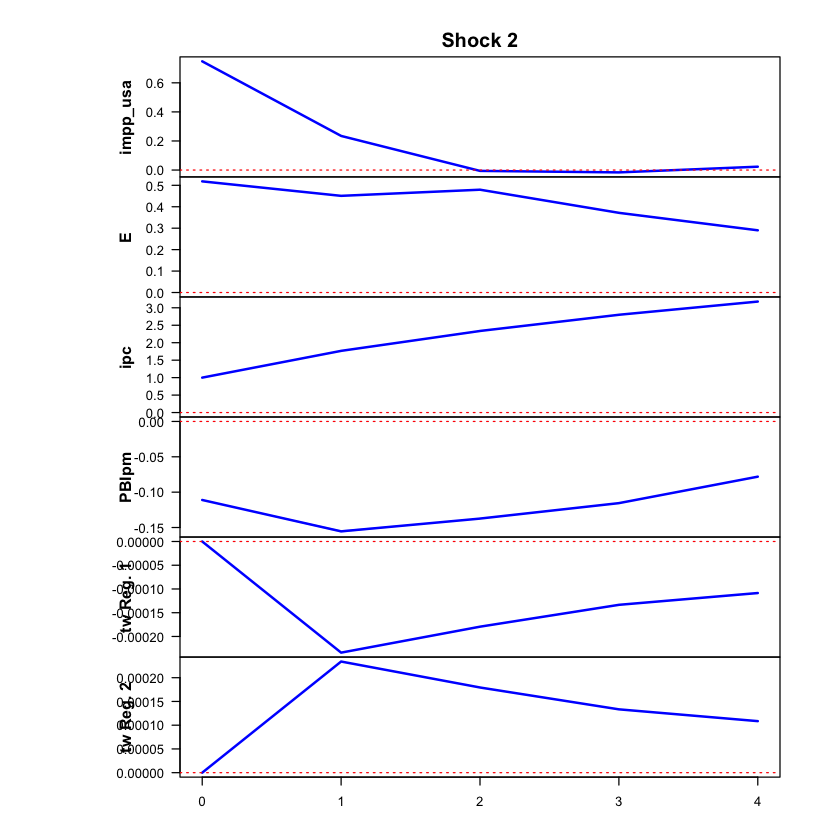

 >>> Linear IRF ( 1  shock units)


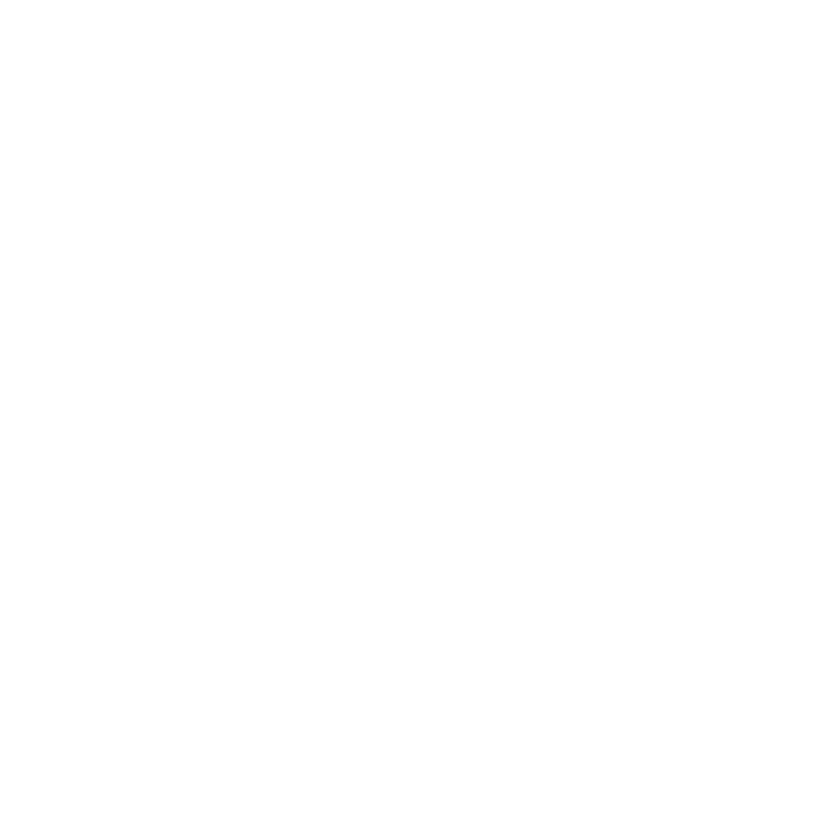

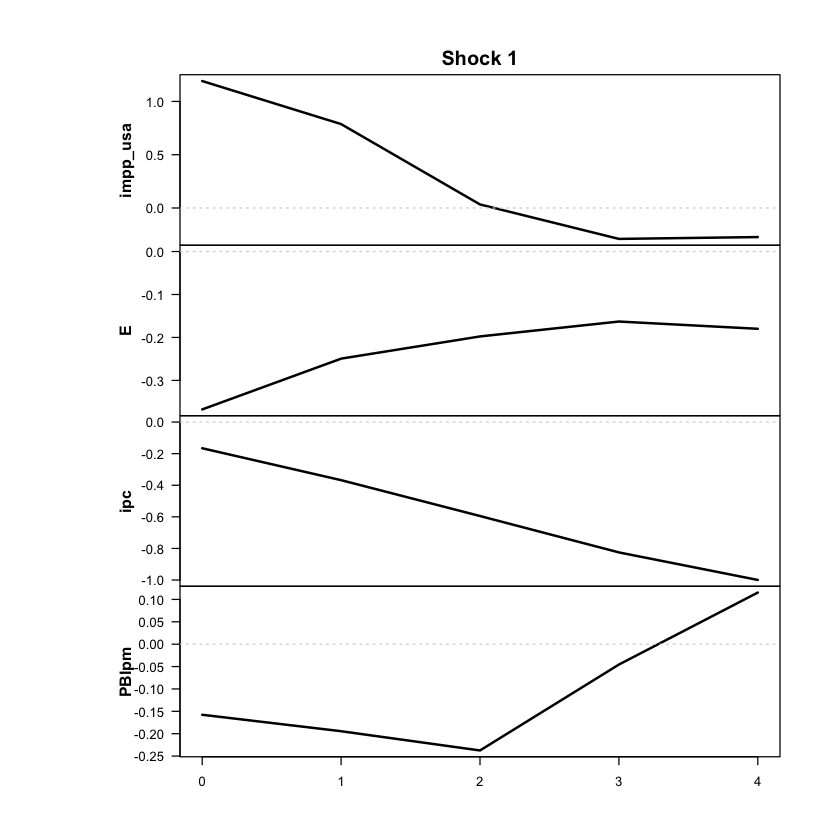

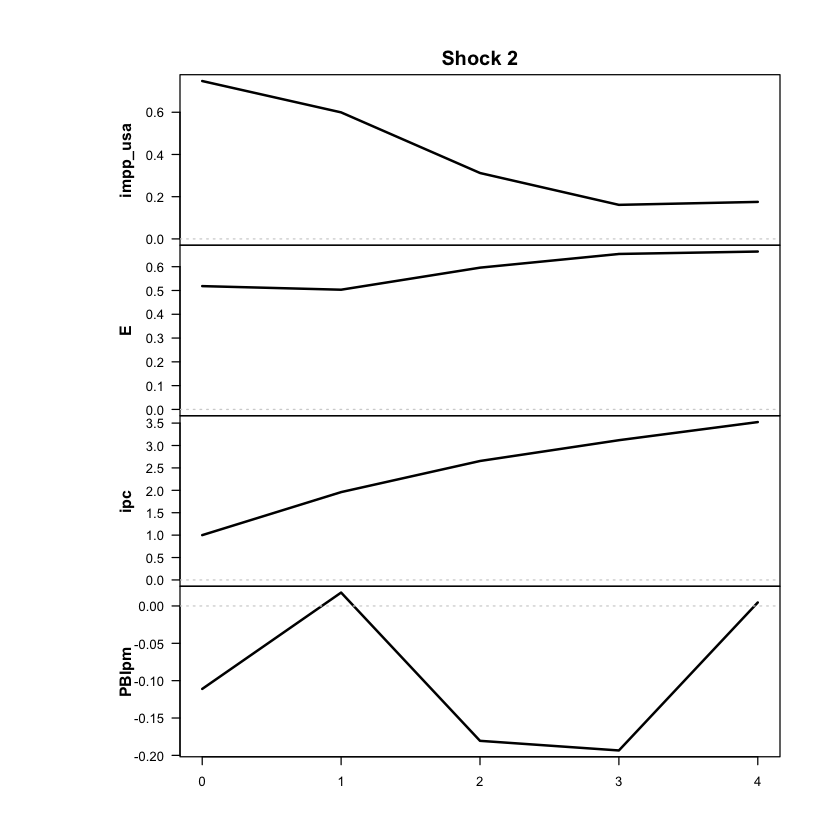

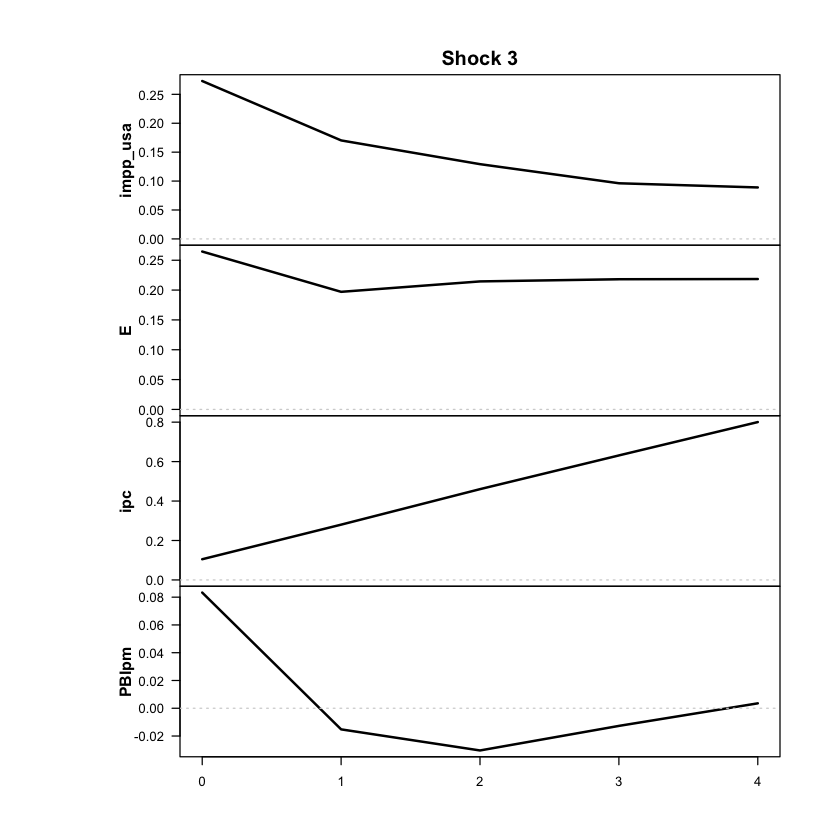

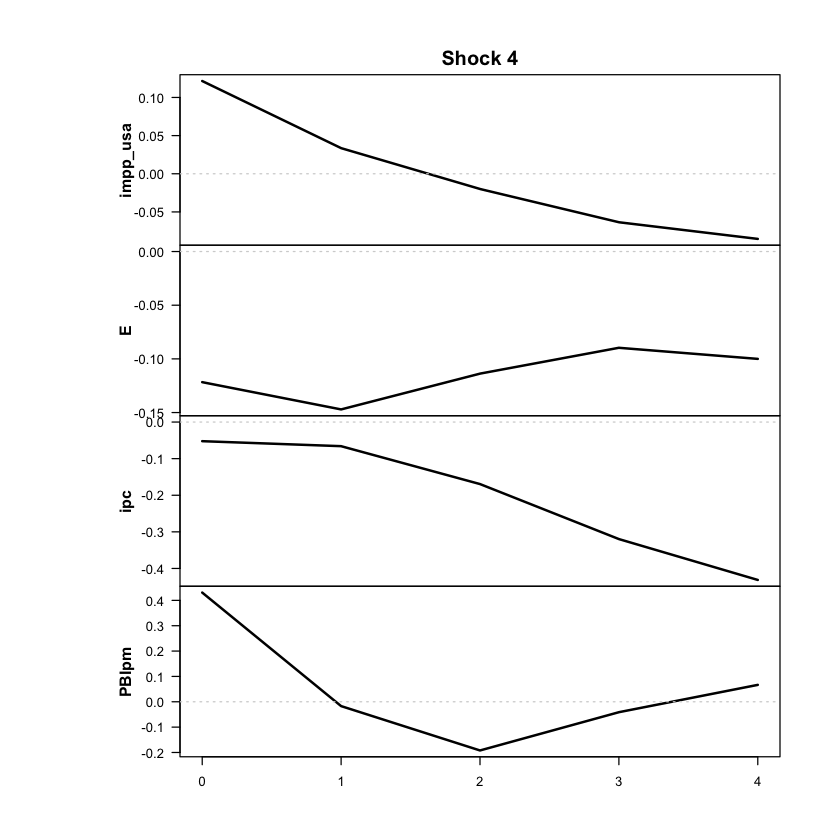

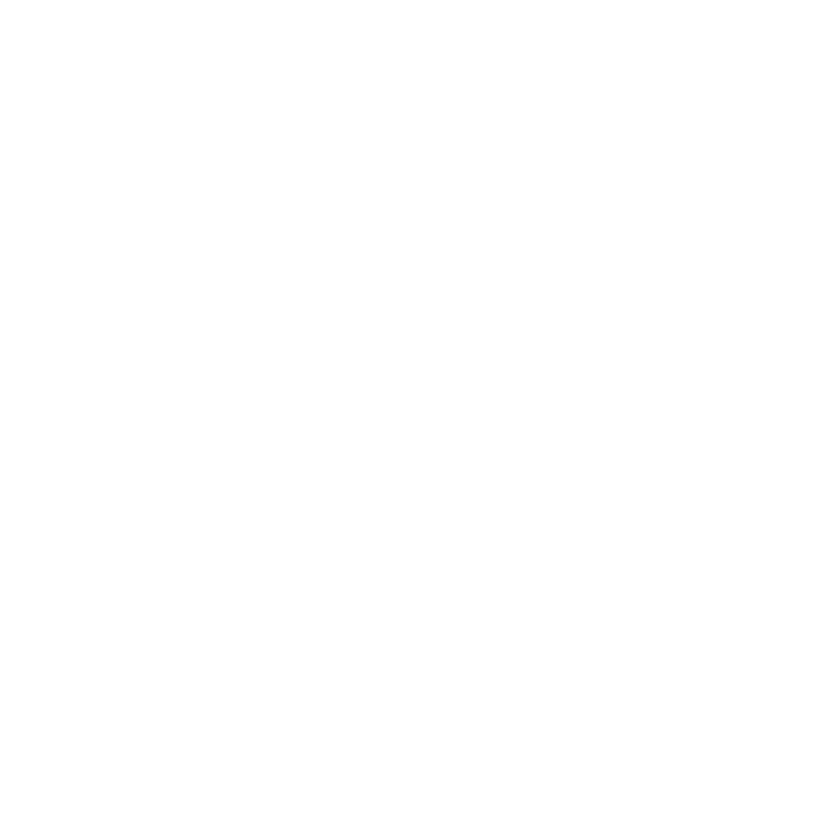

In [105]:
res <- run_vlstar (
  data = df_anual_ferr,
  endog = c("impp_usa","E","ipc","PBIpm"),
  periodicity = 'anual', # 'trimestral' o 'anual'
  feature_lag = 2,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","PBIpm")
  run_tests = FALSE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = 4, # 4 años, igual que las LP anuales (en anual, NULL serían solo 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE,
  cond_dist = "Student"   # errores t de Student
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [106]:
ic_vlstar_t_p2 <- criterios_info(res, "VLSTAR-t p=2")
print(ic_vlstar_t_p2)
saveRDS(ic_vlstar_t_p2, "ic_vlstar_t_p2_anual_ferr.rds")

        modelo regimenes parametros loglik   AIC    HQ BIC
1 VLSTAR-t p=2         2         95 -274.4 738.8 832.6 972


In [107]:
# Control: qué modelo está en res
print(c(tipo = res$tvar_model$model$weight_function, p = res$tvar_model$model$p,
        errores = res$tvar_model$model$cond_dist))

resumen_modelo(res, data = df_anual_ferr, endog = c("impp_usa", "E", "ipc", "PBIpm"))
explorar_optimos(res, n = 20)

      tipo          p    errores 
"logistic"        "2"  "Student" 
Modelo: logistic | regímenes: 2 | rezagos: 2 | errores: Student 
Grados de libertad de la t de Student: 2.99 
Umbral (c): 269.9% anual | gamma: 0 
Años por régimen (régimen de mayor peso): régimen 1 = 79 | régimen 2 = 7 

Promedio observado de cada variable en los años de cada régimen
(variación anual en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      3.72      2.25
E            34.92    417.70
ipc          35.89    571.24
PBIpm         2.57      1.22
umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -188.25            44.8

In [109]:
resumen_modelo(res, data = df_anual_ferr, endog = c("impp_usa", "E", "ipc", "PBIpm"))

Modelo: logistic | regímenes: 2 | rezagos: 2 | errores: Student 
Grados de libertad de la t de Student: 2.99 
Umbral (c): 269.9% anual | gamma: 0 
Años por régimen (régimen de mayor peso): régimen 1 = 79 | régimen 2 = 7 

Promedio observado de cada variable en los años de cada régimen
(variación anual en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      3.72      2.25
E            34.92    417.70
ipc          35.89    571.24
PBIpm         2.57      1.22


In [110]:
explorar_optimos(res, n = 20)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -188.25            44.8  6.09        2.4            63/23
             2 -194.72             136  3.50        2.5            73/13
             3 -206.04            66.5  3.21        3.1            67/19
             4 -207.73            67.7  3.22        2.6            67/19
             5 -208.78              85  3.99        3.0            68/18
             6 -209.10            67.5  1.88        2.6            67/19
             7 -211.70            30.5  2.29        2.6            53/33
             8 -212.77            55.1  3.01        3.5            65/21
             9 -213

In [111]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

logistic Student STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 2, M = 2, d = 4, #parameters = 95, #observations = 86 x 4
  Switching variable: ipc with lag 1.

Regime 1 
Degrees of freedom: 2.99 (for all regimes) 
Weight params: 2.09 (location), 0.00 (scale) 
Regime means: -0.23,  0.45,  0.76,  1.21

   Y     phi0          A1                                 A2                  
1 y1 = [ 0.10 ] + [  0.06 -0.13 -0.10  0.02 ] y1.1 + [ -0.04 -0.26  0.18 -0.19
2 y2   [ 0.07 ]   [  0.30  0.05  0.17  0.16 ] y2.1   [  0.10  0.08  0.09  0.02
3 y3   [ 0.04 ]   [  0.10  0.44  0.27  0.00 ] y3.1   [  0.02 -0.01  0.23  0.14
4 y4   [ 1.35 ]   [ -0.12 -0.55  0.06  0.01 ] y4.1   [  0.18 -0.07  0.03  0.06
             Omega                     1/2     
1 ] y1.2 + [  0.82  0.06  0.07  1.03 ]     eps1
2 ] y2.2   [  0.06  0.64  0.30 -0.85 ]     eps2
3 ] y3.2   [  0.07  0.30  0.20 -0.38 ]     eps3
4 ] y4.2   [  1.03 -0.85 -0.38  3.42 ]     eps4

Regime 2 
Regime means:  -4.

In [112]:
shock_vlstar_t_p2 <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "PBIpm"))
# Confirmar que mueve mucho a E y poco a ipc; si no, poner el número a mano:
# shock_vlstar_t_p2 <- 2
shock_vlstar_t_p2

Efecto de impacto de cada shock  (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0292  0.0176  0.0452  0.0397
  E        -0.0748  0.1011  0.3634 -0.3301
  ipc      -0.0332  0.1920  0.1419 -0.1394
  PBIpm    -0.0026 -0.0017  0.0092  0.0942

Participación de E en el efecto de cada shock  :
shock_1 shock_2 shock_3 shock_4 
   0.29    0.38    0.66    0.26 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  0.443   1.898   0.390   0.422 

>>> Shock sugerido como cambiario: 3 (confirmalo: debe mover mucho a E y poco a ipc )


[1] 3

### ERPT — VLSTAR t, p = 2

Correr solo si el modelo pasó el diagnóstico. **No pasó: todos los óptimos tienen `descartar = TRUE`. No usar este ERPT ni graficarlo.**

In [113]:
out_impp_usa_vlstar_t_p2 <- erpt_historia(res, data = df_anual_ferr, endog = c("impp_usa", "E", "ipc", "PBIpm"), shock_num = shock_vlstar_t_p2)

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 43.8%.

Estimando 86 GIRFs (una por año), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 3...

Finished!




Años dominados por cada régimen (peso > 0.9): régimen 1 = 0 | régimen 2 = 0 
Shock usado:3| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.9841

Promedio entre años:
  horizonte reg_bajo_original reg_alto_original
1         0               NaN               NaN
2         1               NaN               NaN
3         2               NaN               NaN
4         3               NaN               NaN
5         4               NaN               NaN

Mediana entre años (robusta a años con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0               NA               NA
2         1               NA               NA
3         2               NA               NA
4         3               NA               NA
5         4               NA               NA


In [114]:
out_impp_usa_vlstar_t_p2_acum <- erpt_historia(res, data = df_anual_ferr, endog = c("impp_usa", "E", "ipc", "PBIpm"), shock_num = shock_vlstar_t_p2,
                      definicion = "acumulado")

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 43.8%.

Estimando 86 GIRFs (una por año), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 3...

Finished!




Años dominados por cada régimen (peso > 0.9): régimen 1 = 0 | régimen 2 = 0 
Shock usado:3| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.9841

Promedio entre años:
  horizonte reg_bajo_original reg_alto_original
1         0               NaN               NaN
2         1               NaN               NaN
3         2               NaN               NaN
4         3               NaN               NaN
5         4               NaN               NaN

Mediana entre años (robusta a años con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0               NA               NA
2         1               NA               NA
3         2               NA               NA
4         3               NA               NA
5         4               NA               NA


Parámetros usados -> c (escalado): 2.09 | gamma: 0 
(deben coincidir con 'Weight params' de print(modelo); si no, pasalos a mano)
Umbral en unidades originales: 1.3082 | franja 10%-90%: -1465.998 a 1468.614 


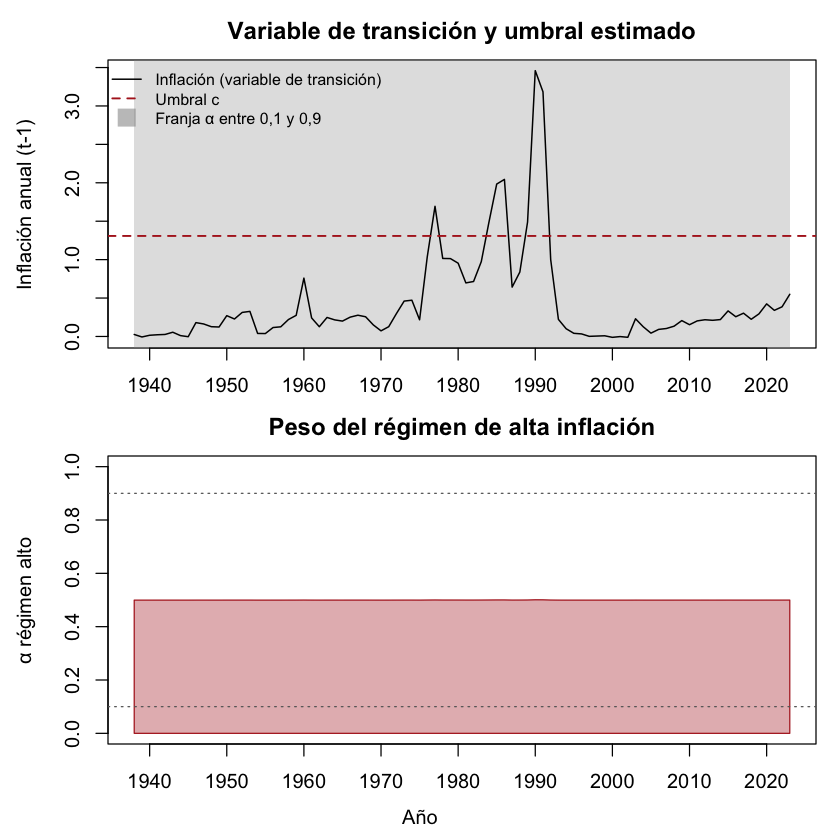

In [115]:
graficar_transicion(res, data = df_anual_ferr, endog = c("impp_usa", "E", "ipc", "PBIpm"),
                    archivo = paste0(carpeta, "transicion_impp_usa_vlstar_t_p2_anual_ferr"))

### Comparación: gaussiano vs. t de Student

In [116]:
rbind(ic_tvar_p1, ic_tvar_p2, ic_tvar_t_p1, ic_vlstar_t_p1, ic_vlstar_t_p2)

modelo,regimenes,parametros,loglik,AIC,HQ,BIC
<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
TVAR p=1,2,61,-239.53,601.1,661.6,751.5
TVAR p=2,2,93,-192.53,571.1,662.9,799.3
TVAR-t p=1,2,62,-210.78,545.6,607.1,698.5
VLSTAR-t p=1,2,63,-283.90,693.8,756.4,849.1
VLSTAR-t p=2,2,95,-274.40,738.8,832.6,972.0


## VLSTAR gaussiano, 2 regímenes, p = 1 — estimación en tres etapas

La estimación en tres etapas (`estim_method = "three-phase"`) empieza estimando los coeficientes por mínimos cuadrados y descarta los puntos de partida en los que algún régimen tiene muy pocas observaciones en relación con sus parámetros (`min_obs_coef`). Objetivo: evitar las soluciones degeneradas que aíslan los trimestres de hiperinflación. El modelo se guarda con `3fases_moc3` en el nombre del archivo; los modelos en dos etapas no se pisan.

Desvíos usados para escalar:
  impp_usa          E        ipc      PBIpm 
0.07653640 0.63532513 0.62520664 0.05122031 


Using 6 cores for 500 estimations rounds...

PHASE 1: Estimating the AR and weight parameters by nonlinear least squares for 10000 vectors of weight parameters...

PHASE 2: Estimating the error distribution parameters with a genetic algorithm...

Results from the genetic algorithm:

The lowest loglik:  -274.82

The largest loglik: -264.485

PHASE 3: Estimating all the parameters with a variable metric algorithm...

Results from the variable metric algorithm:

The lowest loglik:  -274.367

The largest loglik: -261.797

Filtering inappropriate estimates...

No 'appropriate'(or unstable)estimates found! Check that all the variables are scaled to vary in similar magninutes, also not very small or large magnitudes.

Consider running more estimation rounds or study the obtained estimates one-by-one with the function alt_stvar.

Unstable estimates were allowed in the estimation. Consider also using penalized estimation with a higher value
                 for the tuning parameter in 'penalty_

========= Unstructured fitted model ==========


Calculating approximate standard errors...



========= Structured fitted model (heteroskedasticity) ==========
Saving trained models to models/ folder

 >>> DIAGNOSTIC PLOTS


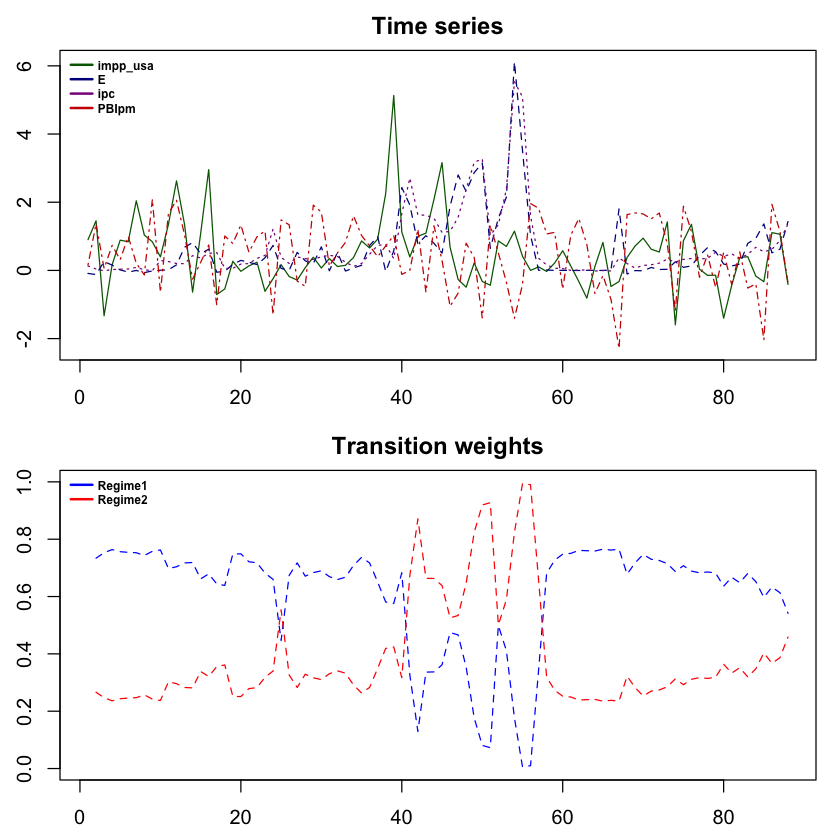

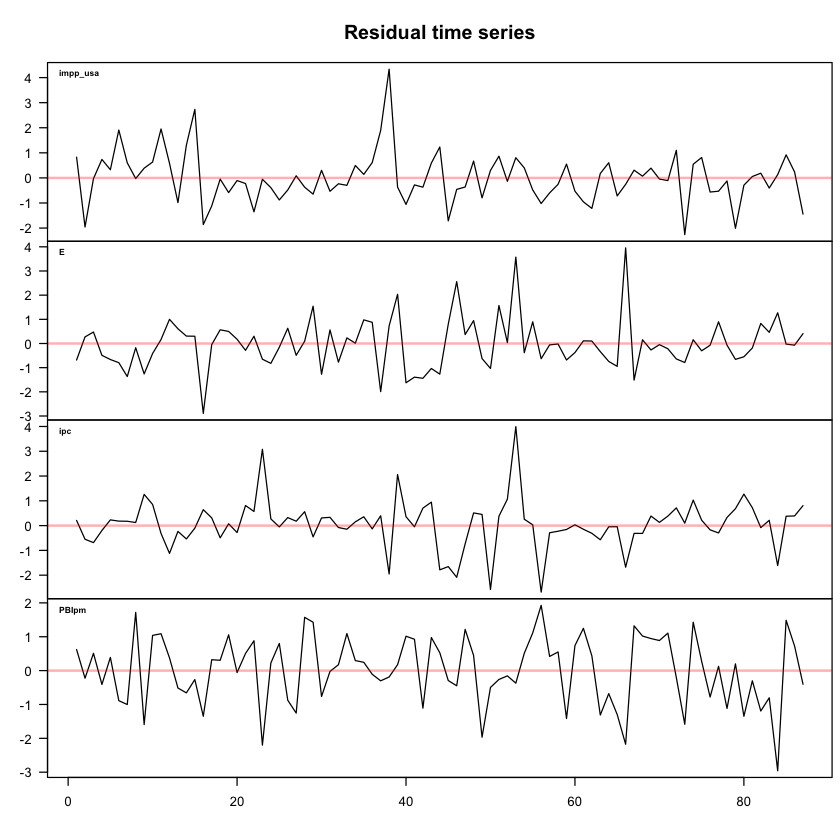

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



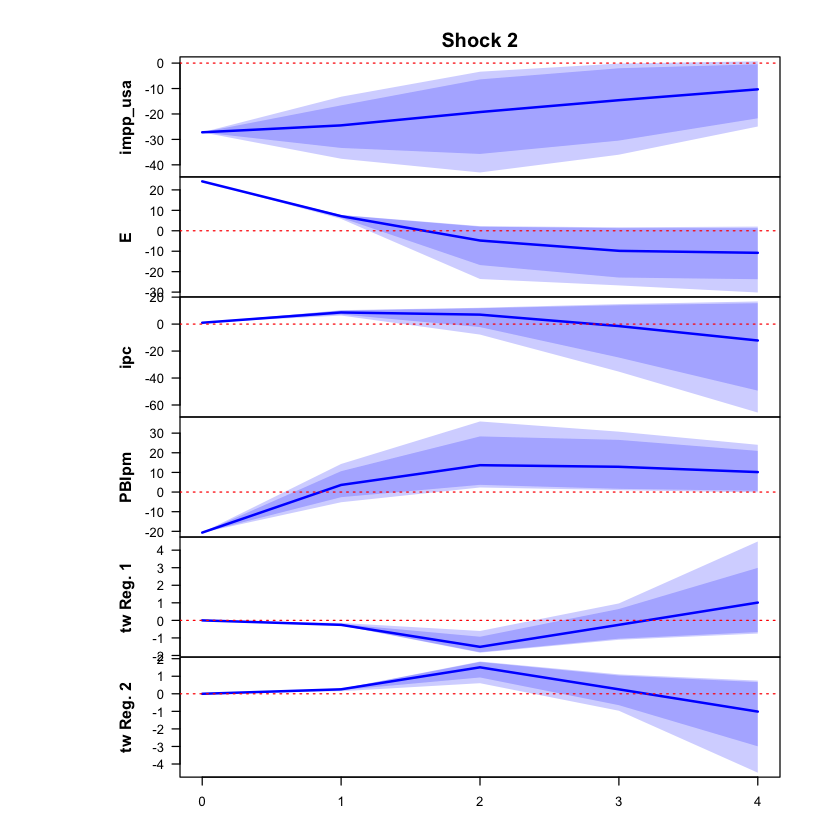

 >>> Linear IRF ( 1  shock units)


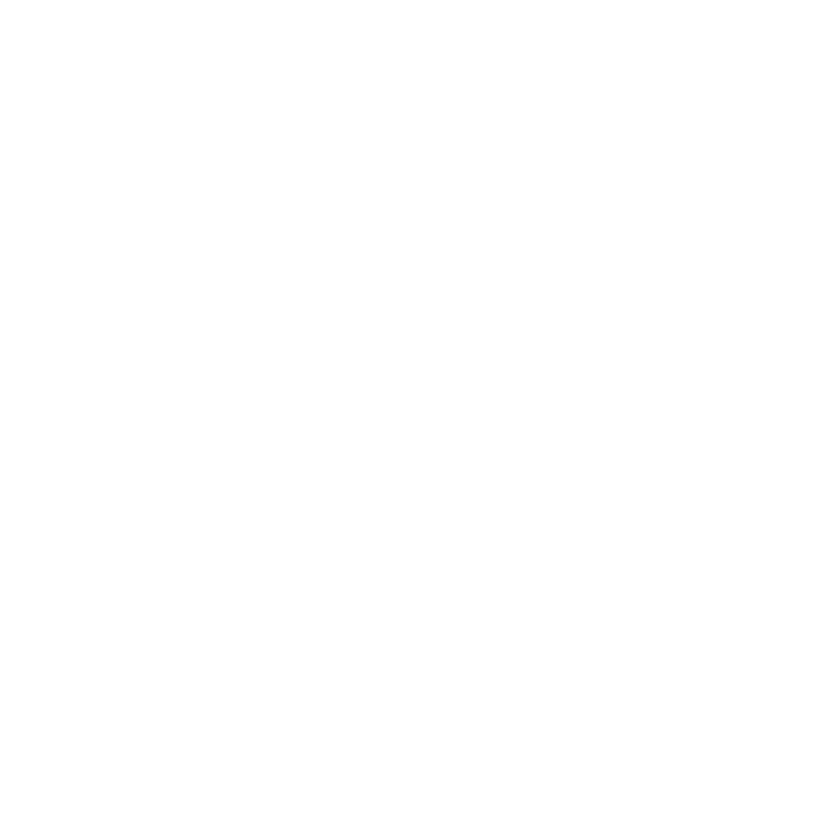

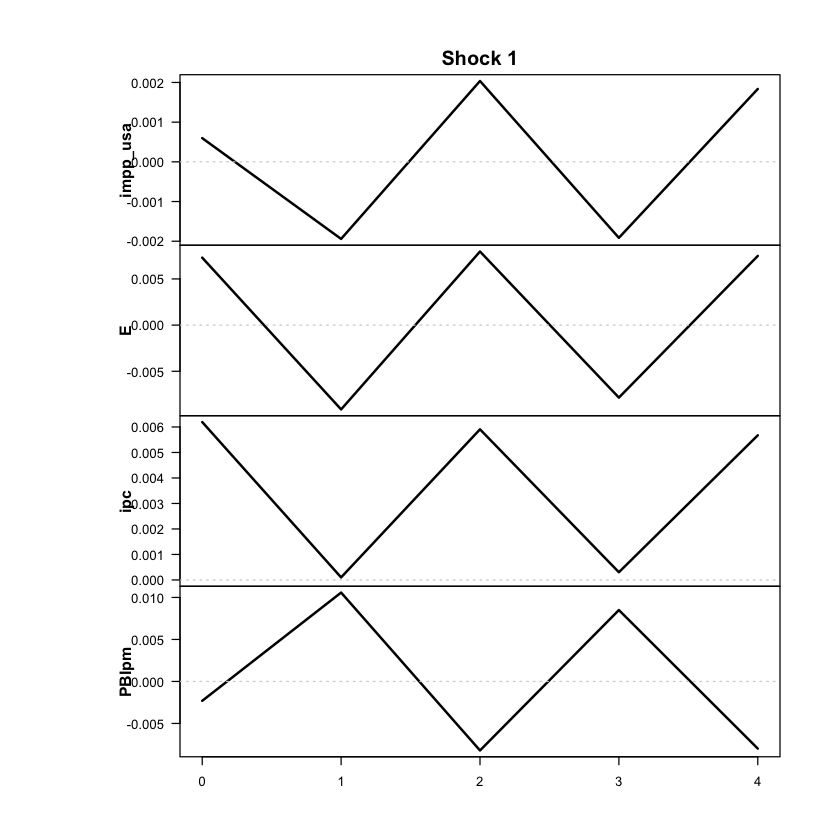

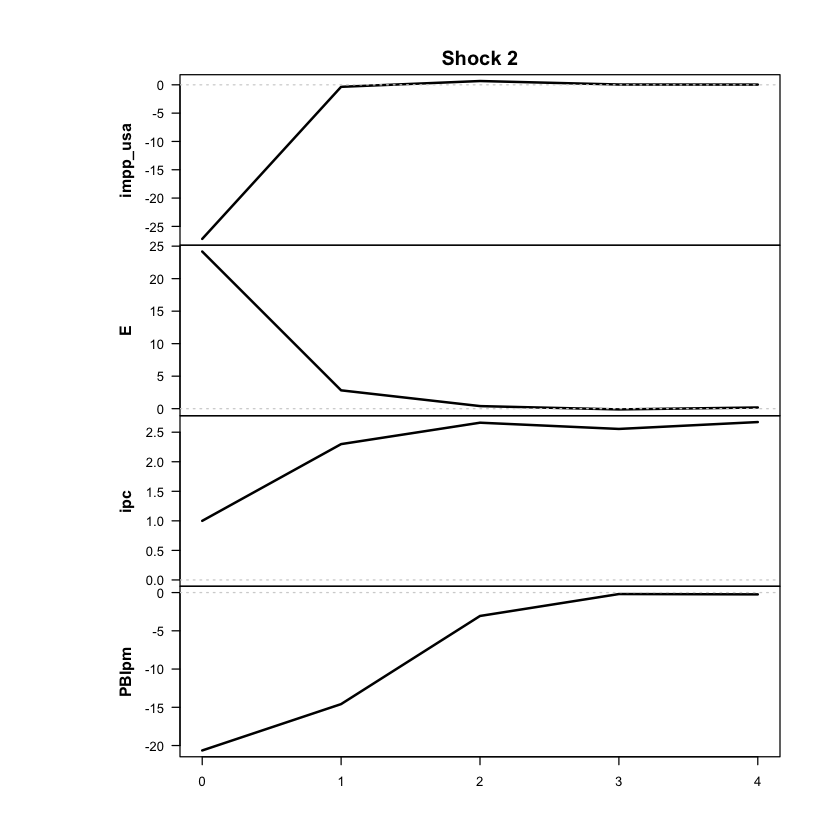

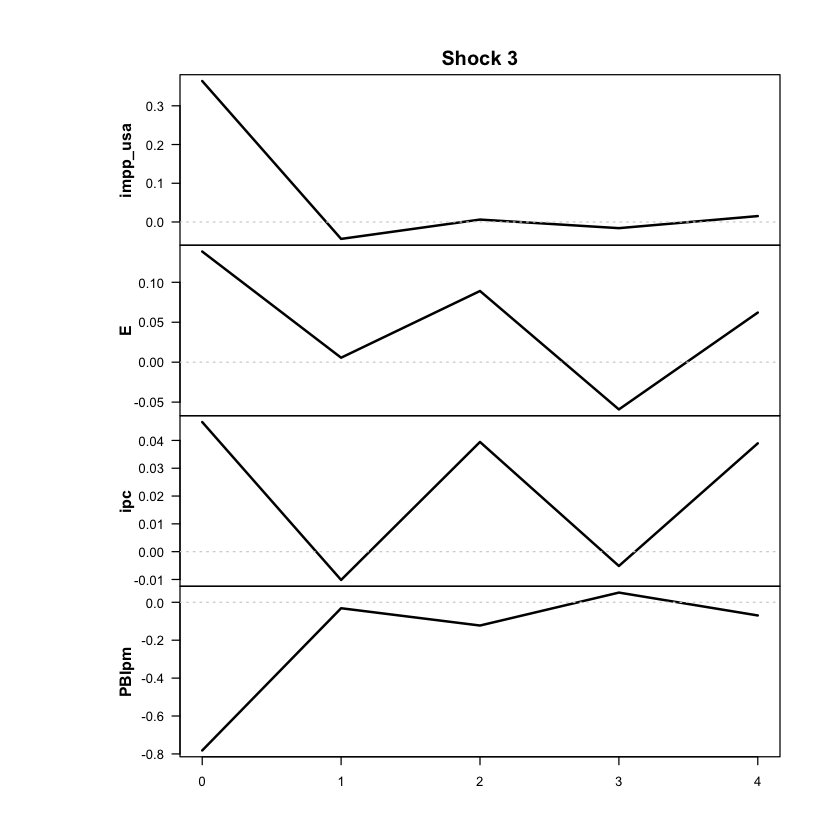

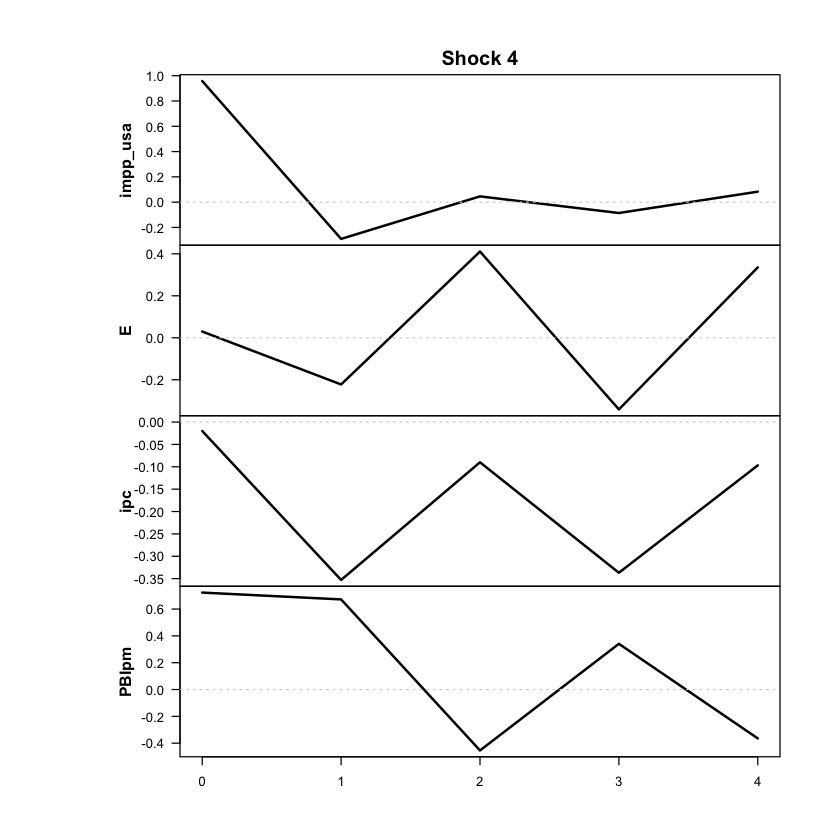

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



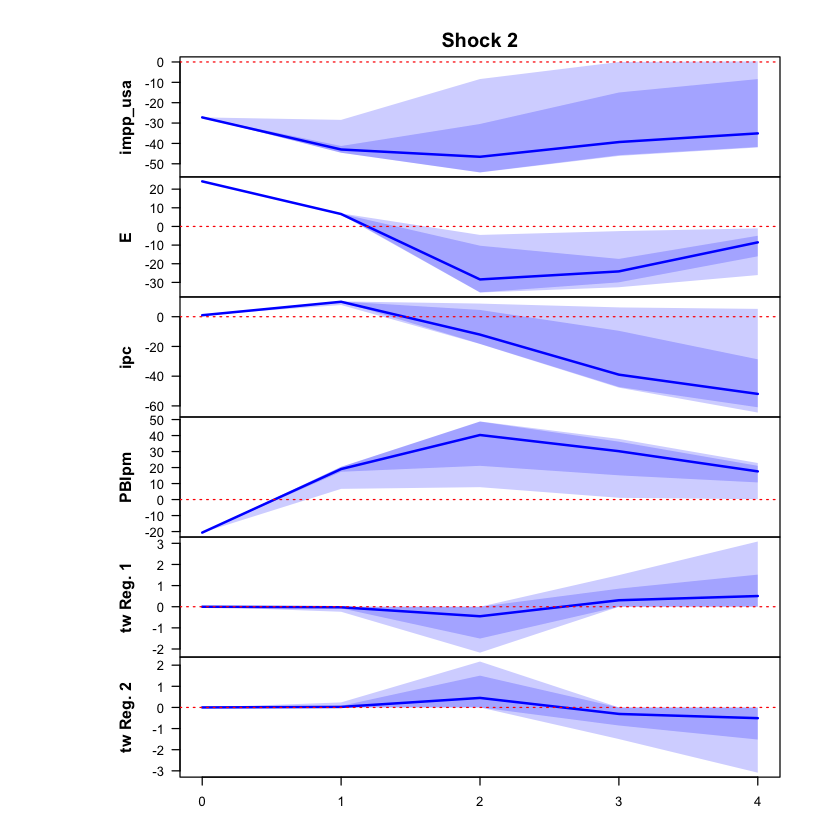

 >>> Linear IRF ( 1  shock units)


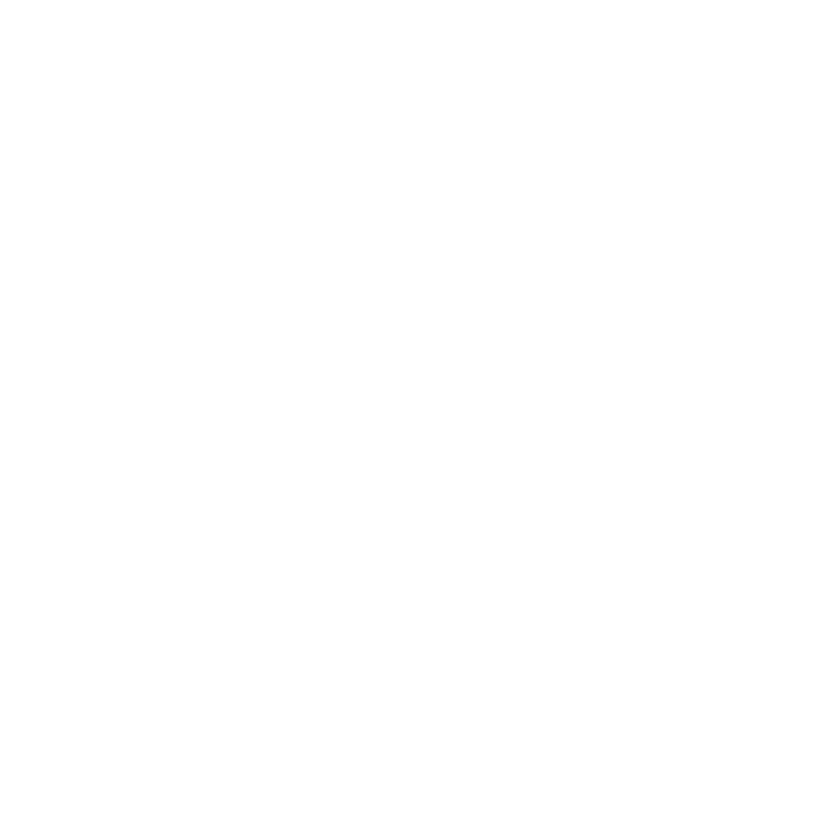

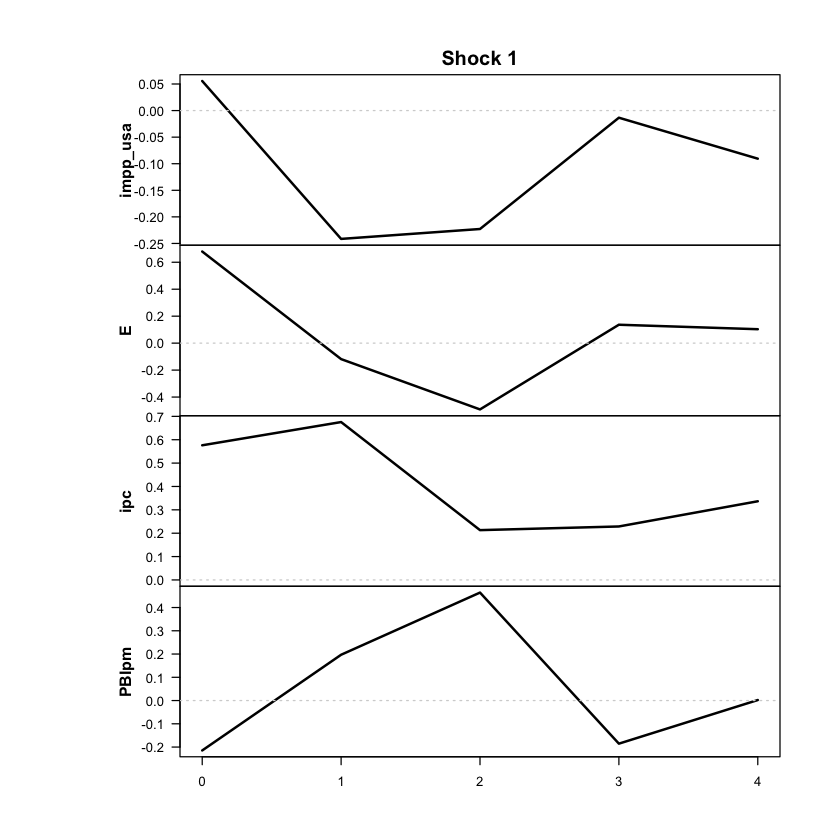

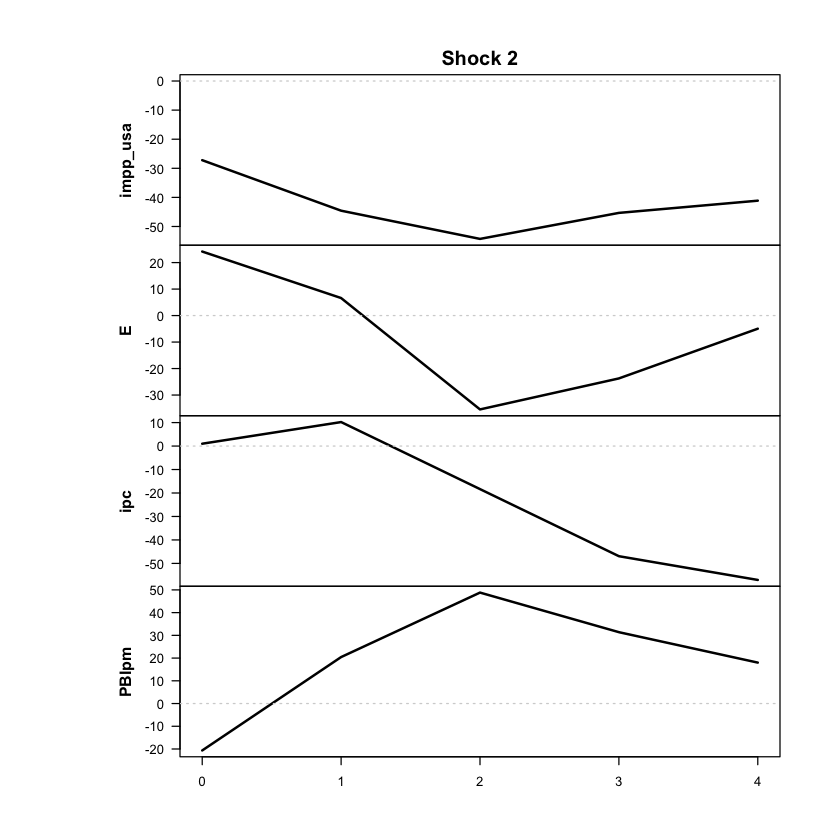

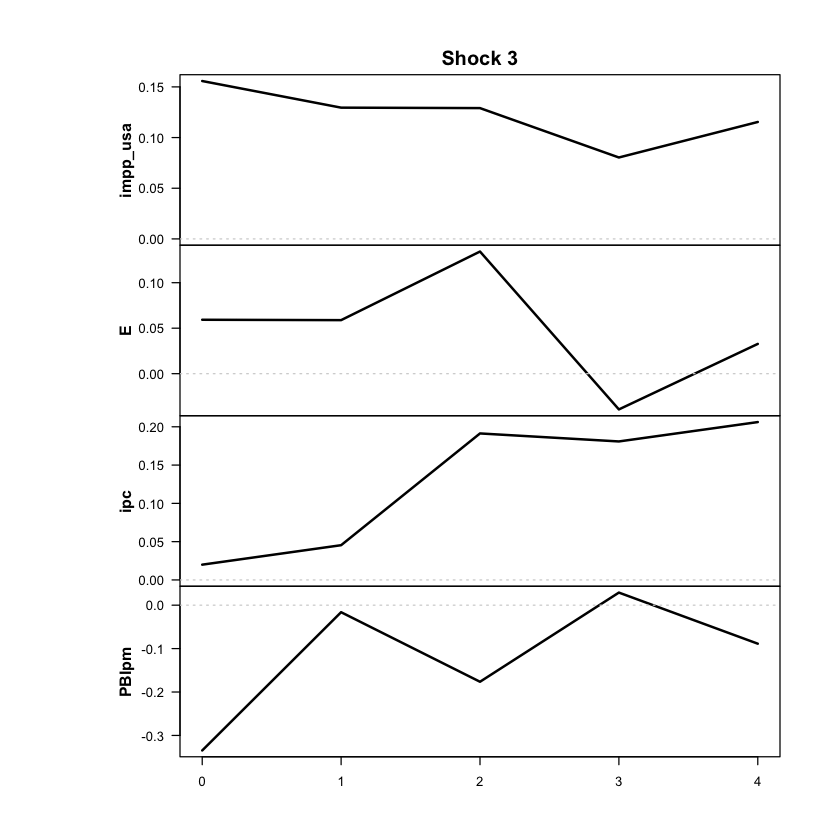

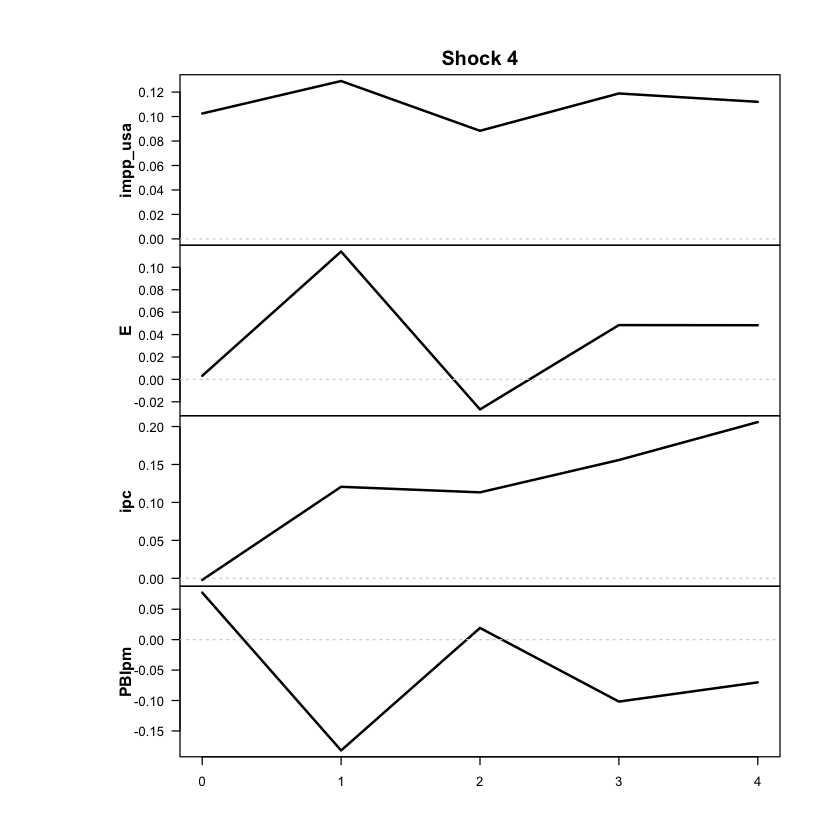

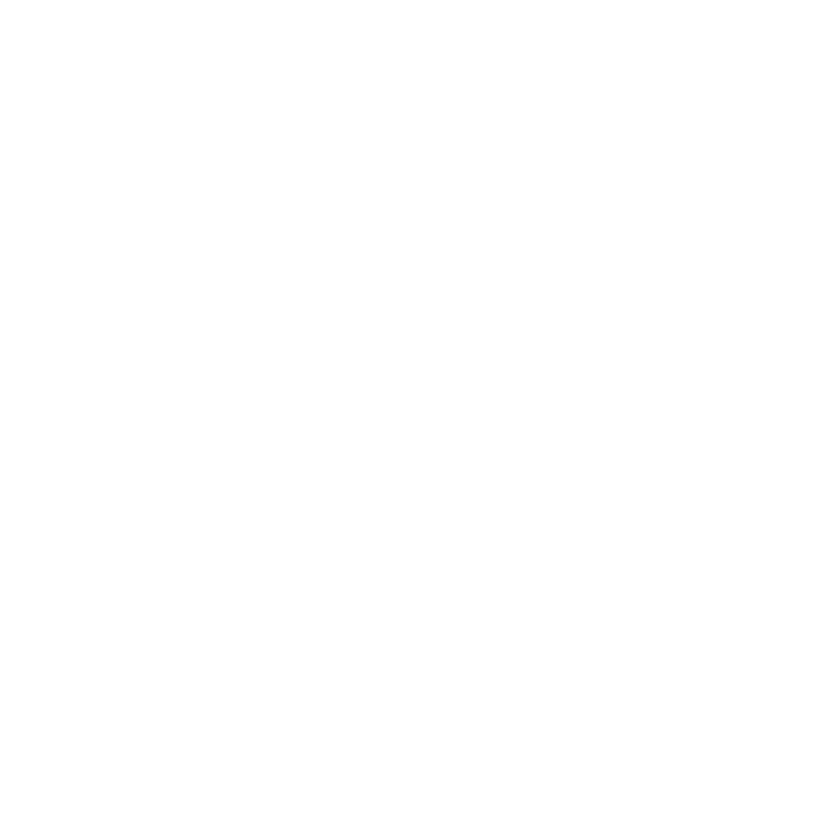

In [117]:
res <- run_vlstar (
  data = df_anual_ferr,
  endog = c("impp_usa","E","ipc","PBIpm"),
  periodicity = 'anual', # 'trimestral' o 'anual'
  feature_lag = 1,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","PBIpm")
  run_tests = FALSE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = 4, # 4 años, igual que las LP anuales (en anual, NULL serían solo 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE,
  estim_method = "three-phase",   # estimación en tres etapas
  min_obs_coef = 2                # con 88 años, 3 (default) exige más observaciones por régimen de las que hay
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [118]:
ic_vlstar_3f_p1 <- criterios_info(res, "VLSTAR 3 etapas p=1")
print(ic_vlstar_3f_p1)
saveRDS(ic_vlstar_3f_p1, "ic_vlstar_3f_p1_anual_ferr.rds")

               modelo regimenes parametros loglik   AIC    HQ   BIC
1 VLSTAR 3 etapas p=1         2         62 -261.8 647.6 709.2 800.5


In [119]:
resumen_modelo(res, data = df_anual_ferr, endog = c("impp_usa", "E", "ipc", "PBIpm"))

Modelo: logistic | regímenes: 2 | rezagos: 1 | errores: Gaussian 
Umbral (c): 89.7% anual | gamma: 1.13 
Años por régimen (régimen de mayor peso): régimen 1 = 69 | régimen 2 = 18 

Promedio observado de cada variable en los años de cada régimen
(variación anual en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      3.46      4.58
E            22.63    221.55
ipc          22.36    272.17
PBIpm         2.78      1.48


In [120]:
explorar_optimos(res, n = 20)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -261.80            89.7  1.13         NA            69/18
             2 -261.80            89.1  1.13         NA            69/18
             3 -262.14            88.8  1.12         NA            69/18
             4 -262.75            88.8  1.13         NA            69/18
             5 -262.80            87.4  1.12         NA            69/18
             6 -262.89            89.5  1.12         NA            69/18
             7 -262.96            89.4  1.14         NA            69/18
             8 -263.15            88.7  1.12         NA            69/18
             9 -263

In [121]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

logistic Gaussian STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 1, M = 2, d = 4, #parameters = 62, #observations = 87 x 4
  Switching variable: ipc with lag 1.

Regime 1 
Weight params: 1.02 (location), 1.13 (scale) 
Regime means:  0.10, -0.42, -0.66,  0.11

   Y      phi0          A1                              Omega                  
1 y1 = [  0.04 ] + [ -0.21 -0.35  0.08 -0.10 ] y1.1 + [  1.06  0.07  0.00  0.42
2 y2   [ -1.36 ]   [ -0.13 -0.12 -1.39 -0.17 ] y2.1   [  0.07  0.03  0.01 -0.10
3 y3   [ -1.18 ]   [ -0.25 -0.32 -0.64 -0.14 ] y3.1   [  0.00  0.01  0.00 -0.05
4 y4   [  1.17 ]   [  0.45  0.15  1.62  0.37 ] y4.1   [  0.42 -0.10 -0.05  1.14
    1/2     
1 ]     eps1
2 ]     eps2
3 ]     eps3
4 ]     eps4

Regime 2 
Regime means:  4.52,  4.62,  5.12, -2.99

   Y      phi0          A1                              Omega                  
1 y1 = [  1.36 ] + [  1.20 -0.41 -0.01  0.10 ] y1.1 + [  0.40 -0.28  0.02  0.22
2 y2   [  5.07 ]   [  0.77  1

In [122]:
shock_vlstar_3f_p1 <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "PBIpm"))
# Confirmar que mueve mucho a E y poco a ipc; si no, poner el número a mano:
# shock_vlstar_3f_p1 <- 2
shock_vlstar_3f_p1

Efecto de impacto de cada shock  (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0000 -0.0091  0.0279  0.0733
  E         0.0046  0.0674  0.0880  0.0190
  ipc       0.0039  0.0027  0.0291 -0.0125
  PBIpm    -0.0001 -0.0046 -0.0400  0.0370

Participación de E en el efecto de cada shock  :
shock_1 shock_2 shock_3 shock_4 
   0.74    0.58    0.16    0.02 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  0.835   0.041   0.331  -0.658 

>>> Shock sugerido como cambiario: 1 (confirmalo: debe mover mucho a E y poco a ipc )


[1] 1

### ERPT — solo si el modelo pasó el diagnóstico

**REVISAR ESTA NOTA No pasó: el óptimo elegido (el 1) tiene covarianza casi singular (`descartar = TRUE`). No usar este ERPT ni graficarlo.**

Nota de la versión trimestral: este modelo resultó malo (al descartar las soluciones degeneradas, la transición suave convergía a una abrupta, gamma ≈ 100). Revisar si con datos anuales pasa lo mismo antes de calcular el ERPT.


In [123]:
out_impp_usa_vlstar_3f_p1 <- erpt_historia(res, data = df_anual_ferr, endog = c("impp_usa", "E", "ipc", "PBIpm"), shock_num = shock_vlstar_3f_p1)

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 0.5%.

Estimando 87 GIRFs (una por año), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 1...

Finished!




Años dominados por cada régimen (peso > 0.9): régimen 1 = 0 | régimen 2 = 4 
Shock usado:1| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.9841

Promedio entre años:
  horizonte reg_bajo_original reg_alto_original
1         0               NaN            0.8346
2         1               NaN            1.5471
3         2               NaN            1.9229
4         3               NaN            2.2542
5         4               NaN            2.5199

Mediana entre años (robusta a años con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0               NA           0.8346
2         1               NA           1.5758
3         2               NA           1.7055
4         3               NA           1.6845
5         4               NA           1.5780


In [124]:
out_impp_usa_vlstar_3f_p1_acum <- erpt_historia(res, data = df_anual_ferr, endog = c("impp_usa", "E", "ipc", "PBIpm"), shock_num = shock_vlstar_3f_p1,
                      definicion = "acumulado")

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 0.5%.

Estimando 87 GIRFs (una por año), 1000 simulaciones cada una...



Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 1...

Finished!




Años dominados por cada régimen (peso > 0.9): régimen 1 = 0 | régimen 2 = 4 
Shock usado:1| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.9841

Promedio entre años:
  horizonte reg_bajo_original reg_alto_original
1         0               NaN            0.8346
2         1               NaN            1.0188
3         2               NaN            1.0932
4         3               NaN            1.1537
5         4               NaN            1.2100

Mediana entre años (robusta a años con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0               NA           0.8346
2         1               NA           0.9987
3         2               NA           1.0679
4         3               NA           1.1120
5         4               NA           1.1382


Parámetros usados -> c (escalado): 1.02 | gamma: 1.13 
(deben coincidir con 'Weight params' de print(modelo); si no, pasalos a mano)
Umbral en unidades originales: 0.6404 | franja 10%-90%: -0.5714 a 1.8523 


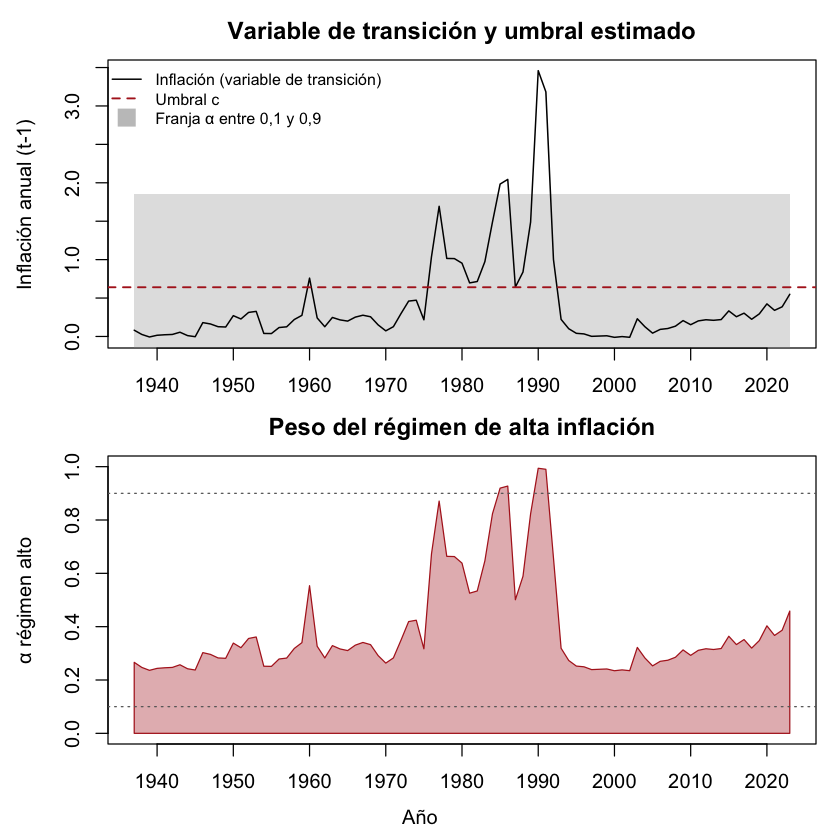

In [125]:
graficar_transicion(res, data = df_anual_ferr, endog = c("impp_usa", "E", "ipc", "PBIpm"),
                    archivo = paste0(carpeta, "transicion_impp_usa_vlstar_3f_p1_anual_ferr"))

In [126]:
exists("ic_vlstar_t_p1"); exists("ic_vlstar_t_p2")

[1] TRUE

[1] TRUE

In [128]:
nms <- c("ic_tvar_p1", "ic_vlstar_p1", "ic_vlstar_3f_p1")
do.call(rbind, mget(nms[sapply(nms, exists)]))

,modelo,regimenes,parametros,loglik,AIC,HQ,BIC
,<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
ic_tvar_p1,TVAR p=1,2,61,-239.53,601.1,661.6,751.5
ic_vlstar_3f_p1,VLSTAR 3 etapas p=1,2,62,-261.80,647.6,709.2,800.5


## VLSTAR gaussiano (dos etapas)

En la versión trimestral quedó descartado: las soluciones válidas ajustaban peor que el TVAR, y las de mayor verosimilitud tenían la covarianza del régimen de hiperinflación casi singular. Con datos anuales, revisar el diagnóstico (`explorar_optimos`) antes de usarlo.


Desvíos usados para escalar:
  impp_usa          E        ipc      PBIpm 
0.07653640 0.63532513 0.62520664 0.05122031 


Using 6 cores for 500 estimations rounds...

PHASE 1: Estimating all the parameters with a genetic algorithm...

Results from the genetic algorithm:

The lowest loglik:  -389.923

The largest loglik: -250.298

PHASE 2: Estimating all the parameters with a variable metric algorithm...

Results from the variable metric algorithm:

The lowest loglik:  -334.905

The largest loglik: -237.026

Filtering inappropriate estimates...

Filtered through 4 inappropriate  estimates with a larger log-likelihood

Calculating approximate standard errors...

Warning message in warn_eigens(ret, allow_unstab = allow_unstab):
“Regime 2 has near-unit-roots! Consider building a model from the next-largest local maximum with the function 'alt_stvar' by adjusting its argument 'which_largest' (or use the function 'filter_estimates').”
Finished!




========= Unstructured fitted model ==========


Calculating approximate standard errors...



========= Structured fitted model (heteroskedasticity) ==========
Saving trained models to models/ folder

 >>> DIAGNOSTIC PLOTS


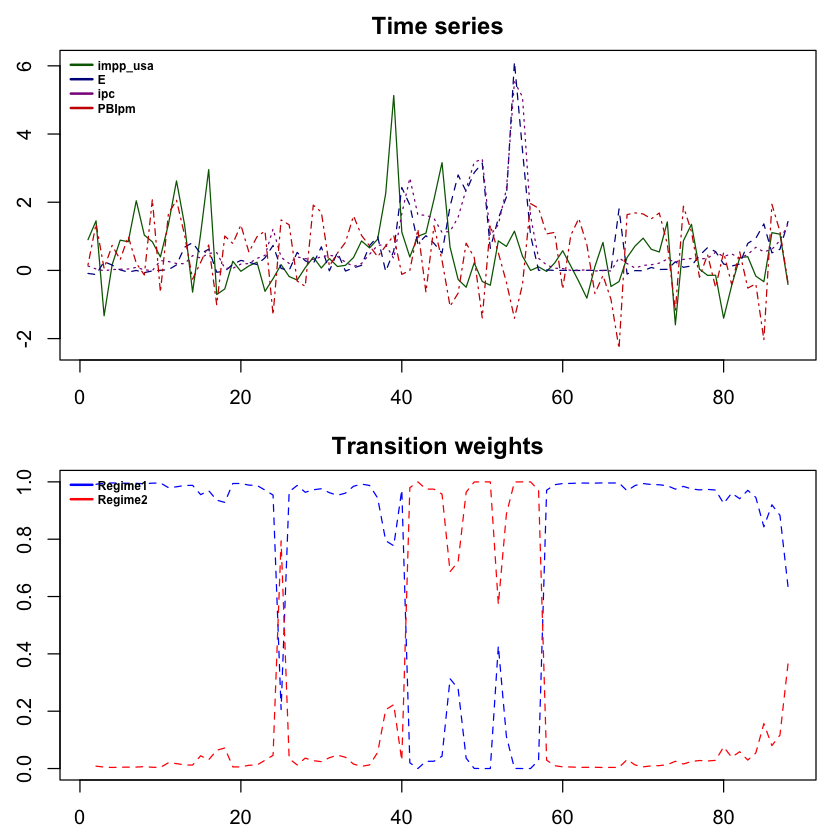

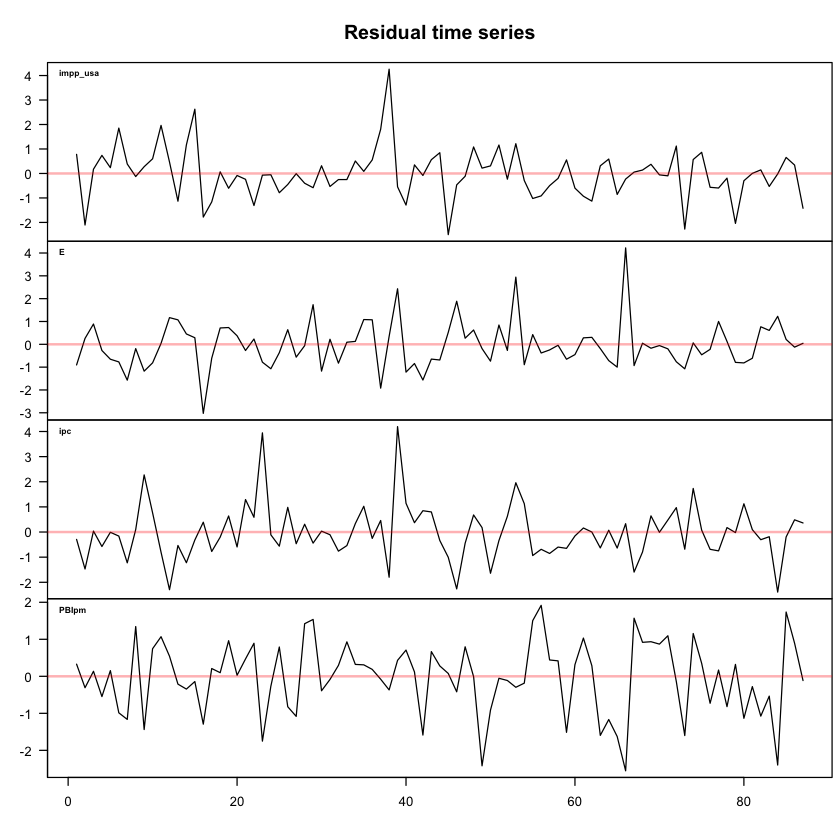

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



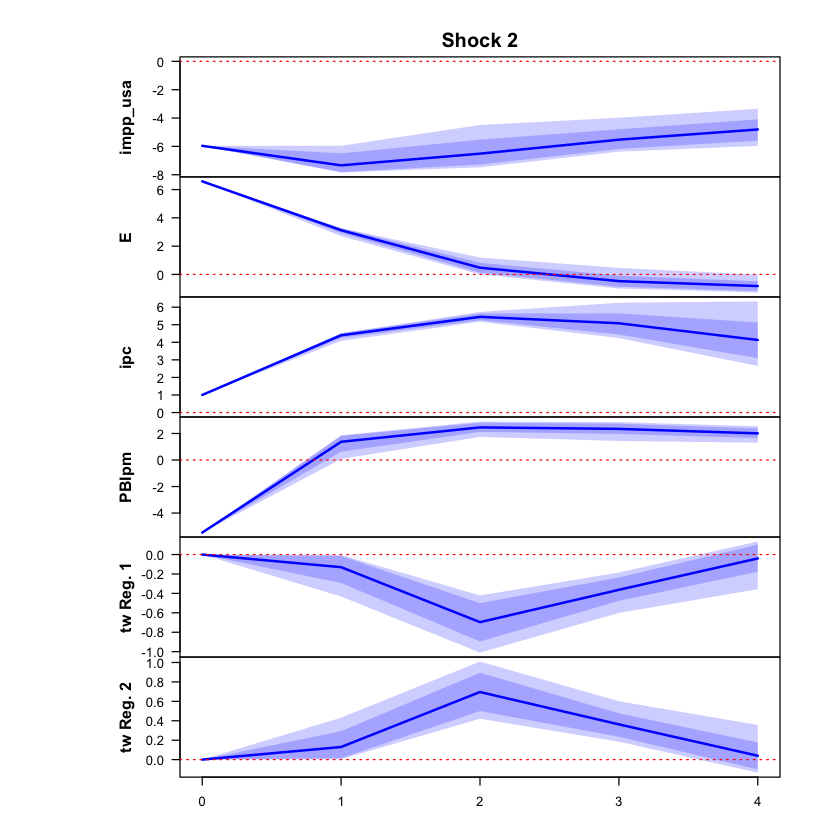

 >>> Linear IRF ( 1  shock units)


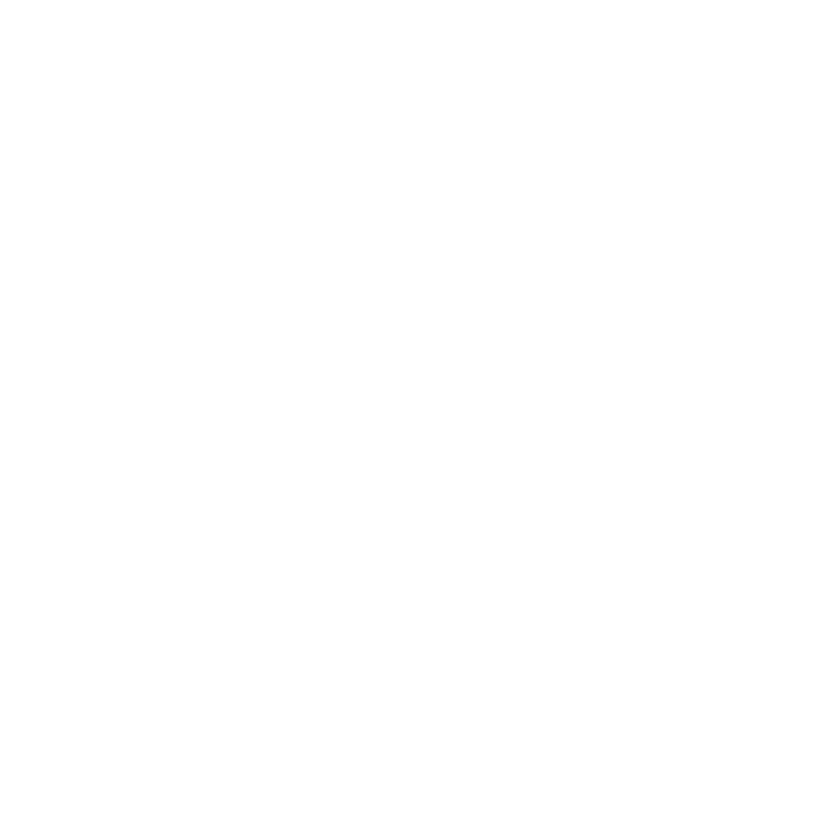

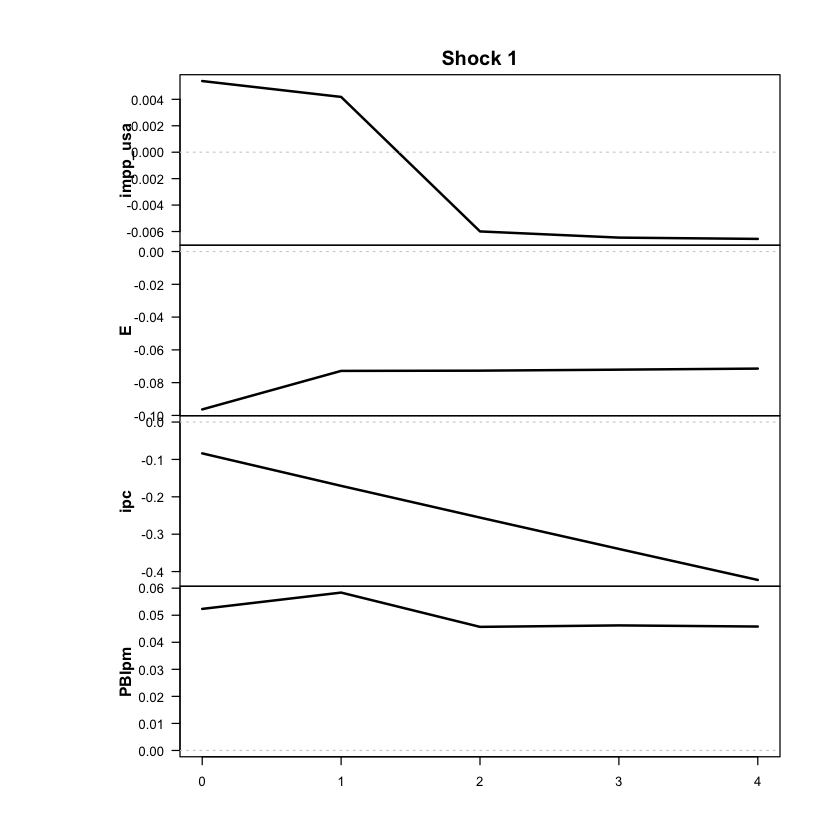

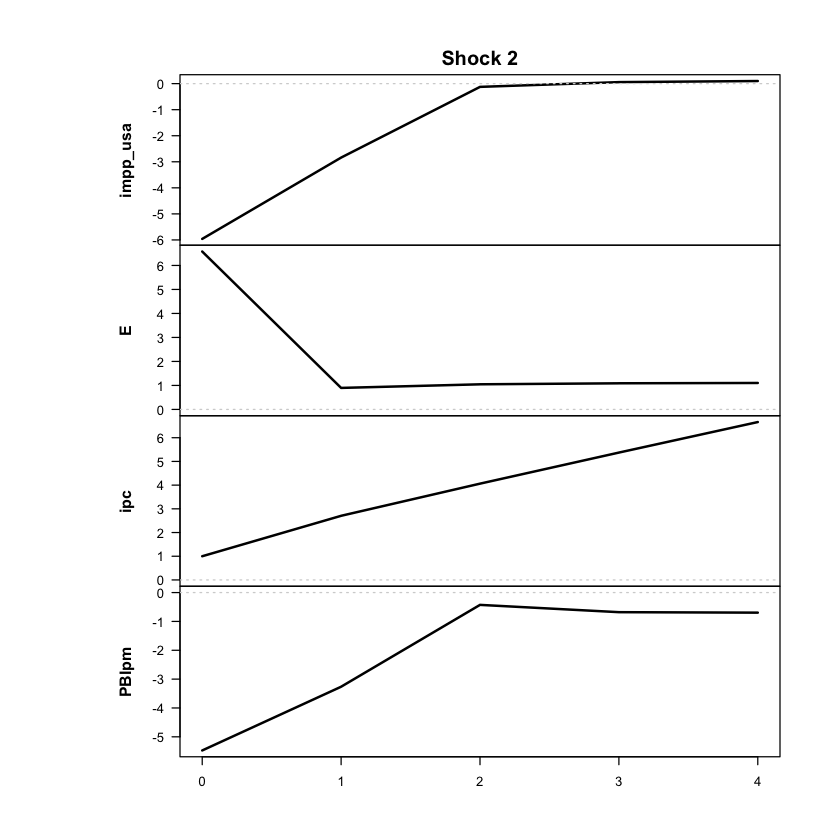

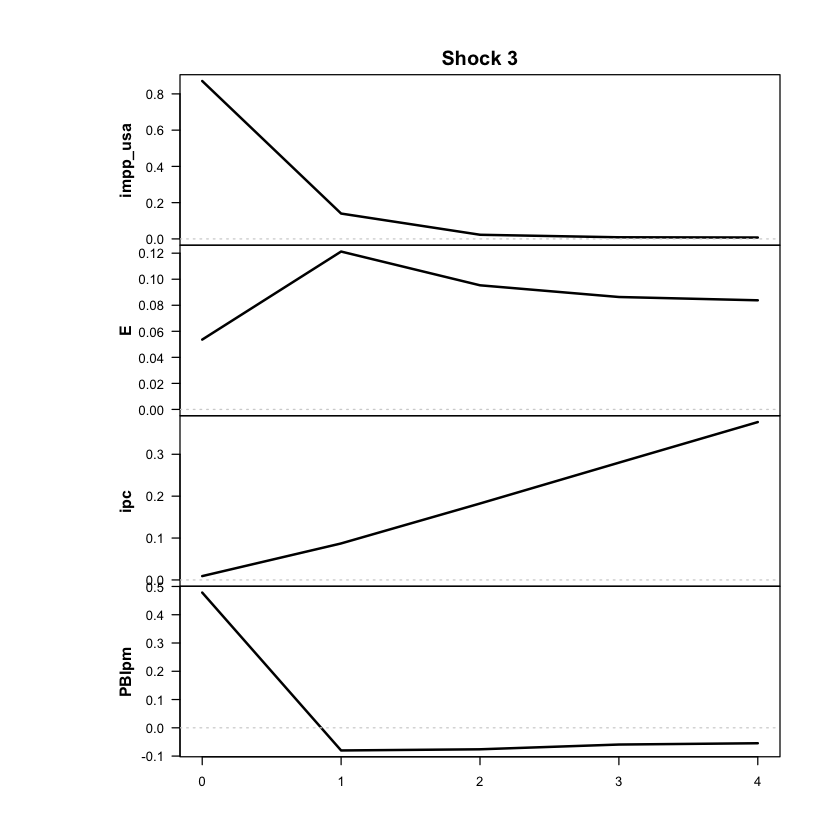

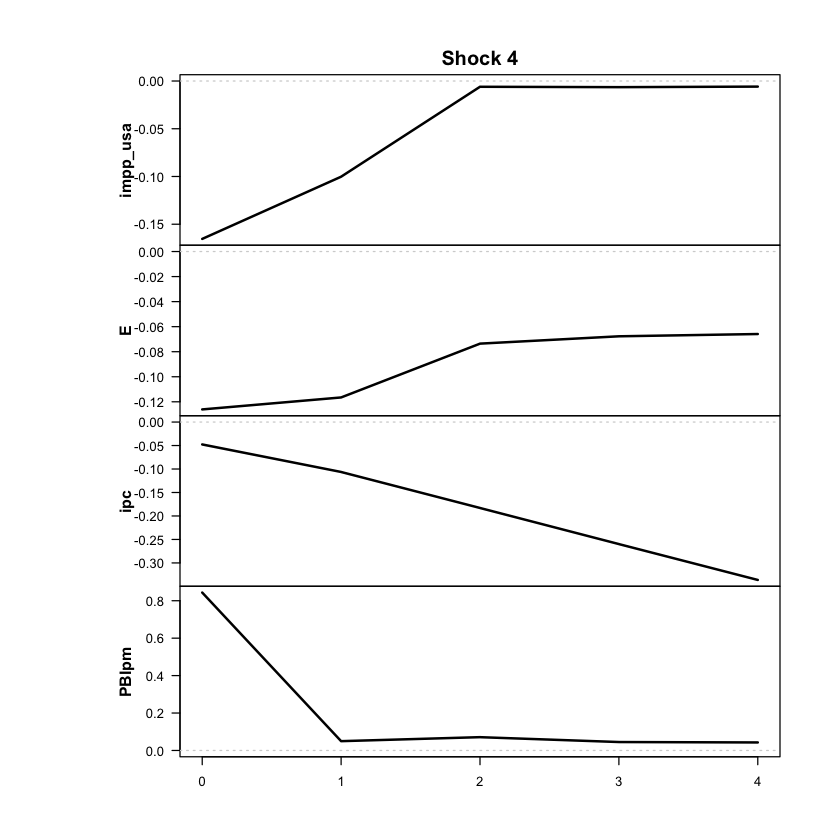

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



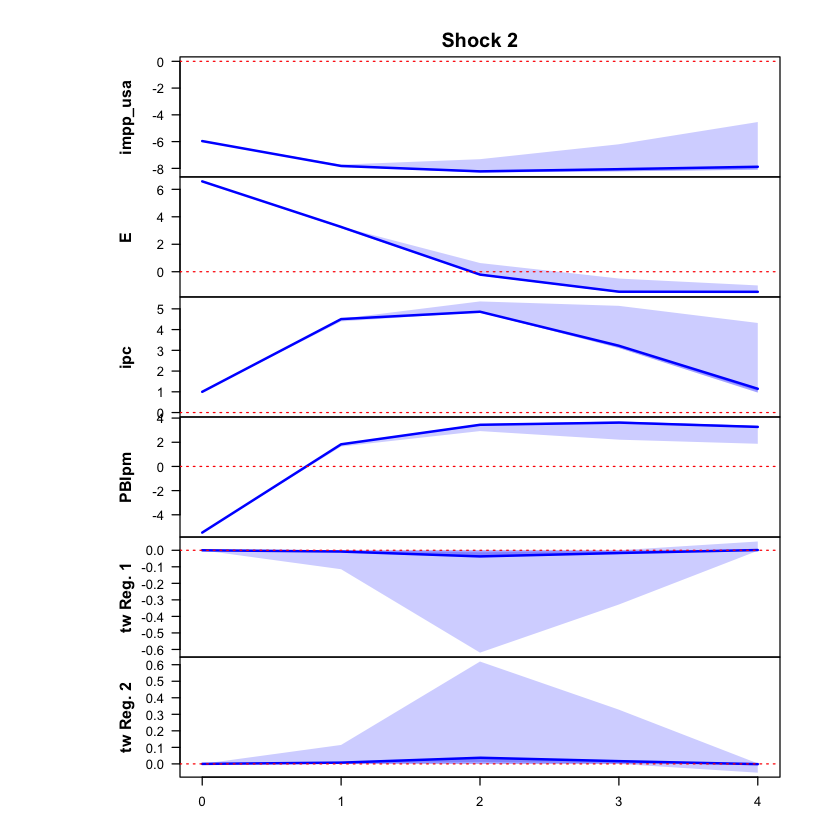

 >>> Linear IRF ( 1  shock units)


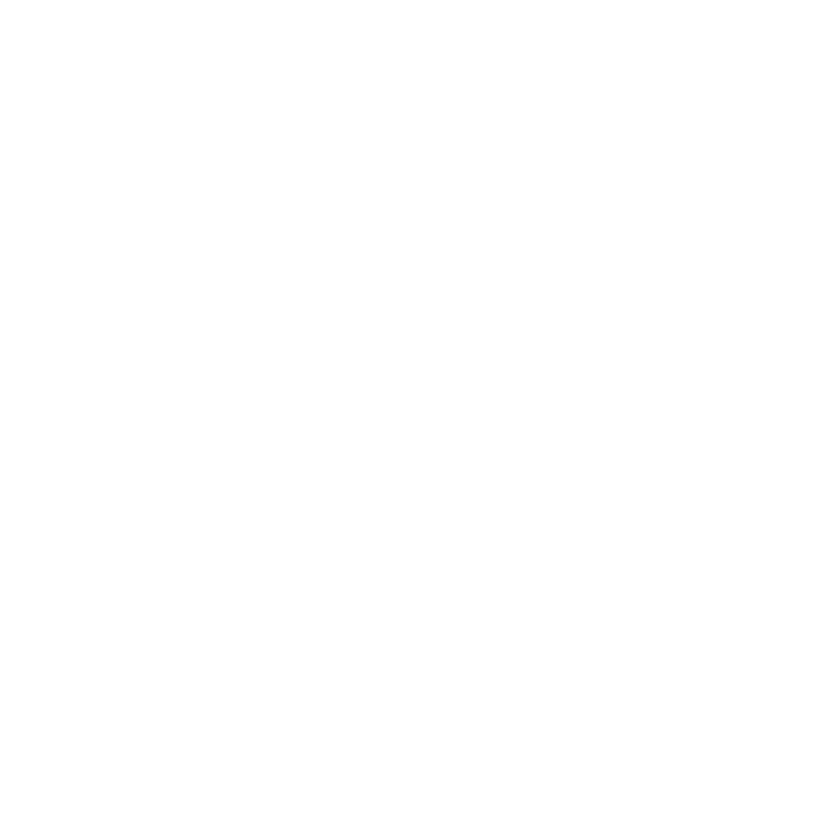

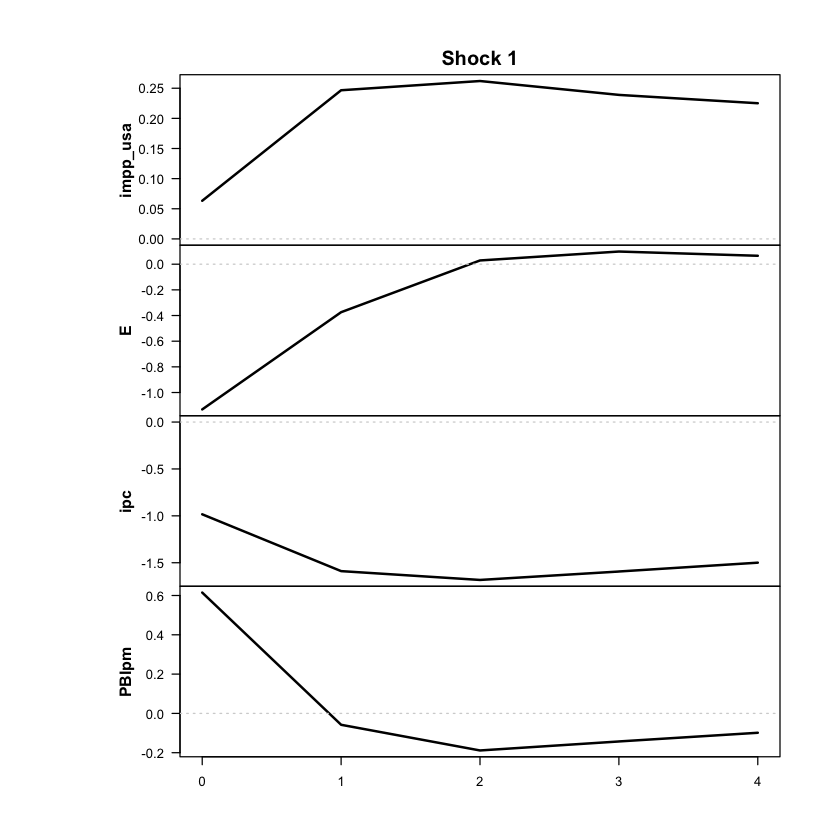

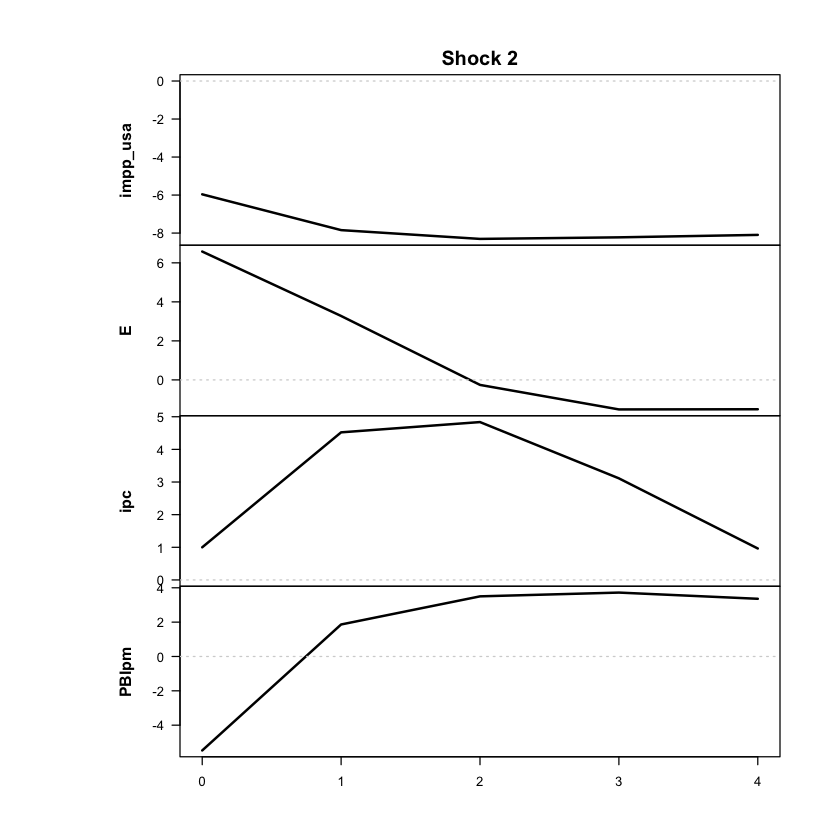

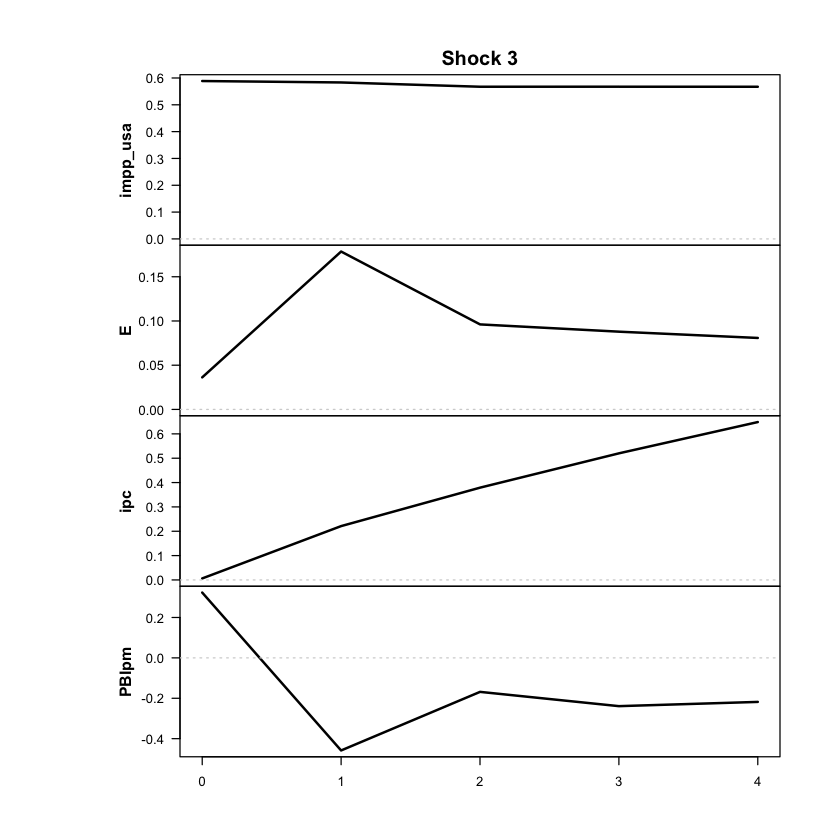

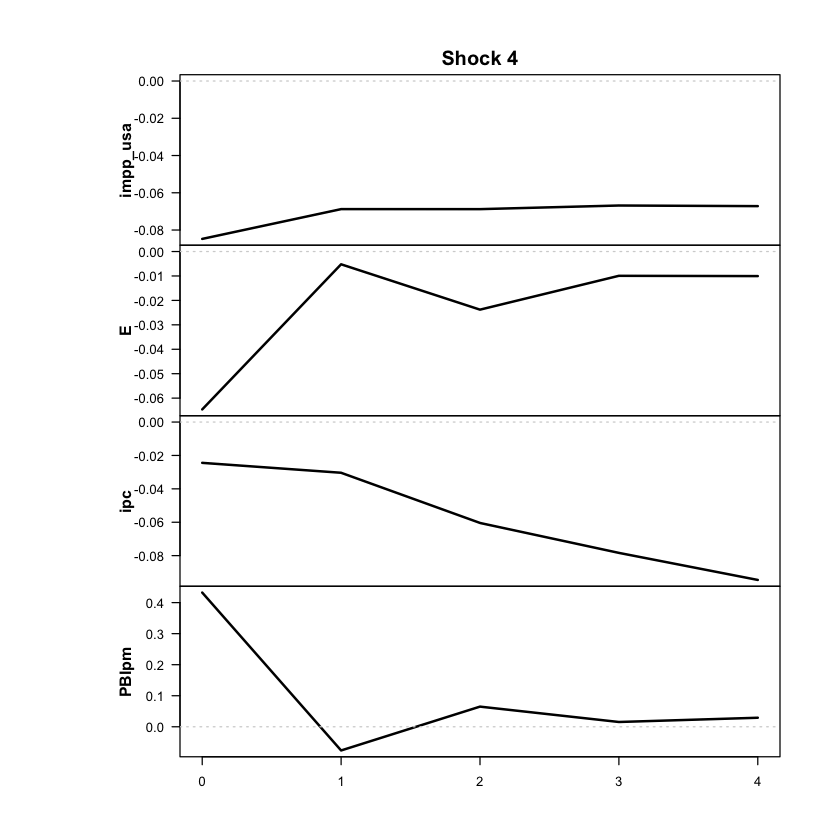

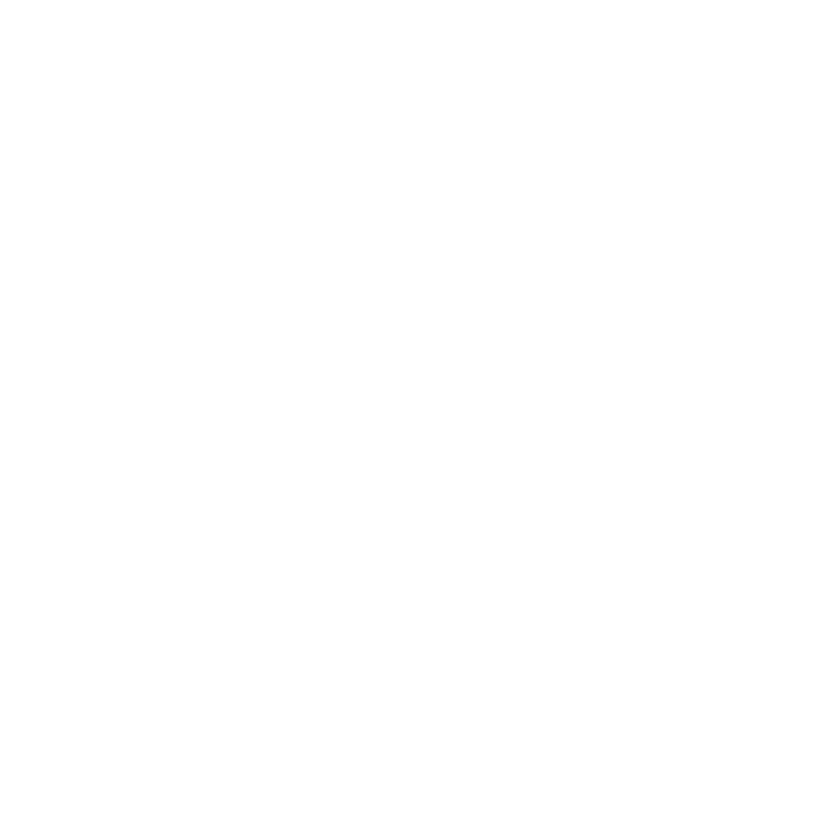

In [129]:
res <- run_vlstar (
  data = df_anual_ferr,
  endog = c("impp_usa","E","ipc","PBIpm"),
  periodicity = 'anual', # 'trimestral' o 'anual'
  feature_lag = 1,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","PBIpm")
  run_tests = FALSE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = 4, # 4 años, igual que las LP anuales (en anual, NULL serían solo 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE   # primera corrida: estimar. Después de guardado, cambiar a TRUE
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [130]:
res$tvar_model$loglik

'log Lik.' -239.6644 (df=62)

In [131]:
resumen_modelo(res, data = df_anual_ferr, endog = c("impp_usa", "E", "ipc", "PBIpm"))
explorar_optimos(res, n = 20)

Modelo: logistic | regímenes: 2 | rezagos: 1 | errores: Gaussian 
Umbral (c): 84.1% anual | gamma: 5.65 
Años por régimen (régimen de mayor peso): régimen 1 = 69 | régimen 2 = 18 

Promedio observado de cada variable en los años de cada régimen
(variación anual en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      3.46      4.58
E            22.63    221.55
ipc          22.36    272.17
PBIpm         2.78      1.48
umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -237.03           161.4  2.86         NA            75/12
             2 -237.22           100.3  5.00         NA            70/17
 

In [132]:
ic_vlstar_p1 <- criterios_info(res, "VLSTAR p=1")
print(ic_vlstar_p1)
saveRDS(ic_vlstar_p1, "ic_vlstar_p1_anual_ferr.rds")
explorar_optimos(res, n = 20)

      modelo regimenes parametros  loglik   AIC    HQ   BIC
1 VLSTAR p=1         2         62 -239.66 603.3 664.9 756.2
umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -237.03           161.4  2.86         NA            75/12
             2 -237.22           100.3  5.00         NA            70/17
             3 -237.29            68.1  7.38         NA            68/19
             4 -238.43           113.9  4.15         NA            73/14
             5 -239.66            84.1  5.65         NA            69/18
             6 -239.76           119.9  3.33         NA            73/14
             7 -239.92           128.6  3.86 

In [133]:
#Ver si es útil
print_passthrough(res, endog = c("impp_usa","E","ipc","PBIpm"))

+++++++++ RÉGIMEN  1 +++++++++

>>> GIRF normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
0         0       0.1496
1         1       0.6580
2         2       0.8150
3         3       0.7603
4         4       0.6180

>>> IRF lineal normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
1         0       0.1496
2         1       0.4047
3         2       0.6076
4         3       0.8036
5         4       0.9962

+++++++++ RÉGIMEN  2 +++++++++

>>> GIRF normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
0         0       0.1496
1         1       0.6739
2         2       0.7271
3         3       0.4818
4         4       0.1715

>>> IRF lineal normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
1         0       0.1496
2         1       0.6763
3         2       0.7234
4         3       0.4656
5         4       0.1441



Desvíos usados para escalar:
  impp_usa          E        ipc      PBIpm 
0.07653640 0.63532513 0.62520664 0.05122031 


Using 6 cores for 500 estimations rounds...

PHASE 1: Estimating all the parameters with a genetic algorithm...

Results from the genetic algorithm:

The lowest loglik:  -431.637

The largest loglik: -249.199

PHASE 2: Estimating all the parameters with a variable metric algorithm...

Results from the variable metric algorithm:

The lowest loglik:  -331.701

The largest loglik: -209.768

Filtering inappropriate estimates...

Filtered through 181 inappropriate  estimates with a larger log-likelihood

Calculating approximate standard errors...

Finished!




========= Unstructured fitted model ==========


Calculating approximate standard errors...



========= Structured fitted model (heteroskedasticity) ==========
Saving trained models to models/ folder

 >>> DIAGNOSTIC PLOTS


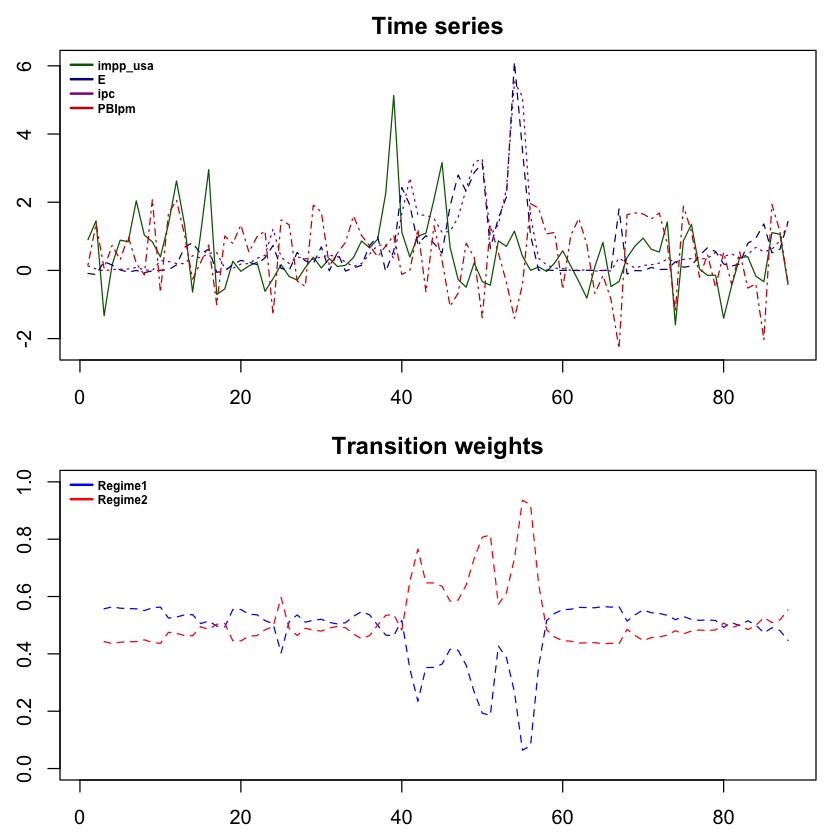

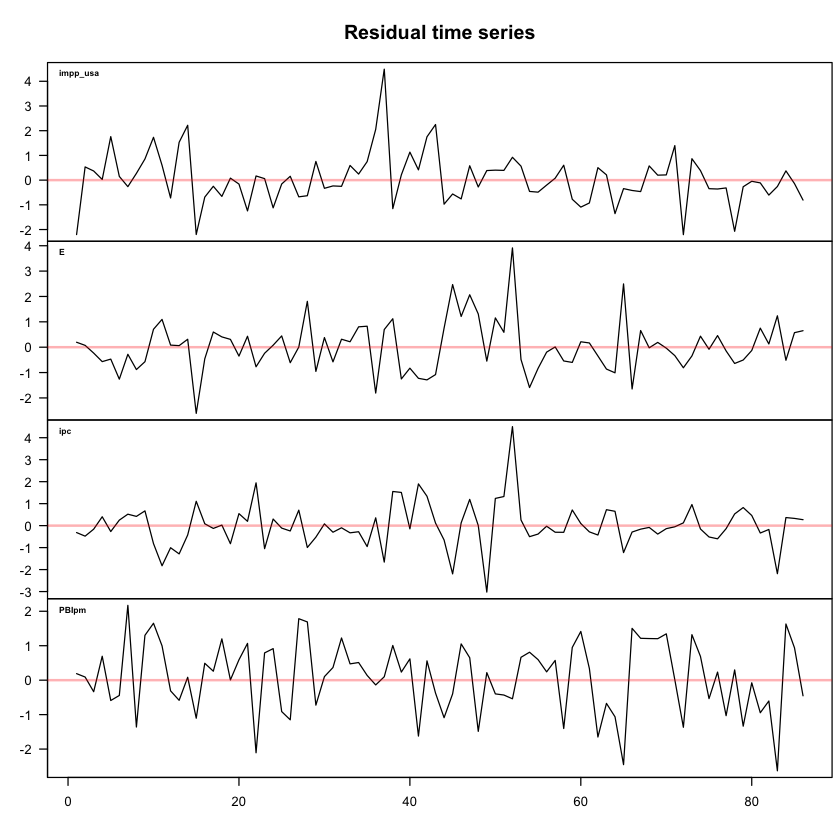

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



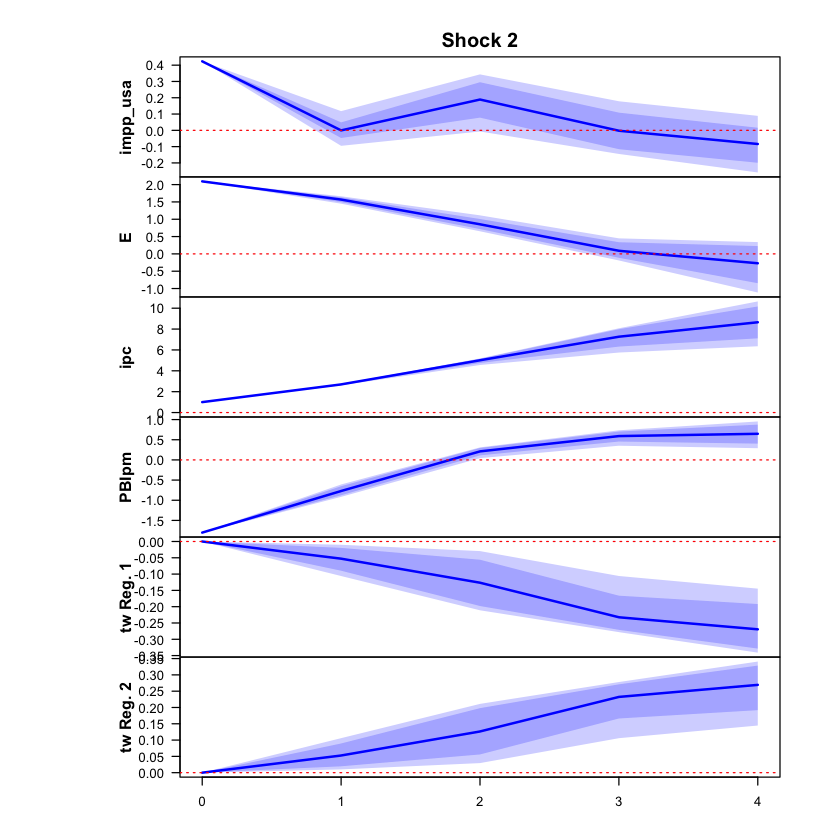

 >>> Linear IRF ( 1  shock units)


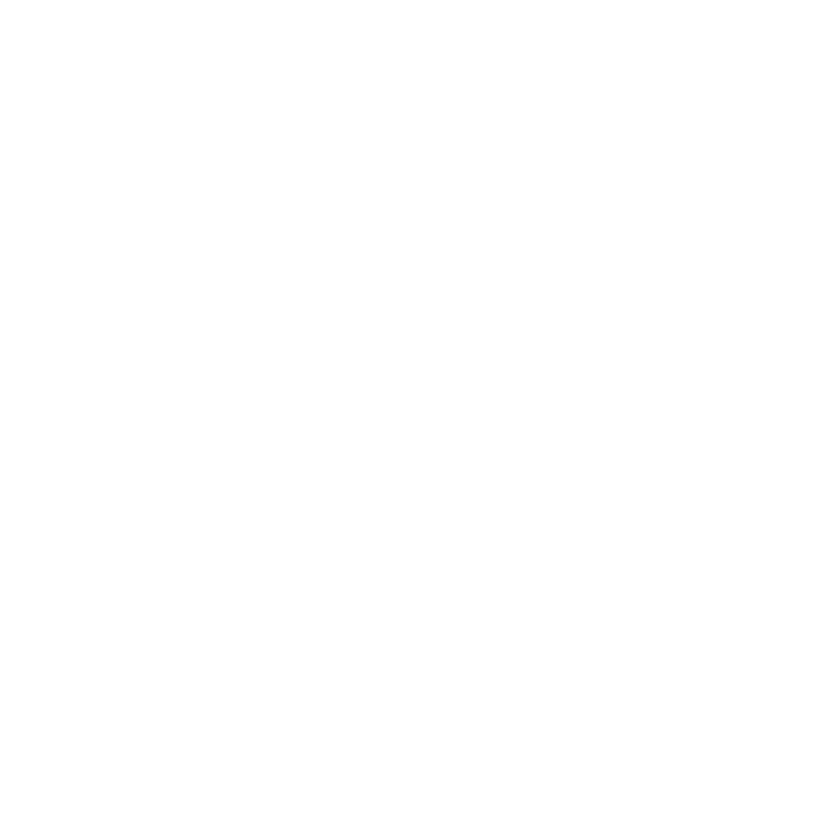

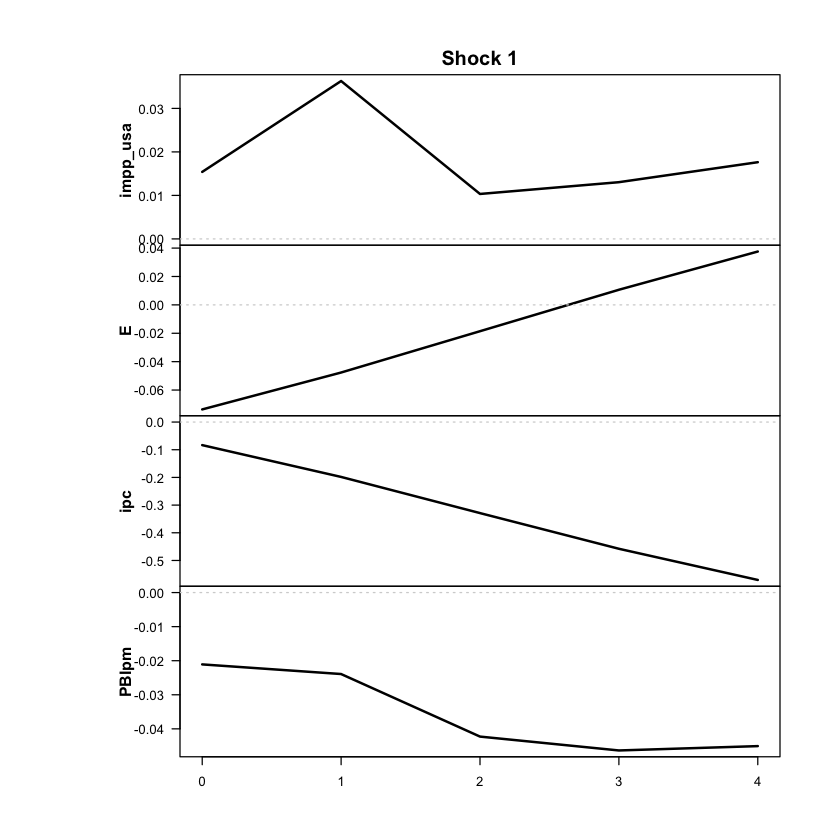

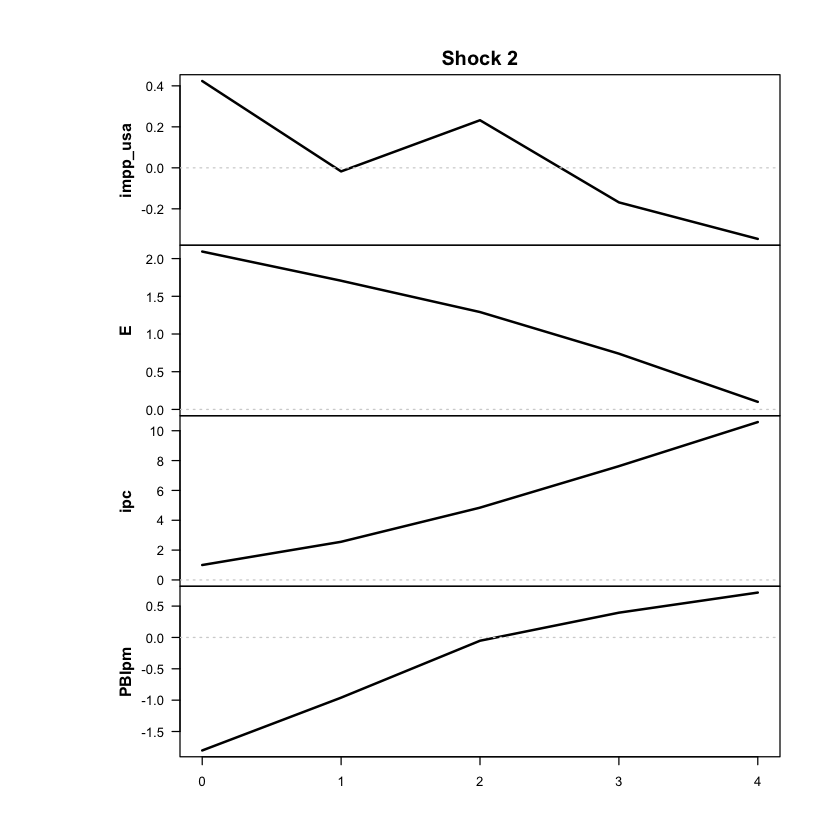

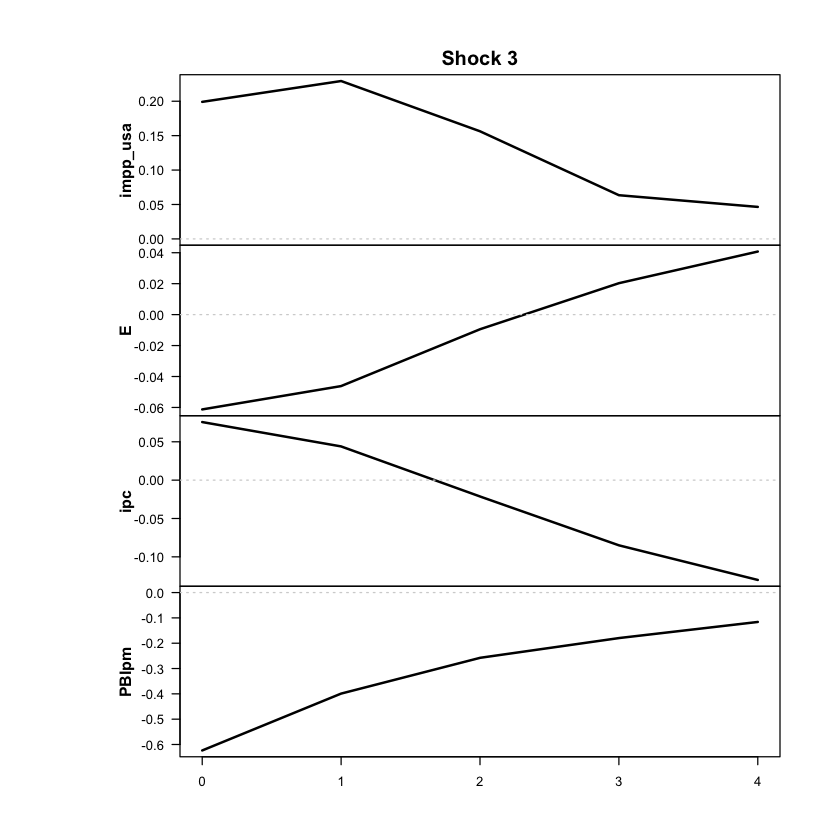

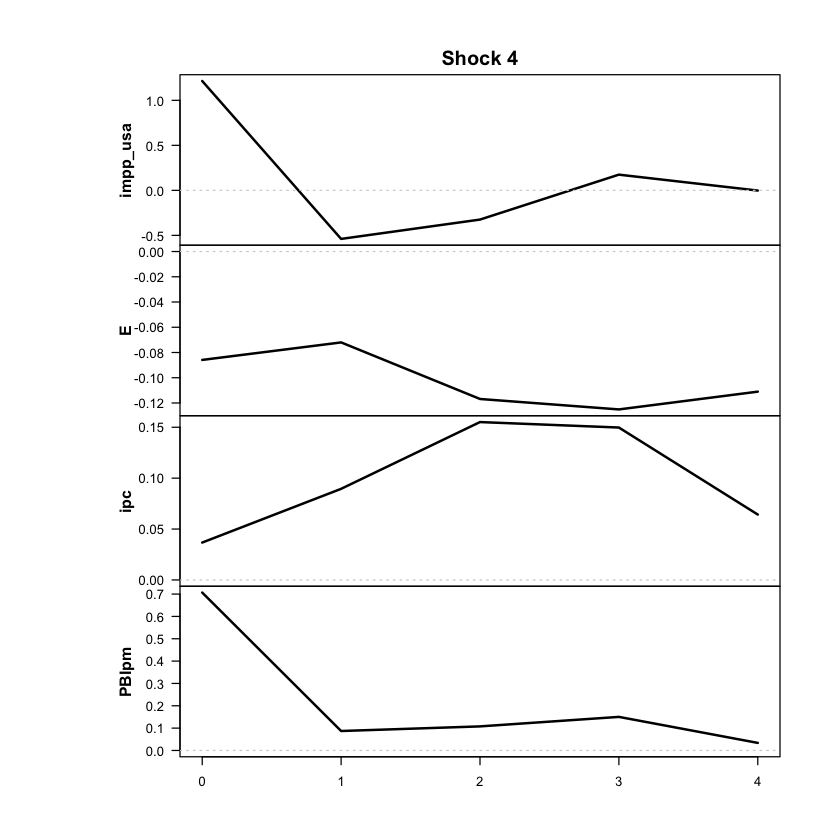

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



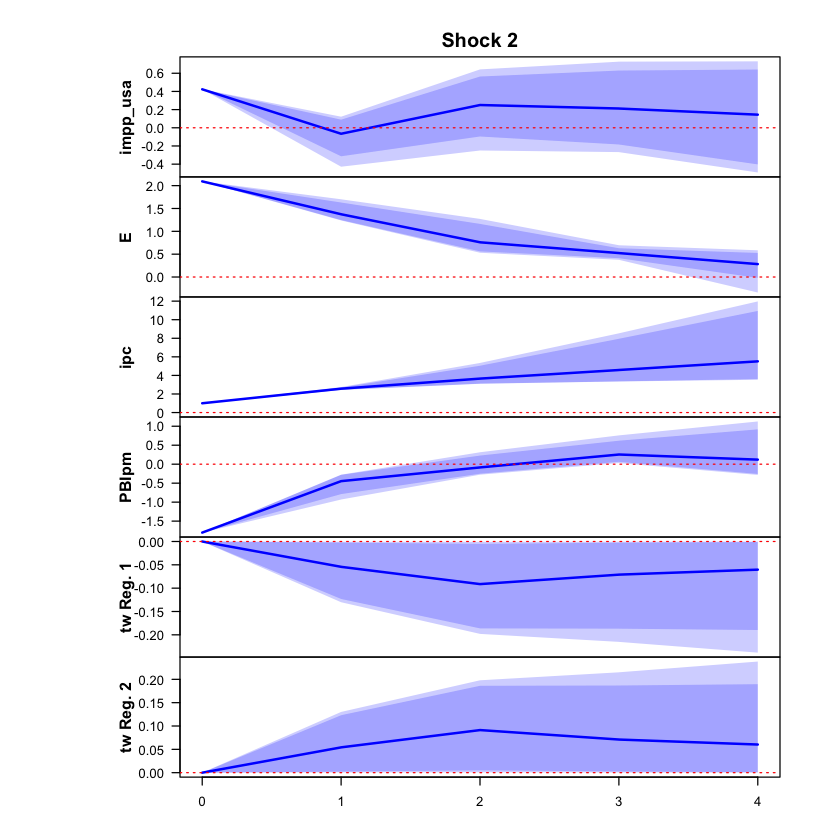

 >>> Linear IRF ( 1  shock units)


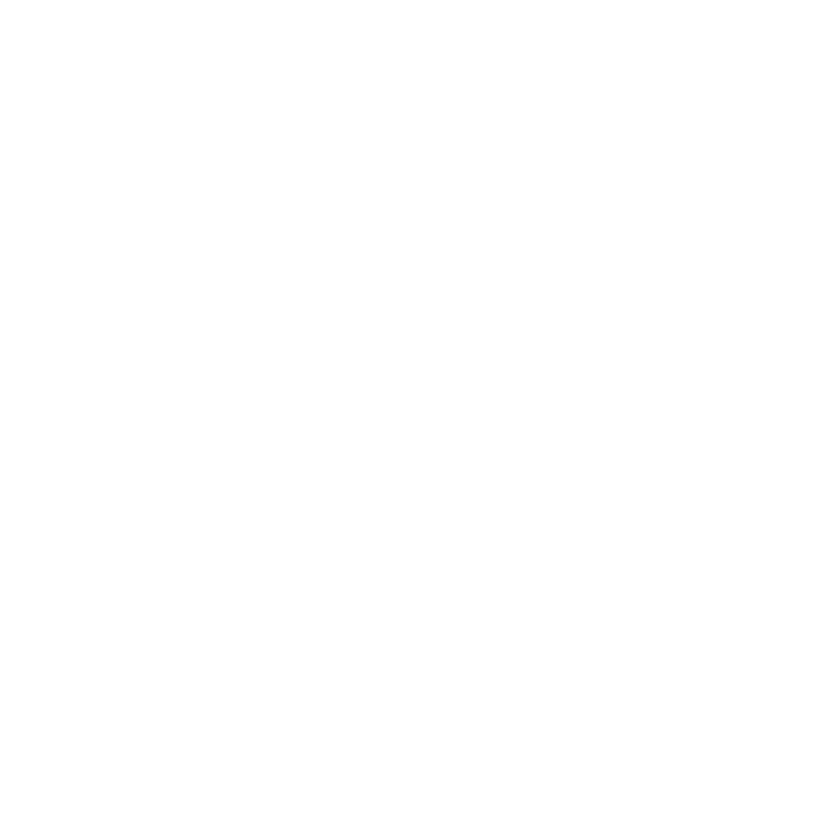

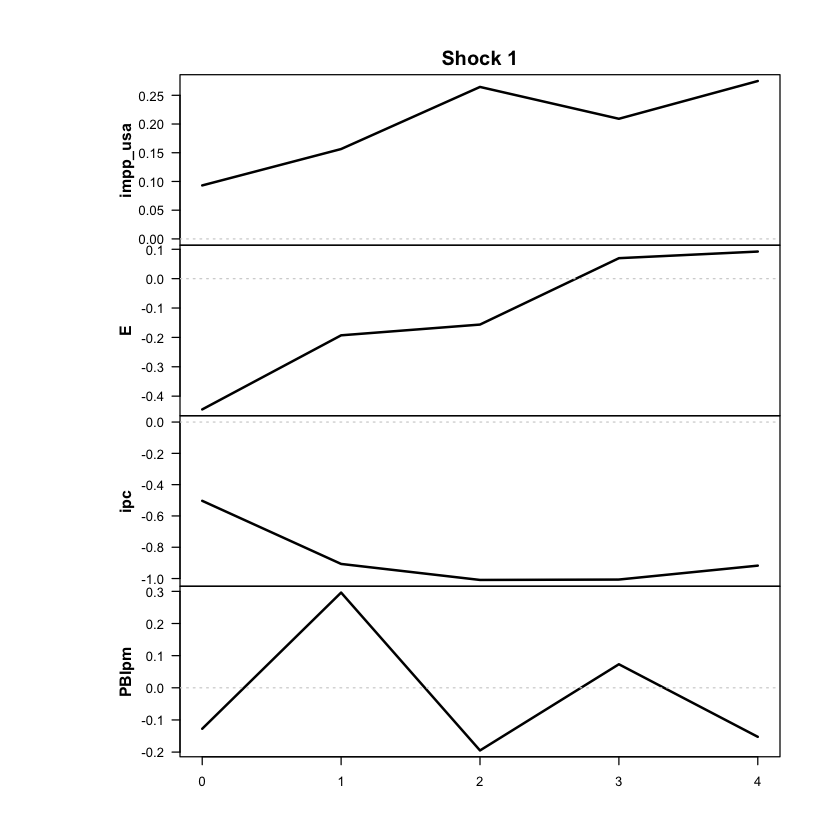

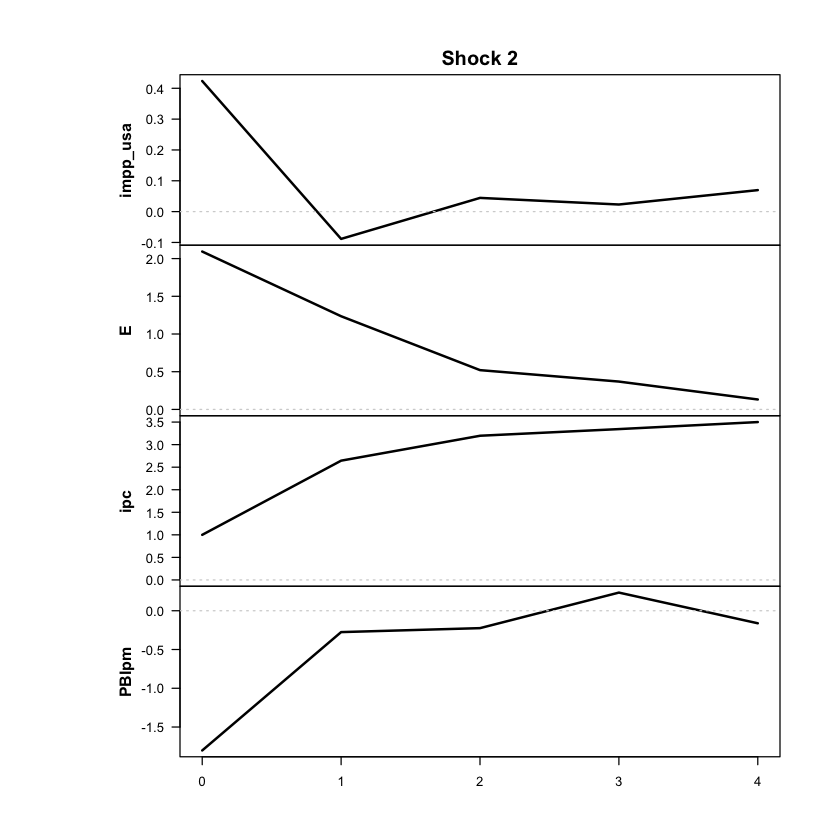

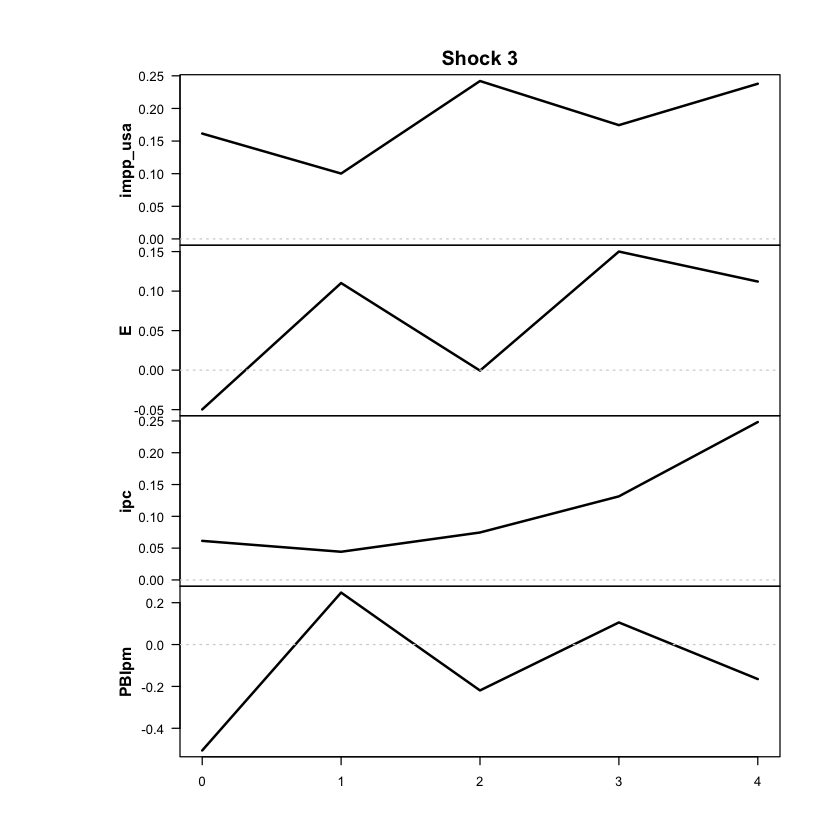

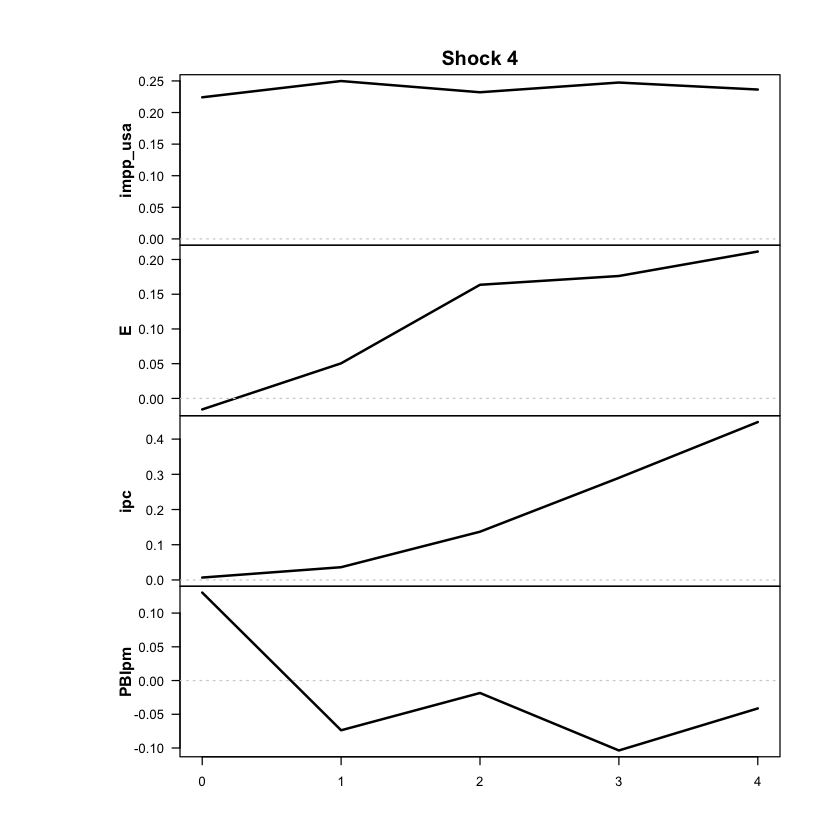

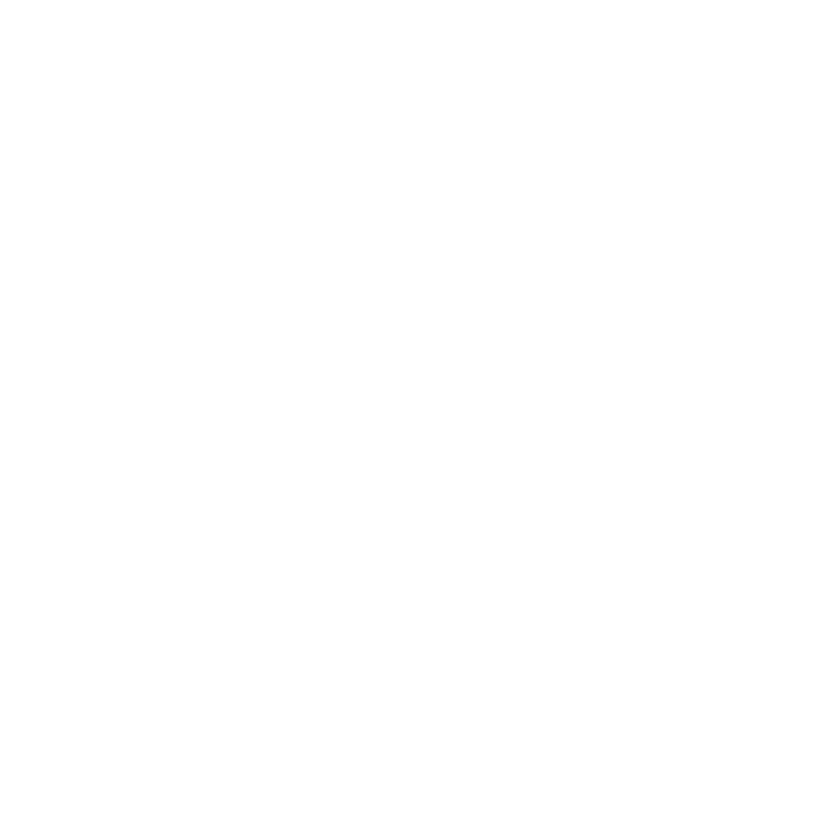

In [134]:
res <- run_vlstar (
  data = df_anual_ferr,
  endog = c("impp_usa","E","ipc","PBIpm"),
  periodicity = 'anual', # 'trimestral' o 'anual'
  feature_lag = 2,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","PBIpm")
  run_tests = FALSE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = 4, # 4 años, igual que las LP anuales (en anual, NULL serían solo 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE   # primera corrida: estimar. Después de guardado, cambiar a TRUE
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

##### Celda para verificar qué modelo fue el último que se corrió

In [135]:
c(tipo = res$tvar_model$model$weight_function, p = res$tvar_model$model$p,
  errores = res$tvar_model$model$cond_dist)

tipo          p    errores 
"logistic"        "2" "Gaussian"

In [136]:
ic_vlstar_p2 <- criterios_info(res, "VLSTAR p=2")
print(ic_vlstar_p2)
saveRDS(ic_vlstar_p2, "ic_vlstar_p2_anual_ferr.rds")
explorar_optimos(res, n = 20)

      modelo regimenes parametros  loglik   AIC    HQ    BIC
1 VLSTAR p=2         2         94 -296.29 780.6 873.4 1011.3
umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -209.77              88  4.73         NA            68/18
             2 -226.58            63.2  6.16         NA            67/19
             3 -229.40            96.2  3.82         NA            69/17
             4 -232.95           148.3  2.68         NA            73/13
             5 -233.47           165.1  2.51         NA            75/11
             6 -234.62           145.7  2.57         NA            73/13
             7 -234.99           139.7  5.0

In [137]:
for (f in list.files(pattern = "^ic_.*_anual_ferr\\.rds$")) {
  assign(sub("_anual_ferr\\.rds$", "", f), readRDS(f))
}

In [138]:
nms <- c("ic_tvar_p1", "ic_tvar_p2", "ic_tvar_t_p1",
         "ic_vlstar_p1", "ic_vlstar_3f_p1", "ic_vlstar_p2",
         "ic_vlstar_t_p1", "ic_vlstar_t_p2", "ic_vlstar_t_p1_anual_ferr.rds", "ic_vlstar_t_p2_anual_ferr.rds")
tabla_ic <- do.call(rbind, mget(nms[sapply(nms, exists)]))
tabla_ic$valido <- ifelse(tabla_ic$modelo %in% c("TVAR p=1", "TVAR p=2", "TVAR-t p=1"),
                          "sí", "no (óptimos con problemas)")
print(tabla_ic, row.names = FALSE)
saveRDS(tabla_ic, "tabla_ic_anual_ferr.rds")

              modelo regimenes parametros  loglik   AIC    HQ    BIC
            TVAR p=1         2         61 -239.53 601.1 661.6  751.5
            TVAR p=2         2         93 -192.53 571.1 662.9  799.3
          TVAR-t p=1         2         62 -210.78 545.6 607.1  698.5
          VLSTAR p=1         2         62 -239.66 603.3 664.9  756.2
 VLSTAR 3 etapas p=1         2         62 -261.80 647.6 709.2  800.5
          VLSTAR p=2         2         94 -296.29 780.6 873.4 1011.3
        VLSTAR-t p=1         2         63 -283.90 693.8 756.4  849.1
        VLSTAR-t p=2         2         95 -274.40 738.8 832.6  972.0
                     valido
                         sí
                         sí
                         sí
 no (óptimos con problemas)
 no (óptimos con problemas)
 no (óptimos con problemas)
 no (óptimos con problemas)
 no (óptimos con problemas)


In [139]:
list.files(pattern = "^ic_")

[1] "ic_2reg.rds"                    "ic_tvar_p1_anual_comb.rds"     
 [3] "ic_tvar_p1_anual_ferr.rds"      "ic_tvar_p2_anual_comb.rds"     
 [5] "ic_tvar_p2_anual_ferr.rds"      "ic_tvar_t_p1_anual_comb.rds"   
 [7] "ic_tvar_t_p1_anual_ferr.rds"    "ic_vlstar_3f_p1_anual_comb.rds"
 [9] "ic_vlstar_3f_p1_anual_ferr.rds" "ic_vlstar_p1_anual_comb.rds"   
[11] "ic_vlstar_p1_anual_ferr.rds"    "ic_vlstar_p2_anual_comb.rds"   
[13] "ic_vlstar_p2_anual_ferr.rds"    "ic_vlstar_t_p1_anual_comb.rds" 
[15] "ic_vlstar_t_p1_anual_ferr.rds"  "ic_vlstar_t_p2_anual_comb.rds" 
[17] "ic_vlstar_t_p2_anual_ferr.rds"

In [140]:
for (f in c("out_impp_usa_tvar_p1_anual_ferr.rds", "out_impp_usa_tvar_p1_acum_anual_ferr.rds",
            "out_impp_usa_tvar_p2_anual_ferr.rds", "out_impp_usa_tvar_p2_acum_anual_ferr.rds")) {
  o <- readRDS(f)
  cat(f, "| años:", ncol(o$erpt), "| primer año:", colnames(o$erpt)[1], "\n")
}

out_impp_usa_tvar_p1_anual_ferr.rds | años: 87 | primer año: 1937 
out_impp_usa_tvar_p1_acum_anual_ferr.rds | años: 87 | primer año: 1937 
out_impp_usa_tvar_p2_anual_ferr.rds | años: 86 | primer año: 1938 
out_impp_usa_tvar_p2_acum_anual_ferr.rds | años: 86 | primer año: 1938 


# TEST de autocorrelación y de heterocedasticidad

Fuente: https://rdrr.io/cran/sstvars/man/Portmanteau_test.html

#### Atención que los dos VLSTAR p = 1 (dos y tres etapas) aparecen como dos filas “VLSTAR, 1 rezago” sin distinguirse. Como los dos están descartados, no importa para las conclusiones, pero tenerlo en cuenta si incluyo la tabla en la tesis.

In [142]:
portmanteau_guardados <- function(data, rezagos_test = c(8, 12), carpeta = "models") {
  archivos <- list.files(carpeta, pattern = "\\.rds$", full.names = TRUE)
  archivos <- archivos[!grepl("^structured_", basename(archivos))]
  pval <- function(t) {
    nm <- grep("p_val|pval|p.val", names(t), value = TRUE)
    if (length(nm)) as.numeric(t[[nm[1]]]) else NA
  }
  etiqueta <- function(m) {
    wf <- m$model$weight_function
    tipo <- switch(if (is.null(wf)) "" else wf,
                   threshold = "TVAR", logistic = "VLSTAR", mlogit = "MLOGIT", "?")
    cd <- m$model$cond_dist
    if (!is.null(cd) && cd != "Gaussian") tipo <- paste0(tipo, "-t")
    tipo
  }
  filas <- list()
  for (f in archivos) {
    m <- tryCatch(readRDS(f), error = function(e) NULL)
    if (is.null(m) || is.null(m$data) || is.null(m$model)) next
    Y <- as.matrix(m$data); vars <- colnames(Y)
    if (!all(vars %in% names(data)) || nrow(data) != nrow(Y)) next
    X <- as.matrix(data[, vars]); X <- sweep(X, 2, apply(X, 2, sd, na.rm = TRUE), "/")
    if (!isTRUE(all.equal(unname(X), unname(Y), tolerance = 1e-6))) next
    for (L in rezagos_test) {
      ac <- tryCatch(Portmanteau_test(m, nlags = L, which_test = "autocorr"), error = function(e) NULL)
      hs <- tryCatch(Portmanteau_test(m, nlags = L, which_test = "het.sked"), error = function(e) NULL)
      filas[[length(filas) + 1]] <- data.frame(
        commodity = vars[1],
        modelo    = etiqueta(m),
        archivo   = basename(f),
        regimenes = m$model$M, rezagos = m$model$p, rezagos_test = L,
        p_autocorr = round(if (is.null(ac)) NA else pval(ac), 3),
        p_heterosc = round(if (is.null(hs)) NA else pval(hs), 3))
    }
  }
  tab <- do.call(rbind, filas)
  tab <- tab[order(tab$commodity, tab$modelo, tab$regimenes, tab$rezagos, tab$rezagos_test), ]
  print(tab, row.names = FALSE)
  invisible(tab)
}

# Solo los modelos con impp_usa (los viejos de commodities quedan afuera)
port_sincap <- portmanteau_guardados(df_anual_ferr, rezagos_test = c(4, 8))
port_impp <- port_sincap[port_sincap$commodity == "impp_usa", ]   # la función ya imprime la tabla

 commodity   modelo
  impp_usa     TVAR
  impp_usa     TVAR
  impp_usa     TVAR
  impp_usa     TVAR
  impp_usa   TVAR-t
  impp_usa   TVAR-t
  impp_usa   VLSTAR
  impp_usa   VLSTAR
  impp_usa   VLSTAR
  impp_usa   VLSTAR
  impp_usa   VLSTAR
  impp_usa   VLSTAR
  impp_usa VLSTAR-t
  impp_usa VLSTAR-t
  impp_usa VLSTAR-t
  impp_usa VLSTAR-t
                                                             archivo regimenes
         threshold_tvar_1_2_500_74e294960e0326820a29671a0e7b9146.rds         2
         threshold_tvar_1_2_500_74e294960e0326820a29671a0e7b9146.rds         2
         threshold_tvar_2_2_500_f6bddc5fc380dcb1076c333803b25492.rds         2
         threshold_tvar_2_2_500_f6bddc5fc380dcb1076c333803b25492.rds         2
 threshold_tvar_student_1_2_500_f8410b02466b6c18a7265d16bc28d3a0.rds         2
 threshold_tvar_student_1_2_500_f8410b02466b6c18a7265d16bc28d3a0.rds         2
                 vlstar_1_2_500_74e294960e0326820a29671a0e7b9146.rds         2
     vlstar_3fases_moc2_1_2_